# Dissertation Results Explorer

**Environmental Data Cube for Oglala Lakota**

Run the Explorer cell below to browse the dissertation
figures, sustainability box plots, statistical tables,
spatial datasets, and saved notebook results.

The original notebook contents follow the Explorer.


In [10]:

# DISSERTATION_RESULTS_EXPLORER_V2
# ==============================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# DISSERTATION FIGURES, STATISTICS & RESULTS EXPLORER
# ==============================================================

from pathlib import Path
from IPython.display import display, HTML, Image, Markdown
import ipywidgets as widgets
import nbformat
import pandas as pd
import base64
import re
import io
import html

PROJECT = (
    Path.home() / "Documents" / "ElishaWakinyanZi-WORK"
    / "datacube_2026" / "ate_makoce_agcube"
)

NOTEBOOK = (
    PROJECT / "Notebooks"
    / "11_dissertation_figures_stats_results_gallery.ipynb"
)

RESULTS = PROJECT / "results"

# --------------------------------------------------------------
# 1. BUILD SEARCHABLE INVENTORY
# --------------------------------------------------------------

items = []

image_ext = {".png", ".jpg", ".jpeg", ".webp"}
table_ext = {".csv", ".xlsx"}
spatial_ext = {".tif", ".tiff", ".nc", ".gpkg"}

def classify(path):
    name = path.name.lower()

    if any(x in name for x in ("boxplot", "box_plot", "box-whisker")):
        return "Box Plots"
    if "aerial" in name or "naip" in name:
        return "Aerial Imagery"
    if "community" in name:
        return "Community Maps"
    if any(x in name for x in ("trend", "theilsen", "theil_sen")):
        return "NDVI Trends"
    if any(x in name for x in ("landcover", "land_cover", "cdl")):
        return "Land Cover"
    if path.suffix.lower() in table_ext:
        return "Statistical Tables"
    if path.suffix.lower() in spatial_ext:
        return "Spatial Datasets"
    return "Other Figures"

# Index existing project output files.
if RESULTS.exists():
    for p in sorted(RESULTS.rglob("*")):
        if not p.is_file():
            continue

        if p.suffix.lower() not in (
            image_ext | table_ext | spatial_ext | {".pdf"}
        ):
            continue

        # Skip hidden or temporary files.
        if any(part.startswith(".") for part in p.relative_to(RESULTS).parts):
            continue

        items.append({
            "title": p.stem.replace("_", " "),
            "category": classify(p),
            "type": "file",
            "path": p,
            "cell": None,
            "search": str(p.relative_to(PROJECT)).lower()
        })

# Index saved outputs from the notebook itself.
if NOTEBOOK.exists():
    source_nb = nbformat.read(NOTEBOOK, as_version=4)

    previous_heading = "Dissertation Results"

    for i, cell in enumerate(source_nb.cells):

        if cell.cell_type == "markdown":
            headings = re.findall(
                r"(?m)^#{1,6}\s+(.+)$",
                cell.source
            )
            if headings:
                previous_heading = headings[0]
            continue

        if cell.cell_type != "code":
            continue

        # Avoid listing this Explorer as a research result.
        if "DISSERTATION_RESULTS_EXPLORER_V2" in cell.source:
            continue

        outputs = cell.get("outputs", [])

        if not outputs:
            continue

        first_line = next(
            (
                line.strip("# =- ")
                for line in cell.source.splitlines()
                if line.strip()
                and not line.strip().startswith(("#", "="))
            ),
            ""
        )

        title = (
            previous_heading
            if previous_heading != "Dissertation Results"
            else first_line[:100] or f"Notebook cell {i + 1}"
        )

        items.append({
            "title": f"{title} — Cell {i + 1}",
            "category": "Saved Notebook Results",
            "type": "notebook_output",
            "path": None,
            "cell": i,
            "search": (
                title + " " + cell.source[:1500]
            ).lower()
        })

# --------------------------------------------------------------
# 2. INTERACTIVE CONTROLS
# --------------------------------------------------------------

categories = ["All Categories"] + sorted({
    item["category"] for item in items
})

search_box = widgets.Text(
    placeholder="Search NDVI, box plots, climate, land cover...",
    description="Search:",
    layout=widgets.Layout(width="65%")
)

category_box = widgets.Dropdown(
    options=categories,
    value="All Categories",
    description="Category:",
    layout=widgets.Layout(width="55%")
)

result_selector = widgets.Select(
    options=[],
    rows=13,
    description="Results:",
    layout=widgets.Layout(width="98%", height="320px")
)

preview_button = widgets.Button(
    description="Open Selected Result",
    button_style="primary",
    icon="eye"
)

refresh_button = widgets.Button(
    description="Refresh List",
    icon="refresh"
)

summary_area = widgets.HTML()
preview_area = widgets.Output()

visible_items = []

# --------------------------------------------------------------
# 3. FILTER AND DISPLAY INVENTORY
# --------------------------------------------------------------

def update_results(*args):
    global visible_items

    query = search_box.value.strip().lower()
    category = category_box.value

    visible_items = [
        item for item in items
        if (
            category == "All Categories"
            or item["category"] == category
        )
        and (
            not query
            or query in item["search"]
            or query in item["title"].lower()
        )
    ]

    result_selector.options = [
        (
            f"[{item['category']}] {item['title'][:105]}",
            i
        )
        for i, item in enumerate(visible_items)
    ]

    summary_area.value = (
        f"<b>{len(visible_items):,}</b> matching results "
        f"from <b>{len(items):,}</b> indexed items."
    )

# --------------------------------------------------------------
# 4. PREVIEW FILES AND SAVED NOTEBOOK RESULTS
# --------------------------------------------------------------

def display_saved_output(output):

    data = output.get("data", {})

    if "image/png" in data:
        encoded = data["image/png"]
        if isinstance(encoded, list):
            encoded = "".join(encoded)
        display(Image(data=base64.b64decode(encoded)))
        return

    if "image/jpeg" in data:
        encoded = data["image/jpeg"]
        if isinstance(encoded, list):
            encoded = "".join(encoded)
        display(Image(data=base64.b64decode(encoded)))
        return

    if "text/html" in data:
        content = data["text/html"]
        if isinstance(content, list):
            content = "".join(content)
        display(HTML(content))
        return

    if "text/markdown" in data:
        content = data["text/markdown"]
        if isinstance(content, list):
            content = "".join(content)
        display(Markdown(content))
        return

    if "text/plain" in data:
        content = data["text/plain"]
        if isinstance(content, list):
            content = "".join(content)
        print(content)
        return

    if output.get("output_type") == "stream":
        text = output.get("text", "")
        print("".join(text) if isinstance(text, list) else text)
        return

    if "application/vnd.jupyter.widget-view+json" in data:
        print(
            "This result was saved as an interactive widget. "
            "Its original code cell may need to be executed "
            "to recreate the widget."
        )
        return

    if output.get("output_type") == "error":
        print(
            "Saved execution error:",
            output.get("ename", ""),
            output.get("evalue", "")
        )
        return

    print("Saved output format not directly previewable.")

def open_result(*args):

    with preview_area:
        preview_area.clear_output(wait=True)

        index = result_selector.value

        if index is None or not (0 <= index < len(visible_items)):
            print("Select a result first.")
            return

        item = visible_items[index]

        display(Markdown(f"### {item['title']}"))
        print("Category:", item["category"])

        if item["type"] == "notebook_output":

            current_nb = nbformat.read(
                NOTEBOOK, as_version=4
            )

            cell = current_nb.cells[item["cell"]]

            print(f"Source notebook cell: {item['cell'] + 1}")

            for output in cell.get("outputs", []):
                display_saved_output(output)

            return

        path = item["path"]

        if not path.exists():
            print("File is missing:", path)
            return

        print("File:", path)

        ext = path.suffix.lower()

        try:
            if ext in image_ext:
                display(Image(filename=str(path), width=1000))

            elif ext == ".csv":
                df = pd.read_csv(path)
                print(
                    f"Rows: {len(df):,} | "
                    f"Columns: {len(df.columns)}"
                )
                display(df.head(30))

            elif ext == ".xlsx":
                xls = pd.ExcelFile(path)
                print("Sheets:", ", ".join(xls.sheet_names))
                display(pd.read_excel(path).head(30))

            elif ext in spatial_ext:
                print(
                    "Spatial dataset available. "
                    "Open in your GIS or analysis notebook."
                )

            elif ext == ".pdf":
                print("PDF figure available at the path above.")

        except Exception as exc:
            print("Preview error:", exc)

# --------------------------------------------------------------
# 5. CONNECT EXPLORER CONTROLS
# --------------------------------------------------------------

search_box.observe(update_results, names="value")
category_box.observe(update_results, names="value")
preview_button.on_click(open_result)
refresh_button.on_click(update_results)

def on_selection(change):
    if change["new"] is not None:
        open_result()

result_selector.observe(on_selection, names="value")

# --------------------------------------------------------------
# 6. DISPLAY EXPLORER
# --------------------------------------------------------------

display(Markdown(
    "# Environmental Data Cube for Oglala Lakota\n"
    "## Dissertation Figures, Statistics & Results Explorer\n\n"
    "Search your saved dissertation results, maps, "
    "sustainability box plots, and statistical tables."
))

display(widgets.VBox([
    search_box,
    category_box,
    summary_area,
    result_selector,
    widgets.HBox([preview_button, refresh_button]),
    preview_area
]))

update_results()

print(
    "\nExplorer ready. "
    "Original notebook results and source files remain unchanged."
)


# Environmental Data Cube for Oglala Lakota
## Dissertation Figures, Statistics & Results Explorer

Search your saved dissertation results, maps, sustainability box plots, and statistical tables.


Explorer ready. Original notebook results and source files remain unchanged.


In [11]:
message = "Han, Mitakuyap!"
print(message)

Han, Mitakuyap!


In [22]:

# ============================================================
# SA 19 — DISSERTATION FIGURES & STATISTICS GALLERY
# Environmental Data Cube for Oglala Lakota
#
# READ-ONLY:
# - Reads saved outputs from Notebook 09
# - Does not rerun satellite analysis
# - Does not change NetCDF or research files
# - Does not require new installations
# ============================================================

from pathlib import Path
import json
import base64
import html
import re

import ipywidgets as widgets
from IPython.display import (
    display, HTML, Image, clear_output
)

# ------------------------------------------------------------
# 1. LOCATE DISSERTATION NOTEBOOK
# ------------------------------------------------------------

project = Path(
    "/Users/elishawakinyanzi/Documents/"
    "ElishaWakinyanZi-WORK/datacube_2026/"
    "ate_makoce_agcube"
)

notebook_path = (
    project
    / "Notebooks"
    / "09_dissertation_data_cube_validation.ipynb"
)

if not notebook_path.is_file():
    raise FileNotFoundError(
        "Could not find Notebook 09 at:\n"
        + str(notebook_path)
    )

with notebook_path.open(
    "r", encoding="utf-8"
) as f:
    notebook = json.load(f)

cells = notebook.get("cells", [])

print("Notebook loaded:", notebook_path.name)
print("Total cells:", len(cells))


# ------------------------------------------------------------
# 2. COLLECT SAVED FIGURES AND RESULTS
# ------------------------------------------------------------

records = []

def join_text(value):
    if isinstance(value, list):
        return "".join(value)
    return str(value or "")

for cell_number, cell in enumerate(cells, start=1):

    if cell.get("cell_type") != "code":
        continue

    outputs = cell.get("outputs", [])

    if not outputs:
        continue

    source = join_text(cell.get("source", ""))

    # Use nearby markdown headings for context.
    previous_headings = []

    for prior in cells[
        max(0, cell_number - 9):cell_number - 1
    ]:
        if prior.get("cell_type") == "markdown":
            text = join_text(prior.get("source", ""))

            for line in text.splitlines():
                if line.strip().startswith("#"):
                    previous_headings.append(
                        line.strip().lstrip("#").strip()
                    )

    heading = (
        previous_headings[-1]
        if previous_headings
        else "Unlabeled analysis"
    )

    has_image = False
    has_table = False
    has_text = False

    for output in outputs:
        data = output.get("data", {})

        if "image/png" in data or "image/jpeg" in data:
            has_image = True

        if "text/html" in data:
            has_table = True

        if (
            "text/plain" in data
            or output.get("output_type") == "stream"
        ):
            has_text = True

    if not (has_image or has_table or has_text):
        continue

    search_text = (
        heading + "\n" + source + "\n"
        + "\n".join(
            join_text(
                output.get("text", "")
            )
            + "\n"
            + join_text(
                output.get("data", {}).get(
                    "text/plain", ""
                )
            )
            for output in outputs
        )
    ).lower()

    records.append({
        "cell": cell_number,
        "heading": heading,
        "source": source,
        "outputs": outputs,
        "image": has_image,
        "table": has_table,
        "text": has_text,
        "search": search_text
    })

print("Cells with saved outputs:", len(records))
print(
    "Cells containing figures:",
    sum(r["image"] for r in records)
)
print(
    "Cells containing HTML results:",
    sum(r["table"] for r in records)
)


# ------------------------------------------------------------
# 3. DEFINE RESULT CATEGORIES
# ------------------------------------------------------------

categories = {
    "All results": None,

    "Figures and maps": [
        "figure", "plot", "map", "raster",
        "imshow", "scatter", "histogram",
        "heatmap", "chart"
    ],

    "Box plots": [
        "boxplot", "box plot", "boxen",
        "quartile", "interquartile"
    ],

    "Correlations": [
        "correlation", "pearson",
        "spearman", "corrcoef",
        "pearsonr", "spearmanr",
        "corr("
    ],

    "Spatial statistics": [
        "moran", "spatial autocorrelation",
        "spatial correlation", "geary"
    ],

    "Descriptive statistics": [
        "describe(", "mean", "median",
        "standard deviation", "std",
        "variance", "percentile",
        "quantile"
    ],

    "Validation and QA": [
        "validation", "quality",
        "qa", "accuracy",
        "reliability", "agreement",
        "completeness"
    ],

    "Sensitivity and uncertainty": [
        "sensitivity", "bootstrap",
        "confidence interval",
        "uncertainty", "threshold",
        "seasonal window"
    ],

    "NDVI and NDMI": [
        "ndvi", "ndmi"
    ],

    "MODIS and EVI": [
        "modis", "evi", "mod13"
    ],

    "Climate results": [
        "precip", "temperature",
        "tmax", "climate",
        "drought"
    ]
}


# ------------------------------------------------------------
# 4. CREATE INTERACTIVE CONTROLS
# ------------------------------------------------------------

category = widgets.Dropdown(
    options=list(categories),
    value="All results",
    description="Category:",
    style={"description_width": "90px"},
    layout=widgets.Layout(width="390px")
)

search = widgets.Text(
    placeholder=(
        "Search: Pearson, boxplot, Moran, "
        "bootstrap, NDVI..."
    ),
    description="Search:",
    style={"description_width": "90px"},
    layout=widgets.Layout(width="500px")
)

results_selector = widgets.Select(
    options=[],
    rows=12,
    description="Results:",
    style={"description_width": "90px"},
    layout=widgets.Layout(
        width="850px",
        height="270px"
    )
)

show_code = widgets.Checkbox(
    value=False,
    description="Show original analysis code",
    indent=False
)

result_count = widgets.HTML()
viewer = widgets.Output(
    layout=widgets.Layout(
        border="1px solid #E5D8D8",
        padding="14px",
        width="850px"
    )
)


# ------------------------------------------------------------
# 5. FILTER RESULTS
# ------------------------------------------------------------

def matches_filter(record):

    selected = category.value
    terms = categories[selected]

    if selected == "Figures and maps":
        category_match = record["image"]

    elif selected == "All results":
        category_match = True

    else:
        category_match = any(
            term in record["search"]
            for term in terms
        )

    search_term = search.value.strip().lower()

    search_match = (
        not search_term
        or search_term in record["search"]
    )

    return category_match and search_match


def update_list(change=None):

    filtered = [
        r for r in records
        if matches_filter(r)
    ]

    options = [
        (
            f'Cell {r["cell"]:03d} — '
            f'{r["heading"][:75]}',
            r["cell"]
        )
        for r in filtered
    ]

    results_selector.options = options

    result_count.value = (
        '<div style="padding:10px;'
        'color:#742631;font-weight:600;">'
        f'{len(filtered)} matching result cells'
        '</div>'
    )

    if options:
        results_selector.value = options[0][1]
    else:
        with viewer:
            clear_output(wait=True)
            print("No saved outputs match this filter.")


# ------------------------------------------------------------
# 6. DISPLAY SAVED OUTPUTS
# ------------------------------------------------------------

def show_result(change=None):

    selected_cell = results_selector.value

    if selected_cell is None:
        return

    record = next(
        (
            r for r in records
            if r["cell"] == selected_cell
        ),
        None
    )

    if record is None:
        return

    with viewer:
        clear_output(wait=True)

        display(HTML(
            '<div style="background:#742631;'
            'color:white;padding:16px;'
            'border-radius:10px;">'
            '<h3 style="color:white;margin:0;">'
            f'Cell {record["cell"]}: '
            f'{html.escape(record["heading"])}'
            '</h3></div>'
        ))

        if show_code.value:
            display(HTML(
                '<h4>Original analysis code</h4>'
                '<pre style="white-space:pre-wrap;'
                'background:#F7F2F1;padding:12px;">'
                + html.escape(record["source"][:12000])
                + '</pre>'
            ))

        for output in record["outputs"]:

            data = output.get("data", {})

            # PNG figures
            if "image/png" in data:

                encoded = join_text(data["image/png"])

                try:
                    display(Image(
                        data=base64.b64decode(encoded)
                    ))
                except Exception as error:
                    print("Could not display image:", error)

            # JPEG figures
            elif "image/jpeg" in data:

                encoded = join_text(data["image/jpeg"])

                try:
                    display(Image(
                        data=base64.b64decode(encoded),
                        format="jpeg"
                    ))
                except Exception as error:
                    print("Could not display image:", error)

            # HTML tables and formatted outputs
            elif "text/html" in data:

                display(HTML(
                    join_text(data["text/html"])
                ))

            # Plain text statistics
            elif "text/plain" in data:

                text = join_text(data["text/plain"])

                display(HTML(
                    '<pre style="white-space:pre-wrap;'
                    'font-size:13px;">'
                    + html.escape(text[:30000])
                    + '</pre>'
                ))

            # Printed output
            elif output.get("output_type") == "stream":

                text = join_text(
                    output.get("text", "")
                )

                display(HTML(
                    '<pre style="white-space:pre-wrap;'
                    'font-size:13px;">'
                    + html.escape(text[:30000])
                    + '</pre>'
                ))


# ------------------------------------------------------------
# 7. CONNECT INTERACTIVE CONTROLS
# ------------------------------------------------------------

category.observe(
    update_list,
    names="value"
)

search.observe(
    update_list,
    names="value"
)

results_selector.observe(
    show_result,
    names="value"
)

show_code.observe(
    show_result,
    names="value"
)


# ------------------------------------------------------------
# 8. DISPLAY DISSERTATION RESULTS GALLERY
# ------------------------------------------------------------

header = widgets.HTML("""
<div style="
    background:linear-gradient(125deg,#681C27,#9B303D);
    color:white;
    border-radius:16px;
    padding:26px;
    margin-bottom:15px;
    font-family:Arial,sans-serif;
">
    <div style="
        font-size:12px;
        letter-spacing:1.2px;
        color:#F3D7D2;
    ">
        ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
    </div>

    <h2 style="
        color:white;
        margin:10px 0;
    ">
        Dissertation Figures & Statistical Results
    </h2>

    <p style="color:#F9E8E4;">
        SA 19 — Research Visualization and Validation Gallery
    </p>

    <p style="
        font-size:13px;
        color:#F3D7D2;
    ">
        Original saved outputs from
        09_dissertation_data_cube_validation.ipynb
    </p>
</div>
""")

gallery = widgets.VBox([
    header,
    category,
    search,
    result_count,
    results_selector,
    show_code,
    viewer
])

update_list()
display(gallery)


Notebook loaded: 09_dissertation_data_cube_validation.ipynb
Total cells: 483
Cells with saved outputs: 384
Cells containing figures: 80
Cells containing HTML results: 228


In [13]:

# ============================================================
# SA 19B — DISSERTATION RESULTS BATCH SEARCH & EXPORT
# Environmental Data Cube for Oglala Lakota
#
# Searches Notebook 09 by section, code, and saved output.
# Exports figures, tables, and statistical results together.
#
# READS Notebook 09 — DOES NOT RERUN ANALYSES.
# Writes only selected exports to a new results folder.
# ============================================================

from pathlib import Path
from datetime import datetime
import json
import re
import csv
import io
import zipfile
import html

import ipywidgets as widgets
from IPython.display import display, HTML, FileLink, clear_output


# ------------------------------------------------------------
# 1. LOAD NOTEBOOK 09
# ------------------------------------------------------------

project = Path(
    "/Users/elishawakinyanzi/Documents/"
    "ElishaWakinyanZi-WORK/datacube_2026/"
    "ate_makoce_agcube"
)

source_path = (
    project / "Notebooks"
    / "09_dissertation_data_cube_validation.ipynb"
)

if not source_path.is_file():
    raise FileNotFoundError(
        f"Notebook 09 not found: {source_path}"
    )

with source_path.open("r", encoding="utf-8") as f:
    source_notebook = json.load(f)

source_cells = source_notebook["cells"]


def as_text(value):
    if isinstance(value, list):
        return "".join(value)
    return str(value or "")


# ------------------------------------------------------------
# 2. IDENTIFY ANALYSIS SECTIONS
# ------------------------------------------------------------

# Detect SA section identifiers in Markdown headings.
# Examples: SA 15C, SA 16.17, SA 18.4, SA 18.5

section_pattern = re.compile(
    r"\bSA\s*[-:]?\s*(\d+(?:\.\d+)?[A-Za-z]?)\b",
    flags=re.IGNORECASE
)

catalog = []
current_section = "Unassigned"
current_heading = "Unlabeled analysis"

for number, cell in enumerate(source_cells, start=1):

    source = as_text(cell.get("source", ""))

    if cell.get("cell_type") == "markdown":

        headings = [
            line.lstrip("#").strip()
            for line in source.splitlines()
            if line.lstrip().startswith("#")
        ]

        if headings:
            current_heading = headings[0]

        # Prefer an SA identifier in the heading.
        heading_matches = [
            section_pattern.search(h)
            for h in headings
        ]

        section_match = next(
            (m for m in heading_matches if m),
            None
        )

        if section_match:
            current_section = (
                "SA " + section_match.group(1).upper()
            )

        continue

    if cell.get("cell_type") != "code":
        continue

    outputs = cell.get("outputs", [])

    if not outputs:
        continue

    # Also detect section labels in code comments.
    first_lines = "\n".join(source.splitlines()[:12])

    code_match = section_pattern.search(first_lines)

    if code_match:
        current_section = (
            "SA " + code_match.group(1).upper()
        )

    # Search saved text outputs too.
    output_text = []

    image_count = 0
    html_count = 0

    for output in outputs:

        data = output.get("data", {})

        output_text.append(
            as_text(output.get("text", ""))
        )

        output_text.append(
            as_text(data.get("text/plain", ""))
        )

        if (
            "image/png" in data
            or "image/jpeg" in data
            or "image/svg+xml" in data
        ):
            image_count += 1

        if "text/html" in data:
            html_count += 1

    searchable = "\n".join([
        current_section,
        current_heading,
        source,
        *output_text
    ]).lower()

    catalog.append({
        "cell": number,
        "section": current_section,
        "heading": current_heading,
        "source": source,
        "outputs": outputs,
        "search": searchable,
        "images": image_count,
        "html_tables": html_count
    })

print("Notebook 09 loaded.")
print("Code cells with saved outputs:", len(catalog))
print(
    "Image outputs:",
    sum(r["images"] for r in catalog)
)


# ------------------------------------------------------------
# 3. INTERACTIVE SEARCH CONTROLS
# ------------------------------------------------------------

section_options = [
    ("SA 15C — Climate and statistical models", "SA 15C"),
    ("SA 16.17 — Seasonal-window validation", "SA 16.17"),
    ("SA 18.4 — Environmental assessment", "SA 18.4"),
    ("SA 18.5 — Sensitivity and reliability", "SA 18.5")
]

section_select = widgets.SelectMultiple(
    options=section_options,
    value=tuple(value for _, value in section_options),
    description="Sections:",
    rows=4,
    style={"description_width": "85px"},
    layout=widgets.Layout(width="700px")
)

keyword_search = widgets.Text(
    value="",
    placeholder=(
        "Optional: correlation, Pearson, boxplot, "
        "bootstrap, Moran, NDVI..."
    ),
    description="Search:",
    style={"description_width": "85px"},
    layout=widgets.Layout(width="700px")
)

search_mode = widgets.Dropdown(
    options=[
        ("Any matching keyword", "any"),
        ("All keywords", "all")
    ],
    value="any",
    description="Match:",
    style={"description_width": "85px"},
    layout=widgets.Layout(width="330px")
)

content_type = widgets.Dropdown(
    options=[
        ("All saved results", "all"),
        ("Figures only", "figures"),
        ("Tables only", "tables"),
        ("Text/statistics only", "text")
    ],
    value="all",
    description="Include:",
    style={"description_width": "85px"},
    layout=widgets.Layout(width="330px")
)

include_code = widgets.Checkbox(
    value=False,
    description="Include original analysis code in export",
    indent=False
)

search_button = widgets.Button(
    description="Find Results",
    button_style="info",
    icon="search",
    layout=widgets.Layout(width="170px")
)

export_button = widgets.Button(
    description="Export Matching Results",
    button_style="danger",
    icon="download",
    layout=widgets.Layout(width="235px")
)

summary_output = widgets.Output()
export_output = widgets.Output()

matched_records = []


# ------------------------------------------------------------
# 4. SEARCH NOTEBOOK
# ------------------------------------------------------------

def search_records():

    selected = set(section_select.value)

    # Split terms by commas; spaces within terms are preserved.
    raw = keyword_search.value.strip()

    terms = [
        term.strip().lower()
        for term in raw.split(",")
        if term.strip()
    ]

    results = []

    for record in catalog:

        if selected:
            if record["section"] not in selected:
                continue

        if terms:
            if search_mode.value == "all":
                if not all(
                    term in record["search"]
                    for term in terms
                ):
                    continue
            else:
                if not any(
                    term in record["search"]
                    for term in terms
                ):
                    continue

        if content_type.value == "figures":
            if record["images"] == 0:
                continue

        elif content_type.value == "tables":
            if record["html_tables"] == 0:
                continue

        elif content_type.value == "text":
            has_text = any(
                output.get("output_type") == "stream"
                or "text/plain" in output.get("data", {})
                for output in record["outputs"]
            )
            if not has_text:
                continue

        results.append(record)

    return results


def run_search(_=None):

    global matched_records

    matched_records = search_records()

    with summary_output:

        clear_output(wait=True)

        print("DISSERTATION RESULTS SEARCH")
        print("=" * 45)
        print("Matching cells:", len(matched_records))
        print(
            "Saved image outputs:",
            sum(r["images"] for r in matched_records)
        )
        print(
            "Saved HTML outputs:",
            sum(r["html_tables"] for r in matched_records)
        )

        print("\nMATCHING ANALYSES\n")

        for record in matched_records[:100]:

            print(
                f'Cell {record["cell"]:03d} | '
                f'{record["section"]} | '
                f'{record["heading"][:65]} | '
                f'{record["images"]} images, '
                f'{record["html_tables"]} HTML outputs'
            )

        if len(matched_records) > 100:
            print(
                f"\n... and "
                f"{len(matched_records) - 100} more cells."
            )

        if not matched_records:
            print(
                "\nNo matches. Try clearing the keyword "
                "search or changing the section selection."
            )


# ------------------------------------------------------------
# 5. EXPORT FIGURES, TABLES, AND STATISTICS
# ------------------------------------------------------------

def export_results(_):

    # Always refresh the search before exporting.
    results = search_records()

    with export_output:

        clear_output(wait=True)

        if not results:
            print("No matching results to export.")
            return

        export_dir = (
            project / "results"
            / "SA19_dissertation_exports"
        )

        export_dir.mkdir(
            parents=True,
            exist_ok=True
        )

        timestamp = datetime.now().strftime(
            "%Y%m%d_%H%M%S"
        )

        zip_path = (
            export_dir
            / f"dissertation_results_{timestamp}.zip"
        )

        index_rows = []

        with zipfile.ZipFile(
            zip_path,
            "w",
            compression=zipfile.ZIP_DEFLATED
        ) as archive:

            for record in results:

                cell_number = record["cell"]

                section_name = re.sub(
                    r"[^A-Za-z0-9._-]+",
                    "_",
                    record["section"]
                )

                folder = (
                    f"{section_name}/"
                    f"cell_{cell_number:03d}"
                )

                if include_code.value:

                    archive.writestr(
                        f"{folder}/analysis_code.py",
                        record["source"]
                    )

                for output_number, output in enumerate(
                    record["outputs"], start=1
                ):

                    data = output.get("data", {})

                    filename = None
                    file_content = None

                    # Save figures in original format.
                    if "image/png" in data:

                        import base64

                        filename = (
                            f"figure_{output_number:02d}.png"
                        )

                        file_content = base64.b64decode(
                            as_text(data["image/png"])
                        )

                    elif "image/jpeg" in data:

                        import base64

                        filename = (
                            f"figure_{output_number:02d}.jpg"
                        )

                        file_content = base64.b64decode(
                            as_text(data["image/jpeg"])
                        )

                    elif "image/svg+xml" in data:

                        filename = (
                            f"figure_{output_number:02d}.svg"
                        )

                        file_content = as_text(
                            data["image/svg+xml"]
                        )

                    elif "text/html" in data:

                        filename = (
                            f"table_or_output_{output_number:02d}.html"
                        )

                        file_content = as_text(
                            data["text/html"]
                        )

                    elif "text/plain" in data:

                        filename = (
                            f"statistics_{output_number:02d}.txt"
                        )

                        file_content = as_text(
                            data["text/plain"]
                        )

                    elif output.get("output_type") == "stream":

                        filename = (
                            f"printed_results_{output_number:02d}.txt"
                        )

                        file_content = as_text(
                            output.get("text", "")
                        )

                    if filename is None:
                        continue

                    # Respect the selected content type.
                    extension = Path(filename).suffix.lower()

                    if content_type.value == "figures":
                        if extension not in (
                            ".png", ".jpg", ".svg"
                        ):
                            continue

                    elif content_type.value == "tables":
                        if extension != ".html":
                            continue

                    elif content_type.value == "text":
                        if extension != ".txt":
                            continue

                    archive_name = f"{folder}/{filename}"

                    archive.writestr(
                        archive_name,
                        file_content
                    )

                    index_rows.append({
                        "section": record["section"],
                        "notebook_cell": cell_number,
                        "heading": record["heading"],
                        "filename": archive_name,
                        "type": extension,
                        "source_notebook": source_path.name
                    })

            # Add a CSV index for dissertation traceability.
            csv_buffer = io.StringIO()

            writer = csv.DictWriter(
                csv_buffer,
                fieldnames=[
                    "section",
                    "notebook_cell",
                    "heading",
                    "filename",
                    "type",
                    "source_notebook"
                ]
            )

            writer.writeheader()
            writer.writerows(index_rows)

            archive.writestr(
                "dissertation_results_index.csv",
                csv_buffer.getvalue()
            )

            archive.writestr(
                "README.txt",
                (
                    "Environmental Data Cube for Oglala Lakota\n"
                    "SA 19B Dissertation Results Export\n\n"
                    f"Source: {source_path.name}\n"
                    f"Exported cells: {len(results)}\n"
                    f"Exported files: {len(index_rows)}\n\n"
                    "These are saved notebook outputs.\n"
                    "They have not been recalculated.\n"
                    "Consult original code and source data "
                    "before publication.\n"
                )
            )

        print("EXPORT COMPLETE")
        print("=" * 45)
        print("Matching cells:", len(results))
        print("Files exported:", len(index_rows))
        print("\nSaved to:")
        print(zip_path)

        display(FileLink(
            str(zip_path),
            result_html_prefix=(
                "<b>Download selected dissertation results:</b> "
            )
        ))


search_button.on_click(run_search)
export_button.on_click(export_results)


# ------------------------------------------------------------
# 6. DISPLAY BATCH SEARCH AND EXPORTER
# ------------------------------------------------------------

header = widgets.HTML("""
<div style="
    background:linear-gradient(125deg,#681C27,#9B303D);
    color:white;
    border-radius:16px;
    padding:24px;
    margin-bottom:12px;
">
    <h2 style="color:white;margin:0 0 8px;">
        Dissertation Results Batch Exporter
    </h2>

    <p style="color:#F9E8E4;">
        Search SA 15C, SA 16.17, SA 18.4, and SA 18.5
        and download their saved figures and statistics.
    </p>

    <small>
        Environmental Data Cube for Oglala Lakota
        — SA 19B
    </small>
</div>
""")

exporter = widgets.VBox([
    header,
    section_select,
    keyword_search,
    widgets.HBox([
        search_mode,
        content_type
    ]),
    include_code,
    widgets.HBox([
        search_button,
        export_button
    ]),
    summary_output,
    export_output
])

display(exporter)

# Show the initial matching inventory.
run_search()


Notebook 09 loaded.
Code cells with saved outputs: 387
Image outputs: 88


In [14]:

# ============================================================
# SA 19C — DISSERTATION RESULTS PREVIEW
# Environmental Data Cube for Oglala Lakota
#
# ADD BELOW SA 19B
# Uses the existing search_records(), catalog,
# source_path and export_dir project location.
# Does not rerun Notebook 09 or modify source files.
# ============================================================

import base64
import html
import re
import zipfile
import csv
import io
from datetime import datetime
from pathlib import Path

import ipywidgets as widgets
from IPython.display import (
    display, HTML, Image, SVG,
    clear_output, FileLink
)

# ------------------------------------------------------------
# 1. PREVIEW CONTROLS
# ------------------------------------------------------------

preview_button = widgets.Button(
    description="Preview Matching Results",
    button_style="info",
    icon="eye",
    layout=widgets.Layout(width="245px")
)

previous_button = widgets.Button(
    description="Previous",
    icon="arrow-left",
    layout=widgets.Layout(width="125px")
)

next_button = widgets.Button(
    description="Next",
    icon="arrow-right",
    layout=widgets.Layout(width="125px")
)

figure_only = widgets.Checkbox(
    value=False,
    description="Show only cells containing figures",
    indent=False
)

preview_position = widgets.HTML()

preview_selector = widgets.Dropdown(
    options=[],
    description="Result:",
    style={"description_width": "65px"},
    layout=widgets.Layout(width="780px")
)

download_current = widgets.Button(
    description="Export This Result",
    button_style="danger",
    icon="download",
    layout=widgets.Layout(width="190px")
)

preview_output = widgets.Output(
    layout=widgets.Layout(
        border="1px solid #E8D6D9",
        padding="16px",
        width="850px"
    )
)

download_output = widgets.Output()

preview_records = []


# ------------------------------------------------------------
# 2. FIND MATCHING RESULTS
# ------------------------------------------------------------

def load_preview(_=None):

    global preview_records

    preview_records = search_records()

    if figure_only.value:
        preview_records = [
            r for r in preview_records
            if r["images"] > 0
        ]

    options = []

    for index, record in enumerate(preview_records):

        label = (
            f'{record["section"]} | '
            f'Cell {record["cell"]:03d} | '
            f'{record["heading"][:48]} | '
            f'{record["images"]} figures'
        )

        options.append((label, index))

    preview_selector.options = options

    if options:
        preview_selector.value = 0
        show_preview()
    else:
        with preview_output:
            clear_output(wait=True)
            print(
                "No matching results. Change your search "
                "or uncheck the figure-only filter."
            )

        preview_position.value = "0 results"


# ------------------------------------------------------------
# 3. DISPLAY SELECTED RESULT
# ------------------------------------------------------------

def show_preview(change=None):

    if not preview_records:
        return

    position = preview_selector.value

    if position is None:
        return

    record = preview_records[position]

    preview_position.value = (
        f"<b>Result {position + 1} "
        f"of {len(preview_records)}</b>"
    )

    with preview_output:

        clear_output(wait=True)

        title = html.escape(record["heading"])

        display(HTML(f"""
        <div style="
            background:#742631;
            color:white;
            padding:18px;
            border-radius:12px;
            margin-bottom:16px;
        ">
            <div style="
                font-size:12px;
                color:#F0D2D5;
            ">
                {html.escape(record["section"])}
                · NOTEBOOK 09
            </div>

            <h3 style="
                color:white;
                margin:8px 0;
            ">
                {title}
            </h3>

            <div style="font-size:13px;">
                Original notebook cell:
                {record["cell"]}
            </div>
        </div>
        """))

        for output_number, output in enumerate(
            record["outputs"], start=1
        ):

            data = output.get("data", {})

            # Saved PNG figure
            if "image/png" in data:

                encoded = as_text(data["image/png"])

                display(Image(
                    data=base64.b64decode(encoded)
                ))

            # Saved JPEG figure
            elif "image/jpeg" in data:

                encoded = as_text(data["image/jpeg"])

                display(Image(
                    data=base64.b64decode(encoded),
                    format="jpeg"
                ))

            # Saved SVG figure
            elif "image/svg+xml" in data:

                display(SVG(
                    data=as_text(data["image/svg+xml"])
                ))

            # HTML tables
            elif "text/html" in data:

                display(HTML(
                    as_text(data["text/html"])
                ))

            # Printed statistical output
            elif output.get("output_type") == "stream":

                text = as_text(
                    output.get("text", "")
                )

                display(HTML(
                    '<pre style="'
                    'white-space:pre-wrap;'
                    'font-size:13px;'
                    'background:#FAF7F6;'
                    'padding:12px;'
                    'border-radius:8px;">'
                    + html.escape(text[:40000])
                    + '</pre>'
                ))

            # Plain text statistics
            elif "text/plain" in data:

                text = as_text(
                    data["text/plain"]
                )

                display(HTML(
                    '<pre style="'
                    'white-space:pre-wrap;'
                    'font-size:13px;'
                    'background:#FAF7F6;'
                    'padding:12px;'
                    'border-radius:8px;">'
                    + html.escape(text[:40000])
                    + '</pre>'
                ))


# ------------------------------------------------------------
# 4. PREVIOUS / NEXT NAVIGATION
# ------------------------------------------------------------

def go_previous(_):

    position = preview_selector.value

    if position is not None and position > 0:
        preview_selector.value = position - 1


def go_next(_):

    position = preview_selector.value

    if (
        position is not None
        and position < len(preview_records) - 1
    ):
        preview_selector.value = position + 1


previous_button.on_click(go_previous)
next_button.on_click(go_next)

preview_selector.observe(
    show_preview,
    names="value"
)

preview_button.on_click(load_preview)

figure_only.observe(
    load_preview,
    names="value"
)


# ------------------------------------------------------------
# 5. EXPORT ONLY THE CURRENT PREVIEWED RESULT
# ------------------------------------------------------------

def export_current_result(_):

    if not preview_records:
        return

    position = preview_selector.value

    if position is None:
        return

    record = preview_records[position]

    destination = (
        project / "results"
        / "SA19_dissertation_exports"
    )

    destination.mkdir(
        parents=True,
        exist_ok=True
    )

    timestamp = datetime.now().strftime(
        "%Y%m%d_%H%M%S_%f"
    )

    safe_section = re.sub(
        r"[^A-Za-z0-9._-]+",
        "_",
        record["section"]
    )

    zip_path = destination / (
        f"{safe_section}_cell_"
        f'{record["cell"]:03d}_{timestamp}.zip'
    )

    index_rows = []

    with zipfile.ZipFile(
        zip_path,
        "w",
        compression=zipfile.ZIP_DEFLATED
    ) as archive:

        for number, output in enumerate(
            record["outputs"], start=1
        ):

            data = output.get("data", {})

            filename = None
            contents = None

            if "image/png" in data:

                filename = f"figure_{number:02d}.png"

                contents = base64.b64decode(
                    as_text(data["image/png"])
                )

            elif "image/jpeg" in data:

                filename = f"figure_{number:02d}.jpg"

                contents = base64.b64decode(
                    as_text(data["image/jpeg"])
                )

            elif "image/svg+xml" in data:

                filename = f"figure_{number:02d}.svg"

                contents = as_text(
                    data["image/svg+xml"]
                )

            elif "text/html" in data:

                filename = f"table_{number:02d}.html"

                contents = as_text(
                    data["text/html"]
                )

            elif output.get("output_type") == "stream":

                filename = (
                    f"printed_statistics_{number:02d}.txt"
                )

                contents = as_text(
                    output.get("text", "")
                )

            elif "text/plain" in data:

                filename = (
                    f"statistics_{number:02d}.txt"
                )

                contents = as_text(
                    data["text/plain"]
                )

            if filename is not None:

                archive.writestr(
                    filename,
                    contents
                )

                index_rows.append({
                    "section": record["section"],
                    "cell": record["cell"],
                    "heading": record["heading"],
                    "filename": filename
                })

        # Save traceability information.
        buffer = io.StringIO()

        writer = csv.DictWriter(
            buffer,
            fieldnames=[
                "section", "cell",
                "heading", "filename"
            ]
        )

        writer.writeheader()
        writer.writerows(index_rows)

        archive.writestr(
            "source_index.csv",
            buffer.getvalue()
        )

        archive.writestr(
            "original_analysis_code.py",
            record["source"]
        )

    with download_output:

        clear_output(wait=True)

        print("Selected result exported.")
        print("Original cell:", record["cell"])
        print("Files:", len(index_rows))

        display(FileLink(
            str(zip_path),
            result_html_prefix=(
                "<b>Download this result:</b> "
            )
        ))


download_current.on_click(export_current_result)


# ------------------------------------------------------------
# 6. DISPLAY PREVIEW INTERFACE
# ------------------------------------------------------------

preview_header = widgets.HTML("""
<div style="
    background:linear-gradient(125deg,#681C27,#9B303D);
    color:white;
    padding:24px;
    border-radius:16px;
    margin-bottom:14px;
">
    <h2 style="color:white;margin:0 0 8px;">
        Dissertation Results Preview
    </h2>

    <p style="color:#F9E8E4;">
        Review figures, correlations, statistical tables,
        and validation outputs before downloading.
    </p>

    <small>
        SA 19C · Environmental Data Cube for Oglala Lakota
    </small>
</div>
""")

preview_interface = widgets.VBox([
    preview_header,
    widgets.HBox([
        preview_button,
        figure_only
    ]),
    preview_position,
    preview_selector,
    widgets.HBox([
        previous_button,
        next_button,
        download_current
    ]),
    preview_output,
    download_output
])

display(preview_interface)

# Load the current SA 19B search automatically.
load_preview()


In [15]:

# ============================================================
# SA 19D — COMPLETE DISSERTATION RESULTS LIBRARY
# Environmental Data Cube for Oglala Lakota
#
# Extends SA 19B and SA 19C.
# Includes ALL saved results from Notebook 09.
#
# READ-ONLY: Original notebook and data unchanged.
# ============================================================

import re
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

# ------------------------------------------------------------
# 1. REBUILD SECTION INDEX FOR ALL NOTEBOOK RESULTS
# ------------------------------------------------------------

def rebuild_complete_catalog():

    global catalog

    section_re = re.compile(
        r"\b(?:SA|QA)\s*[-:]?\s*"
        r"(\d+(?:\.\d+)?[A-Za-z]?)\b",
        re.IGNORECASE
    )

    complete = []

    current_section = "General"
    current_heading = "Unlabeled analysis"

    for cell_number, cell in enumerate(
        source_cells, start=1
    ):

        source = as_text(
            cell.get("source", "")
        )

        if cell.get("cell_type") == "markdown":

            heading_lines = [
                line.strip().lstrip("#").strip()
                for line in source.splitlines()
                if line.strip().startswith("#")
            ]

            if heading_lines:

                current_heading = heading_lines[0]

                match = section_re.search(
                    current_heading
                )

                if match:
                    prefix = re.search(
                        r"\b(SA|QA)\b",
                        current_heading,
                        re.IGNORECASE
                    ).group(1).upper()

                    current_section = (
                        prefix + " "
                        + match.group(1).upper()
                    )

            continue

        if cell.get("cell_type") != "code":
            continue

        outputs = cell.get("outputs", [])

        if not outputs:
            continue

        image_count = 0
        table_count = 0
        text_count = 0
        output_text = []

        for output in outputs:

            data = output.get("data", {})

            if any(
                key in data
                for key in (
                    "image/png",
                    "image/jpeg",
                    "image/svg+xml"
                )
            ):
                image_count += 1

            if "text/html" in data:
                table_count += 1

            if (
                "text/plain" in data
                or output.get("output_type") == "stream"
            ):
                text_count += 1

            output_text.extend([
                as_text(
                    output.get("text", "")
                ),
                as_text(
                    data.get("text/plain", "")
                )
            ])

        if not (
            image_count or table_count or text_count
        ):
            continue

        searchable = "\n".join([
            current_section,
            current_heading,
            source,
            *output_text
        ]).lower()

        complete.append({
            "cell": cell_number,
            "section": current_section,
            "heading": current_heading,
            "source": source,
            "outputs": outputs,
            "search": searchable,
            "images": image_count,
            "html_tables": table_count,
            "text_count": text_count
        })

    catalog = complete

    return complete


complete_catalog = rebuild_complete_catalog()

print("Complete results catalog loaded.")
print("Cells with results:", len(complete_catalog))
print(
    "Saved figures:",
    sum(r["images"] for r in complete_catalog)
)
print(
    "HTML table/output records:",
    sum(r["html_tables"] for r in complete_catalog)
)


# ------------------------------------------------------------
# 2. CREATE FULL-LIBRARY SEARCH CONTROLS
# ------------------------------------------------------------

all_sections = sorted({
    r["section"]
    for r in complete_catalog
})

library_scope = widgets.Dropdown(
    options=[
        ("Entire Notebook 09", "all"),
        ("SA analyses only", "SA"),
        ("QA analyses only", "QA"),
        ("General/unassigned results", "General")
    ],
    value="all",
    description="Scope:",
    style={"description_width": "85px"},
    layout=widgets.Layout(width="500px")
)

library_category = widgets.Dropdown(
    options=[
        ("Everything", "all"),
        ("Figures and maps", "figures"),
        ("Box plots", "boxplots"),
        ("Correlations and regression", "correlation"),
        ("Statistical tables", "tables"),
        ("Validation and reliability", "validation"),
        ("Spatial statistics", "spatial"),
        ("Climate and vegetation", "climate"),
        ("Sensitivity and uncertainty", "sensitivity")
    ],
    value="all",
    description="Category:",
    style={"description_width": "85px"},
    layout=widgets.Layout(width="500px")
)

library_search = widgets.Text(
    value="",
    placeholder=(
        "Search by section, statistic, variable, "
        "plot type, or code keyword..."
    ),
    description="Search:",
    style={"description_width": "85px"},
    layout=widgets.Layout(width="750px")
)

library_find_button = widgets.Button(
    description="Find and Preview",
    button_style="info",
    icon="eye",
    layout=widgets.Layout(width="190px")
)

library_status = widgets.Output()


# ------------------------------------------------------------
# 3. CATEGORY SEARCH TERMS
# ------------------------------------------------------------

category_terms = {

    "boxplots": [
        "boxplot",
        "box plot",
        "boxenplot",
        "box-and-whisker",
        "quartile"
    ],

    "correlation": [
        "correlation",
        "pearson",
        "spearman",
        "corrcoef",
        "regression",
        "linregress",
        "ols",
        "r-squared"
    ],

    "validation": [
        "validation",
        "reliability",
        "accuracy",
        "quality",
        "agreement",
        "completeness"
    ],

    "spatial": [
        "moran",
        "geary",
        "spatial autocorrelation",
        "spatial correlation",
        "block bootstrap"
    ],

    "climate": [
        "precip",
        "temperature",
        "tmax",
        "ndvi",
        "ndmi",
        "evi",
        "climate"
    ],

    "sensitivity": [
        "sensitivity",
        "uncertainty",
        "bootstrap",
        "confidence interval",
        "threshold",
        "seasonal window"
    ]
}


# ------------------------------------------------------------
# 4. CONNECT COMPLETE LIBRARY TO EXISTING PREVIEW
# ------------------------------------------------------------

def find_complete_library(_=None):

    global preview_records

    scope = library_scope.value
    category = library_category.value
    query = library_search.value.strip().lower()

    matches = []

    for record in complete_catalog:

        section = record["section"]
        searchable = record["search"]

        # Notebook section scope
        if scope == "SA" and not section.startswith("SA"):
            continue

        if scope == "QA" and not section.startswith("QA"):
            continue

        if (
            scope == "General"
            and section != "General"
        ):
            continue

        # Category filtering
        if category == "figures":

            if record["images"] == 0:
                continue

        elif category == "tables":

            if record["html_tables"] == 0:
                continue

        elif category != "all":

            terms = category_terms.get(
                category, []
            )

            if not any(
                term in searchable
                for term in terms
            ):
                continue

        # Free text search
        if query and query not in searchable:
            continue

        matches.append(record)

    preview_records = matches

    options = [
        (
            f'{r["section"]} | '
            f'Cell {r["cell"]:03d} | '
            f'{r["heading"][:48]} | '
            f'{r["images"]} figures',
            i
        )
        for i, r in enumerate(matches)
    ]

    preview_selector.options = options

    with library_status:

        clear_output(wait=True)

        print("COMPLETE DISSERTATION LIBRARY")
        print("=" * 42)
        print("Matching result cells:", len(matches))
        print(
            "Matching saved figures:",
            sum(r["images"] for r in matches)
        )
        print(
            "Matching HTML outputs:",
            sum(r["html_tables"] for r in matches)
        )

    if options:

        preview_selector.value = 0
        show_preview()

    else:

        preview_position.value = "No matching results"

        with preview_output:
            clear_output(wait=True)
            print(
                "No results match these filters. "
                "Try Everything or clear the search."
            )


library_find_button.on_click(
    find_complete_library
)


# ------------------------------------------------------------
# 5. DISPLAY COMPLETE LIBRARY
# ------------------------------------------------------------

library_header = widgets.HTML("""
<div style="
    background:linear-gradient(125deg,#681C27,#9B303D);
    color:white;
    border-radius:16px;
    padding:25px;
    margin-bottom:14px;
">
    <div style="
        font-size:12px;
        letter-spacing:1px;
        color:#F2D5D7;
    ">
        ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
    </div>

    <h2 style="
        color:white;
        margin:10px 0;
    ">
        Complete Dissertation Results Library
    </h2>

    <p style="color:#F9E8E4;">
        SA 19D — All figures, statistics,
        correlations, and validation results
    </p>

    <small>
        Search → Preview → Export
    </small>
</div>
""")

complete_library_interface = widgets.VBox([
    library_header,
    library_scope,
    library_category,
    library_search,
    library_find_button,
    library_status,
    preview_position,
    preview_selector,
    widgets.HBox([
        previous_button,
        next_button,
        download_current
    ]),
    preview_output,
    download_output
])

display(complete_library_interface)

find_complete_library()


Complete results catalog loaded.
Cells with results: 384
Saved figures: 88
HTML table/output records: 566


In [16]:

# ============================================================
# SA 19E — MAPS & SPATIAL ANALYSIS GALLERY
# Environmental Data Cube for Oglala Lakota
#
# Add below SA 19D.
# Reads existing saved figures from Notebook 09.
# Does not rerun analyses or modify research files.
# ============================================================

import re
import io
import csv
import json
import base64
import zipfile
from pathlib import Path
from datetime import datetime

import ipywidgets as widgets
from IPython.display import display, HTML, Image, SVG, FileLink, clear_output


# ------------------------------------------------------------
# 1. MAP LABELS FROM ORIGINAL NOTEBOOK
# ------------------------------------------------------------

known_maps = {
    294: "Wanzi Parcel Boundary Validation",
    296: "NDMI Change Map — 2019–2022",
    297: "NDMI Change Classification",
    299: "NDMI Recovery Assessment",
    301: "Vegetation Trajectory Map",
    309: "Revised Vegetation Assessment",
    344: "Spatial Heterogeneity of Vegetation Recovery",
    348: "Spatially Balanced Field-Sampling Candidates"
}

map_terms = [
    "imshow", "pcolormesh", "geopandas",
    ".plot(", "plot_map", "raster",
    "spatial map", "change map",
    "trajectory map", "classification map",
    "parcel map", "sampling map",
    "boundary map", "spatial distribution"
]


# ------------------------------------------------------------
# 2. COLLECT SAVED MAPS
# ------------------------------------------------------------

def get_image_outputs(record):

    images = []

    for output_index, output in enumerate(
        record["outputs"], start=1
    ):
        data = output.get("data", {})

        for mime, ext in [
            ("image/png", "png"),
            ("image/jpeg", "jpg"),
            ("image/svg+xml", "svg")
        ]:
            if mime in data:
                images.append({
                    "output_index": output_index,
                    "mime": mime,
                    "extension": ext,
                    "content": as_text(data[mime])
                })
                break

    return images


map_catalog = []

for record in complete_catalog:

    if record["images"] == 0:
        continue

    source = record["source"].lower()
    heading = record["heading"].lower()
    cell_number = record["cell"]

    is_map = (
        cell_number in known_maps
        or any(
            term in source or term in heading
            for term in map_terms
        )
    )

    if not is_map:
        continue

    images = get_image_outputs(record)

    for image_number, image_data in enumerate(
        images, start=1
    ):

        label = known_maps.get(
            cell_number,
            record["heading"]
        )

        if len(images) > 1:
            label += f" — Figure {image_number}"

        map_catalog.append({
            "cell": cell_number,
            "section": record["section"],
            "label": label,
            "heading": record["heading"],
            "source": record["source"],
            "image": image_data
        })

print("Maps/spatial figures found:", len(map_catalog))


# ------------------------------------------------------------
# 3. GALLERY CONTROLS
# ------------------------------------------------------------

map_search = widgets.Text(
    placeholder="Search NDVI, NDMI, recovery, sampling...",
    description="Search:",
    style={"description_width": "70px"},
    layout=widgets.Layout(width="650px")
)

map_select = widgets.SelectMultiple(
    options=[],
    rows=12,
    description="Maps:",
    style={"description_width": "70px"},
    layout=widgets.Layout(width="800px", height="290px")
)

map_status = widgets.HTML()

preview_maps_button = widgets.Button(
    description="Preview Selected Maps",
    button_style="info",
    icon="eye",
    layout=widgets.Layout(width="220px")
)

select_all_maps_button = widgets.Button(
    description="Select All Matches",
    icon="check-square-o",
    layout=widgets.Layout(width="190px")
)

export_maps_button = widgets.Button(
    description="Export Selected Maps",
    button_style="danger",
    icon="download",
    layout=widgets.Layout(width="210px")
)

map_preview_output = widgets.Output()
map_export_output = widgets.Output()

visible_maps = []


# ------------------------------------------------------------
# 4. FILTER MAP COLLECTION
# ------------------------------------------------------------

def update_map_list(change=None):

    global visible_maps

    query = map_search.value.strip().lower()

    visible_maps = [
        record
        for record in map_catalog
        if not query
        or query in (
            record["label"] + " "
            + record["heading"] + " "
            + record["section"] + " "
            + record["source"]
        ).lower()
    ]

    map_select.options = [
        (
            f'{record["section"]} | '
            f'Cell {record["cell"]:03d} | '
            f'{record["label"][:65]}',
            index
        )
        for index, record in enumerate(visible_maps)
    ]

    map_status.value = (
        f"<b>{len(visible_maps)} matching maps "
        f"and spatial figures</b>"
    )


def select_all_maps(_):

    map_select.value = tuple(
        range(len(visible_maps))
    )


map_search.observe(
    update_map_list,
    names="value"
)

select_all_maps_button.on_click(
    select_all_maps
)


# ------------------------------------------------------------
# 5. PREVIEW MULTIPLE MAPS AT ONCE
# ------------------------------------------------------------

def preview_selected_maps(_):

    selected = list(map_select.value)

    with map_preview_output:

        clear_output(wait=True)

        if not selected:
            print("Select one or more maps first.")
            return

        print(
            f"Previewing {len(selected)} "
            "selected maps\n"
        )

        for index in selected:

            record = visible_maps[index]
            image_data = record["image"]

            display(HTML(
                '<div style="background:#742631;'
                'color:white;padding:12px;'
                'border-radius:8px;'
                'margin:16px 0 10px;">'
                f'<b>{record["label"]}</b>'
                f'<div style="font-size:12px;">'
                f'{record["section"]} | '
                f'Original Cell {record["cell"]}'
                '</div></div>'
            ))

            if image_data["extension"] == "svg":

                display(SVG(
                    data=image_data["content"]
                ))

            else:

                display(Image(
                    data=base64.b64decode(
                        image_data["content"]
                    )
                ))


preview_maps_button.on_click(
    preview_selected_maps
)


# ------------------------------------------------------------
# 6. EXPORT SELECTED MAPS AS A ZIP
# ------------------------------------------------------------

def export_selected_maps(_):

    selected = list(map_select.value)

    with map_export_output:

        clear_output(wait=True)

        if not selected:
            print("Select one or more maps first.")
            return

        export_folder = (
            project / "results"
            / "SA19_dissertation_exports"
            / "maps"
        )

        export_folder.mkdir(
            parents=True,
            exist_ok=True
        )

        timestamp = datetime.now().strftime(
            "%Y%m%d_%H%M%S"
        )

        zip_path = (
            export_folder
            / f"wanzi_selected_maps_{timestamp}.zip"
        )

        index_rows = []

        with zipfile.ZipFile(
            zip_path,
            "w",
            zipfile.ZIP_DEFLATED
        ) as archive:

            for index in selected:

                record = visible_maps[index]
                image_data = record["image"]

                safe_label = re.sub(
                    r"[^A-Za-z0-9_-]+",
                    "_",
                    record["label"]
                ).strip("_")[:65]

                filename = (
                    f'cell_{record["cell"]:03d}_'
                    f'{image_data["output_index"]:02d}_'
                    f'{safe_label}.'
                    f'{image_data["extension"]}'
                )

                if image_data["extension"] == "svg":

                    content = image_data["content"]

                else:

                    content = base64.b64decode(
                        image_data["content"]
                    )

                archive.writestr(
                    filename,
                    content
                )

                index_rows.append({
                    "filename": filename,
                    "label": record["label"],
                    "section": record["section"],
                    "notebook_cell": record["cell"],
                    "source_notebook": source_path.name
                })

            buffer = io.StringIO()

            writer = csv.DictWriter(
                buffer,
                fieldnames=[
                    "filename",
                    "label",
                    "section",
                    "notebook_cell",
                    "source_notebook"
                ]
            )

            writer.writeheader()
            writer.writerows(index_rows)

            archive.writestr(
                "map_figure_index.csv",
                buffer.getvalue()
            )

        print(
            f"Exported {len(selected)} maps."
        )

        print("Saved to:", zip_path)

        display(FileLink(str(zip_path)))


export_maps_button.on_click(
    export_selected_maps
)


# ------------------------------------------------------------
# 7. DISPLAY MAP GALLERY
# ------------------------------------------------------------

map_header = widgets.HTML("""
<div style="
    background:linear-gradient(125deg,#681C27,#9B303D);
    color:white;
    border-radius:16px;
    padding:24px;
    margin-bottom:14px;
">
    <h2 style="color:white;margin:0 0 8px;">
        Wanzi Maps & Spatial Analysis Gallery
    </h2>

    <p style="color:#F9E8E4;">
        Preview multiple dissertation maps together
        and export only the figures you select.
    </p>

    <small>
        SA 19E · Environmental Data Cube for Oglala Lakota
    </small>
</div>
""")

map_gallery = widgets.VBox([
    map_header,
    map_search,
    map_status,
    map_select,
    widgets.HBox([
        select_all_maps_button,
        preview_maps_button,
        export_maps_button
    ]),
    map_preview_output,
    map_export_output
])

update_map_list()
display(map_gallery)


Maps/spatial figures found: 75


# Environmental Data Cube for Oglala Lakota
## Dissertation Figures, Statistics & Results Gallery
**Notebook:** `11_dissertation_figures_stats_results_gallery.ipynb`

**Total cells:** 47

### Notebook cell inventory

,Cell,Type,Title / Preview,Saved Outputs
0,1,markdown,Dissertation Results Explorer,0
1,2,code,DISSERTATION_RESULTS_EXPLORER_V2,0
2,3,code,"message = ""Han, Mitakuyap!""",1
3,4,code,==============================================...,2
4,5,code,==============================================...,2
5,6,code,==============================================...,1
6,7,code,==============================================...,2
7,8,code,==============================================...,2
8,9,code,==============================================...,11
9,10,code,from pathlib import Path,1


---
## Gallery Figures

### Ate Macoke Aerial Map 20261016 205950 341947

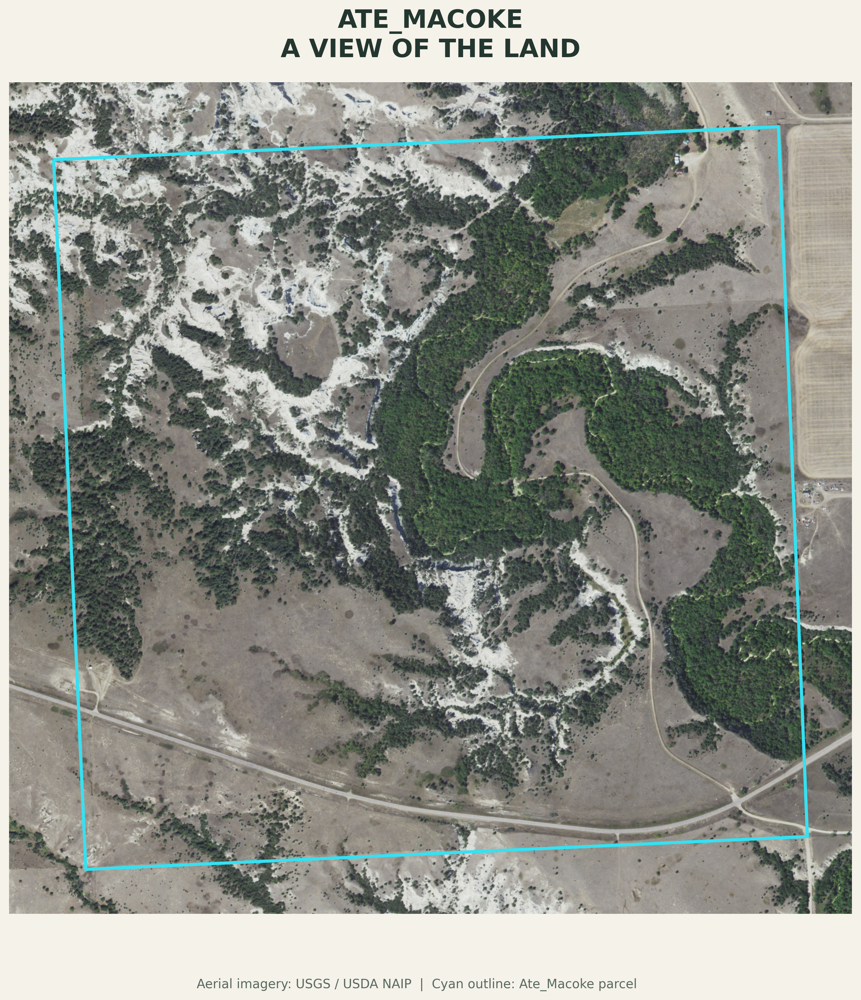

### Ate Macoke Community Map 20261016 205527 337603

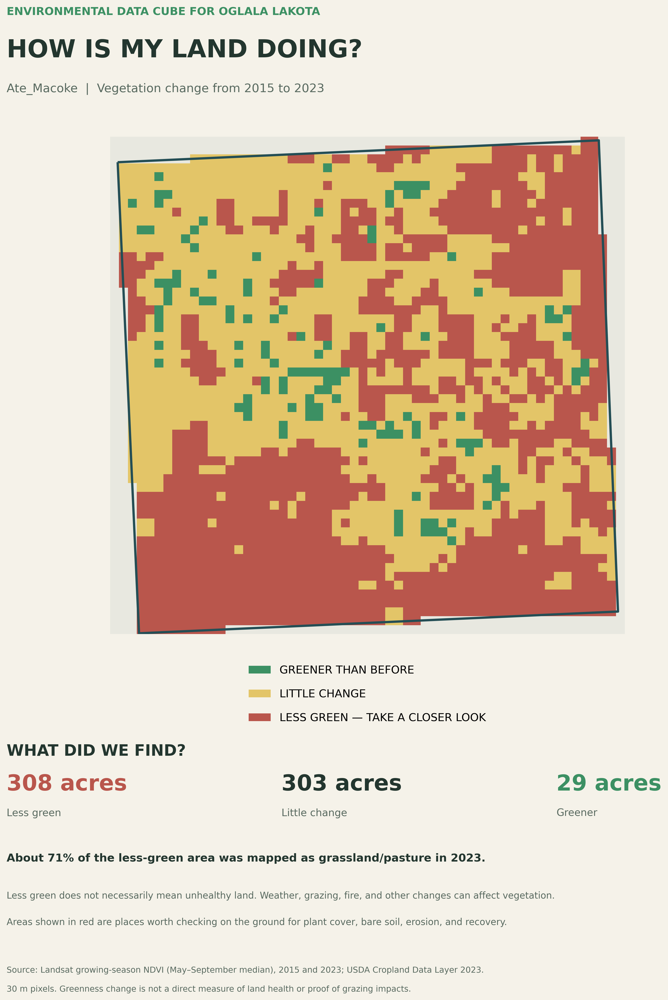

### Ate Macoke Four Panel 20261016 210103 365962

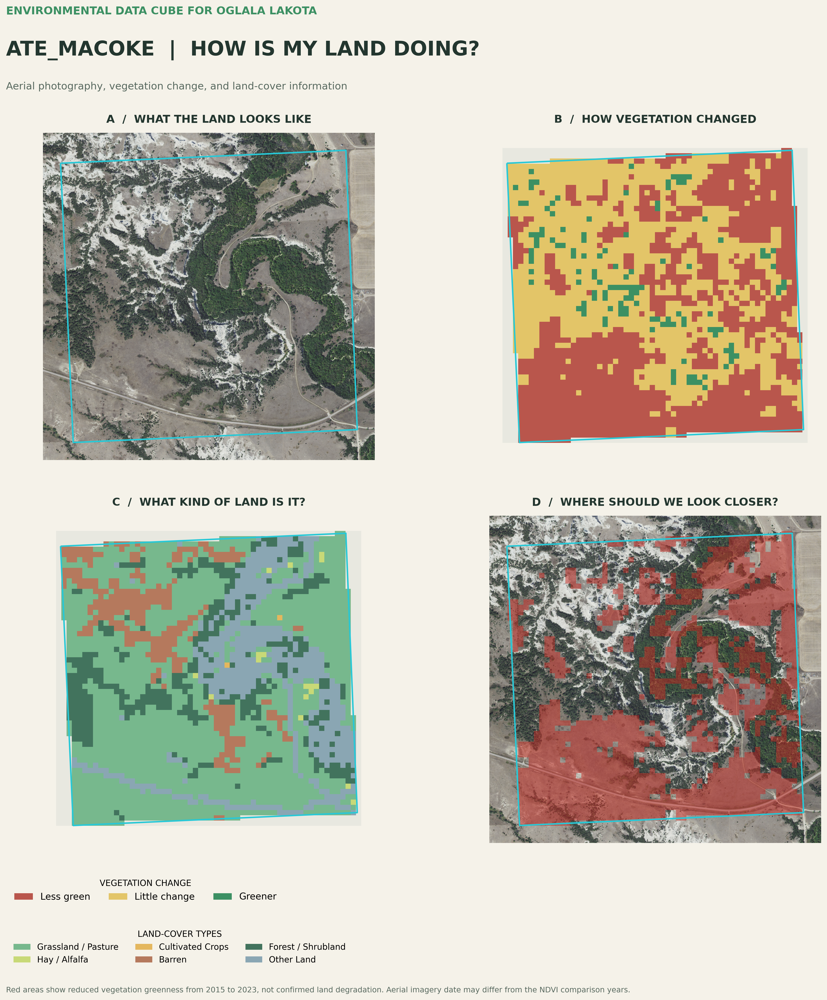

### Ate Macoke NDVI Trend 20261016 210357 745832

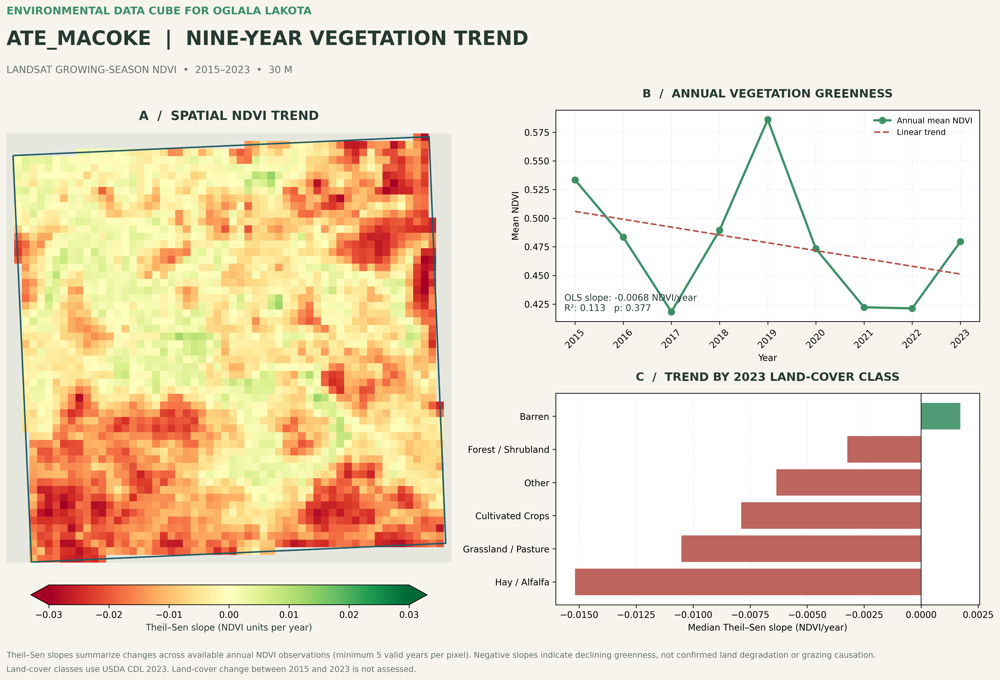

### Ate Macoke Accurate Satellite Map

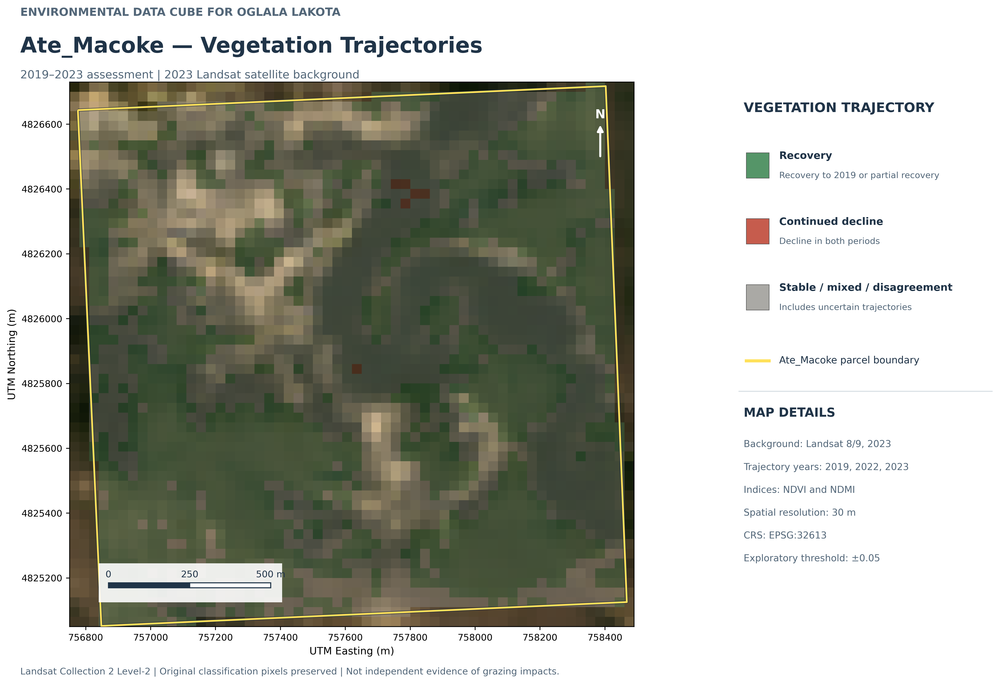

### Ate Macoke Accurate Satellite Map v2

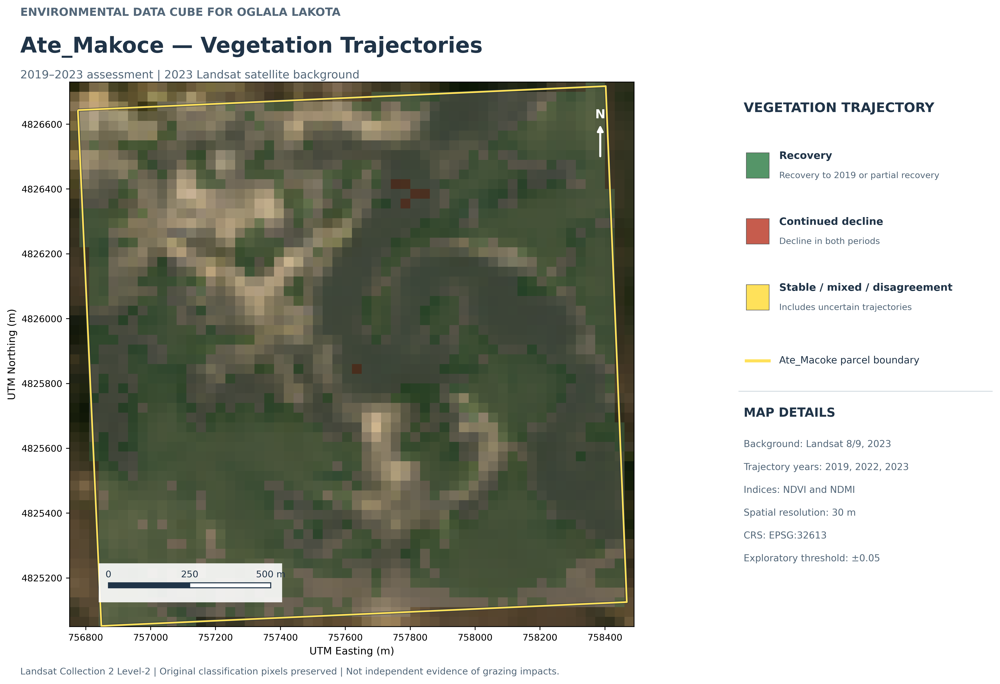

### Ate Macoke Accurate Satellite Map v3

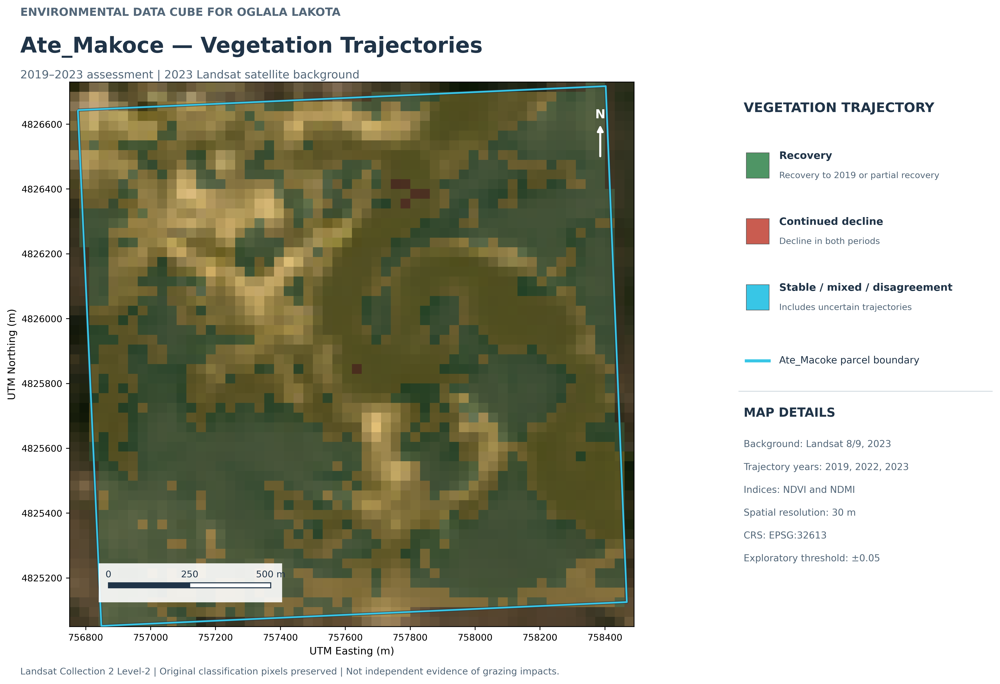

### Ate Macoke High Visibility Vegetation Map

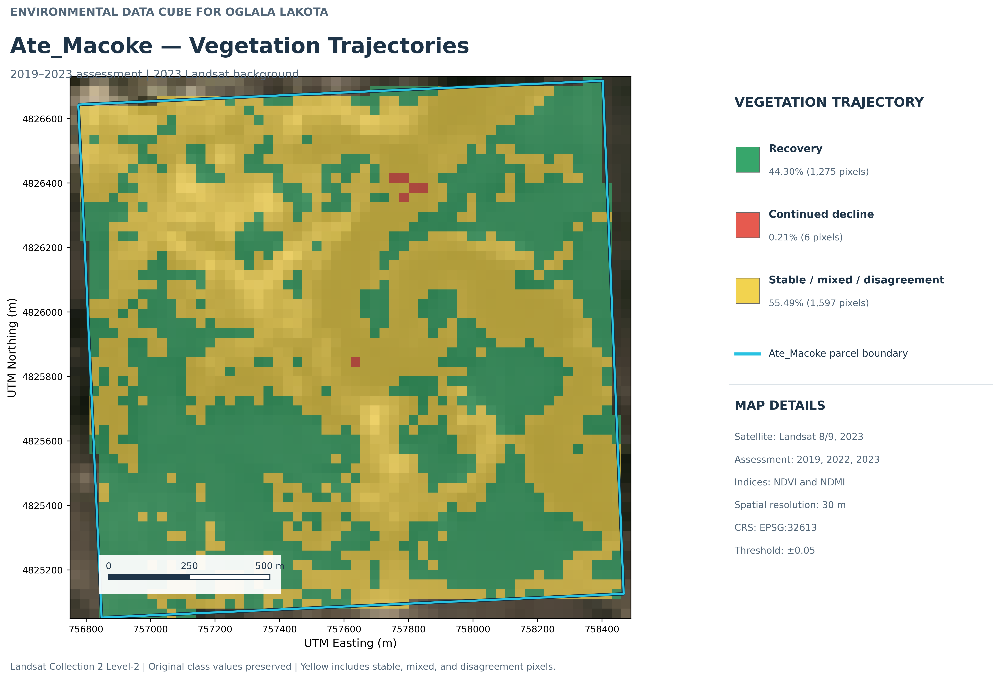

### Ate Macoke Landsat NDVI 2015 2023 Atlas

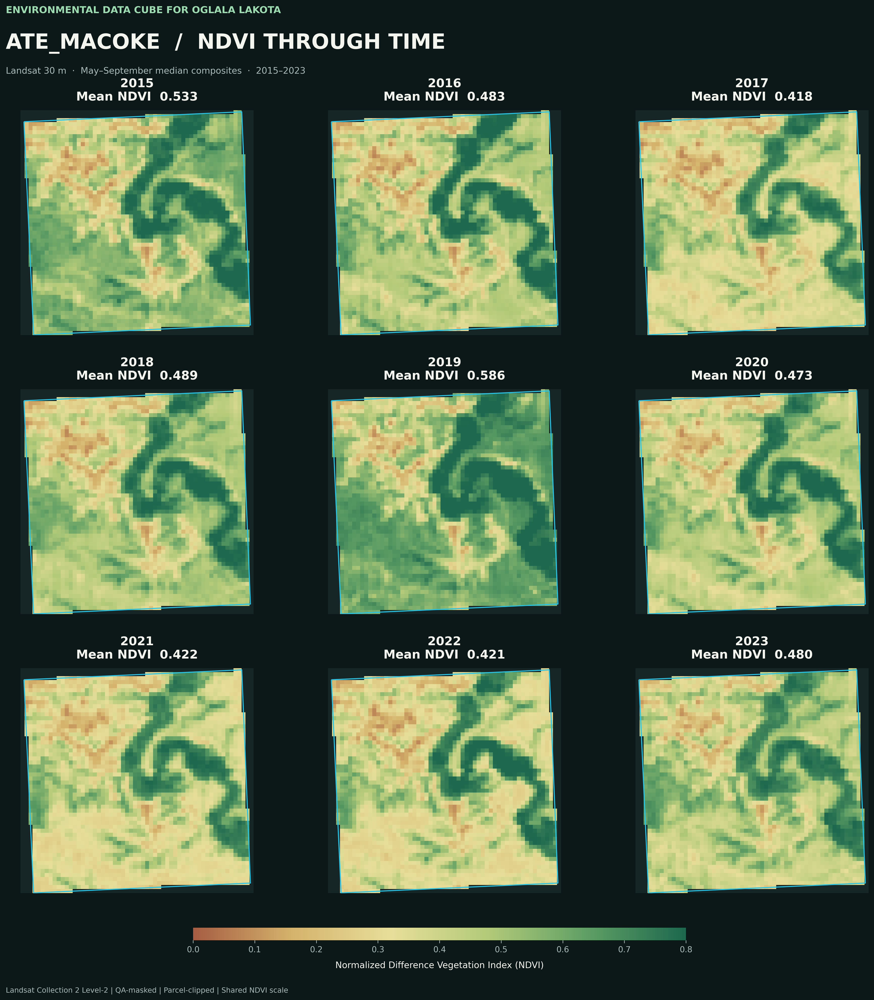

### Ate Macoke NDVI Spatial 2019 2022 2023

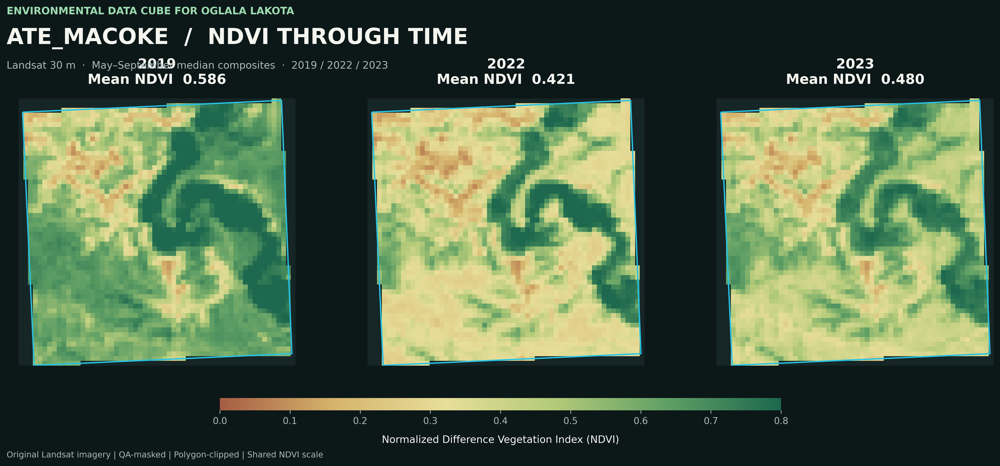

### Ate Macoke NDVI Through Time 2019 2023

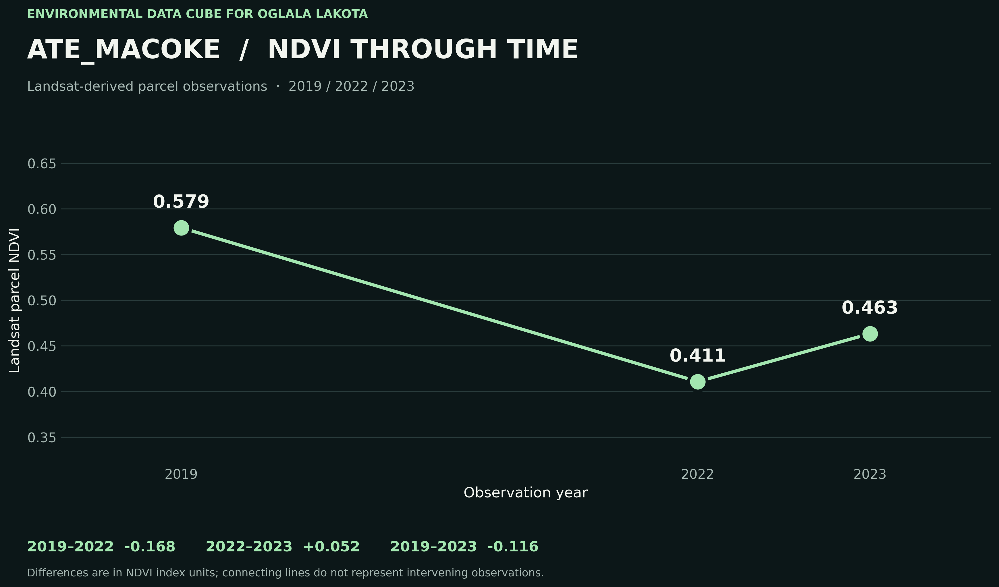

### Ate Macoke NDVI Through Time Atlas

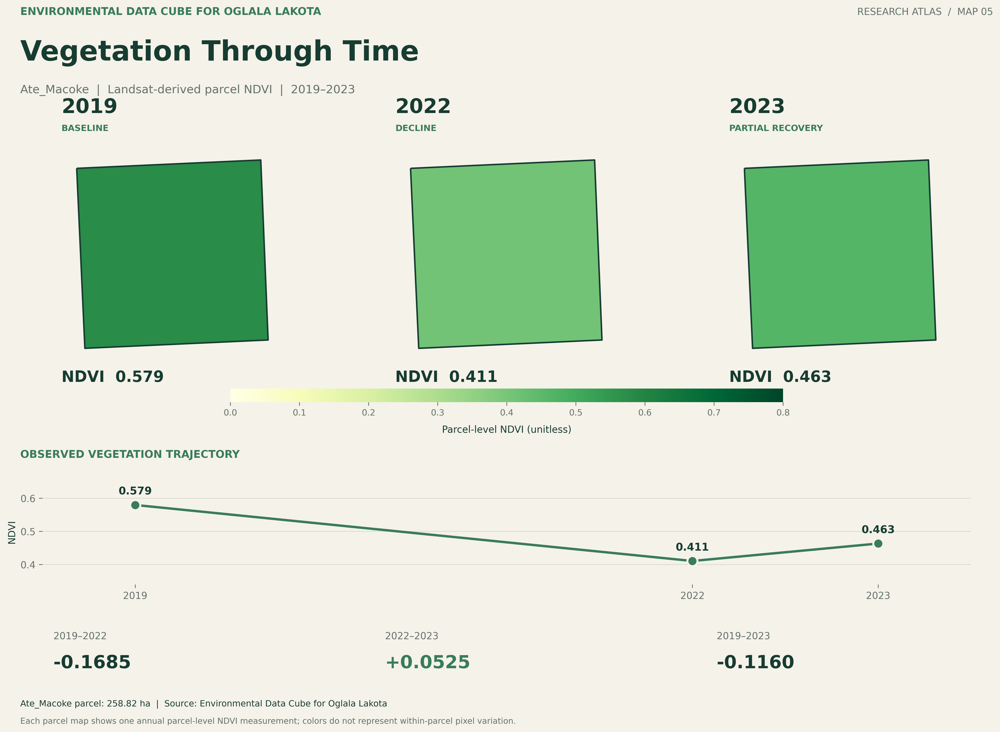

### Ate Macoke Nine Year NDVI Atlas

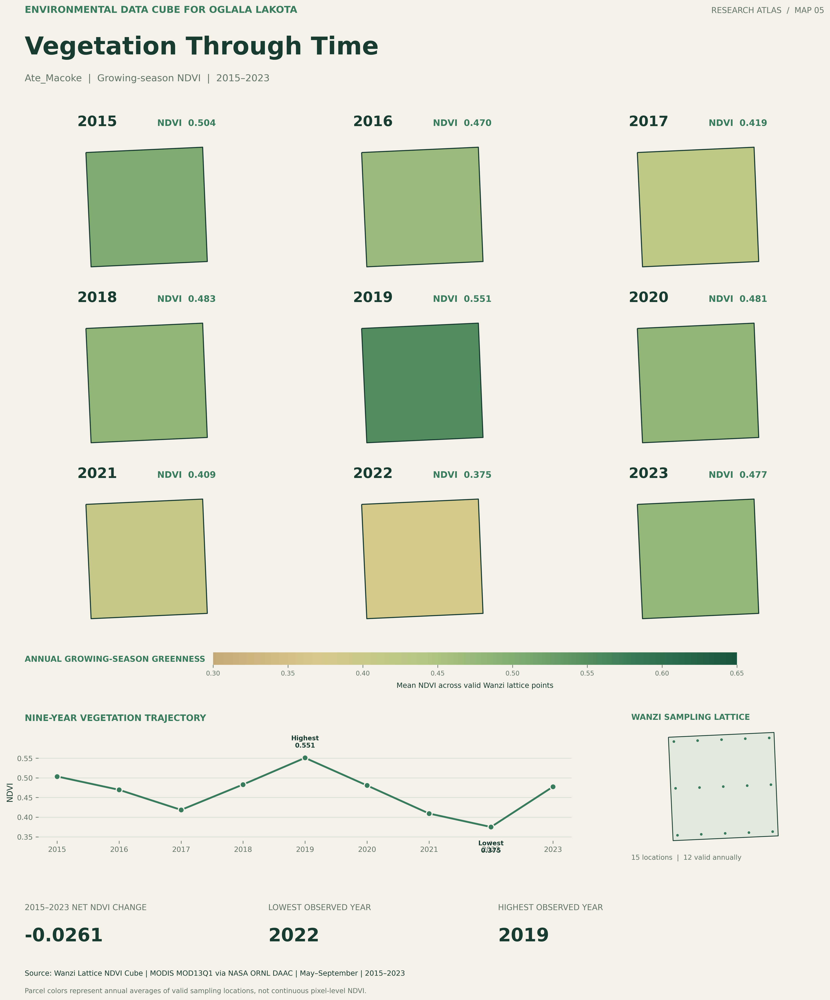

### Ate Macoke Original 15 Point Sampling Lattice

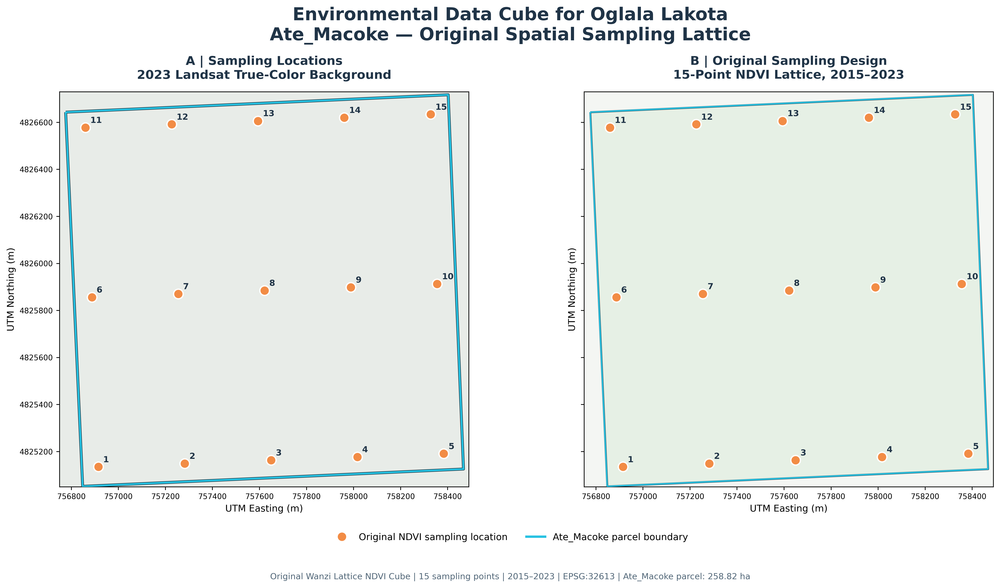

### Ate Macoke Original 15 Point Sampling Lattice RGB

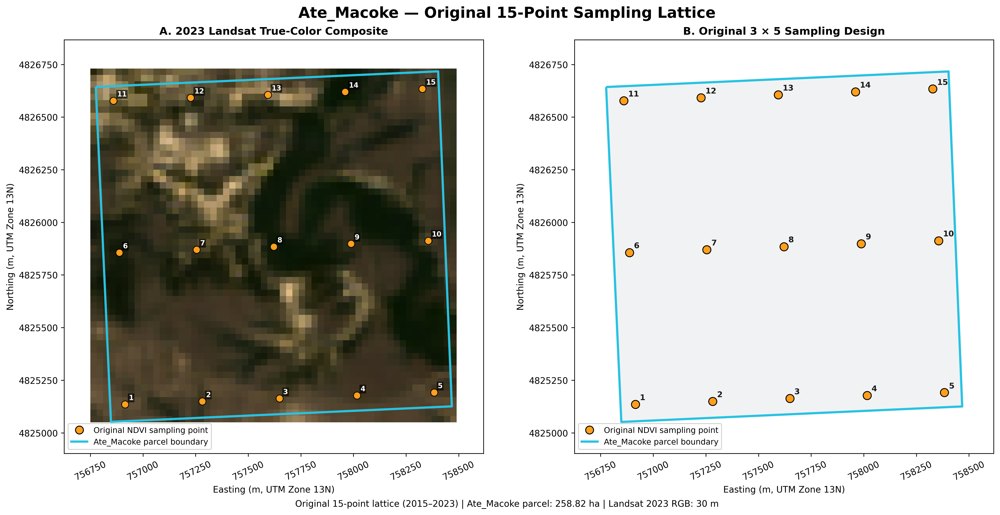

### Ate Macoke Professional Satellite Vegetation Map

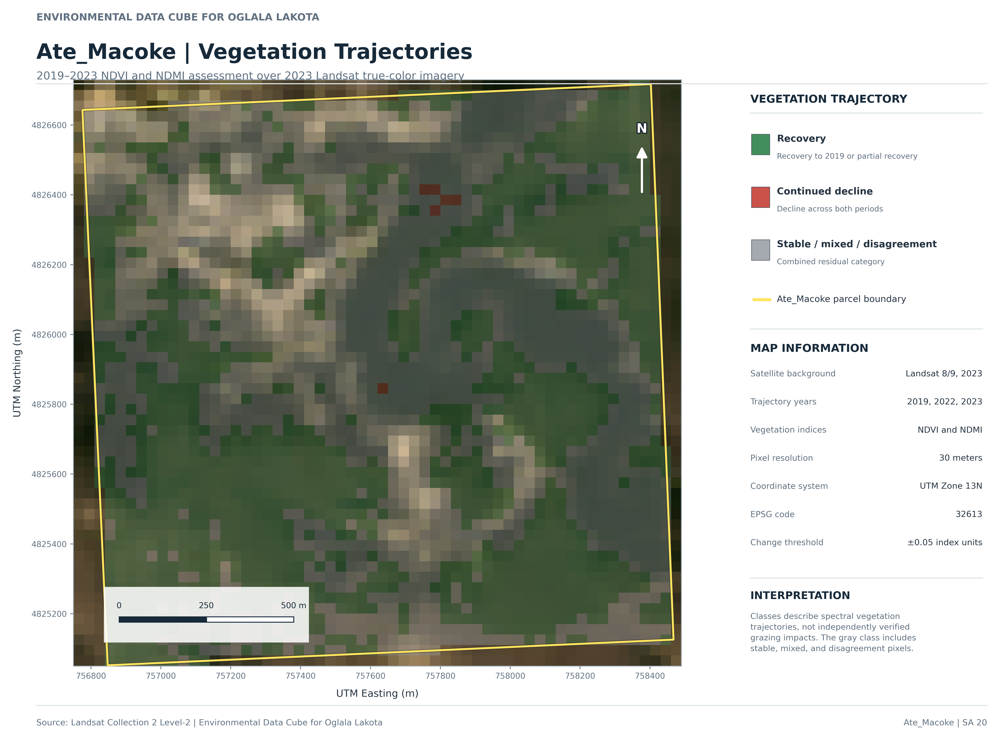

### Ate Macoke Refined Satellite Map

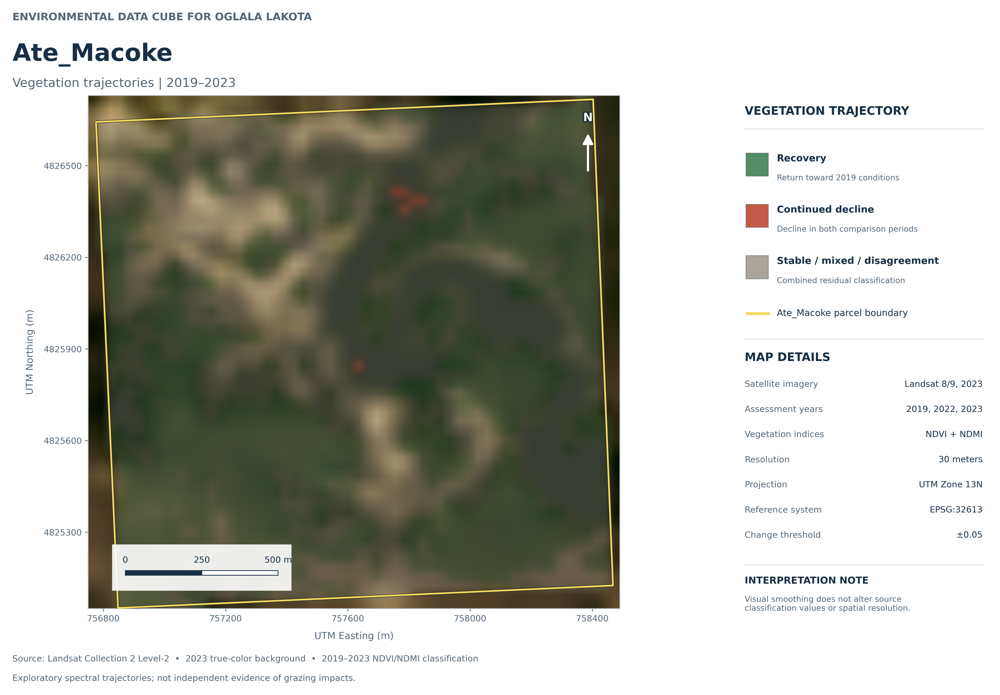

### Ate Macoke Satellite Three Class Map

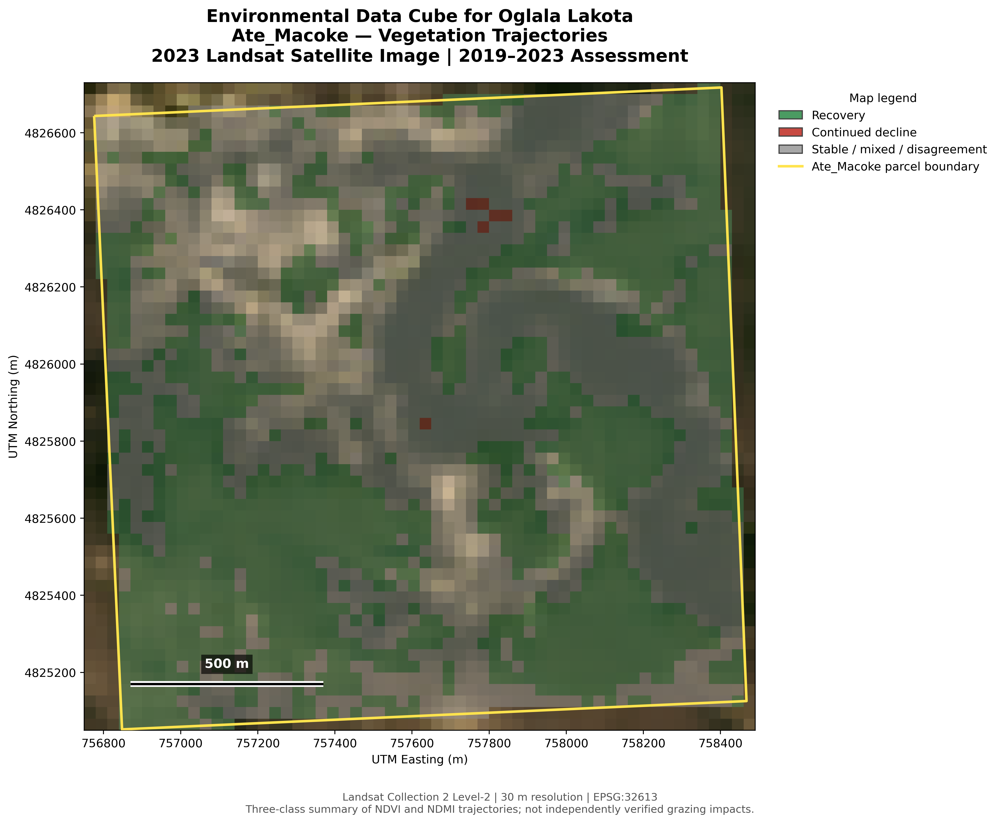

### Ate Macoke Satellite Vegetation Map 58pct Opacity

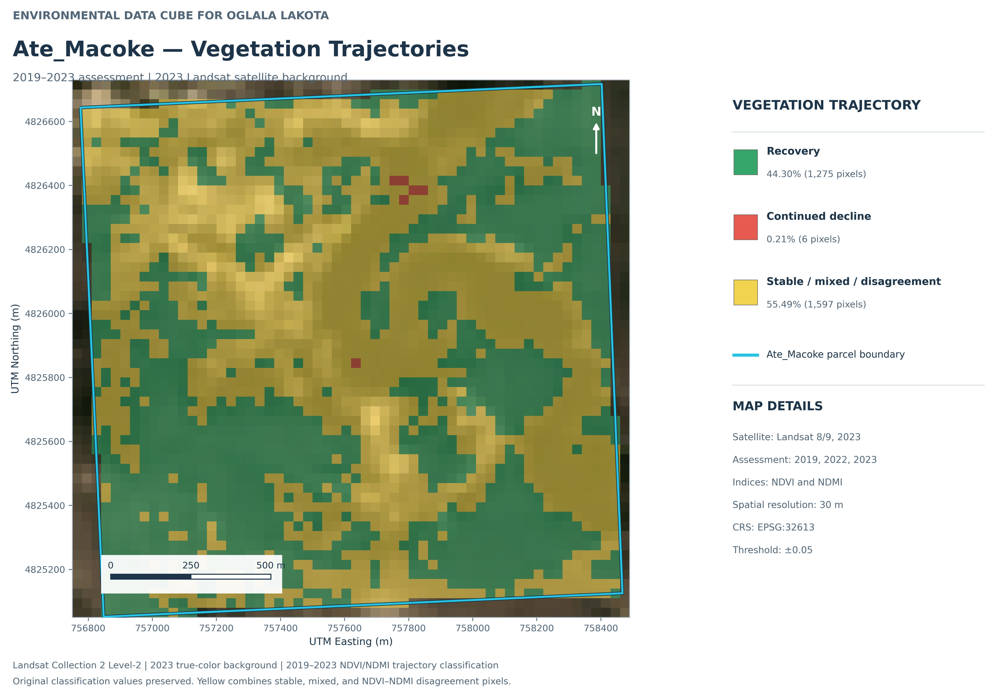

### Ate Macoke Three Class Vegetation Map

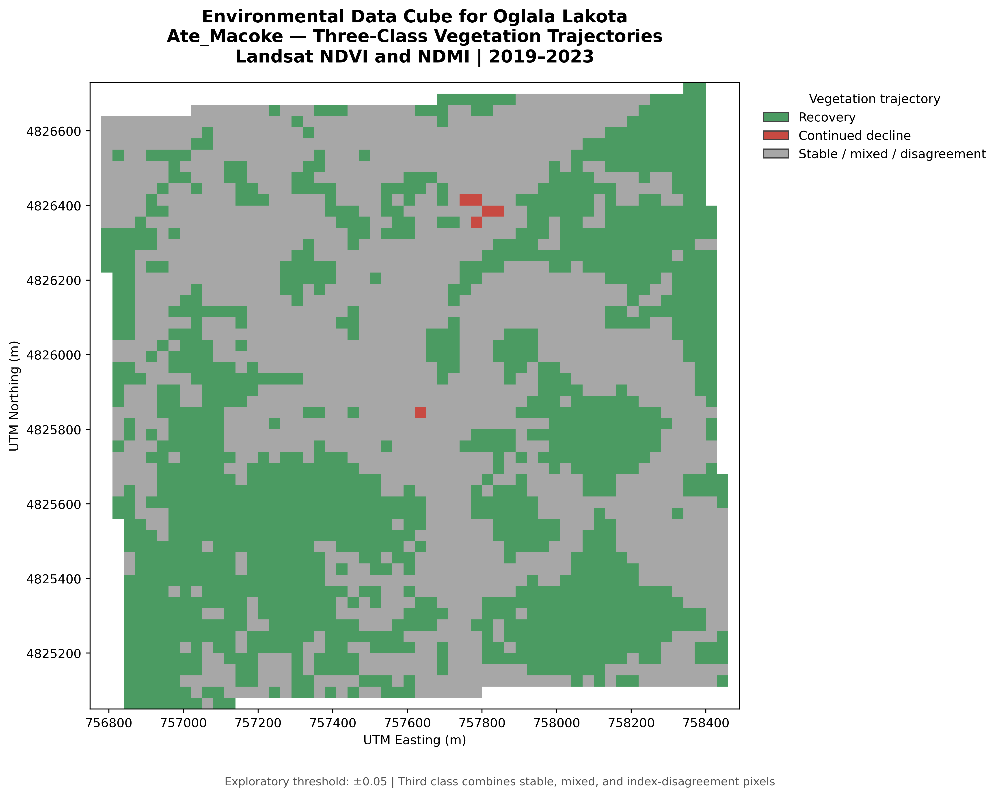

### Ate Macoke True Color Composite Comparison

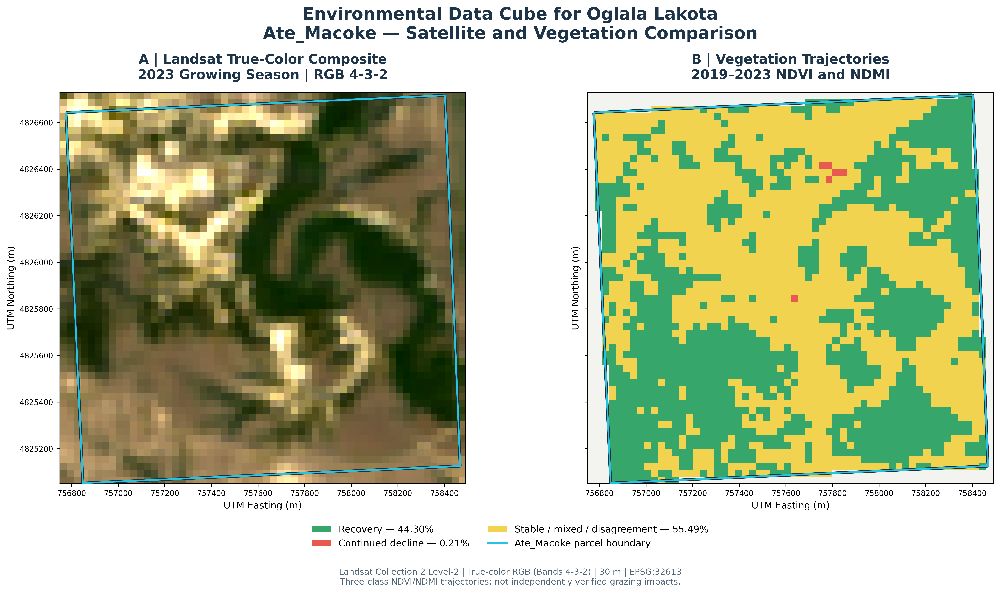

### Ate Macoke Verified Vegetation Trajectories

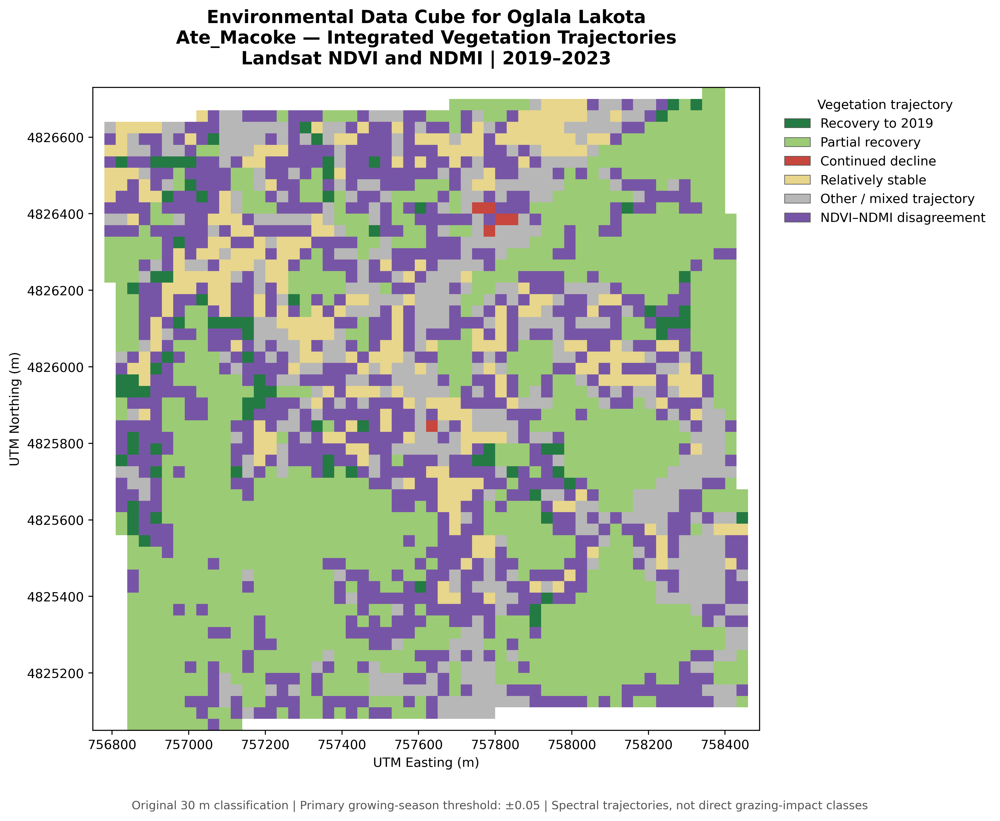

---
## Gallery Statistical Tables

---
## Linked Spatial Datasets

---
## Saved Notebook Outputs

Cell 3: 1 saved output(s)
Cell 4: 2 saved output(s)
Cell 5: 2 saved output(s)
Cell 6: 1 saved output(s)
Cell 7: 2 saved output(s)
Cell 8: 2 saved output(s)
Cell 9: 11 saved output(s)
Cell 10: 1 saved output(s)


---
## Gallery Summary

,Gallery Content,Count
0,Notebook cells,47
1,Local figures displayed,22
2,CSV tables displayed,0
3,Spatial datasets linked,0
4,Cells with saved outputs,8
5,Missing image files,0



Gallery inspection complete.
Notebook 11 and all research files remain unchanged.


In [17]:
# ======================================================================
# ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA
# VIEW CONTENTS OF NOTEBOOK 11 — DISSERTATION FIGURES GALLERY
#
# READ-ONLY: Does not change Notebook 11 or any source files.
# ======================================================================

from pathlib import Path
import re
import shlex
import nbformat
import pandas as pd
from IPython.display import display, Markdown, Image

# ----------------------------------------------------------------------
# 1. LOCATE EXISTING GALLERY NOTEBOOK
# ----------------------------------------------------------------------

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

gallery_path = (
    project
    / "Notebooks"
    / "11_dissertation_figures_stats_results_gallery.ipynb"
)

if not gallery_path.exists():
    raise FileNotFoundError(
        f"Gallery notebook not found:\n{gallery_path}"
    )

gallery = nbformat.read(gallery_path, as_version=4)

display(Markdown(
    "# Environmental Data Cube for Oglala Lakota\n"
    "## Dissertation Figures, Statistics & Results Gallery\n"
    f"**Notebook:** `{gallery_path.name}`\n\n"
    f"**Total cells:** {len(gallery.cells)}"
))

# ----------------------------------------------------------------------
# 2. INVENTORY ALL NOTEBOOK CELLS
# ----------------------------------------------------------------------

inventory = []

for i, cell in enumerate(gallery.cells, start=1):

    source = cell.get("source", "")

    headings = re.findall(
        r"(?m)^#{1,6}\s+(.+)$",
        source
    )

    title = (
        headings[0]
        if headings
        else source.strip().splitlines()[0][:100]
        if source.strip()
        else "(empty)"
    )

    inventory.append({
        "Cell": i,
        "Type": cell.cell_type,
        "Title / Preview": title,
        "Saved Outputs": len(cell.get("outputs", []))
            if cell.cell_type == "code" else 0
    })

display(Markdown("### Notebook cell inventory"))
display(pd.DataFrame(inventory))

# ----------------------------------------------------------------------
# 3. DISPLAY FIGURES REFERENCED IN MARKDOWN
# ----------------------------------------------------------------------

display(Markdown("---\n## Gallery Figures"))

image_pattern = re.compile(
    r"!\[([^\]]*)\]\(([^)]+)\)"
)

shown_images = set()
image_count = 0
missing_images = []

for cell in gallery.cells:

    if cell.cell_type != "markdown":
        continue

    for alt, link in image_pattern.findall(cell.source):

        # Remove optional Markdown title.
        raw_link = link.strip()

        if raw_link.startswith("<") and ">" in raw_link:
            raw_link = raw_link[1:raw_link.index(">")]
        else:
            try:
                raw_link = shlex.split(raw_link)[0]
            except (ValueError, IndexError):
                raw_link = raw_link.split(" ")[0]

        # Skip remote images; this viewer uses local files.
        if raw_link.startswith(("http://", "https://", "data:")):
            print(f"External image link: {raw_link}")
            continue

        image_path = (
            gallery_path.parent / raw_link
        ).resolve()

        if image_path in shown_images:
            continue

        shown_images.add(image_path)

        if not image_path.exists():
            missing_images.append(str(image_path))
            continue

        if image_path.suffix.lower() in {
            ".png", ".jpg", ".jpeg", ".gif"
        }:
            display(Markdown(f"### {alt or image_path.stem}"))
            display(Image(filename=str(image_path), width=950))
            image_count += 1
        else:
            print(f"Linked image asset: {image_path.name}")

# ----------------------------------------------------------------------
# 4. DISPLAY STATISTICAL TABLES FROM LINKED CSV FILES
# ----------------------------------------------------------------------

display(Markdown("---\n## Gallery Statistical Tables"))

link_pattern = re.compile(
    r"(?<!!)\[([^\]]+)\]\(([^)]+\.csv)\)"
)

shown_csvs = set()
table_count = 0

for cell in gallery.cells:

    if cell.cell_type != "markdown":
        continue

    for label, link in link_pattern.findall(cell.source):

        csv_path = (
            gallery_path.parent / link
        ).resolve()

        if csv_path in shown_csvs or not csv_path.exists():
            continue

        shown_csvs.add(csv_path)

        display(Markdown(f"### {label}"))

        try:
            df = pd.read_csv(csv_path)

            print(
                f"{csv_path.name} | "
                f"{len(df):,} rows × {len(df.columns)} columns"
            )

            display(df.head(20))
            table_count += 1

        except Exception as exc:
            print(f"Could not read {csv_path.name}: {exc}")

# ----------------------------------------------------------------------
# 5. DISPLAY ADDITIONAL DATASET LINKS
# ----------------------------------------------------------------------

display(Markdown("---\n## Linked Spatial Datasets"))

spatial_pattern = re.compile(
    r"\[([^\]]+)\]\(([^)]+\.(?:tif|tiff|nc|gpkg|shp))\)",
    flags=re.IGNORECASE
)

spatial_count = 0
shown_spatial = set()

for cell in gallery.cells:

    if cell.cell_type != "markdown":
        continue

    for label, link in spatial_pattern.findall(cell.source):

        data_path = (
            gallery_path.parent / link
        ).resolve()

        if data_path in shown_spatial:
            continue

        shown_spatial.add(data_path)

        status = "AVAILABLE" if data_path.exists() else "MISSING"

        print(f"{status} | {label}")
        print(f"  {data_path}")

        spatial_count += 1

# ----------------------------------------------------------------------
# 6. DISPLAY SAVED OUTPUTS ALREADY EMBEDDED IN NOTEBOOK
# ----------------------------------------------------------------------

display(Markdown("---\n## Saved Notebook Outputs"))

saved_output_cells = [
    (i, cell)
    for i, cell in enumerate(gallery.cells, start=1)
    if cell.cell_type == "code" and cell.get("outputs")
]

if saved_output_cells:
    for cell_number, cell in saved_output_cells:
        print(
            f"Cell {cell_number}: "
            f"{len(cell.outputs)} saved output(s)"
        )
else:
    print("No saved code-cell outputs found.")

# ----------------------------------------------------------------------
# 7. SUMMARY
# ----------------------------------------------------------------------

display(Markdown("---\n## Gallery Summary"))

summary = pd.DataFrame([
    ["Notebook cells", len(gallery.cells)],
    ["Local figures displayed", image_count],
    ["CSV tables displayed", table_count],
    ["Spatial datasets linked", spatial_count],
    ["Cells with saved outputs", len(saved_output_cells)],
    ["Missing image files", len(missing_images)]
], columns=["Gallery Content", "Count"])

display(summary)

if missing_images:
    display(Markdown("### Missing image references"))
    for path in missing_images:
        print(path)

print("\nGallery inspection complete.")
print("Notebook 11 and all research files remain unchanged.")

In [18]:
from pathlib import Path
from datetime import datetime
import nbformat

project = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

notebooks = project / "Notebooks"

target = (
    notebooks
    / "11_dissertation_figures_stats_results_gallery.ipynb"
)

candidates = [target] + sorted(
    notebooks.glob(
        "11_dissertation_figures_stats_results_gallery_backup*.ipynb"
    )
)

print("=" * 75)
print("NOTEBOOK 11 — GALLERY RECOVERY DIAGNOSTIC")
print("=" * 75)

for path in candidates:

    if not path.exists():
        continue

    try:
        nb = nbformat.read(path, as_version=4)

        sources = "\n".join(
            cell.source for cell in nb.cells
        )

        has_gallery = (
            "BEGIN ATE_MACOKE_MANAGED_GALLERY" in sources
        )

        modified = datetime.fromtimestamp(
            path.stat().st_mtime
        )

        print(f"\nFILE: {path.name}")
        print(f"Modified: {modified}")
        print(f"Cells: {len(nb.cells)}")
        print(f"Ate_Macoke gallery: {'YES' if has_gallery else 'NO'}")
        print(f"Size: {path.stat().st_size:,} bytes")

    except Exception as exc:
        print(f"\nCould not read {path.name}: {exc}")

print("\nSOURCE FIGURES")

source = project / "results" / "SA20_satellite_maps"

for folder_name in [
    "Ate_Macoke_Aerial_Imagery",
    "Ate_Macoke_Community_Land_Maps",
    "Ate_Macoke_NDVI_Trend_Analysis",
]:

    folder = source / folder_name

    png_count = (
        len(list(folder.rglob("*.png")))
        if folder.exists()
        else 0
    )

    print(f"{folder_name}: {png_count} PNG files")

print("\nNo files were changed.")


NOTEBOOK 11 — GALLERY RECOVERY DIAGNOSTIC

FILE: 11_dissertation_figures_stats_results_gallery.ipynb
Modified: 2026-10-16 21:25:15.972481
Cells: 47
Ate_Macoke gallery: YES
Size: 142,129 bytes

FILE: 11_dissertation_figures_stats_results_gallery_backup_before_Ate_Macoke_20261016_210918_743149.ipynb
Modified: 2026-10-16 19:27:28.275961
Cells: 6
Ate_Macoke gallery: NO
Size: 91,487 bytes

FILE: 11_dissertation_figures_stats_results_gallery_backup_restore_20261016_211729_469914.ipynb
Modified: 2026-10-16 21:17:18.627405
Cells: 8
Ate_Macoke gallery: YES
Size: 112,845 bytes

SOURCE FIGURES
Ate_Macoke_Aerial_Imagery: 1 PNG files
Ate_Macoke_Community_Land_Maps: 2 PNG files
Ate_Macoke_NDVI_Trend_Analysis: 1 PNG files

No files were changed.


<!-- BEGIN ATE_MACOKE_MANAGED_GALLERY -->

# Ate_Macoke — Dissertation Figures and Statistical Results

**Environmental Data Cube for Oglala Lakota**

**Study period:** 2015–2023  
**Imagery:** Landsat growing-season NDVI, USDA/USGS aerial imagery  
**Study area:** Ate_Macoke, Pine Ridge Indian Reservation

This gallery presents vegetation-change figures, aerial imagery,
spatial trend analysis, and supporting statistical results.

---


## Aerial Imagery

### Ate Macoke Aerial Map 20261016 205950 341947

![Ate Macoke Aerial Map 20261016 205950 341947](<../results/SA20_satellite_maps/Ate_Macoke_Aerial_Imagery/Ate_Macoke_Aerial_Map_20261016_205950_341947.png>)

**Original figure:** [Ate_Macoke_Aerial_Map_20261016_205950_341947.png](<../results/SA20_satellite_maps/Ate_Macoke_Aerial_Imagery/Ate_Macoke_Aerial_Map_20261016_205950_341947.png>)

## Community Maps

### Ate Macoke Community Map 20261016 205527 337603

![Ate Macoke Community Map 20261016 205527 337603](<../results/SA20_satellite_maps/Ate_Macoke_Community_Land_Maps/Ate_Macoke_Community_Map_20261016_205527_337603.png>)

**Original figure:** [Ate_Macoke_Community_Map_20261016_205527_337603.png](<../results/SA20_satellite_maps/Ate_Macoke_Community_Land_Maps/Ate_Macoke_Community_Map_20261016_205527_337603.png>)

### Ate Macoke Four Panel 20261016 210103 365962

![Ate Macoke Four Panel 20261016 210103 365962](<../results/SA20_satellite_maps/Ate_Macoke_Community_Land_Maps/Ate_Macoke_Four_Panel_20261016_210103_365962.png>)

**Original figure:** [Ate_Macoke_Four_Panel_20261016_210103_365962.png](<../results/SA20_satellite_maps/Ate_Macoke_Community_Land_Maps/Ate_Macoke_Four_Panel_20261016_210103_365962.png>)

## NDVI Trend Analysis

### Ate Macoke NDVI Trend 20261016 210357 745832

![Ate Macoke NDVI Trend 20261016 210357 745832](<../results/SA20_satellite_maps/Ate_Macoke_NDVI_Trend_Analysis/Ate_Macoke_NDVI_Trend_20261016_210357_745832.png>)

**Original figure:** [Ate_Macoke_NDVI_Trend_20261016_210357_745832.png](<../results/SA20_satellite_maps/Ate_Macoke_NDVI_Trend_Analysis/Ate_Macoke_NDVI_Trend_20261016_210357_745832.png>)

## Additional Satellite Maps

### Ate Macoke Accurate Satellite Map

![Ate Macoke Accurate Satellite Map](<../results/SA20_satellite_maps/Ate_Macoke_Accurate_Satellite_Map.png>)

### Ate Macoke Accurate Satellite Map v2

![Ate Macoke Accurate Satellite Map v2](<../results/SA20_satellite_maps/Ate_Macoke_Accurate_Satellite_Map_v2.png>)

### Ate Macoke Accurate Satellite Map v3

![Ate Macoke Accurate Satellite Map v3](<../results/SA20_satellite_maps/Ate_Macoke_Accurate_Satellite_Map_v3.png>)

### Ate Macoke High Visibility Vegetation Map

![Ate Macoke High Visibility Vegetation Map](<../results/SA20_satellite_maps/Ate_Macoke_High_Visibility_Vegetation_Map.png>)

### Ate Macoke Landsat NDVI 2015 2023 Atlas

![Ate Macoke Landsat NDVI 2015 2023 Atlas](<../results/SA20_satellite_maps/Ate_Macoke_Landsat_NDVI_2015_2023_Atlas.png>)

### Ate Macoke NDVI Spatial 2019 2022 2023

![Ate Macoke NDVI Spatial 2019 2022 2023](<../results/SA20_satellite_maps/Ate_Macoke_NDVI_Spatial_2019_2022_2023.png>)

### Ate Macoke NDVI Through Time 2019 2023

![Ate Macoke NDVI Through Time 2019 2023](<../results/SA20_satellite_maps/Ate_Macoke_NDVI_Through_Time_2019_2023.png>)

### Ate Macoke NDVI Through Time Atlas

![Ate Macoke NDVI Through Time Atlas](<../results/SA20_satellite_maps/Ate_Macoke_NDVI_Through_Time_Atlas.png>)

### Ate Macoke Nine Year NDVI Atlas

![Ate Macoke Nine Year NDVI Atlas](<../results/SA20_satellite_maps/Ate_Macoke_Nine_Year_NDVI_Atlas.png>)

### Ate Macoke Original 15 Point Sampling Lattice

![Ate Macoke Original 15 Point Sampling Lattice](<../results/SA20_satellite_maps/Ate_Macoke_Original_15_Point_Sampling_Lattice.png>)

### Ate Macoke Original 15 Point Sampling Lattice RGB

![Ate Macoke Original 15 Point Sampling Lattice RGB](<../results/SA20_satellite_maps/Ate_Macoke_Original_15_Point_Sampling_Lattice_RGB.png>)

### Ate Macoke Professional Satellite Vegetation Map

![Ate Macoke Professional Satellite Vegetation Map](<../results/SA20_satellite_maps/Ate_Macoke_Professional_Satellite_Vegetation_Map.png>)

### Ate Macoke Refined Satellite Map

![Ate Macoke Refined Satellite Map](<../results/SA20_satellite_maps/Ate_Macoke_Refined_Satellite_Map.png>)

### Ate Macoke Satellite Three Class Map

![Ate Macoke Satellite Three Class Map](<../results/SA20_satellite_maps/Ate_Macoke_Satellite_Three_Class_Map.png>)

### Ate Macoke Satellite Vegetation Map 58pct Opacity

![Ate Macoke Satellite Vegetation Map 58pct Opacity](<../results/SA20_satellite_maps/Ate_Macoke_Satellite_Vegetation_Map_58pct_Opacity.png>)

### Ate Macoke Three Class Vegetation Map

![Ate Macoke Three Class Vegetation Map](<../results/SA20_satellite_maps/Ate_Macoke_Three_Class_Vegetation_Map.png>)

### Ate Macoke True Color Composite Comparison

![Ate Macoke True Color Composite Comparison](<../results/SA20_satellite_maps/Ate_Macoke_True_Color_Composite_Comparison.png>)

### Ate Macoke Verified Vegetation Trajectories

![Ate Macoke Verified Vegetation Trajectories](<../results/SA20_satellite_maps/Ate_Macoke_Verified_Vegetation_Trajectories.png>)


## Nine-Year NDVI Trend — 2015–2023

### Parcel-level trend

| Statistic | Result |
|---|---:|
| OLS slope | −0.00684 NDVI/year |
| OLS R² | 0.1130 |
| OLS p-value | 0.3765 |
| Theil–Sen slope | −0.00739 NDVI/year |
| Theil–Sen 95% CI | [−0.02603, +0.01021] |

### Spatial trends

| Category | Area (ha) | Percent |
|---|---:|---:|
| Declining | 143.73 | 55.5% |
| Relatively stable | 107.37 | 41.5% |
| Increasing | 7.92 | 3.1% |
| **Total analyzed** | **259.02** | **100%** |

The parcel-wide trend is not statistically significant
(p = 0.3765). Spatial classes use descriptive Theil–Sen
slope thresholds of ±0.005 NDVI/year, not statistical
significance tests.

Declining NDVI alone does not establish land degradation
or overgrazing.


### Annual NDVI Statistics

**Data:** [Ate_Macoke_Annual_NDVI_20261016_210357_745832.csv](<../results/SA20_satellite_maps/Ate_Macoke_NDVI_Trend_Analysis/Ate_Macoke_Annual_NDVI_20261016_210357_745832.csv>)

In [19]:
from pathlib import Path
import pandas as pd
from IPython.display import display

csv_path = Path('/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_NDVI_Trend_Analysis/Ate_Macoke_Annual_NDVI_20261016_210357_745832.csv')
df = pd.read_csv(csv_path)
print(f'{len(df):,} rows × {len(df.columns)} columns')
display(df.head(20))

9 rows × 6 columns


,year,mean_ndvi,median_ndvi,std_ndvi,valid_pixels,valid_area_ha
0,2015,0.533415,0.548243,0.160831,2878,259.02
1,2016,0.483417,0.465007,0.166730,2878,259.02
2,2017,0.418252,0.379081,0.156592,2878,259.02
3,2018,0.489388,0.480907,0.156157,2878,259.02
4,2019,0.586066,0.615108,0.160797,2878,259.02
5,2020,0.473286,0.450915,0.157373,2878,259.02
6,2021,0.422211,0.373481,0.159487,2878,259.02
7,2022,0.421217,0.365970,0.171082,2878,259.02
8,2023,0.479537,0.452705,0.147372,2878,259.02


### Land-Cover Trend Statistics

**Data:** [Ate_Macoke_LandCover_Trend_20261016_210357_745832.csv](<../results/SA20_satellite_maps/Ate_Macoke_NDVI_Trend_Analysis/Ate_Macoke_LandCover_Trend_20261016_210357_745832.csv>)

In [20]:
from pathlib import Path
import pandas as pd
from IPython.display import display

csv_path = Path('/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_NDVI_Trend_Analysis/Ate_Macoke_LandCover_Trend_20261016_210357_745832.csv')
df = pd.read_csv(csv_path)
print(f'{len(df):,} rows × {len(df.columns)} columns')
display(df.head(20))

6 rows × 7 columns


,land_cover,valid_pixels,area_ha,median_slope_per_year,mean_slope_per_year,declining_area_ha,increasing_area_ha
0,Grassland / Pasture,1641,147.69,-0.010516,-0.010413,101.88,3.24
1,Hay / Alfalfa,17,1.53,-0.015182,-0.013668,1.26,0.00
2,Cultivated Crops,2,0.18,-0.007890,-0.007890,0.18,0.00
3,Barren,307,27.63,0.001723,0.001698,0.63,2.34
4,Forest / Shrubland,389,35.01,-0.003231,-0.003342,12.15,1.53
5,Other,520,46.80,-0.006347,-0.006970,27.54,0.81


### Pixel-Level Trend Statistics

**Data:** [Ate_Macoke_Pixel_Trend_20261016_210357_745832.csv](<../results/SA20_satellite_maps/Ate_Macoke_NDVI_Trend_Analysis/Ate_Macoke_Pixel_Trend_20261016_210357_745832.csv>)

In [21]:
from pathlib import Path
import pandas as pd
from IPython.display import display

csv_path = Path('/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/SA20_satellite_maps/Ate_Macoke_NDVI_Trend_Analysis/Ate_Macoke_Pixel_Trend_20261016_210357_745832.csv')
df = pd.read_csv(csv_path)
print(f'{len(df):,} rows × {len(df.columns)} columns')
display(df.head(20))

2,878 rows × 10 columns


,row,column,easting,northing,valid_years,theil_sen_slope,ols_slope,ols_r2,ols_pvalue,cdl_2023_code
0,0,53,758355.0,4826715.0,9,-0.018127,-0.016784,0.362174,0.086420,176
1,0,54,758385.0,4826715.0,9,-0.028174,-0.022931,0.338311,0.100406,176
2,1,31,757695.0,4826685.0,9,-0.014171,-0.013208,0.136514,0.327759,176
3,1,32,757725.0,4826685.0,9,-0.012100,-0.015043,0.191656,0.238593,176
4,1,33,757755.0,4826685.0,9,-0.004302,-0.005913,0.050785,0.559898,176
5,1,34,757785.0,4826685.0,9,-0.011158,-0.008788,0.094037,0.422195,176
6,1,35,757815.0,4826685.0,9,-0.011754,-0.007989,0.096161,0.416732,176
7,1,36,757845.0,4826685.0,9,-0.010629,-0.005643,0.048666,0.568417,176
8,1,37,757875.0,4826685.0,9,-0.002262,-0.003035,0.021101,0.709229,176
9,1,38,757905.0,4826685.0,9,-0.000792,-0.001547,0.027171,0.671711,190


## Spatial Trend Raster

**Theil–Sen GeoTIFF:** [Ate_Macoke_TheilSen_Trend_20261016_210357_745832.tif](<../results/SA20_satellite_maps/Ate_Macoke_NDVI_Trend_Analysis/Ate_Macoke_TheilSen_Trend_20261016_210357_745832.tif>)

Pixel-level slopes are expressed in NDVI units per year.


## Dissertation Results Interpretation

Landsat growing-season NDVI analysis from 2015 through 2023
identified spatially heterogeneous vegetation changes across
Ate_Macoke.

The descriptive spatial analysis classified 143.73 hectares
as declining, 107.37 hectares as relatively stable, and
7.92 hectares as increasing.

Parcel-level OLS regression indicated a negative slope
(−0.00684 NDVI/year), but the result was not statistically
significant (p = 0.3765).

These results document vegetation-greenness changes rather
than demonstrating their cause. Additional land-use,
precipitation, grazing-management, and field observations
would be needed to assess causal explanations.

**Data governance:** Oglala Lakota Nation — Tribal Data Sovereignty.


<!-- END ATE_MACOKE_MANAGED_GALLERY -->

In [23]:
# ==============================================================
# FIND ORIGINAL SUSTAINABILITY ASSESSMENT BOX PLOTS
# READ-ONLY SEARCH — DOES NOT MODIFY FILES
# ==============================================================

from pathlib import Path
import nbformat
import re

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

patterns = [
    r"\bboxplot\s*\(",
    r"\bboxplots?\b",
    r"\bbox_plot\b",
    r"\bboxenplot\s*\(",
    r"kind\s*=\s*['\"]box['\"]",
    r"box.and.whisker",
]

matches = []

print("SEARCHING PROJECT NOTEBOOKS FOR BOX PLOTS")
print("=" * 65)

for notebook_path in sorted(PROJECT.rglob("*.ipynb")):

    # Ignore notebook backups and checkpoints.
    if (
        ".ipynb_checkpoints" in notebook_path.parts
        or "backup" in notebook_path.name.lower()
        or "before_explorer" in notebook_path.name.lower()
    ):
        continue

    try:
        nb = nbformat.read(notebook_path, as_version=4)
    except Exception:
        continue

    for i, cell in enumerate(nb.cells):

        source = cell.get("source", "")

        # Skip the Explorer itself.
        if "DISSERTATION_RESULTS_EXPLORER" in source:
            continue

        if not any(
            re.search(pattern, source, flags=re.IGNORECASE)
            for pattern in patterns
        ):
            continue

        outputs = cell.get("outputs", [])

        saved_images = sum(
            1 for output in outputs
            if (
                "image/png" in output.get("data", {})
                or "image/jpeg" in output.get("data", {})
            )
        )

        matches.append((notebook_path, i + 1, saved_images))

        print(f"\nNotebook: {notebook_path.name}")
        print(f"Cell: {i + 1}")
        print(f"Saved images: {saved_images}")
        print("Code preview:")
        print(source[:350])
        print("-" * 65)

print("\n" + "=" * 65)
print(f"TOTAL MATCHING CELLS: {len(matches)}")

if not matches:
    print(
        "No matching notebook cells found. "
        "The box plots may be in an external file "
        "or use a different plotting method."
    )

SEARCHING PROJECT NOTEBOOKS FOR BOX PLOTS

Notebook: 09_dissertation_data_cube_validation.ipynb
Cell: 364
Saved images: 1
Code preview:
# =============================================================================
# SA 16.17.5E — CANDIDATE STABILITY AND THRESHOLD PROXIMITY
# Environmental Data Cube for Oglala Lakota
# Ate Makoce - BIA Parcel
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.py
-----------------------------------------------------------------

Notebook: 09_dissertation_data_cube_validation.ipynb
Cell: 396
Saved images: 1
Code preview:

# =============================================================================
# SA 18.2 — STEP 2
# LANDSAT NDVI / NDMI SPATIAL VARIABILITY ASSESSMENT
#
# Environmental Data Cube for Oglala Lakota
#
# READ-ONLY: No files exported or modified.
# No geographic coordinates displayed.
# ================================================================
--

/opt/anaconda3/lib/python3.12/site-packages/nbformat/validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)



Notebook: 09_dissertation_data_cube_validation_ORIGINAL.ipynb
Cell: 364
Saved images: 1
Code preview:
# =============================================================================
# SA 16.17.5E — CANDIDATE STABILITY AND THRESHOLD PROXIMITY
# Environmental Data Cube for Oglala Lakota
# Ate Makoce - BIA Parcel
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.py
-----------------------------------------------------------------

Notebook: 11_dissertation_figures_stats_results_gallery.ipynb
Cell: 4
Saved images: 0
Code preview:

# ============================================================
# SA 19 — DISSERTATION FIGURES & STATISTICS GALLERY
# Environmental Data Cube for Oglala Lakota
#
# READ-ONLY:
# - Reads saved outputs from Notebook 09
# - Does not rerun satellite analysis
# - Does not change NetCDF or research files
# - Does not require new installations
# ==========
----------------------------

In [24]:
# ======================================================================
# SA 19F — SUSTAINABILITY ASSESSMENT FIGURE COMPARISON
# Environmental Data Cube for Oglala Lakota
#
# Reads saved figures from Notebook 09, cells 364 and 396.
# Creates one landscape page (PNG + PDF).
# Does not modify existing notebooks or assessment data.
# ======================================================================

from pathlib import Path
from datetime import datetime
from io import BytesIO
import base64
import nbformat
import matplotlib.pyplot as plt
from PIL import Image as PILImage

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

SOURCE = (
    PROJECT
    / "Notebooks"
    / "09_dissertation_data_cube_validation.ipynb"
)

OUTPUT = (
    PROJECT
    / "results"
    / "Sustainability_Assessment_Boxplots"
)

OUTPUT.mkdir(parents=True, exist_ok=True)

# These are the 1-based cell numbers from your diagnostic.
TARGETS = [
    (
        364,
        "A",
        "Candidate Stability and Threshold Proximity"
    ),
    (
        396,
        "B",
        "Landsat NDVI / NDMI Spatial Variability"
    )
]

if not SOURCE.exists():
    raise FileNotFoundError(SOURCE)

nb = nbformat.read(SOURCE, as_version=4)

figures = []

for cell_number, panel, title in TARGETS:

    index = cell_number - 1

    if index >= len(nb.cells):
        print(f"Cell {cell_number} not found.")
        continue

    cell = nb.cells[index]

    found = False

    for output in cell.get("outputs", []):

        data = output.get("data", {})

        mime = next(
            (
                m for m in ("image/png", "image/jpeg")
                if m in data
            ),
            None
        )

        if mime is None:
            continue

        encoded = data[mime]

        if isinstance(encoded, list):
            encoded = "".join(encoded)

        raw = base64.b64decode(encoded)

        with PILImage.open(BytesIO(raw)) as im:
            image = im.convert("RGB").copy()

        figures.append((panel, title, image))
        found = True

        print(
            f"Loaded Cell {cell_number}: "
            f"{image.width} × {image.height} pixels"
        )

        break

    if not found:
        print(f"No saved image found in Cell {cell_number}.")

if not figures:
    raise RuntimeError(
        "No figures were loaded. "
        "Check whether Notebook 09 still contains saved outputs."
    )

# ----------------------------------------------------------------------
# CREATE ONE-PAGE LANDSCAPE FIGURE
# ----------------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    len(figures),
    figsize=(16, 9),
    squeeze=False
)

axes = axes.ravel()

for ax, (panel, title, image) in zip(axes, figures):

    ax.imshow(image)
    ax.axis("off")

    ax.set_title(
        f"({panel}) {title}",
        fontsize=11,
        fontweight="bold",
        pad=12
    )

fig.suptitle(
    "Ate Makoce — Sustainability Assessment Figures",
    fontsize=17,
    fontweight="bold",
    y=0.97
)

fig.text(
    0.5,
    0.035,
    "Source: Saved assessment outputs from Notebook 09. "
    "Original analyses and data remain unchanged.",
    ha="center",
    fontsize=9
)

fig.subplots_adjust(
    left=0.025,
    right=0.975,
    bottom=0.085,
    top=0.88,
    wspace=0.06
)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

png_path = OUTPUT / f"Ate_Makoce_Assessment_Comparison_{stamp}.png"
pdf_path = OUTPUT / f"Ate_Makoce_Assessment_Comparison_{stamp}.pdf"

fig.savefig(
    png_path,
    dpi=300,
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    facecolor="white"
)

plt.show()
plt.close(fig)

print("\n" + "=" * 65)
print("SUSTAINABILITY ASSESSMENT FIGURE PAGE CREATED")
print("=" * 65)
print("PNG:", png_path)
print("PDF:", pdf_path)
print("Figures included:", len(figures))
print("Original notebooks: UNCHANGED")
print("=" * 65)

Loaded Cell 364: 1427 × 535 pixels
Loaded Cell 396: 1573 × 613 pixels


<Figure size 1600x900 with 2 Axes>


SUSTAINABILITY ASSESSMENT FIGURE PAGE CREATED
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Sustainability_Assessment_Boxplots/Ate_Makoce_Assessment_Comparison_20261016_213210.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Sustainability_Assessment_Boxplots/Ate_Makoce_Assessment_Comparison_20261016_213210.pdf
Figures included: 2
Original notebooks: UNCHANGED


Original assessment figures loaded successfully.


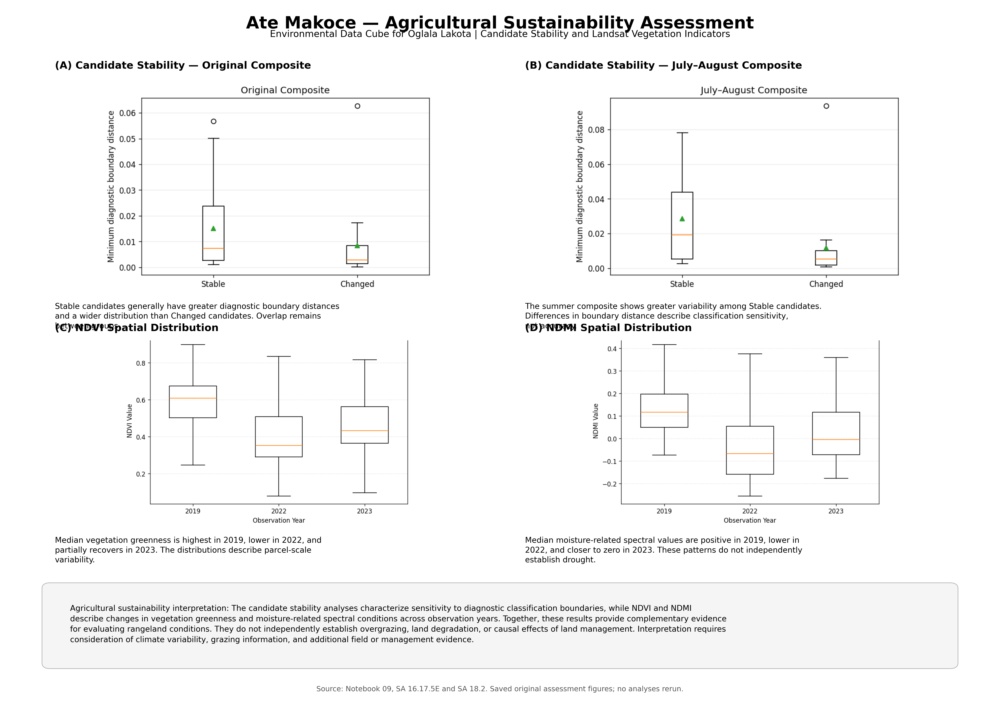


FOUR-PANEL SUSTAINABILITY ASSESSMENT FIGURE CREATED
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Sustainability_Assessment_Boxplots/Ate_Makoce_Four_Panel_Sustainability_Explained_20261016_213803.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Sustainability_Assessment_Boxplots/Ate_Makoce_Four_Panel_Sustainability_Explained_20261016_213803.pdf
Panels: 4
Scientific descriptions: INCLUDED
Agricultural sustainability interpretation: INCLUDED
Original notebooks and analyses: UNCHANGED


In [26]:
# ======================================================================
# SA 19H — FOUR-PANEL SUSTAINABILITY ASSESSMENT FIGURE
# WITH SCIENTIFIC DESCRIPTIONS AND INTERPRETATIONS
#
# Environmental Data Cube for Oglala Lakota
# Ate Makoce — BIA Parcel
#
# READS saved figures from Notebook 09, cells 364 and 396.
# DOES NOT modify Notebook 09, Notebook 11, or existing outputs.
# Creates new timestamped PNG and PDF files.
# ======================================================================

from pathlib import Path
from datetime import datetime
from io import BytesIO
from IPython.display import display, Image as IPyImage
from PIL import Image as PILImage
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import nbformat
import base64
import textwrap
import numpy as np

# ----------------------------------------------------------------------
# 1. PROJECT PATHS
# ----------------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

SOURCE = (
    PROJECT
    / "Notebooks"
    / "09_dissertation_data_cube_validation.ipynb"
)

OUTPUT = (
    PROJECT
    / "results"
    / "Sustainability_Assessment_Boxplots"
)

OUTPUT.mkdir(parents=True, exist_ok=True)

if not SOURCE.exists():
    raise FileNotFoundError(SOURCE)

# ----------------------------------------------------------------------
# 2. EXTRACT ORIGINAL SAVED FIGURES
# ----------------------------------------------------------------------

nb = nbformat.read(SOURCE, as_version=4)

def extract_saved_image(cell_number):

    index = cell_number - 1

    if index >= len(nb.cells):
        raise IndexError(f"Cell {cell_number} not found.")

    cell = nb.cells[index]

    for output in cell.get("outputs", []):

        data = output.get("data", {})

        for mime in ("image/png", "image/jpeg"):

            if mime in data:

                encoded = data[mime]

                if isinstance(encoded, list):
                    encoded = "".join(encoded)

                raw = base64.b64decode(encoded)

                with PILImage.open(BytesIO(raw)) as im:
                    return im.convert("RGB").copy()

    raise RuntimeError(
        f"No saved figure found in Notebook 09, cell {cell_number}."
    )

stability_image = extract_saved_image(364)
variability_image = extract_saved_image(396)

print("Original assessment figures loaded successfully.")

# ----------------------------------------------------------------------
# 3. SPLIT EACH ORIGINAL TWO-PANEL FIGURE
#
# Crops preserve the original plotted data, axes and legends.
# The first figure has two side-by-side stability box plots.
# The second figure has NDVI and NDMI box plots.
# ----------------------------------------------------------------------

def split_side_by_side(image, top_fraction=0.14):

    width, height = image.size

    # Remove only the original figure-level title area.
    top = int(height * top_fraction)

    # Split at the midpoint of the original figure.
    midpoint = width // 2

    left = image.crop((0, top, midpoint, height))
    right = image.crop((midpoint, top, width, height))

    return left, right

stability_original, stability_summer = split_side_by_side(
    stability_image,
    top_fraction=0.13
)

ndvi_image, ndmi_image = split_side_by_side(
    variability_image,
    top_fraction=0.17
)

# ----------------------------------------------------------------------
# 4. SCIENTIFIC DESCRIPTIONS
# ----------------------------------------------------------------------

panels = [
    {
        "label": "A",
        "title": "Candidate Stability — Original Composite",
        "image": stability_original,
        "description": (
            "Stable candidates generally have greater diagnostic "
            "boundary distances and a wider distribution than "
            "Changed candidates. Overlap remains between groups."
        )
    },
    {
        "label": "B",
        "title": "Candidate Stability — July–August Composite",
        "image": stability_summer,
        "description": (
            "The summer composite shows greater variability among "
            "Stable candidates. Differences in boundary distance "
            "describe classification sensitivity, not accuracy."
        )
    },
    {
        "label": "C",
        "title": "NDVI Spatial Distribution",
        "image": ndvi_image,
        "description": (
            "Median vegetation greenness is highest in 2019, "
            "lower in 2022, and partially recovers in 2023. "
            "The distributions describe parcel-scale variability."
        )
    },
    {
        "label": "D",
        "title": "NDMI Spatial Distribution",
        "image": ndmi_image,
        "description": (
            "Median moisture-related spectral values are positive "
            "in 2019, lower in 2022, and closer to zero in 2023. "
            "These patterns do not independently establish drought."
        )
    }
]

# ----------------------------------------------------------------------
# 5. CREATE PUBLICATION-QUALITY FOUR-PANEL FIGURE
# ----------------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig = plt.figure(
    figsize=(16.5, 11.7),
    facecolor="white"
)

fig.suptitle(
    "Ate Makoce — Agricultural Sustainability Assessment",
    fontsize=20,
    fontweight="bold",
    y=0.978
)

fig.text(
    0.5,
    0.948,
    "Environmental Data Cube for Oglala Lakota | "
    "Candidate Stability and Landsat Vegetation Indicators",
    ha="center",
    fontsize=11
)

# Panel positions: two columns × two rows.
positions = [
    [0.055, 0.585, 0.425, 0.305],
    [0.525, 0.585, 0.425, 0.305],
    [0.055, 0.255, 0.425, 0.265],
    [0.525, 0.255, 0.425, 0.265]
]

for panel, pos in zip(panels, positions):

    x, y, w, h = pos

    # Panel heading.
    fig.text(
        x,
        y + h + 0.013,
        f"({panel['label']}) {panel['title']}",
        fontsize=12,
        fontweight="bold",
        ha="left"
    )

    # Plot image.
    ax = fig.add_axes(pos)

    ax.imshow(panel["image"])
    ax.axis("off")

    # Description below the panel.
    wrapped = textwrap.fill(
        panel["description"],
        width=72
    )

    fig.text(
        x,
        y - 0.012,
        wrapped,
        ha="left",
        va="top",
        fontsize=9.3,
        linespacing=1.35
    )

# ----------------------------------------------------------------------
# 6. AGRICULTURAL SUSTAINABILITY INTERPRETATION
# ----------------------------------------------------------------------

overall_text = (
    "Agricultural sustainability interpretation: "
    "The candidate stability analyses characterize sensitivity "
    "to diagnostic classification boundaries, while NDVI and NDMI "
    "describe changes in vegetation greenness and moisture-related "
    "spectral conditions across observation years. Together, these "
    "results provide complementary evidence for evaluating rangeland "
    "conditions. They do not independently establish overgrazing, "
    "land degradation, or causal effects of land management. "
    "Interpretation requires consideration of climate variability, "
    "grazing information, and additional field or management evidence."
)

# Background for interpretation.
interpretation_box = patches.FancyBboxPatch(
    (0.05, 0.065),
    0.90,
    0.105,
    transform=fig.transFigure,
    boxstyle="round,pad=0.008",
    linewidth=0.8,
    edgecolor="#B5B5B5",
    facecolor="#F5F5F5"
)

fig.add_artist(interpretation_box)

fig.text(
    0.07,
    0.147,
    textwrap.fill(overall_text, width=165),
    ha="left",
    va="top",
    fontsize=9.3,
    linespacing=1.45
)

# Source note.
fig.text(
    0.5,
    0.025,
    "Source: Notebook 09, SA 16.17.5E and SA 18.2. "
    "Saved original assessment figures; no analyses rerun.",
    ha="center",
    fontsize=8.5,
    color="#555555"
)

# ----------------------------------------------------------------------
# 7. SAVE NEW FIGURE
# ----------------------------------------------------------------------

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

png_path = (
    OUTPUT
    / f"Ate_Makoce_Four_Panel_Sustainability_Explained_{stamp}.png"
)

pdf_path = (
    OUTPUT
    / f"Ate_Makoce_Four_Panel_Sustainability_Explained_{stamp}.pdf"
)

fig.savefig(
    png_path,
    dpi=300,
    facecolor="white"
)

fig.savefig(
    pdf_path,
    format="pdf",
    facecolor="white"
)

plt.close(fig)

# ----------------------------------------------------------------------
# 8. DISPLAY SAVED FIGURE DIRECTLY IN NOTEBOOK 11
# ----------------------------------------------------------------------

display(IPyImage(
    filename=str(png_path),
    width=1400
))

print("\n" + "=" * 72)
print("FOUR-PANEL SUSTAINABILITY ASSESSMENT FIGURE CREATED")
print("=" * 72)
print("PNG:", png_path)
print("PDF:", pdf_path)
print("Panels: 4")
print("Scientific descriptions: INCLUDED")
print("Agricultural sustainability interpretation: INCLUDED")
print("Original notebooks and analyses: UNCHANGED")
print("=" * 72)

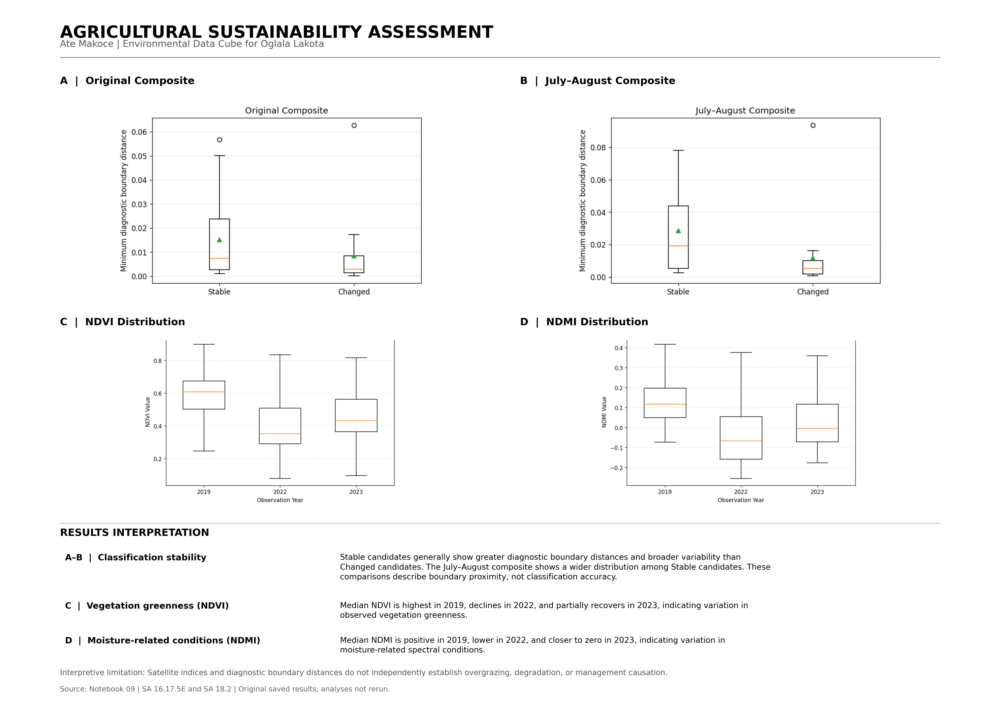


CLEAN SUSTAINABILITY FIGURE CREATED
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Sustainability_Assessment_Boxplots/Ate_Makoce_Clean_Sustainability_20261016_213955.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Sustainability_Assessment_Boxplots/Ate_Makoce_Clean_Sustainability_20261016_213955.pdf
Original data and notebooks unchanged.


In [27]:
# ======================================================================
# SA 19I — CLEAN DISSERTATION SUSTAINABILITY FIGURE
# Environmental Data Cube for Oglala Lakota
# Ate Makoce | BIA Parcel
#
# Uses original saved images from Notebook 09.
# Does not alter existing notebooks or data.
# ======================================================================

from pathlib import Path
from datetime import datetime
from io import BytesIO
from PIL import Image as PILImage
from IPython.display import display, Image as IPyImage
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import nbformat
import base64
import textwrap

PROJECT = (
    Path.home() / "Documents" / "ElishaWakinyanZi-WORK"
    / "datacube_2026" / "ate_makoce_agcube"
)

SOURCE = (
    PROJECT / "Notebooks"
    / "09_dissertation_data_cube_validation.ipynb"
)

OUTPUT = PROJECT / "results" / "Sustainability_Assessment_Boxplots"
OUTPUT.mkdir(parents=True, exist_ok=True)

nb = nbformat.read(SOURCE, as_version=4)

def load_image(cell_number):
    cell = nb.cells[cell_number - 1]

    for output in cell.get("outputs", []):
        data = output.get("data", {})

        for mime in ("image/png", "image/jpeg"):
            if mime in data:
                encoded = data[mime]
                if isinstance(encoded, list):
                    encoded = "".join(encoded)

                with PILImage.open(
                    BytesIO(base64.b64decode(encoded))
                ) as image:
                    return image.convert("RGB").copy()

    raise ValueError(f"No saved image in cell {cell_number}")

def split_image(image, top_fraction):
    w, h = image.size
    top = int(h * top_fraction)
    return (
        image.crop((0, top, w // 2, h)),
        image.crop((w // 2, top, w, h))
    )

stability = load_image(364)
vegetation = load_image(396)

original, summer = split_image(stability, 0.13)
ndvi, ndmi = split_image(vegetation, 0.17)

PANELS = [
    ("A", "Original Composite", original),
    ("B", "July–August Composite", summer),
    ("C", "NDVI Distribution", ndvi),
    ("D", "NDMI Distribution", ndmi)
]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "pdf.fonttype": 42,
    "savefig.facecolor": "white"
})

fig = plt.figure(figsize=(16.5, 11.7), facecolor="white")

# Header
fig.text(
    0.06, 0.965,
    "AGRICULTURAL SUSTAINABILITY ASSESSMENT",
    fontsize=20, fontweight="bold", va="top"
)

fig.text(
    0.06, 0.934,
    "Ate Makoce | Environmental Data Cube for Oglala Lakota",
    fontsize=11, color="#555555"
)

fig.add_artist(
    plt.Line2D(
        [0.06, 0.94], [0.919, 0.919],
        transform=fig.transFigure,
        color="#777777", linewidth=0.8
    )
)

# Four equally spaced plot panels.
positions = [
    (0.06, 0.575, 0.42, 0.285),
    (0.52, 0.575, 0.42, 0.285),
    (0.06, 0.285, 0.42, 0.235),
    (0.52, 0.285, 0.42, 0.235)
]

for (letter, title, image), (x, y, w, h) in zip(PANELS, positions):

    fig.text(
        x, y + h + 0.018,
        f"{letter}  |  {title}",
        fontsize=12, fontweight="bold",
        va="bottom"
    )

    ax = fig.add_axes([x, y, w, h])
    ax.imshow(image)
    ax.set_axis_off()

# Separate interpretation section: no text over plots.
fig.add_artist(
    plt.Line2D(
        [0.06, 0.94], [0.262, 0.262],
        transform=fig.transFigure,
        color="#BBBBBB", linewidth=0.8
    )
)

fig.text(
    0.06, 0.244,
    "RESULTS INTERPRETATION",
    fontsize=12, fontweight="bold"
)

interpretations = [
    (
        "A–B  |  Classification stability",
        "Stable candidates generally show greater diagnostic "
        "boundary distances and broader variability than Changed "
        "candidates. The July–August composite shows a wider "
        "distribution among Stable candidates. These comparisons "
        "describe boundary proximity, not classification accuracy."
    ),
    (
        "C  |  Vegetation greenness (NDVI)",
        "Median NDVI is highest in 2019, declines in 2022, and "
        "partially recovers in 2023, indicating variation in "
        "observed vegetation greenness."
    ),
    (
        "D  |  Moisture-related conditions (NDMI)",
        "Median NDMI is positive in 2019, lower in 2022, and "
        "closer to zero in 2023, indicating variation in "
        "moisture-related spectral conditions."
    )
]

ys = [0.219, 0.151, 0.102]

for (heading, explanation), y in zip(interpretations, ys):
    fig.text(
        0.065, y, heading,
        fontsize=10.3, fontweight="bold", va="top"
    )
    fig.text(
        0.34, y,
        textwrap.fill(explanation, width=105),
        fontsize=9.4, va="top", linespacing=1.35
    )

fig.text(
    0.06, 0.048,
    "Interpretive limitation: Satellite indices and diagnostic "
    "boundary distances do not independently establish overgrazing, "
    "degradation, or management causation.",
    fontsize=9, color="#555555"
)

fig.text(
    0.06, 0.025,
    "Source: Notebook 09 | SA 16.17.5E and SA 18.2 "
    "| Original saved results; analyses not rerun.",
    fontsize=8.5, color="#666666"
)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S")

png = OUTPUT / f"Ate_Makoce_Clean_Sustainability_{stamp}.png"
pdf = OUTPUT / f"Ate_Makoce_Clean_Sustainability_{stamp}.pdf"

fig.savefig(png, dpi=300, facecolor="white")
fig.savefig(pdf, facecolor="white")
plt.close(fig)

# Direct display works even when VS Code suppresses plt.show().
display(IPyImage(filename=str(png), width=1350))

print("\nCLEAN SUSTAINABILITY FIGURE CREATED")
print("PNG:", png)
print("PDF:", pdf)
print("Original data and notebooks unchanged.")

ATE MAKOCE — VEGETATION AND CLIMATE PCA
Annual observations: 24
Period: 2000 to 2023
Season: May–September
Variables: EVI, NDMI, Precipitation_mm, Mean_Tmax_C


,Year,EVI,NDMI,Precipitation_mm,Mean_Tmax_C
0,2000,0.2576,0.1822,197.1,28.1343
1,2001,0.2605,0.1796,266.8,27.7637
2,2002,0.2104,0.0602,214.4,28.1186
3,2003,0.2401,0.1310,202.4,27.4408
4,2004,0.2113,0.0370,267.6,26.4905
5,2005,0.2726,0.2043,331.6,27.5493
6,2006,0.2200,0.1054,221.5,28.1735
7,2007,0.2522,0.1444,231.1,28.8801
8,2008,0.2677,0.2059,369.9,25.9042
9,2009,0.2735,0.1990,239.0,25.8402



EXPLAINED VARIANCE


,Component,Explained_Variance_Pct,Cumulative_Variance_Pct
0,PC1,81.948,81.948
1,PC2,12.112,94.060
2,PC3,5.436,99.496
3,PC4,0.504,100.000



CORRELATION LOADINGS


,PC1,PC2,PC3,PC4
EVI,0.980,0.246,-0.103,0.108
NDMI,0.962,0.278,-0.178,-0.096
Precipitation_mm,0.936,-0.018,0.408,-0.015
Mean_Tmax_C,-0.811,0.606,0.135,-0.000



PCA SCORES BY YEAR


,Year,PC1,PC2,PC3,PC4
0,2000,-1.026,0.383,-0.607,-0.045
1,2001,-0.562,0.139,-0.163,-0.024
2,2002,-2.480,-0.715,0.407,0.011
3,2003,-1.378,-0.507,-0.361,0.029
4,2004,-1.835,-1.909,0.564,0.184
5,2005,0.150,0.227,0.089,-0.045
6,2006,-2.015,-0.356,0.193,-0.188
7,2007,-1.464,0.620,0.033,0.138
8,2008,0.818,-0.903,0.042,-0.193
9,2009,0.289,-0.896,-0.969,0.106


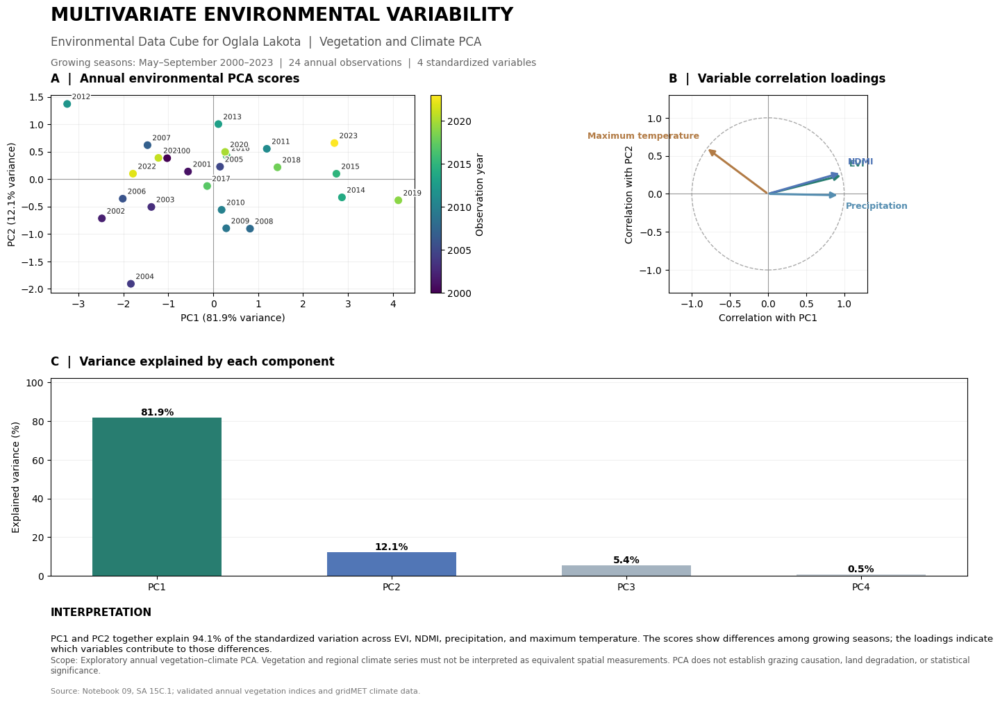

In [32]:
# ======================================================================
# SA 19K — PRINCIPAL COMPONENT ANALYSIS (PCA)
# Environmental Data Cube for Oglala Lakota
# Ate Makoce — Vegetation and Climate Relationships
#
# Source: Notebook 09, SA 15C.1
# Period: 2000–2023, May–September
#
# Variables:
#   EVI
#   NDMI
#   Growing-season precipitation (mm)
#   Growing-season mean daily maximum temperature (°C)
#
# READS existing validated source files.
# CREATES new, timestamped figure and statistical outputs.
# DOES NOT overwrite original research data or notebooks.
# ======================================================================

from pathlib import Path
from datetime import datetime
from IPython.display import display, Image, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

# ----------------------------------------------------------------------
# 1. PROJECT PATHS
# ----------------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

CACHE = PROJECT / "data" / "cache"

VEGETATION_FILE = (
    CACHE
    / "dissertation_validation"
    / "sa15b14_ndmi_evi_2000_2023_v1"
    / "ndmi_evi_annual_2000_2023_v1.csv"
)

PRECIP_FILE = (
    CACHE / "gridmet_pr_oglala_lakota_2000_2023.csv"
)

TEMP_FILE = (
    CACHE / "gridmet_tmmx_oglala_lakota_2000_2023.csv"
)

OUTPUT = (
    PROJECT / "results"
    / "Ate_Makoce_PCA_Analysis"
)

# Verify source files before creating output directories.
for path in [VEGETATION_FILE, PRECIP_FILE, TEMP_FILE]:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required PCA source file not found:\n{path}"
        )

# ----------------------------------------------------------------------
# 2. LOAD THE ORIGINAL VEGETATION DATA
# ----------------------------------------------------------------------

vegetation = pd.read_csv(VEGETATION_FILE)

required_columns = ["year", "mean_evi", "mean_ndmi"]

missing = [
    c for c in required_columns
    if c not in vegetation.columns
]

if missing:
    raise ValueError(
        "Vegetation source missing columns: "
        + ", ".join(missing)
    )

vegetation = vegetation.rename(columns={
    "year": "Year",
    "mean_evi": "EVI",
    "mean_ndmi": "NDMI"
})

vegetation = vegetation[["Year", "EVI", "NDMI"]].copy()

vegetation["Year"] = pd.to_numeric(
    vegetation["Year"], errors="raise"
).astype(int)

if vegetation["Year"].duplicated().any():
    raise ValueError("Duplicate years in vegetation data.")

# ----------------------------------------------------------------------
# 3. LOAD AND AGGREGATE GROWING-SEASON CLIMATE DATA
# ----------------------------------------------------------------------

precip = pd.read_csv(
    PRECIP_FILE, parse_dates=["date"]
)

temp = pd.read_csv(
    TEMP_FILE, parse_dates=["date"]
)

for df, column in [
    (precip, "pr"),
    (temp, "tmmx")
]:
    if column not in df.columns:
        raise ValueError(f"Missing climate column: {column}")

    if df["date"].isna().any():
        raise ValueError(
            f"Invalid dates in climate source: {column}"
        )

    if df["date"].duplicated().any():
        raise ValueError(
            f"Duplicate daily dates in climate source: {column}"
        )

def growing_season(df):
    return df.loc[
        df["date"].dt.year.between(2000, 2023)
        & df["date"].dt.month.between(5, 9)
    ].copy()

precip = growing_season(precip)
temp = growing_season(temp)

# Verify that all 153 calendar days are present for each year.
for name, df, column in [
    ("Precipitation", precip, "pr"),
    ("Temperature", temp, "tmmx")
]:
    df[column] = pd.to_numeric(
        df[column], errors="coerce"
    )

    counts = df.groupby(df["date"].dt.year)[column].count()

    if (
        len(counts) != 24
        or not counts.eq(153).all()
        or df[column].isna().any()
    ):
        raise ValueError(
            f"Incomplete May–September {name.lower()} data. "
            "PCA stopped to avoid comparing unequal seasons."
        )

precip_annual = (
    precip.groupby(precip["date"].dt.year)["pr"]
    .sum(min_count=1)
    .rename("Precipitation_mm")
)

temp_annual = (
    temp.groupby(temp["date"].dt.year)["tmmx"]
    .mean()
    .sub(273.15)
    .rename("Mean_Tmax_C")
)

climate = pd.concat(
    [precip_annual, temp_annual],
    axis=1
)

climate.index.name = "Year"

# ----------------------------------------------------------------------
# 4. COMBINE AND VALIDATE ANNUAL OBSERVATIONS
# ----------------------------------------------------------------------

data = (
    vegetation
    .merge(
        climate.reset_index(),
        on="Year",
        how="inner",
        validate="one_to_one"
    )
    .sort_values("Year")
    .reset_index(drop=True)
)

variables = [
    "EVI",
    "NDMI",
    "Precipitation_mm",
    "Mean_Tmax_C"
]

if (
    len(data) != 24
    or data["Year"].tolist() != list(range(2000, 2024))
):
    raise ValueError(
        "Expected one complete observation for every "
        "year from 2000 through 2023."
    )

if not np.isfinite(
    data[variables].to_numpy(dtype=float)
).all():
    raise ValueError("Missing or nonfinite PCA observations.")

if (data[variables].std(ddof=1) == 0).any():
    raise ValueError(
        "One or more PCA variables have zero variation."
    )

print("=" * 72)
print("ATE MAKOCE — VEGETATION AND CLIMATE PCA")
print("=" * 72)

print("Annual observations:", len(data))
print("Period:", data.Year.min(), "to", data.Year.max())
print("Season: May–September")
print("Variables:", ", ".join(variables))

display(data.round(4))

# ----------------------------------------------------------------------
# 5. STANDARDIZE VARIABLES AND PERFORM PCA
# ----------------------------------------------------------------------

# Standardization is necessary because precipitation,
# temperature and vegetation indices have different units.

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    data[variables].to_numpy(dtype=float)
)

pca = PCA(n_components=4)

scores = pca.fit_transform(X_scaled)

# Component directions are arbitrary in sign.
# Preserve the signs produced by this PCA run.
#
# Coordinates: standardized-variable PCA coefficients.
# Correlation loadings: correlation of original standardized
# variables with each principal-component score.

component_coefficients = pd.DataFrame(
    pca.components_.T,
    index=variables,
    columns=["PC1", "PC2", "PC3", "PC4"]
)

correlation_loadings = pd.DataFrame(
    pca.components_.T
    * np.sqrt(pca.explained_variance_),
    index=variables,
    columns=["PC1", "PC2", "PC3", "PC4"]
)

score_table = pd.DataFrame(
    scores,
    columns=["PC1", "PC2", "PC3", "PC4"]
)

score_table.insert(0, "Year", data["Year"].values)

variance_table = pd.DataFrame({
    "Component": ["PC1", "PC2", "PC3", "PC4"],
    "Explained_Variance_Pct":
        100 * pca.explained_variance_ratio_,
    "Cumulative_Variance_Pct":
        100 * np.cumsum(pca.explained_variance_ratio_)
})

print("\nEXPLAINED VARIANCE")
display(variance_table.round(3))

print("\nCORRELATION LOADINGS")
display(correlation_loadings.round(3))

print("\nPCA SCORES BY YEAR")
display(score_table.round(3))

# ----------------------------------------------------------------------
# 6. CREATE CLEAN THREE-PANEL DISSERTATION FIGURE
# ----------------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig = plt.figure(
    figsize=(15, 10.5),
    facecolor="white"
)

gs = fig.add_gridspec(
    2, 2,
    left=0.075,
    right=0.955,
    top=0.85,
    bottom=0.19,
    hspace=0.43,
    wspace=0.30
)

ax_scores = fig.add_subplot(gs[0, 0])
ax_loadings = fig.add_subplot(gs[0, 1])
ax_variance = fig.add_subplot(gs[1, :])

pc1_pct = pca.explained_variance_ratio_[0] * 100
pc2_pct = pca.explained_variance_ratio_[1] * 100

fig.text(
    0.075, 0.952,
    "MULTIVARIATE ENVIRONMENTAL VARIABILITY",
    fontsize=19,
    fontweight="bold",
    ha="left"
)

fig.text(
    0.075, 0.918,
    "Environmental Data Cube for Oglala Lakota  |  "
    "Vegetation and Climate PCA",
    fontsize=12,
    color="#555555"
)

fig.text(
    0.075, 0.891,
    "Growing seasons: May–September 2000–2023  |  "
    "24 annual observations  |  4 standardized variables",
    fontsize=10,
    color="#666666"
)

# --------------------------------------------------------------
# PANEL A — YEAR SCORES
# --------------------------------------------------------------

scatter = ax_scores.scatter(
    scores[:, 0],
    scores[:, 1],
    c=data["Year"],
    cmap="viridis",
    s=78,
    edgecolors="white",
    linewidths=0.8,
    zorder=3
)

for year, x, y in zip(
    data["Year"],
    scores[:, 0],
    scores[:, 1]
):
    label = ax_scores.annotate(
        str(year),
        (x, y),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=7.5,
        color="#222222"
    )

    label.set_path_effects([
        pe.withStroke(
            linewidth=2.5,
            foreground="white"
        )
    ])

ax_scores.axhline(
    0, color="#999999", linewidth=0.8
)
ax_scores.axvline(
    0, color="#999999", linewidth=0.8
)

ax_scores.set_title(
    "A  |  Annual environmental PCA scores",
    loc="left",
    fontsize=12,
    fontweight="bold",
    pad=13
)

ax_scores.set_xlabel(
    f"PC1 ({pc1_pct:.1f}% variance)"
)
ax_scores.set_ylabel(
    f"PC2 ({pc2_pct:.1f}% variance)"
)

ax_scores.grid(alpha=0.18)

cbar = fig.colorbar(
    scatter,
    ax=ax_scores,
    fraction=0.046,
    pad=0.04
)

cbar.set_label("Observation year")

# --------------------------------------------------------------
# PANEL B — VARIABLE CORRELATION LOADINGS
# --------------------------------------------------------------

loading_labels = {
    "EVI": "EVI",
    "NDMI": "NDMI",
    "Precipitation_mm": "Precipitation",
    "Mean_Tmax_C": "Maximum temperature"
}

colors = [
    "#287D70",
    "#5176B6",
    "#548DB0",
    "#B27B45"
]

for color, variable in zip(colors, variables):

    x = correlation_loadings.loc[variable, "PC1"]
    y = correlation_loadings.loc[variable, "PC2"]

    ax_loadings.annotate(
        "",
        xy=(x, y),
        xytext=(0, 0),
        arrowprops=dict(
            arrowstyle="-|>",
            linewidth=2.2,
            color=color,
            mutation_scale=13
        )
    )

    ax_loadings.annotate(
        loading_labels[variable],
        (x, y),
        xytext=(
            7 if x >= 0 else -7,
            7 if y >= 0 else -7
        ),
        textcoords="offset points",
        ha="left" if x >= 0 else "right",
        va="bottom" if y >= 0 else "top",
        fontsize=9,
        color=color,
        fontweight="bold"
    )

circle = plt.Circle(
    (0, 0),
    1,
    fill=False,
    linestyle="--",
    color="#AAAAAA",
    linewidth=1
)

ax_loadings.add_patch(circle)

ax_loadings.axhline(
    0, color="#999999", linewidth=0.8
)
ax_loadings.axvline(
    0, color="#999999", linewidth=0.8
)

ax_loadings.set_xlim(-1.3, 1.3)
ax_loadings.set_ylim(-1.3, 1.3)
ax_loadings.set_aspect("equal", adjustable="box")

ax_loadings.set_title(
    "B  |  Variable correlation loadings",
    loc="left",
    fontsize=12,
    fontweight="bold",
    pad=13
)

ax_loadings.set_xlabel("Correlation with PC1")
ax_loadings.set_ylabel("Correlation with PC2")

ax_loadings.grid(alpha=0.15)

# --------------------------------------------------------------
# PANEL C — EXPLAINED VARIANCE
# --------------------------------------------------------------

components = ["PC1", "PC2", "PC3", "PC4"]

variance_pct = (
    pca.explained_variance_ratio_ * 100
)

bars = ax_variance.bar(
    components,
    variance_pct,
    color=[
        "#287D70",
        "#5176B6",
        "#A4B3C0",
        "#C5CED5"
    ],
    width=0.55
)

for bar, value in zip(bars, variance_pct):
    ax_variance.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.2,
        f"{value:.1f}%",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax_variance.set_ylim(
    0,
    max(variance_pct) * 1.25
)

ax_variance.set_ylabel(
    "Explained variance (%)"
)

ax_variance.set_title(
    "C  |  Variance explained by each component",
    loc="left",
    fontsize=12,
    fontweight="bold",
    pad=13
)

ax_variance.grid(
    axis="y",
    alpha=0.18
)

ax_variance.set_axisbelow(True)

# ----------------------------------------------------------------------
# 7. INTERPRETATION INSIDE THE FIGURE
# ----------------------------------------------------------------------

combined_pct = pc1_pct + pc2_pct

interpretation = (
    f"PC1 and PC2 together explain {combined_pct:.1f}% "
    "of the standardized variation across EVI, NDMI, "
    "precipitation, and maximum temperature. "
    "The scores show differences among growing seasons; "
    "the loadings indicate which variables contribute "
    "to those differences."
)

fig.text(
    0.075, 0.135,
    "INTERPRETATION",
    fontsize=11,
    fontweight="bold",
    ha="left"
)

fig.text(
    0.075, 0.109,
    interpretation,
    fontsize=9.5,
    ha="left",
    va="top",
    wrap=True
)

fig.text(
    0.075, 0.058,
    "Scope: Exploratory annual vegetation–climate PCA. "
    "Vegetation and regional climate series must not be "
    "interpreted as equivalent spatial measurements. "
    "PCA does not establish grazing causation, "
    "land degradation, or statistical significance.",
    fontsize=8.4,
    color="#555555",
    ha="left",
    wrap=True
)

fig.text(
    0.075, 0.028,
    "Source: Notebook 09, SA 15C.1; validated annual "
    "vegetation indices and gridMET climate data.",
    fontsize=8,
    color="#777777",
    ha="left"
)

# ----------------------------------------------------------------------
# 8. SAVE NEW RESULTS
# ----------------------------------------------------------------------

OUTPUT.mkdir(parents=True, exist_ok=True)

stamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

stem = f"Ate_Makoce_Vegetation_Climate_PCA_{stamp}"

png = OUTPUT / f"{stem}.png"
pdf = OUTPUT / f"{stem}.pdf"

scores_csv = OUTPUT / f"{stem}_scores.csv"
loadings_csv = OUTPUT / f"{stem}_loadings.csv"
variance_csv = OUTPUT / f"{stem}_variance.csv"
data_csv = OUTPUT / f"{stem}_input_data.csv"

fig.savefig(
    png,
    dpi=300,
    facecolor="white"
)

### Principal Component Analysis of Vegetation and Climate Variability

Principal Component Analysis (PCA) was conducted using 24 annual growing-season observations (2000–2023) and four standardized environmental variables: Enhanced Vegetation Index (EVI), Normalized Difference Moisture Index (NDMI), cumulative precipitation, and mean daily maximum temperature. The first two principal components explained 94.06% of the total standardized variance, with PC1 accounting for 81.95% and PC2 accounting for 12.11%.

PC1 exhibited strong positive correlations with EVI (0.980), NDMI (0.962), and precipitation (0.936), and a negative correlation with maximum temperature (−0.811). These loadings indicate that the dominant component differentiated growing seasons characterized by greater vegetation greenness, higher moisture-related spectral values, and greater precipitation from seasons characterized by warmer and comparatively drier conditions.

Annual PCA scores showed substantial interannual variation. The highest PC1 score occurred in 2019 (+4.120), while the lowest occurred in 2012 (−3.252). The 2022 growing season exhibited a negative PC1 score (−1.788), followed by a positive score in 2023 (+2.697). These patterns demonstrate variation in the combined environmental indicators across the study period.

The PCA provides a multivariate summary of vegetation and climate relationships relevant to agricultural sustainability assessment. However, the observed associations do not independently establish the causes of vegetation change or demonstrate grazing-related land degradation.

In [33]:
# ======================================================================
# SA 19L — CLEAN, PUBLICATION-QUALITY PCA FIGURE
# Environmental Data Cube for Oglala Lakota
# Ate Makoce — Vegetation and Climate PCA
#
# Reads existing PCA statistical outputs.
# Does not rerun PCA or modify original data.
# Creates NEW timestamped PNG and PDF files.
# ======================================================================

from pathlib import Path
from datetime import datetime
from IPython.display import display, Image as IPyImage
from matplotlib.lines import Line2D
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import textwrap

# --------------------------------------------------------------
# 1. LOCATE EXISTING PCA RESULTS
# --------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

OUTPUT = PROJECT / "results" / "Ate_Makoce_PCA_Analysis"

if not OUTPUT.exists():
    raise FileNotFoundError(
        f"PCA results directory not found:\n{OUTPUT}"
    )

# Find complete matching PCA result sets.
prefix = "Ate_Makoce_Vegetation_Climate_PCA_"

sets = []

for scores_file in OUTPUT.glob(f"{prefix}*_scores.csv"):

    stem = scores_file.name.removesuffix("_scores.csv")

    loadings_file = OUTPUT / f"{stem}_loadings.csv"
    variance_file = OUTPUT / f"{stem}_variance.csv"

    if loadings_file.exists() and variance_file.exists():
        sets.append((
            scores_file.stat().st_mtime,
            stem,
            scores_file,
            loadings_file,
            variance_file
        ))

if not sets:
    raise FileNotFoundError(
        "No complete PCA statistical output set found. "
        "The original PCA cell must finish saving its CSV files."
    )

_, source_stem, scores_path, loadings_path, variance_path = max(
    sets, key=lambda x: x[0]
)

scores = pd.read_csv(scores_path)
loadings = pd.read_csv(loadings_path, index_col=0)
variance = pd.read_csv(variance_path)

required_scores = {"Year", "PC1", "PC2"}
required_loadings = {"PC1", "PC2"}
required_variance = {
    "Component",
    "Explained_Variance_Pct",
    "Cumulative_Variance_Pct"
}

if not required_scores.issubset(scores.columns):
    raise ValueError("PCA scores CSV is missing required columns.")

if not required_loadings.issubset(loadings.columns):
    raise ValueError("PCA loadings CSV is missing PC1 or PC2.")

if not required_variance.issubset(variance.columns):
    raise ValueError("PCA variance CSV has unexpected columns.")

scores = scores.sort_values("Year").copy()

pc1_pct = float(
    variance.loc[
        variance["Component"] == "PC1",
        "Explained_Variance_Pct"
    ].iloc[0]
)

pc2_pct = float(
    variance.loc[
        variance["Component"] == "PC2",
        "Explained_Variance_Pct"
    ].iloc[0]
)

combined_pct = pc1_pct + pc2_pct

# --------------------------------------------------------------
# 2. FIGURE SETTINGS
# --------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white"
})

fig = plt.figure(
    figsize=(14, 10),
    facecolor="white"
)

gs = fig.add_gridspec(
    2, 2,
    left=0.085,
    right=0.94,
    top=0.825,
    bottom=0.225,
    wspace=0.35,
    hspace=0.48,
    height_ratios=[1.05, 0.85]
)

ax_scores = fig.add_subplot(gs[0, 0])
ax_loadings = fig.add_subplot(gs[0, 1])
ax_variance = fig.add_subplot(gs[1, :])

# --------------------------------------------------------------
# 3. TITLE AND SUBTITLE
# --------------------------------------------------------------

fig.text(
    0.085, 0.955,
    "MULTIVARIATE ENVIRONMENTAL VARIABILITY",
    fontsize=19,
    fontweight="bold",
    ha="left",
    va="top"
)

fig.text(
    0.085, 0.915,
    "Environmental Data Cube for Oglala Lakota",
    fontsize=12,
    color="#444444",
    ha="left"
)

fig.text(
    0.085, 0.885,
    "Ate Makoce | May–September 2000–2023 | "
    "24 annual observations | 4 standardized indicators",
    fontsize=9.5,
    color="#666666",
    ha="left"
)

fig.add_artist(
    Line2D(
        [0.085, 0.94],
        [0.86, 0.86],
        transform=fig.transFigure,
        color="#C6CDD2",
        linewidth=1
    )
)

# --------------------------------------------------------------
# 4. PANEL A — ANNUAL PCA SCORES
# --------------------------------------------------------------

scatter = ax_scores.scatter(
    scores["PC1"],
    scores["PC2"],
    c=scores["Year"],
    cmap="viridis",
    s=85,
    edgecolors="white",
    linewidths=0.9,
    zorder=3
)

# Label selected years that are informative for interpretation.
highlight_years = [2004, 2012, 2014, 2019, 2022, 2023]

offsets = {
    2004: (7, -13),
    2012: (7, 7),
    2014: (7, -13),
    2019: (-7, 9),
    2022: (7, 9),
    2023: (7, 8)
}

for _, row in scores.iterrows():

    year = int(row["Year"])

    if year not in highlight_years:
        continue

    dx, dy = offsets.get(year, (6, 6))

    annotation = ax_scores.annotate(
        str(year),
        (row["PC1"], row["PC2"]),
        xytext=(dx, dy),
        textcoords="offset points",
        ha="right" if dx < 0 else "left",
        fontsize=9,
        fontweight="bold",
        color="#222222"
    )

    annotation.set_path_effects([
        pe.withStroke(
            linewidth=3,
            foreground="white"
        )
    ])

ax_scores.axhline(
    0, color="#AAB2B8", linewidth=0.9, zorder=0
)

ax_scores.axvline(
    0, color="#AAB2B8", linewidth=0.9, zorder=0
)

ax_scores.set_title(
    "A  |  Annual environmental conditions",
    loc="left",
    fontweight="bold",
    pad=13
)

ax_scores.set_xlabel(
    f"PC1 ({pc1_pct:.1f}% of variance)"
)

ax_scores.set_ylabel(
    f"PC2 ({pc2_pct:.1f}% of variance)"
)

ax_scores.grid(alpha=0.15)
ax_scores.set_axisbelow(True)

colorbar = fig.colorbar(
    scatter,
    ax=ax_scores,
    fraction=0.045,
    pad=0.035
)

colorbar.set_label("Year", fontsize=9)

# --------------------------------------------------------------
# 5. PANEL B — CLEAN PCA CORRELATION LOADINGS
# --------------------------------------------------------------

names = {
    "EVI": "EVI",
    "NDMI": "NDMI",
    "Precipitation_mm": "Precipitation",
    "Mean_Tmax_C": "Maximum temperature"
}

colors = {
    "EVI": "#248277",
    "NDMI": "#4267A7",
    "Precipitation_mm": "#6D98C0",
    "Mean_Tmax_C": "#BC783B"
}

for variable in loadings.index:

    x = float(loadings.loc[variable, "PC1"])
    y = float(loadings.loc[variable, "PC2"])

    ax_loadings.annotate(
        "",
        xy=(x, y),
        xytext=(0, 0),
        arrowprops=dict(
            arrowstyle="-|>",
            lw=2.6,
            color=colors.get(variable, "#666666"),
            mutation_scale=14
        )
    )

# Correlation circle.
circle = plt.Circle(
    (0, 0),
    1,
    fill=False,
    linestyle="--",
    color="#B7BEC4",
    linewidth=1
)

ax_loadings.add_patch(circle)

ax_loadings.axhline(
    0, color="#AAB2B8", linewidth=0.9
)

ax_loadings.axvline(
    0, color="#AAB2B8", linewidth=0.9
)

ax_loadings.set_xlim(-1.15, 1.15)
ax_loadings.set_ylim(-1.15, 1.15)
ax_loadings.set_aspect("equal", adjustable="box")

ax_loadings.set_title(
    "B  |  Environmental variable loadings",
    loc="left",
    fontweight="bold",
    pad=13
)

ax_loadings.set_xlabel("Correlation with PC1")
ax_loadings.set_ylabel("Correlation with PC2")

ax_loadings.grid(alpha=0.15)

legend_handles = [
    Line2D(
        [0], [0],
        color=colors.get(variable, "#666666"),
        lw=3,
        label=names.get(variable, variable)
    )
    for variable in loadings.index
]

ax_loadings.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.22),
    ncol=2,
    frameon=False,
    fontsize=8.5
)

# --------------------------------------------------------------
# 6. PANEL C — EXPLAINED VARIANCE
# --------------------------------------------------------------

components = variance["Component"].astype(str).tolist()

values = variance[
    "Explained_Variance_Pct"
].to_numpy(dtype=float)

cumulative = variance[
    "Cumulative_Variance_Pct"
].to_numpy(dtype=float)

bars = ax_variance.bar(
    components,
    values,
    width=0.55,
    color=[
        "#287F75",
        "#5279B6",
        "#9DADB9",
        "#CAD2D9"
    ][:len(components)]
)

for bar, value in zip(bars, values):

    ax_variance.annotate(
        f"{value:.1f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

ax_variance.set_ylim(0, 105)

ax_variance.set_title(
    "C  |  Explained variance",
    loc="left",
    fontweight="bold",
    pad=13
)

ax_variance.set_ylabel("Variance explained (%)")
ax_variance.set_axisbelow(True)
ax_variance.grid(axis="y", alpha=0.15)

# Cumulative variance on the right axis.
ax_cumulative = ax_variance.twinx()

ax_cumulative.plot(
    components,
    cumulative,
    color="#3F4953",
    marker="o",
    markersize=7,
    linewidth=2,
    label="Cumulative variance"
)

ax_cumulative.set_ylim(0, 105)
ax_cumulative.set_ylabel("Cumulative variance (%)")

ax_cumulative.spines["top"].set_visible(False)

# --------------------------------------------------------------
# 7. SCIENTIFIC INTERPRETATION
# --------------------------------------------------------------

fig.add_artist(
    Line2D(
        [0.085, 0.94],
        [0.175, 0.175],
        transform=fig.transFigure,
        color="#C6CDD2",
        linewidth=1
    )
)

fig.text(
    0.085, 0.154,
    "RESULTS INTERPRETATION",
    fontsize=11,
    fontweight="bold",
    ha="left"
)

interpretation = (
    f"The first two principal components explain "
    f"{combined_pct:.2f}% of the standardized variance "
    f"(PC1: {pc1_pct:.2f}%; PC2: {pc2_pct:.2f}%). "
    "PC1 is positively associated with EVI, NDMI, and "
    "precipitation and negatively associated with maximum "
    "temperature. Annual scores summarize variation in "
    "combined vegetation and climate conditions."
)

fig.text(
    0.085, 0.129,
    textwrap.fill(interpretation, width=150),
    fontsize=9.3,
    ha="left",
    va="top",
    linespacing=1.5
)

fig.text(
    0.085, 0.067,
    "Interpretive limitation: This exploratory PCA describes "
    "associations, not causal effects of grazing or evidence "
    "of land degradation. Vegetation and climate datasets "
    "may represent different spatial footprints.",
    fontsize=8.6,
    color="#555555",
    ha="left",
    wrap=True
)

fig.text(
    0.085, 0.032,
    "Source: Notebook 09, SA 15C.1 | "
    "Growing-season EVI, NDMI, precipitation, "
    "and maximum temperature, 2000–2023.",
    fontsize=8.2,
    color="#777777",
    ha="left"
)

# --------------------------------------------------------------
# 8. SAVE AND DISPLAY
# --------------------------------------------------------------

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

png = OUTPUT / f"Ate_Makoce_PCA_Clean_{stamp}.png"
pdf = OUTPUT / f"Ate_Makoce_PCA_Clean_{stamp}.pdf"

fig.savefig(
    png,
    dpi=300,
    facecolor="white"
)

fig.savefig(
    pdf,
    facecolor="white"
)

plt.close(fig)

display(
    IPyImage(
        filename=str(png),
        width=1350
    )
)

print("=" * 72)
print("CLEAN PCA FIGURE CREATED")
print("=" * 72)
print(f"PC1: {pc1_pct:.2f}%")
print(f"PC2: {pc2_pct:.2f}%")
print(f"Combined: {combined_pct:.2f}%")
print("PNG:", png)
print("PDF:", pdf)
print("Original PCA results and research data: UNCHANGED")
print("=" * 72)

FileNotFoundError: No complete PCA statistical output set found. The original PCA cell must finish saving its CSV files.

Using PCA results already available in memory.


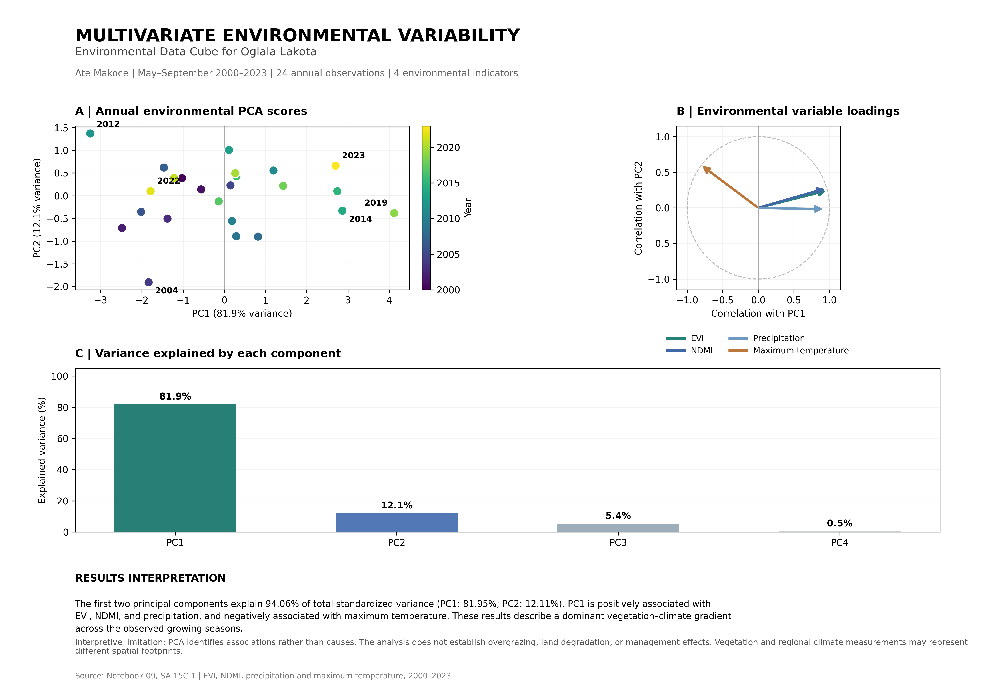


CLEAN PCA FIGURE CREATED
PC1: 81.95%
PC2: 12.11%
Combined: 94.06%
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_PCA_Analysis/Ate_Makoce_PCA_Clean_20261016_215201_837390.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_PCA_Analysis/Ate_Makoce_PCA_Clean_20261016_215201_837390.pdf
Original


In [35]:
# ======================================================================
# SA 19L — CLEAN PCA FIGURE (CORRECTED)
# Environmental Data Cube for Oglala Lakota
# Ate Makoce — Vegetation and Climate PCA
#
# Uses existing PCA results in memory or searches for saved CSVs.
# Does not modify original notebooks, data cube, or analyses.
# ======================================================================

from pathlib import Path
from datetime import datetime
from IPython.display import display, Image as IPyImage
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import textwrap

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

OUTPUT = PROJECT / "results" / "Ate_Makoce_PCA_Analysis"

# ----------------------------------------------------------------------
# 1. RECOVER PCA RESULTS
# ----------------------------------------------------------------------

def valid_results(s, l, v):
    return (
        isinstance(s, pd.DataFrame)
        and isinstance(l, pd.DataFrame)
        and isinstance(v, pd.DataFrame)
        and {"Year", "PC1", "PC2"}.issubset(s.columns)
        and {"PC1", "PC2"}.issubset(l.columns)
        and {
            "Component",
            "Explained_Variance_Pct"
        }.issubset(v.columns)
    )

scores_df = globals().get("score_table")
loadings_df = globals().get("correlation_loadings")
variance_df = globals().get("variance_table")

if valid_results(scores_df, loadings_df, variance_df):
    print("Using PCA results already available in memory.")

else:
    print("Searching for saved PCA statistical outputs...")

    found = False

    for scores_path in sorted(
        PROJECT.rglob("*_scores.csv"),
        key=lambda p: p.stat().st_mtime,
        reverse=True
    ):
        stem = scores_path.name.removesuffix("_scores.csv")

        loadings_path = scores_path.with_name(
            stem + "_loadings.csv"
        )

        variance_path = scores_path.with_name(
            stem + "_variance.csv"
        )

        if not (
            loadings_path.is_file()
            and variance_path.is_file()
        ):
            continue

        try:
            s = pd.read_csv(scores_path)
            l = pd.read_csv(loadings_path, index_col=0)
            v = pd.read_csv(variance_path)

            if valid_results(s, l, v):
                scores_df = s
                loadings_df = l
                variance_df = v
                found = True
                print("Recovered PCA files from:", scores_path.parent)
                break

        except Exception:
            continue

    if not found:
        raise RuntimeError(
            "PCA statistical results were not found in memory "
            "or on disk. Please run the original successful PCA "
            "cell again, then run this cleanup cell."
        )

scores_df = scores_df.copy().sort_values("Year")
loadings_df = loadings_df.copy()
variance_df = variance_df.copy()

pc1 = float(
    variance_df.loc[
        variance_df["Component"] == "PC1",
        "Explained_Variance_Pct"
    ].iloc[0]
)

pc2 = float(
    variance_df.loc[
        variance_df["Component"] == "PC2",
        "Explained_Variance_Pct"
    ].iloc[0]
)

combined = pc1 + pc2

# ----------------------------------------------------------------------
# 2. FIGURE LAYOUT
# ----------------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

fig = plt.figure(figsize=(15, 10.5), facecolor="white")

gs = fig.add_gridspec(
    2, 2,
    left=0.075,
    right=0.94,
    top=0.82,
    bottom=0.24,
    wspace=0.38,
    hspace=0.48
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, :])

fig.text(
    0.075, 0.96,
    "MULTIVARIATE ENVIRONMENTAL VARIABILITY",
    fontsize=19,
    fontweight="bold",
    va="top"
)

fig.text(
    0.075, 0.921,
    "Environmental Data Cube for Oglala Lakota",
    fontsize=12,
    color="#444444"
)

fig.text(
    0.075, 0.891,
    "Ate Makoce | May–September 2000–2023 | "
    "24 annual observations | 4 environmental indicators",
    fontsize=10,
    color="#666666"
)

# ----------------------------------------------------------------------
# 3. PANEL A — PCA SCORES
# ----------------------------------------------------------------------

scatter = ax1.scatter(
    scores_df["PC1"],
    scores_df["PC2"],
    c=scores_df["Year"],
    cmap="viridis",
    s=95,
    edgecolors="white",
    linewidths=1,
    zorder=3
)

highlight_years = {
    2004: (7, -12),
    2012: (7, 7),
    2014: (7, -12),
    2019: (-7, 8),
    2022: (7, 8),
    2023: (7, 8)
}

for _, row in scores_df.iterrows():

    year = int(row["Year"])

    if year in highlight_years:

        dx, dy = highlight_years[year]

        ax1.annotate(
            str(year),
            (row["PC1"], row["PC2"]),
            xytext=(dx, dy),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            ha="right" if dx < 0 else "left"
        )

ax1.axhline(0, color="#AAAAAA", linewidth=0.8)
ax1.axvline(0, color="#AAAAAA", linewidth=0.8)

ax1.set_title(
    "A | Annual environmental PCA scores",
    loc="left",
    fontweight="bold",
    pad=12
)

ax1.set_xlabel(f"PC1 ({pc1:.1f}% variance)")
ax1.set_ylabel(f"PC2 ({pc2:.1f}% variance)")
ax1.grid(alpha=0.15)

cbar = fig.colorbar(
    scatter,
    ax=ax1,
    fraction=0.045,
    pad=0.035
)

cbar.set_label("Year")

# ----------------------------------------------------------------------
# 4. PANEL B — VARIABLE LOADINGS
# ----------------------------------------------------------------------

variable_names = {
    "EVI": "EVI",
    "NDMI": "NDMI",
    "Precipitation_mm": "Precipitation",
    "Mean_Tmax_C": "Maximum temperature"
}

variable_colors = {
    "EVI": "#248277",
    "NDMI": "#4267A7",
    "Precipitation_mm": "#6D98C0",
    "Mean_Tmax_C": "#BC783B"
}

legend_handles = []

for variable in loadings_df.index:

    x = float(loadings_df.loc[variable, "PC1"])
    y = float(loadings_df.loc[variable, "PC2"])

    color = variable_colors.get(variable, "#777777")

    ax2.annotate(
        "",
        xy=(x, y),
        xytext=(0, 0),
        arrowprops=dict(
            arrowstyle="-|>",
            linewidth=2.6,
            color=color,
            mutation_scale=14
        )
    )

    legend_handles.append(
        Line2D(
            [0], [0],
            color=color,
            linewidth=3,
            label=variable_names.get(variable, variable)
        )
    )

ax2.add_patch(
    plt.Circle(
        (0, 0),
        1,
        fill=False,
        linestyle="--",
        color="#BBBBBB"
    )
)

ax2.axhline(0, color="#AAAAAA", linewidth=0.8)
ax2.axvline(0, color="#AAAAAA", linewidth=0.8)

ax2.set_xlim(-1.15, 1.15)
ax2.set_ylim(-1.15, 1.15)
ax2.set_aspect("equal", adjustable="box")

ax2.set_title(
    "B | Environmental variable loadings",
    loc="left",
    fontweight="bold",
    pad=12
)

ax2.set_xlabel("Correlation with PC1")
ax2.set_ylabel("Correlation with PC2")
ax2.grid(alpha=0.15)

ax2.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.23),
    ncol=2,
    frameon=False,
    fontsize=9
)

# ----------------------------------------------------------------------
# 5. PANEL C — EXPLAINED VARIANCE
# ----------------------------------------------------------------------

components = variance_df["Component"].astype(str).tolist()

values = variance_df[
    "Explained_Variance_Pct"
].to_numpy(dtype=float)

bars = ax3.bar(
    components,
    values,
    width=0.55,
    color=["#287F75", "#5279B6", "#9DADB9", "#CAD2D9"][
        :len(values)
    ]
)

for bar, value in zip(bars, values):

    ax3.annotate(
        f"{value:.1f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax3.set_ylim(0, 105)
ax3.set_ylabel("Explained variance (%)")

ax3.set_title(
    "C | Variance explained by each component",
    loc="left",
    fontweight="bold",
    pad=12
)

ax3.grid(axis="y", alpha=0.15)
ax3.set_axisbelow(True)

# ----------------------------------------------------------------------
# 6. INTERPRETATION
# ----------------------------------------------------------------------

fig.text(
    0.075, 0.169,
    "RESULTS INTERPRETATION",
    fontsize=11,
    fontweight="bold"
)

interpretation = (
    f"The first two principal components explain "
    f"{combined:.2f}% of total standardized variance "
    f"(PC1: {pc1:.2f}%; PC2: {pc2:.2f}%). "
    "PC1 is positively associated with EVI, NDMI, and "
    "precipitation, and negatively associated with "
    "maximum temperature. These results describe a "
    "dominant vegetation–climate gradient across "
    "the observed growing seasons."
)

fig.text(
    0.075, 0.143,
    textwrap.fill(interpretation, width=145),
    fontsize=9.5,
    va="top",
    linespacing=1.5
)

fig.text(
    0.075, 0.068,
    "Interpretive limitation: PCA identifies associations "
    "rather than causes. The analysis does not establish "
    "overgrazing, land degradation, or management effects. "
    "Vegetation and regional climate measurements may "
    "represent different spatial footprints.",
    fontsize=8.7,
    color="#555555",
    wrap=True
)

fig.text(
    0.075, 0.031,
    "Source: Notebook 09, SA 15C.1 | "
    "EVI, NDMI, precipitation and maximum temperature, 2000–2023.",
    fontsize=8.3,
    color="#777777"
)

# ----------------------------------------------------------------------
# 7. SAVE AND DISPLAY
# ----------------------------------------------------------------------

OUTPUT.mkdir(parents=True, exist_ok=True)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

png = OUTPUT / f"Ate_Makoce_PCA_Clean_{stamp}.png"
pdf = OUTPUT / f"Ate_Makoce_PCA_Clean_{stamp}.pdf"

fig.savefig(
    png,
    dpi=300,
    facecolor="white"
)

fig.savefig(
    pdf,
    facecolor="white"
)

plt.close(fig)

display(IPyImage(filename=str(png), width=1350))

print("\nCLEAN PCA FIGURE CREATED")
print(f"PC1: {pc1:.2f}%")
print(f"PC2: {pc2:.2f}%")
print(f"Combined: {combined:.2f}%")
print("PNG:", png)
print("PDF:", pdf)
print("Original")

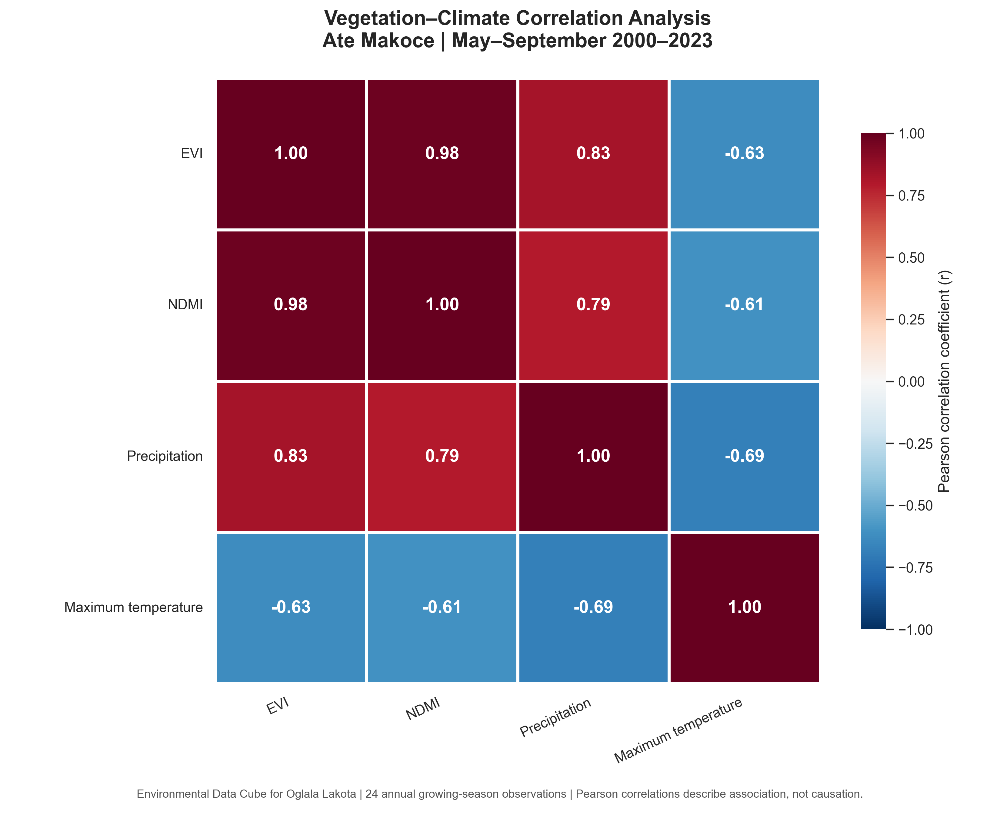


CORRELATION HEATMAP CREATED
Observations: 24
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Correlation_Analysis/Ate_Makoce_Correlation_20261016_215732_078388.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Correlation_Analysis/Ate_Makoce_Correlation_20261016_215732_078388.pdf
Correlation CSV: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Correlation_Analysis/Ate_Makoce_Correlation_20261016_215732_078388_coefficients.csv
P-values CSV: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Correlation_Analysis/Ate_Makoce_Correlation_20261016_215732_078388_pvalues.csv
Input observations: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Correlation_Analysis/Ate_Makoce_Correlation_20261016_

,EVI,NDMI,Precipitation_mm,Mean_Tmax_C
EVI,1.000,0.977,0.834,-0.632
NDMI,0.977,1.000,0.790,-0.609
Precipitation_mm,0.834,0.790,1.000,-0.685
Mean_Tmax_C,-0.632,-0.609,-0.685,1.000


In [41]:
# ======================================================================
# SA 19M — CORRELATION HEATMAP (CORRECTED)
# Environmental Data Cube for Oglala Lakota
# Ate Makoce — Vegetation and Climate Assessment
#
# Reads the same source data used for the successful PCA.
# Does NOT rerun PCA or alter existing research data.
# ======================================================================

from pathlib import Path
from datetime import datetime
from IPython.display import display, Image as IPyImage
from scipy.stats import pearsonr
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import textwrap

# --------------------------------------------------------------
# 1. PROJECT PATHS
# --------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

CACHE = PROJECT / "data" / "cache"

VEGETATION_FILE = (
    CACHE
    / "dissertation_validation"
    / "sa15b14_ndmi_evi_2000_2023_v1"
    / "ndmi_evi_annual_2000_2023_v1.csv"
)

PRECIP_FILE = CACHE / "gridmet_pr_oglala_lakota_2000_2023.csv"
TEMP_FILE = CACHE / "gridmet_tmmx_oglala_lakota_2000_2023.csv"

OUTPUT = (
    PROJECT / "results"
    / "Ate_Makoce_Correlation_Analysis"
)

for source in [VEGETATION_FILE, PRECIP_FILE, TEMP_FILE]:
    if not source.is_file():
        raise FileNotFoundError(
            f"Required source file missing:\n{source}"
        )

# --------------------------------------------------------------
# 2. LOAD VEGETATION INDICES
# --------------------------------------------------------------

veg = pd.read_csv(VEGETATION_FILE)

required = {"year", "mean_evi", "mean_ndmi"}

if not required.issubset(veg.columns):
    raise ValueError(
        f"Vegetation CSV columns do not match expectations: "
        f"{veg.columns.tolist()}"
    )

veg = veg.rename(columns={
    "year": "Year",
    "mean_evi": "EVI",
    "mean_ndmi": "NDMI"
})

veg = veg[["Year", "EVI", "NDMI"]].copy()

veg["Year"] = pd.to_numeric(
    veg["Year"], errors="raise"
).astype(int)

if veg["Year"].duplicated().any():
    raise ValueError("Duplicate vegetation years found.")

# --------------------------------------------------------------
# 3. LOAD AND AGGREGATE CLIMATE
# --------------------------------------------------------------

pr = pd.read_csv(PRECIP_FILE, parse_dates=["date"])
tx = pd.read_csv(TEMP_FILE, parse_dates=["date"])

for df, column in [(pr, "pr"), (tx, "tmmx")]:
    if column not in df.columns:
        raise ValueError(f"Missing column: {column}")

    if df["date"].isna().any():
        raise ValueError(f"Invalid dates in {column} source.")

    if df["date"].duplicated().any():
        raise ValueError(f"Duplicate dates in {column} source.")

    df[column] = pd.to_numeric(df[column], errors="coerce")

def summer(df):
    return df.loc[
        df["date"].dt.year.between(2000, 2023)
        & df["date"].dt.month.between(5, 9)
    ].copy()

pr = summer(pr)
tx = summer(tx)

for df, column in [(pr, "pr"), (tx, "tmmx")]:
    counts = df.groupby(df["date"].dt.year)[column].count()

    if (
        len(counts) != 24
        or not counts.eq(153).all()
        or df[column].isna().any()
    ):
        raise ValueError(
            f"Incomplete May–September records for {column}."
        )

pr_annual = (
    pr.groupby(pr["date"].dt.year)["pr"]
    .sum()
    .rename("Precipitation_mm")
)

tx_annual = (
    tx.groupby(tx["date"].dt.year)["tmmx"]
    .mean()
    .sub(273.15)
    .rename("Mean_Tmax_C")
)

climate = pd.concat([pr_annual, tx_annual], axis=1)
climate.index.name = "Year"

# --------------------------------------------------------------
# 4. MERGE AND VALIDATE
# --------------------------------------------------------------

data = (
    veg.merge(
        climate.reset_index(),
        on="Year",
        how="inner",
        validate="one_to_one"
    )
    .sort_values("Year")
    .reset_index(drop=True)
)

variables = [
    "EVI",
    "NDMI",
    "Precipitation_mm",
    "Mean_Tmax_C"
]

if (
    len(data) != 24
    or data["Year"].tolist() != list(range(2000, 2024))
    or not np.isfinite(data[variables].to_numpy()).all()
):
    raise ValueError(
        "Merged data do not contain the expected "
        "24 complete annual observations."
    )

# --------------------------------------------------------------
# 5. PEARSON CORRELATIONS AND P-VALUES
# --------------------------------------------------------------

corr = data[variables].corr(method="pearson")

pvals = pd.DataFrame(
    np.ones((4, 4)),
    index=variables,
    columns=variables
)

for i, a in enumerate(variables):
    for j, b in enumerate(variables):
        if i != j:
            pvals.loc[a, b] = pearsonr(
                data[a], data[b]
            ).pvalue

# --------------------------------------------------------------
# 6. PUBLICATION-QUALITY HEATMAP
# --------------------------------------------------------------

sns.set_theme(style="white")

labels = [
    "EVI",
    "NDMI",
    "Precipitation",
    "Maximum temperature"
]

fig, ax = plt.subplots(figsize=(11, 9))

sns.heatmap(
    corr,
    ax=ax,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=2,
    linecolor="white",
    annot_kws={
        "fontsize": 14,
        "fontweight": "bold"
    },
    cbar_kws={
        "label": "Pearson correlation coefficient (r)",
        "shrink": 0.82
    }
)

ax.set_xticklabels(labels, rotation=25, ha="right")
ax.set_yticklabels(labels, rotation=0)

ax.set_title(
    "Vegetation–Climate Correlation Analysis\n"
    "Ate Makoce | May–September 2000–2023",
    fontsize=16,
    fontweight="bold",
    pad=25
)

fig.text(
    0.5, 0.025,
    "Environmental Data Cube for Oglala Lakota | "
    "24 annual growing-season observations | "
    "Pearson correlations describe association, not causation.",
    ha="center",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

# --------------------------------------------------------------
# 7. SAVE AND DISPLAY
# --------------------------------------------------------------

OUTPUT.mkdir(parents=True, exist_ok=True)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
stem = f"Ate_Makoce_Correlation_{stamp}"

png = OUTPUT / f"{stem}.png"
pdf = OUTPUT / f"{stem}.pdf"
corr_csv = OUTPUT / f"{stem}_coefficients.csv"
pvals_csv = OUTPUT / f"{stem}_pvalues.csv"
input_csv = OUTPUT / f"{stem}_input_data.csv"

fig.savefig(png, dpi=300, facecolor="white")
fig.savefig(pdf, facecolor="white")
plt.close(fig)

corr.to_csv(corr_csv)
pvals.to_csv(pvals_csv)
data.to_csv(input_csv, index=False)

display(IPyImage(filename=str(png), width=1100))

print("\n" + "=" * 72)
print("CORRELATION HEATMAP CREATED")
print("=" * 72)
print("Observations:", len(data))
print("PNG:", png)
print("PDF:", pdf)
print("Correlation CSV:", corr_csv)
print("P-values CSV:", pvals_csv)
print("Input observations:", input_csv)
print("Original research data: UNCHANGED")
print("=" * 72)

display(corr.round(3))


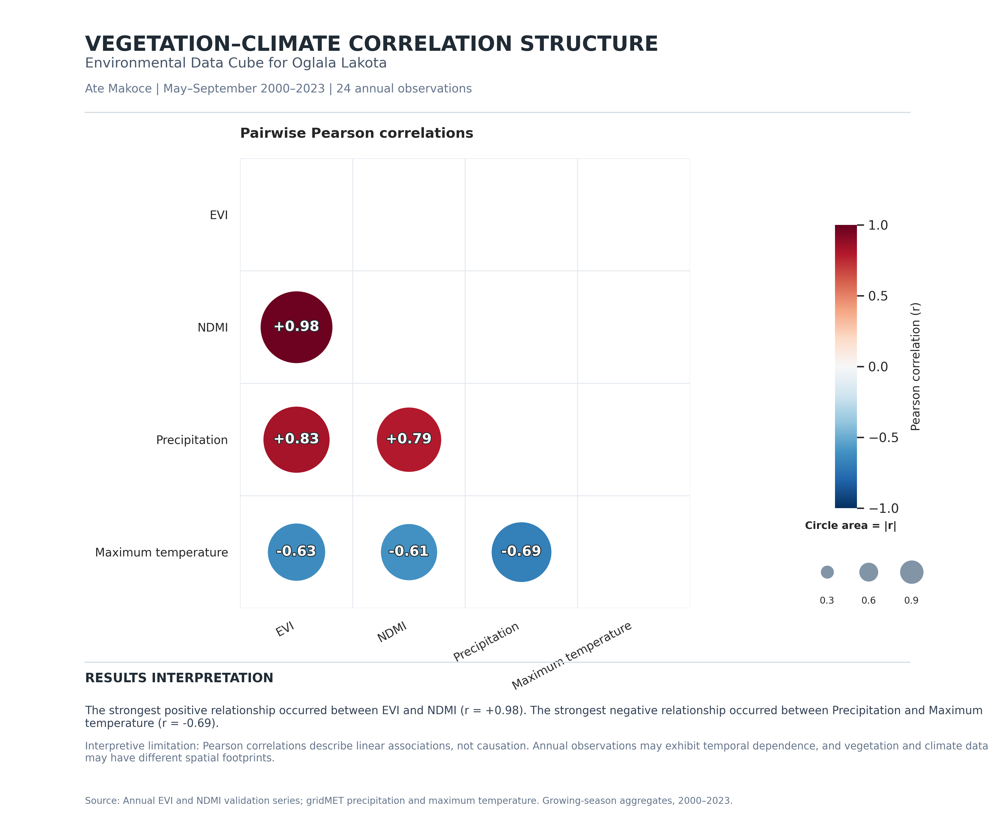


SA 19O — PEARSON CORRELATION BUBBLE MATRIX COMPLETE
Annual observations: 24
Growing seasons: May–September 2000–2023

PEARSON CORRELATIONS


,EVI,NDMI,Precipitation_mm,Mean_Tmax_C
EVI,1.000,0.977,0.834,-0.632
NDMI,0.977,1.000,0.790,-0.609
Precipitation_mm,0.834,0.790,1.000,-0.685
Mean_Tmax_C,-0.632,-0.609,-0.685,1.000



P-VALUES (EXPLORATORY, UNADJUSTED)


,EVI,NDMI,Precipitation_mm,Mean_Tmax_C
EVI,1.0000,0.0000,0.0000,0.0009
NDMI,0.0000,1.0000,0.0000,0.0016
Precipitation_mm,0.0000,0.0000,1.0000,0.0002
Mean_Tmax_C,0.0009,0.0016,0.0002,1.0000



SAVED OUTPUTS
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Assessment_Results/03_Correlation_and_Climate/Ate_Makoce_Pearson_Correlation_Bubble_Matrix_20261016_215852_972157.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Assessment_Results/03_Correlation_and_Climate/Ate_Makoce_Pearson_Correlation_Bubble_Matrix_20261016_215852_972157.pdf
Coefficients: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Assessment_Results/03_Correlation_and_Climate/Ate_Makoce_Pearson_Correlation_Bubble_Matrix_20261016_215852_972157_coefficients.csv
P-values: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Assessment_Results/03_Correlation_and_Climate/Ate_Makoce_Pearson_Correlation_Bubble_Matrix_20261016_2158

In [43]:
# ======================================================================
# SA 19O — PUBLICATION-QUALITY PEARSON CORRELATION BUBBLE MATRIX
#
# Environmental Data Cube for Oglala Lakota
# Ate Makoce | Agricultural Sustainability Assessment
# Growing seasons: May–September, 2000–2023
#
# Actual data:
#   EVI, NDMI, precipitation, maximum temperature
#
# OUTPUTS:
#   - 300 DPI PNG
#   - Vector PDF
#   - Pearson correlation CSV
#   - Pearson p-value CSV
#   - Annual input data CSV
#
# SAFE:
#   - No synthetic data
#   - No changes to existing research data or notebooks
#   - No overwriting previous figures
# ======================================================================

from pathlib import Path
from datetime import datetime
from IPython.display import display, Image as IPyImage
from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import ScalarMappable
from scipy.stats import pearsonr

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

# --------------------------------------------------------------
# 1. PROJECT PATHS
# --------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

CACHE = PROJECT / "data" / "cache"

VEGETATION_FILE = (
    CACHE
    / "dissertation_validation"
    / "sa15b14_ndmi_evi_2000_2023_v1"
    / "ndmi_evi_annual_2000_2023_v1.csv"
)

PRECIP_FILE = (
    CACHE / "gridmet_pr_oglala_lakota_2000_2023.csv"
)

TEMP_FILE = (
    CACHE / "gridmet_tmmx_oglala_lakota_2000_2023.csv"
)

OUTPUT = (
    PROJECT
    / "results"
    / "Ate_Makoce_Dissertation_Assessment_Results"
    / "03_Correlation_and_Climate"
)

for path in [VEGETATION_FILE, PRECIP_FILE, TEMP_FILE]:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required source file not found:\n{path}"
        )

# --------------------------------------------------------------
# 2. LOAD VEGETATION DATA
# --------------------------------------------------------------

veg = pd.read_csv(VEGETATION_FILE)

required_veg = {
    "year",
    "mean_evi",
    "mean_ndmi"
}

if not required_veg.issubset(veg.columns):
    raise ValueError(
        "Unexpected vegetation CSV columns:\n"
        f"{veg.columns.tolist()}"
    )

veg = veg.rename(columns={
    "year": "Year",
    "mean_evi": "EVI",
    "mean_ndmi": "NDMI"
})

veg = veg[["Year", "EVI", "NDMI"]].copy()

veg["Year"] = pd.to_numeric(
    veg["Year"],
    errors="raise"
).astype(int)

if veg["Year"].duplicated().any():
    raise ValueError("Duplicate vegetation years detected.")

# --------------------------------------------------------------
# 3. LOAD CLIMATE DATA
# --------------------------------------------------------------

pr = pd.read_csv(
    PRECIP_FILE,
    parse_dates=["date"]
)

tx = pd.read_csv(
    TEMP_FILE,
    parse_dates=["date"]
)

for df, column in [
    (pr, "pr"),
    (tx, "tmmx")
]:

    if not {"date", column}.issubset(df.columns):
        raise ValueError(
            f"Required date/{column} columns not found."
        )

    if df["date"].isna().any():
        raise ValueError(
            f"Invalid dates in {column} dataset."
        )

    if df["date"].duplicated().any():
        raise ValueError(
            f"Duplicate dates in {column} dataset."
        )

    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

def growing_season(df):

    return df.loc[
        df["date"].dt.year.between(2000, 2023)
        & df["date"].dt.month.between(5, 9)
    ].copy()

pr = growing_season(pr)
tx = growing_season(tx)

# Each May–September growing season has 153 days.

for df, column in [
    (pr, "pr"),
    (tx, "tmmx")
]:

    counts = df.groupby(
        df["date"].dt.year
    )[column].count()

    if (
        len(counts) != 24
        or not counts.eq(153).all()
        or df[column].isna().any()
    ):
        raise ValueError(
            f"Incomplete growing-season observations: {column}"
        )

# Precipitation: growing-season total in mm.
pr_annual = (
    pr.groupby(pr["date"].dt.year)["pr"]
    .sum()
    .rename("Precipitation_mm")
)

# gridMET tmmx is in Kelvin; convert mean to Celsius.
tx_annual = (
    tx.groupby(tx["date"].dt.year)["tmmx"]
    .mean()
    .sub(273.15)
    .rename("Mean_Tmax_C")
)

climate = pd.concat(
    [pr_annual, tx_annual],
    axis=1
)

climate.index.name = "Year"

# --------------------------------------------------------------
# 4. BUILD ANNUAL DATASET
# --------------------------------------------------------------

data = (
    veg.merge(
        climate.reset_index(),
        on="Year",
        how="inner",
        validate="one_to_one"
    )
    .sort_values("Year")
    .reset_index(drop=True)
)

variables = [
    "EVI",
    "NDMI",
    "Precipitation_mm",
    "Mean_Tmax_C"
]

for variable in variables:

    data[variable] = pd.to_numeric(
        data[variable],
        errors="coerce"
    )

if (
    len(data) != 24
    or data["Year"].tolist() != list(range(2000, 2024))
    or not np.isfinite(
        data[variables].to_numpy(dtype=float)
    ).all()
    or (data[variables].std() == 0).any()
):
    raise ValueError(
        "The reconstructed dataset does not match the "
        "expected 24 complete annual observations."
    )

# --------------------------------------------------------------
# 5. CALCULATE PEARSON CORRELATIONS
# --------------------------------------------------------------

corr = data[variables].corr(method="pearson")

pvalues = pd.DataFrame(
    np.ones((4, 4)),
    index=variables,
    columns=variables
)

for i, a in enumerate(variables):

    for j, b in enumerate(variables):

        if i == j:
            continue

        pvalues.loc[a, b] = pearsonr(
            data[a].to_numpy(),
            data[b].to_numpy()
        ).pvalue

labels = [
    "EVI",
    "NDMI",
    "Precipitation",
    "Maximum temperature"
]

# --------------------------------------------------------------
# 6. PUBLICATION FIGURE SETTINGS
# --------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white"
})

fig = plt.figure(
    figsize=(12, 10),
    facecolor="white"
)

# Leave space for title, legend and interpretation.
ax = fig.add_axes([
    0.14,
    0.27,
    0.65,
    0.54
])

fig.text(
    0.085, 0.958,
    "VEGETATION–CLIMATE CORRELATION STRUCTURE",
    fontsize=18,
    fontweight="bold",
    ha="left",
    va="top",
    color="#202B35"
)

fig.text(
    0.085, 0.919,
    "Environmental Data Cube for Oglala Lakota",
    fontsize=12,
    ha="left",
    color="#475569"
)

fig.text(
    0.085, 0.889,
    "Ate Makoce | May–September 2000–2023 | "
    "24 annual observations",
    fontsize=10,
    ha="left",
    color="#64748B"
)

fig.add_artist(
    plt.Line2D(
        [0.085, 0.91],
        [0.865, 0.865],
        transform=fig.transFigure,
        color="#D6DEE5",
        linewidth=1
    )
)

# --------------------------------------------------------------
# 7. DRAW BUBBLE MATRIX
# --------------------------------------------------------------

n = len(variables)

cmap = plt.get_cmap("RdBu_r")

norm = TwoSlopeNorm(
    vmin=-1,
    vcenter=0,
    vmax=1
)

# Show only the lower triangle, excluding diagonal.
# This avoids displaying each pairwise relationship twice.

for i in range(n):

    for j in range(n):

        if i <= j:
            continue

        r = float(corr.iloc[i, j])

        # Area scales with absolute correlation strength.
        area = 4200 * abs(r)

        x = j
        y = i

        ax.scatter(
            x,
            y,
            s=area,
            color=cmap(norm(r)),
            edgecolor="white",
            linewidth=2,
            zorder=3
        )

        # White text with a subtle dark outline for readability.
        label = ax.text(
            x,
            y,
            f"{r:+.2f}",
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color="white",
            zorder=4
        )

        label.set_path_effects([
            pe.withStroke(
                linewidth=1.5,
                foreground="#263238"
            )
        ])

# Light matrix grid.
for edge in np.arange(-0.5, n + 0.5, 1):

    ax.axhline(
        edge,
        color="#E5EAF0",
        linewidth=0.8,
        zorder=0
    )

    ax.axvline(
        edge,
        color="#E5EAF0",
        linewidth=0.8,
        zorder=0
    )

ax.set_xlim(-0.5, n - 0.5)
ax.set_ylim(n - 0.5, -0.5)

ax.set_aspect("equal")

ax.set_xticks(range(n))
ax.set_yticks(range(n))

ax.set_xticklabels(
    labels,
    rotation=28,
    ha="right",
    fontsize=10
)

ax.set_yticklabels(
    labels,
    fontsize=10
)

ax.tick_params(
    axis="both",
    length=0,
    pad=10
)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(
    "Pairwise Pearson correlations",
    loc="left",
    fontweight="bold",
    fontsize=12,
    pad=18
)

# --------------------------------------------------------------
# 8. COLORBAR
# --------------------------------------------------------------

sm = ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cax = fig.add_axes([
    0.835,
    0.39,
    0.022,
    0.34
])

cbar = fig.colorbar(
    sm,
    cax=cax
)

cbar.set_label(
    "Pearson correlation (r)",
    fontsize=10,
    labelpad=10
)

cbar.set_ticks([
    -1,
    -0.5,
    0,
    0.5,
    1
])

cbar.outline.set_visible(False)

# --------------------------------------------------------------
# 9. SIZE LEGEND
# --------------------------------------------------------------

legend_ax = fig.add_axes([
    0.805,
    0.27,
    0.13,
    0.09
])

legend_ax.set_xlim(0, 1)
legend_ax.set_ylim(0, 1)
legend_ax.axis("off")

legend_ax.text(
    0.0,
    1.02,
    "Circle area = |r|",
    fontsize=9,
    fontweight="bold",
    va="bottom"
)

for x, value in [
    (0.17, 0.3),
    (0.49, 0.6),
    (0.82, 0.9)
]:

    legend_ax.scatter(
        x,
        0.48,
        s=500 * value,
        facecolor="#8295A7",
        edgecolor="white",
        linewidth=1
    )

    legend_ax.text(
        x,
        0.06,
        f"{value:.1f}",
        ha="center",
        fontsize=8
    )

# --------------------------------------------------------------
# 10. RESULTS INTERPRETATION
# --------------------------------------------------------------

fig.add_artist(
    plt.Line2D(
        [0.085, 0.91],
        [0.205, 0.205],
        transform=fig.transFigure,
        color="#D6DEE5",
        linewidth=1
    )
)

fig.text(
    0.085,
    0.181,
    "RESULTS INTERPRETATION",
    fontsize=11,
    fontweight="bold",
    color="#202B35"
)

# Identify strongest positive and negative unique pairs.
pairs = []

for i in range(n):
    for j in range(i):
        pairs.append((
            variables[j],
            variables[i],
            float(corr.iloc[i, j])
        ))

positive = max(
    (p for p in pairs if p[2] > 0),
    key=lambda p: p[2],
    default=None
)

negative = min(
    (p for p in pairs if p[2] < 0),
    key=lambda p: p[2],
    default=None
)

if positive is not None and negative is not None:

    pos_a, pos_b, pos_r = positive
    neg_a, neg_b, neg_r = negative

    interpretation = (
        f"The strongest positive relationship occurred between "
        f"{labels[variables.index(pos_a)]} and "
        f"{labels[variables.index(pos_b)]} "
        f"(r = {pos_r:+.2f}). "
        f"The strongest negative relationship occurred between "
        f"{labels[variables.index(neg_a)]} and "
        f"{labels[variables.index(neg_b)]} "
        f"(r = {neg_r:+.2f})."
    )

else:
    interpretation = (
        "Circle size and color summarize the magnitude "
        "and direction of the pairwise correlations."
    )

fig.text(
    0.085,
    0.153,
    interpretation,
    fontsize=9.5,
    color="#334155",
    ha="left",
    va="top",
    wrap=True
)

fig.text(
    0.085,
    0.088,
    "Interpretive limitation: Pearson correlations describe "
    "linear associations, not causation. Annual observations "
    "may exhibit temporal dependence, and vegetation and "
    "climate data may have different spatial footprints.",
    fontsize=8.8,
    color="#64748B",
    ha="left",
    wrap=True
)

fig.text(
    0.085,
    0.035,
    "Source: Annual EVI and NDMI validation series; "
    "gridMET precipitation and maximum temperature. "
    "Growing-season aggregates, 2000–2023.",
    fontsize=8,
    color="#64748B",
    ha="left"
)

# --------------------------------------------------------------
# 11. SAVE OUTPUTS
# --------------------------------------------------------------

OUTPUT.mkdir(
    parents=True,
    exist_ok=True
)

stamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

stem = (
    "Ate_Makoce_Pearson_Correlation_Bubble_Matrix_"
    + stamp
)

png = OUTPUT / f"{stem}.png"
pdf = OUTPUT / f"{stem}.pdf"

corr_csv = OUTPUT / f"{stem}_coefficients.csv"
pvalues_csv = OUTPUT / f"{stem}_pvalues.csv"
data_csv = OUTPUT / f"{stem}_annual_input_data.csv"

fig.savefig(
    png,
    dpi=300,
    facecolor="white"
)

fig.savefig(
    pdf,
    facecolor="white"
)

plt.close(fig)

corr.to_csv(corr_csv)
pvalues.to_csv(pvalues_csv)
data.to_csv(data_csv, index=False)

# --------------------------------------------------------------
# 12. DISPLAY RESULTS
# --------------------------------------------------------------

display(
    IPyImage(
        filename=str(png),
        width=1200
    )
)

print("\n" + "=" * 75)
print("SA 19O — PEARSON CORRELATION BUBBLE MATRIX COMPLETE")
print("=" * 75)

print(f"Annual observations: {len(data)}")
print("Growing seasons: May–September 2000–2023")

print("\nPEARSON CORRELATIONS")
display(corr.round(3))

print("\nP-VALUES (EXPLORATORY, UNADJUSTED)")
display(pvalues.round(4))

print("\nSAVED OUTPUTS")
print("PNG:", png)
print("PDF:", pdf)
print("Coefficients:", corr_csv)
print("P-values:", pvalues_csv)
print("Annual data:", data_csv)

print("\nOriginal research files and notebooks: UNCHANGED")
print("=" * 75)

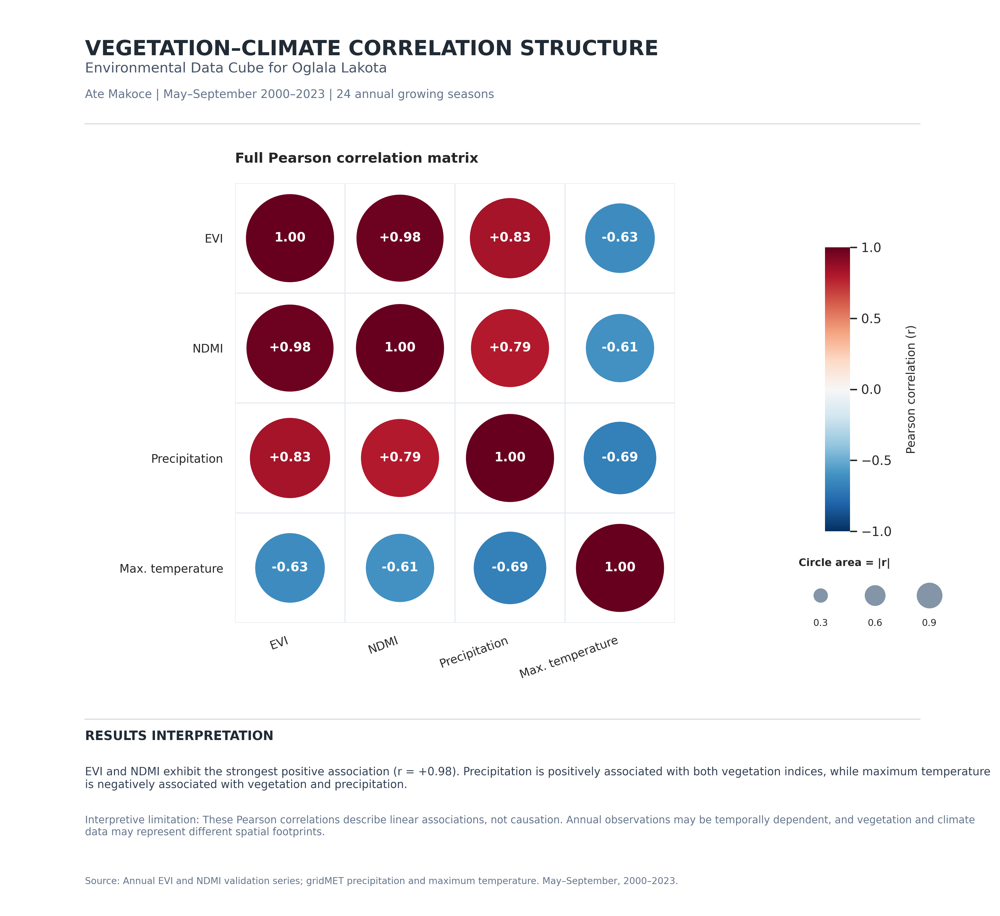


FULL PEARSON CORRELATION BUBBLE MATRIX CREATED
Annual observations: 24
Growing seasons: May–September 2000–2023

PEARSON CORRELATION MATRIX


,EVI,NDMI,Precipitation_mm,Mean_Tmax_C
EVI,1.000,0.977,0.834,-0.632
NDMI,0.977,1.000,0.790,-0.609
Precipitation_mm,0.834,0.790,1.000,-0.685
Mean_Tmax_C,-0.632,-0.609,-0.685,1.000



OUTPUT FILES
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Assessment_Results/03_Correlation_and_Climate/Ate_Makoce_Full_Pearson_Bubble_Matrix_20261016_220117_720548.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Assessment_Results/03_Correlation_and_Climate/Ate_Makoce_Full_Pearson_Bubble_Matrix_20261016_220117_720548.pdf
Correlation CSV: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Assessment_Results/03_Correlation_and_Climate/Ate_Makoce_Full_Pearson_Bubble_Matrix_20261016_220117_720548_coefficients.csv
P-values CSV: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Assessment_Results/03_Correlation_and_Climate/Ate_Makoce_Full_Pearson_Bubble_Matrix_20261016_220117_720548_pvalues.csv


In [44]:
# ======================================================================
# SA 19P — FULL PEARSON CORRELATION BUBBLE MATRIX
# Environmental Data Cube for Oglala Lakota
# Ate Makoce | Agricultural Sustainability Assessment
#
# Full 4 x 4 matrix (all 16 positions)
# Actual observations: May–September 2000–2023
# Source data identical to the previous correlation analysis
#
# Outputs: 300 DPI PNG, vector PDF, correlation CSV
# Original notebooks and datasets remain unchanged.
# ======================================================================

from pathlib import Path
from datetime import datetime
from IPython.display import display, Image as IPyImage

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Circle
from scipy.stats import pearsonr

# --------------------------------------------------------------
# 1. PROJECT AND DATA PATHS
# --------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

CACHE = PROJECT / "data" / "cache"

VEGETATION_FILE = (
    CACHE
    / "dissertation_validation"
    / "sa15b14_ndmi_evi_2000_2023_v1"
    / "ndmi_evi_annual_2000_2023_v1.csv"
)

PRECIP_FILE = (
    CACHE / "gridmet_pr_oglala_lakota_2000_2023.csv"
)

TEMP_FILE = (
    CACHE / "gridmet_tmmx_oglala_lakota_2000_2023.csv"
)

OUTPUT = (
    PROJECT
    / "results"
    / "Ate_Makoce_Dissertation_Assessment_Results"
    / "03_Correlation_and_Climate"
)

for source in [VEGETATION_FILE, PRECIP_FILE, TEMP_FILE]:
    if not source.is_file():
        raise FileNotFoundError(
            f"Required source file missing:\n{source}"
        )

# --------------------------------------------------------------
# 2. LOAD VEGETATION OBSERVATIONS
# --------------------------------------------------------------

veg = pd.read_csv(VEGETATION_FILE)

required = {"year", "mean_evi", "mean_ndmi"}

if not required.issubset(veg.columns):
    raise ValueError(
        f"Unexpected vegetation columns: {veg.columns.tolist()}"
    )

veg = veg.rename(columns={
    "year": "Year",
    "mean_evi": "EVI",
    "mean_ndmi": "NDMI"
})

veg = veg[["Year", "EVI", "NDMI"]].copy()

veg["Year"] = pd.to_numeric(
    veg["Year"], errors="raise"
).astype(int)

if veg["Year"].duplicated().any():
    raise ValueError("Duplicate vegetation years detected.")

# --------------------------------------------------------------
# 3. LOAD AND AGGREGATE CLIMATE
# --------------------------------------------------------------

pr = pd.read_csv(PRECIP_FILE, parse_dates=["date"])
tx = pd.read_csv(TEMP_FILE, parse_dates=["date"])

for df, col in [(pr, "pr"), (tx, "tmmx")]:

    if not {"date", col}.issubset(df.columns):
        raise ValueError(f"Missing date/{col} columns.")

    if df["date"].isna().any():
        raise ValueError(f"Invalid dates in {col}.")

    if df["date"].duplicated().any():
        raise ValueError(f"Duplicate dates in {col}.")

    df[col] = pd.to_numeric(df[col], errors="coerce")

def growing_season(df):
    return df.loc[
        df["date"].dt.year.between(2000, 2023)
        & df["date"].dt.month.between(5, 9)
    ].copy()

pr = growing_season(pr)
tx = growing_season(tx)

for df, col in [(pr, "pr"), (tx, "tmmx")]:

    counts = df.groupby(df["date"].dt.year)[col].count()

    if (
        len(counts) != 24
        or not counts.eq(153).all()
        or df[col].isna().any()
    ):
        raise ValueError(
            f"Incomplete May–September observations for {col}."
        )

pr_annual = (
    pr.groupby(pr["date"].dt.year)["pr"]
    .sum()
    .rename("Precipitation_mm")
)

tx_annual = (
    tx.groupby(tx["date"].dt.year)["tmmx"]
    .mean()
    .sub(273.15)
    .rename("Mean_Tmax_C")
)

climate = pd.concat(
    [pr_annual, tx_annual],
    axis=1
)

climate.index.name = "Year"

# --------------------------------------------------------------
# 4. MERGE ANNUAL OBSERVATIONS
# --------------------------------------------------------------

data = (
    veg.merge(
        climate.reset_index(),
        on="Year",
        how="inner",
        validate="one_to_one"
    )
    .sort_values("Year")
    .reset_index(drop=True)
)

variables = [
    "EVI",
    "NDMI",
    "Precipitation_mm",
    "Mean_Tmax_C"
]

for col in variables:
    data[col] = pd.to_numeric(
        data[col], errors="coerce"
    )

if (
    len(data) != 24
    or data["Year"].tolist() != list(range(2000, 2024))
    or not np.isfinite(data[variables].to_numpy()).all()
    or (data[variables].std() == 0).any()
):
    raise ValueError(
        "Expected 24 complete annual observations, 2000–2023."
    )

# --------------------------------------------------------------
# 5. CALCULATE PEARSON CORRELATIONS
# --------------------------------------------------------------

corr = data[variables].corr(method="pearson")

pvalues = pd.DataFrame(
    np.ones((4, 4)),
    index=variables,
    columns=variables
)

for i, a in enumerate(variables):
    for j, b in enumerate(variables):

        if i != j:
            pvalues.loc[a, b] = pearsonr(
                data[a].to_numpy(),
                data[b].to_numpy()
            ).pvalue

labels = [
    "EVI",
    "NDMI",
    "Precipitation",
    "Max. temperature"
]

# --------------------------------------------------------------
# 6. FIGURE SETTINGS
# --------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white"
})

fig = plt.figure(
    figsize=(12, 11),
    facecolor="white"
)

# Carefully positioned to avoid label/interpretation overlap.
ax = fig.add_axes([
    0.15, 0.32, 0.61, 0.48
])

fig.text(
    0.085, 0.957,
    "VEGETATION–CLIMATE CORRELATION STRUCTURE",
    fontsize=18,
    fontweight="bold",
    color="#202B35",
    va="top"
)

fig.text(
    0.085, 0.921,
    "Environmental Data Cube for Oglala Lakota",
    fontsize=12,
    color="#475569"
)

fig.text(
    0.085, 0.893,
    "Ate Makoce | May–September 2000–2023 | "
    "24 annual growing seasons",
    fontsize=10,
    color="#64748B"
)

fig.add_artist(
    plt.Line2D(
        [0.085, 0.92],
        [0.865, 0.865],
        transform=fig.transFigure,
        color="#D6DEE5",
        linewidth=1
    )
)

# --------------------------------------------------------------
# 7. DRAW FULL 4 x 4 BUBBLE MATRIX
# --------------------------------------------------------------

cmap = plt.get_cmap("RdBu_r")

norm = TwoSlopeNorm(
    vmin=-1,
    vcenter=0,
    vmax=1
)

n = len(variables)

# Circle radius is proportional to sqrt(|r|),
# so the circle AREA is proportional to |r|.
max_radius = 0.41

for i in range(n):

    for j in range(n):

        r = float(corr.iloc[i, j])

        radius = max_radius * np.sqrt(abs(r))

        circle = Circle(
            (j, i),
            radius=radius,
            facecolor=cmap(norm(r)),
            edgecolor="white",
            linewidth=1.8,
            zorder=3
        )

        ax.add_patch(circle)

        # Choose text color for contrast.
        text_color = (
            "white" if abs(r) >= 0.50 else "#1F2937"
        )

        ax.text(
            j,
            i,
            f"{r:+.2f}" if i != j else "1.00",
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold",
            color=text_color,
            zorder=4
        )

# Gridlines between cells.
for edge in np.arange(-0.5, n + 0.5, 1):

    ax.axhline(
        edge,
        color="#E5EAF0",
        linewidth=0.9,
        zorder=0
    )

    ax.axvline(
        edge,
        color="#E5EAF0",
        linewidth=0.9,
        zorder=0
    )

ax.set_xlim(-0.5, n - 0.5)
ax.set_ylim(n - 0.5, -0.5)
ax.set_aspect("equal")

ax.set_xticks(range(n))
ax.set_yticks(range(n))

ax.set_xticklabels(
    labels,
    rotation=20,
    ha="right",
    fontsize=10
)

ax.set_yticklabels(
    labels,
    fontsize=10
)

ax.tick_params(
    axis="both",
    length=0,
    pad=10
)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title(
    "Full Pearson correlation matrix",
    fontsize=12,
    fontweight="bold",
    loc="left",
    pad=18
)

# --------------------------------------------------------------
# 8. COLORBAR
# --------------------------------------------------------------

sm = ScalarMappable(
    cmap=cmap,
    norm=norm
)

sm.set_array([])

cax = fig.add_axes([
    0.825, 0.42, 0.025, 0.31
])

cbar = fig.colorbar(sm, cax=cax)

cbar.set_label(
    "Pearson correlation (r)",
    fontsize=10,
    labelpad=12
)

cbar.set_ticks([-1, -0.5, 0, 0.5, 1])
cbar.outline.set_visible(False)

# --------------------------------------------------------------
# 9. CIRCLE-SIZE LEGEND
# --------------------------------------------------------------

legend_ax = fig.add_axes([
    0.79, 0.31, 0.17, 0.085
])

legend_ax.set_xlim(0, 1)
legend_ax.set_ylim(0, 1)
legend_ax.axis("off")

legend_ax.text(
    0.05, 0.95,
    "Circle area = |r|",
    fontsize=9,
    fontweight="bold",
    va="top"
)

for x, value in [
    (0.18, 0.3),
    (0.50, 0.6),
    (0.82, 0.9)
]:

    legend_ax.scatter(
        x,
        0.47,
        s=600 * value,
        color="#8395A7",
        edgecolor="white",
        linewidth=1
    )

    legend_ax.text(
        x,
        0.08,
        f"{value:.1f}",
        ha="center",
        fontsize=8
    )

# --------------------------------------------------------------
# 10. INTERPRETATION
# --------------------------------------------------------------

fig.add_artist(
    plt.Line2D(
        [0.085, 0.92],
        [0.215, 0.215],
        transform=fig.transFigure,
        color="#D6DEE5",
        linewidth=1
    )
)

fig.text(
    0.085, 0.192,
    "RESULTS INTERPRETATION",
    fontsize=11,
    fontweight="bold",
    color="#202B35"
)

fig.text(
    0.085, 0.163,
    "EVI and NDMI exhibit the strongest positive association "
    f"(r = {corr.loc['EVI', 'NDMI']:+.2f}). "
    "Precipitation is positively associated with both vegetation "
    "indices, while maximum temperature is negatively associated "
    "with vegetation and precipitation.",
    fontsize=9.5,
    color="#334155",
    ha="left",
    va="top",
    wrap=True
)

fig.text(
    0.085, 0.090,
    "Interpretive limitation: These Pearson correlations "
    "describe linear associations, not causation. "
    "Annual observations may be temporally dependent, "
    "and vegetation and climate data may represent "
    "different spatial footprints.",
    fontsize=8.8,
    color="#64748B",
    ha="left",
    wrap=True
)

fig.text(
    0.085, 0.035,
    "Source: Annual EVI and NDMI validation series; "
    "gridMET precipitation and maximum temperature. "
    "May–September, 2000–2023.",
    fontsize=8,
    color="#64748B"
)

# --------------------------------------------------------------
# 11. SAVE NEW OUTPUTS
# --------------------------------------------------------------

OUTPUT.mkdir(parents=True, exist_ok=True)

stamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

stem = (
    "Ate_Makoce_Full_Pearson_Bubble_Matrix_"
    + stamp
)

png = OUTPUT / f"{stem}.png"
pdf = OUTPUT / f"{stem}.pdf"
corr_csv = OUTPUT / f"{stem}_coefficients.csv"
pvalues_csv = OUTPUT / f"{stem}_pvalues.csv"

fig.savefig(
    png,
    dpi=300,
    facecolor="white"
)

fig.savefig(
    pdf,
    facecolor="white"
)

plt.close(fig)

corr.to_csv(corr_csv)
pvalues.to_csv(pvalues_csv)

# --------------------------------------------------------------
# 12. DISPLAY
# --------------------------------------------------------------

display(
    IPyImage(
        filename=str(png),
        width=1200
    )
)

print("\n" + "=" * 72)
print("FULL PEARSON CORRELATION BUBBLE MATRIX CREATED")
print("=" * 72)

print("Annual observations:", len(data))
print("Growing seasons: May–September 2000–2023")

print("\nPEARSON CORRELATION MATRIX")
display(corr.round(3))

print("\nOUTPUT FILES")
print("PNG:", png)
print("PDF:", pdf)
print("Correlation CSV:", corr_csv)
print("P-values CSV:", pvalues_csv)

print("\nOriginal research data and notebooks: UNCHANGED")
print("=" * 72)


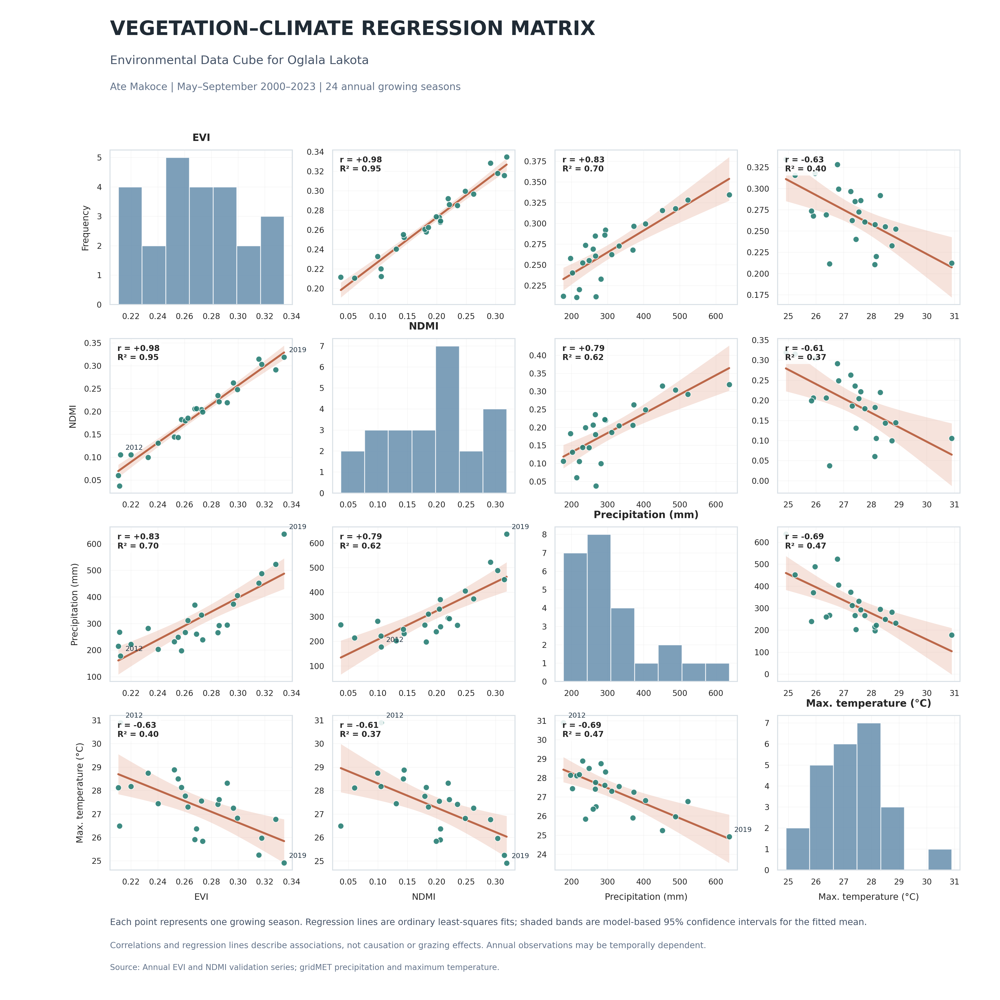


CORRECTED REGRESSION MATRIX COMPLETE
Annual observations: 24
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Assessment_Results/03_Correlation_and_Climate/Ate_Makoce_Regression_Matrix_Corrected_20261016_233859_066203.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Assessment_Results/03_Correlation_and_Climate/Ate_Makoce_Regression_Matrix_Corrected_20261016_233859_066203.pdf
Annual data CSV: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Assessment_Results/03_Correlation_and_Climate/Ate_Makoce_Regression_Matrix_Corrected_20261016_233859_066203_annual_data.csv
Original research files: UNCHANGED


In [62]:
# ======================================================================
# SA 19R.1 — CORRECTED VEGETATION–CLIMATE REGRESSION MATRIX
# Environmental Data Cube for Oglala Lakota
# Ate Makoce | 2000–2023 Growing Seasons
#
# FIX: Plot directly with Matplotlib instead of seaborn.PairGrid.
# Uses actual observations, no synthetic data.
# ======================================================================

from pathlib import Path
from datetime import datetime
from itertools import combinations
from IPython.display import display, Image as IPyImage

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import pearsonr, linregress, t

# --------------------------------------------------------------
# 1. PROJECT PATHS
# --------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

CACHE = PROJECT / "data" / "cache"

VEG_FILE = (
    CACHE
    / "dissertation_validation"
    / "sa15b14_ndmi_evi_2000_2023_v1"
    / "ndmi_evi_annual_2000_2023_v1.csv"
)

PR_FILE = CACHE / "gridmet_pr_oglala_lakota_2000_2023.csv"
TX_FILE = CACHE / "gridmet_tmmx_oglala_lakota_2000_2023.csv"

OUTPUT = (
    PROJECT
    / "results"
    / "Ate_Makoce_Dissertation_Assessment_Results"
    / "03_Correlation_and_Climate"
)

for path in [VEG_FILE, PR_FILE, TX_FILE]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing source file:\n{path}")

# --------------------------------------------------------------
# 2. RECONSTRUCT THE ANNUAL DATASET
# --------------------------------------------------------------

veg = pd.read_csv(VEG_FILE)

veg = veg.rename(columns={
    "year": "Year",
    "mean_evi": "EVI",
    "mean_ndmi": "NDMI"
})

veg = veg[["Year", "EVI", "NDMI"]].copy()

pr = pd.read_csv(PR_FILE, parse_dates=["date"])
tx = pd.read_csv(TX_FILE, parse_dates=["date"])

for df, col in [(pr, "pr"), (tx, "tmmx")]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

    if df["date"].isna().any() or df["date"].duplicated().any():
        raise ValueError(f"Invalid or duplicate dates in {col}.")

    df.drop(
        df.index[
            ~(
                df["date"].dt.year.between(2000, 2023)
                & df["date"].dt.month.between(5, 9)
            )
        ],
        inplace=True
    )

    counts = df.groupby(df["date"].dt.year)[col].count()

    if (
        len(counts) != 24
        or not counts.eq(153).all()
        or df[col].isna().any()
    ):
        raise ValueError(f"Incomplete growing seasons in {col}.")

precip = (
    pr.groupby(pr["date"].dt.year)["pr"]
    .sum()
    .rename("Precipitation_mm")
)

temp = (
    tx.groupby(tx["date"].dt.year)["tmmx"]
    .mean()
    .sub(273.15)
    .rename("Mean_Tmax_C")
)

climate = pd.concat([precip, temp], axis=1)
climate.index.name = "Year"

data = (
    veg.merge(
        climate.reset_index(),
        on="Year",
        validate="one_to_one"
    )
    .sort_values("Year")
    .reset_index(drop=True)
)

variables = [
    "EVI",
    "NDMI",
    "Precipitation_mm",
    "Mean_Tmax_C"
]

data["Year"] = pd.to_numeric(
    data["Year"], errors="raise"
).astype(int)

for col in variables:
    data[col] = pd.to_numeric(data[col], errors="raise")

if (
    len(data) != 24
    or data["Year"].tolist() != list(range(2000, 2024))
    or not np.isfinite(data[variables].to_numpy()).all()
    or (data[variables].std() == 0).any()
):
    raise ValueError("Expected 24 complete annual observations.")

# --------------------------------------------------------------
# 3. FIGURE SETTINGS
# --------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

labels = {
    "EVI": "EVI",
    "NDMI": "NDMI",
    "Precipitation_mm": "Precipitation (mm)",
    "Mean_Tmax_C": "Max. temperature (°C)"
}

colors = {
    "points": "#287F75",
    "line": "#BC684A",
    "band": "#E9B9A8",
    "hist": "#668EAD"
}

n = len(variables)

fig, axes = plt.subplots(
    n,
    n,
    figsize=(14, 14),
    facecolor="white"
)

fig.subplots_adjust(
    left=0.11,
    right=0.96,
    top=0.85,
    bottom=0.13,
    wspace=0.22,
    hspace=0.22
)

# --------------------------------------------------------------
# 4. DRAW SCATTERPLOTS, REGRESSION LINES AND HISTOGRAMS
# --------------------------------------------------------------

for i, yvar in enumerate(variables):

    for j, xvar in enumerate(variables):

        ax = axes[i, j]

        x = data[xvar].to_numpy(dtype=float)
        y = data[yvar].to_numpy(dtype=float)

        if i == j:

            ax.hist(
                x,
                bins=7,
                color=colors["hist"],
                edgecolor="white",
                alpha=0.85
            )

            ax.set_title(
                labels[xvar],
                fontsize=10,
                fontweight="bold",
                pad=9
            )

        else:

            ax.scatter(
                x,
                y,
                s=35,
                color=colors["points"],
                edgecolors="white",
                linewidths=0.6,
                alpha=0.9,
                zorder=3
            )

            result = linregress(x, y)

            xline = np.linspace(
                np.min(x),
                np.max(x),
                150
            )

            yline = result.intercept + result.slope * xline

            # Analytic 95% confidence interval for the
            # fitted mean under ordinary least squares assumptions.
            nobs = len(x)
            xmean = x.mean()
            sxx = np.sum((x - xmean) ** 2)

            residuals = (
                y - (result.intercept + result.slope * x)
            )

            residual_sd = np.sqrt(
                np.sum(residuals ** 2) / (nobs - 2)
            )

            tcrit = t.ppf(0.975, df=nobs - 2)

            se_mean = residual_sd * np.sqrt(
                1 / nobs + (xline - xmean) ** 2 / sxx
            )

            ax.fill_between(
                xline,
                yline - tcrit * se_mean,
                yline + tcrit * se_mean,
                color=colors["band"],
                alpha=0.40,
                linewidth=0,
                zorder=1
            )

            ax.plot(
                xline,
                yline,
                color=colors["line"],
                linewidth=2,
                zorder=2
            )

            r, p = pearsonr(x, y)

            ax.text(
                0.04,
                0.96,
                f"r = {r:+.2f}\nR² = {r**2:.2f}",
                transform=ax.transAxes,
                ha="left",
                va="top",
                fontsize=8,
                fontweight="bold",
                bbox={
                    "facecolor": "white",
                    "edgecolor": "none",
                    "alpha": 0.88,
                    "boxstyle": "round,pad=0.3"
                }
            )

            # Label important growing seasons only in
            # the lower triangle to avoid excessive clutter.
            if i > j:

                for year in [2012, 2019]:

                    row = data.loc[data["Year"] == year]

                    ax.annotate(
                        str(year),
                        (
                            float(row[xvar].iloc[0]),
                            float(row[yvar].iloc[0])
                        ),
                        xytext=(5, 5),
                        textcoords="offset points",
                        fontsize=7,
                        color="#253746"
                    )

        ax.grid(alpha=0.16, linewidth=0.6)
        ax.set_axisbelow(True)
        ax.tick_params(labelsize=8)

        for spine in ax.spines.values():
            spine.set_color("#D9E0E6")

        if i == n - 1:
            ax.set_xlabel(
                labels[xvar],
                fontsize=9,
                labelpad=7
            )
        else:
            ax.set_xlabel("")

        if j == 0:
            ax.set_ylabel(
                labels[yvar] if i != j else "Frequency",
                fontsize=9,
                labelpad=7
            )
        else:
            ax.set_ylabel("")

# --------------------------------------------------------------
# 5. TITLE AND SCIENTIFIC NOTES
# --------------------------------------------------------------

fig.text(
    0.11,
    0.965,
    "VEGETATION–CLIMATE REGRESSION MATRIX",
    fontsize=20,
    fontweight="bold",
    color="#202B35"
)

fig.text(
    0.11,
    0.936,
    "Environmental Data Cube for Oglala Lakota",
    fontsize=12,
    color="#475569"
)

fig.text(
    0.11,
    0.910,
    "Ate Makoce | May–September 2000–2023 | "
    "24 annual growing seasons",
    fontsize=10,
    color="#64748B"
)

fig.text(
    0.11,
    0.075,
    "Each point represents one growing season. "
    "Regression lines are ordinary least-squares fits; "
    "shaded bands are model-based 95% confidence intervals "
    "for the fitted mean.",
    fontsize=9,
    color="#475569"
)

fig.text(
    0.11,
    0.052,
    "Correlations and regression lines describe associations, "
    "not causation or grazing effects. "
    "Annual observations may be temporally dependent.",
    fontsize=8.5,
    color="#64748B"
)

fig.text(
    0.11,
    0.030,
    "Source: Annual EVI and NDMI validation series; "
    "gridMET precipitation and maximum temperature.",
    fontsize=8,
    color="#64748B"
)

# --------------------------------------------------------------
# 6. SAVE AND DISPLAY
# --------------------------------------------------------------

OUTPUT.mkdir(parents=True, exist_ok=True)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

stem = f"Ate_Makoce_Regression_Matrix_Corrected_{stamp}"

png = OUTPUT / f"{stem}.png"
pdf = OUTPUT / f"{stem}.pdf"
data_csv = OUTPUT / f"{stem}_annual_data.csv"

fig.savefig(png, dpi=300, facecolor="white")
fig.savefig(pdf, facecolor="white")

plt.close(fig)

data.to_csv(data_csv, index=False)

display(IPyImage(filename=str(png), width=1350))

print("\n" + "=" * 72)
print("CORRECTED REGRESSION MATRIX COMPLETE")
print("=" * 72)
print("Annual observations:", len(data))
print("PNG:", png)
print("PDF:", pdf)
print("Annual data CSV:", data_csv)
print("Original research files: UNCHANGED")
print("=" * 72)

**Figure X. Vegetation–climate relationships across the Ate Makoce agricultural sustainability assessment, 2000–2023.** Pairwise scatterplots illustrate associations among annual growing-season Enhanced Vegetation Index (EVI), Normalized Difference Moisture Index (NDMI), cumulative precipitation, and mean daily maximum temperature. Each observation represents one May–September growing season (n = 24). Solid lines indicate ordinary least-squares regression fits, and shaded regions represent model-based 95% confidence intervals for the fitted mean relationship. Pearson correlation coefficients (r) and coefficients of determination (R²) are displayed within each scatterplot. Diagonal histograms illustrate the distributions of individual environmental variables. The 2012 and 2019 growing seasons are annotated to highlight contrasting environmental conditions. Relationships are descriptive and do not independently establish causation or grazing-related impacts.

In [47]:
# ======================================================================
# SA 19S — COLLECT ALL DISSERTATION FIGURES INTO ONE MASTER FOLDER
# Environmental Data Cube for Oglala Lakota
#
# Scans the project's results folder and saved notebook outputs.
# Copies figures only; does not move, delete or overwrite originals.
# Creates a master inventory CSV.
# ======================================================================

from pathlib import Path
from datetime import datetime
from collections import Counter
from IPython.display import display
import pandas as pd
import hashlib
import shutil
import base64
import re

# --------------------------------------------------------------
# 1. PROJECT PATHS
# --------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

RESULTS = PROJECT / "results"

DEST = RESULTS / "Ate_Makoce_Dissertation_Figures"

if not RESULTS.is_dir():
    raise FileNotFoundError(f"Results folder not found: {RESULTS}")

DEST.mkdir(parents=True, exist_ok=True)

FIGURE_EXTENSIONS = {
    ".png", ".jpg", ".jpeg",
    ".pdf", ".svg", ".tif", ".tiff",
    ".webp"
}

# --------------------------------------------------------------
# 2. UTILITIES
# --------------------------------------------------------------

def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def clean_name(value):
    return re.sub(r"[^A-Za-z0-9._-]+", "_", str(value))

# Keep track of identical file content, regardless of filename.
seen = {}
inventory = []
errors = []

copied = 0
skipped = 0

def add_figure(source_description, original_name, content,
               extension, source_path=None):

    global copied, skipped

    digest = hashlib.sha256(content).hexdigest()

    # Deduplicate identical figures of the same file type.
    identity = (digest, extension.lower())

    if identity in seen:
        skipped += 1
        inventory.append({
            "Original_Filename": original_name,
            "Original_Source": source_description,
            "Master_Copy": str(seen[identity]),
            "Format": extension.lower(),
            "SHA256": digest,
            "Status": "Duplicate content"
        })
        return

    # Prefix with the original folder to avoid filename collisions.
    if source_path is not None:
        relative = source_path.relative_to(RESULTS)
        prefix = clean_name("__".join(relative.parts[:-1]))
        filename = (
            f"{prefix}__{original_name}"
            if prefix else original_name
        )
    else:
        filename = original_name

    target = DEST / filename

    # Never overwrite existing content.
    if target.exists():
        if sha256(target) == digest:
            status = "Already present"
            skipped += 1
        else:
            target = DEST / (
                f"{Path(filename).stem}__{digest[:12]}"
                f"{extension}"
            )
            if target.exists():
                if sha256(target) == digest:
                    status = "Already present"
                    skipped += 1
                else:
                    raise RuntimeError(
                        f"Unresolved filename collision: {target}"
                    )
            else:
                target.write_bytes(content)
                copied += 1
                status = "Copied"
    else:
        target.write_bytes(content)
        copied += 1
        status = "Copied"

    seen[identity] = target

    inventory.append({
        "Original_Filename": original_name,
        "Original_Source": source_description,
        "Master_Copy": str(target),
        "Format": extension.lower(),
        "SHA256": digest,
        "Status": status
    })

# --------------------------------------------------------------
# 3. COLLECT EXISTING SAVED FIGURES
# --------------------------------------------------------------

files = sorted(
    path for path in RESULTS.rglob("*")
    if path.is_file()
    and not path.is_relative_to(DEST)
    and path.suffix.lower() in FIGURE_EXTENSIONS
)

for source in files:

    try:
        add_figure(
            source_description=str(source),
            original_name=source.name,
            content=source.read_bytes(),
            extension=source.suffix,
            source_path=source
        )

    except Exception as exc:
        errors.append((str(source), str(exc)))

# --------------------------------------------------------------
# 4. RECOVER SAVED FIGURES FROM NOTEBOOK 09 AND NOTEBOOK 11
# --------------------------------------------------------------

NOTEBOOKS = [
    PROJECT / "Notebooks" / "09_dissertation_data_cube_validation.ipynb",
    PROJECT / "Notebooks" / "11_dissertation_figures_stats_results_gallery.ipynb"
]

try:
    import nbformat

    for notebook_path in NOTEBOOKS:

        if not notebook_path.is_file():
            errors.append((
                str(notebook_path),
                "Notebook not found"
            ))
            continue

        notebook = nbformat.read(
            notebook_path,
            as_version=4
        )

        for cell_index, cell in enumerate(notebook.cells, start=1):

            if cell.cell_type != "code":
                continue

            for output_index, output in enumerate(
                cell.get("outputs", []),
                start=1
            ):

                output_data = output.get("data", {})

                if "image/png" not in output_data:
                    continue

                encoded = output_data["image/png"]

                if isinstance(encoded, list):
                    encoded = "".join(encoded)

                try:
                    image_bytes = base64.b64decode(encoded)

                    filename = (
                        f"{notebook_path.stem}"
                        f"__cell_{cell_index:03d}"
                        f"__output_{output_index:02d}.png"
                    )

                    add_figure(
                        source_description=(
                            f"{notebook_path} | "
                            f"Cell {cell_index}, "
                            f"Output {output_index}"
                        ),
                        original_name=filename,
                        content=image_bytes,
                        extension=".png"
                    )

                except Exception as exc:
                    errors.append((
                        f"{notebook_path.name} cell {cell_index}",
                        str(exc)
                    ))

except ImportError:
    errors.append((
        "Notebook extraction",
        "nbformat is not installed"
    ))

# --------------------------------------------------------------
# 5. MASTER INVENTORY
# --------------------------------------------------------------

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

inventory_df = pd.DataFrame(inventory)

inventory_path = (
    DEST / f"Dissertation_Figure_Inventory_{stamp}.csv"
)

inventory_df.to_csv(inventory_path, index=False)

summary_path = DEST / f"Figure_Collection_Summary_{stamp}.txt"

with open(summary_path, "w", encoding="utf-8") as file:

    file.write(
        "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA\n"
        "ATE MAKOCE — DISSERTATION FIGURE COLLECTION\n"
        + "=" * 65 + "\n\n"
    )

    file.write(f"Destination: {DEST}\n")
    file.write(f"Collection date: {stamp}\n\n")

    file.write(f"New figures copied: {copied}\n")
    file.write(f"Duplicates or existing: {skipped}\n")
    file.write(f"Total records: {len(inventory)}\n")
    file.write(f"Errors: {len(errors)}\n\n")

    file.write(
        "Original notebooks and research files "
        "were not modified.\n"
    )

    if errors:
        file.write("\nERRORS\n")
        for source, error in errors:
            file.write(f"{source}: {error}\n")

# --------------------------------------------------------------
# 6. DISPLAY COLLECTION SUMMARY
# --------------------------------------------------------------

print("\n" + "=" * 75)
print("DISSERTATION FIGURE COLLECTION COMPLETE")
print("=" * 75)

print("\nMaster folder:")
print(DEST)

print(f"\nNew figures copied: {copied}")
print(f"Duplicates or already present: {skipped}")
print(f"Total inventory records: {len(inventory)}")
print(f"Errors: {len(errors)}")

print("\nMaster inventory:")
print(inventory_path)

print("\nCollection summary:")
print(summary_path)

print("\nOriginal research files and notebooks: UNCHANGED")
print("=" * 75)

if errors:
    print("\nItems requiring review:")
    for source, error in errors[:15]:
        print("-", source, ":", error)

if not inventory_df.empty:
    display(
        inventory_df[
            ["Original_Filename", "Format", "Status"]
        ].head(40)
    )


DISSERTATION FIGURE COLLECTION COMPLETE

Master folder:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Figures

New figures copied: 181
Duplicates or already present: 3
Total inventory records: 184
Errors: 0

Master inventory:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Figures/Dissertation_Figure_Inventory_20261016_221806_894039.csv

Collection summary:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Figures/Figure_Collection_Summary_20261016_221806_894039.txt

Original research files and notebooks: UNCHANGED


,Original_Filename,Format,Status
0,Ate_Makoce_Correlation_20261016_215504_526560.pdf,.pdf,Copied
1,Ate_Makoce_Correlation_20261016_215504_526560.png,.png,Copied
2,Ate_Makoce_Correlation_20261016_215702_194539.pdf,.pdf,Copied
3,Ate_Makoce_Correlation_20261016_215702_194539.png,.png,Duplicate content
4,Ate_Makoce_Correlation_20261016_215732_078388.pdf,.pdf,Copied
5,Ate_Makoce_Correlation_20261016_215732_078388.png,.png,Duplicate content
6,Ate_Makoce_Full_Pearson_Bubble_Matrix_20261016...,.pdf,Copied
7,Ate_Makoce_Full_Pearson_Bubble_Matrix_20261016...,.png,Copied
8,Ate_Makoce_Pearson_Correlation_Bubble_Matrix_2...,.pdf,Copied
9,Ate_Makoce_Pearson_Correlation_Bubble_Matrix_2...,.png,Copied


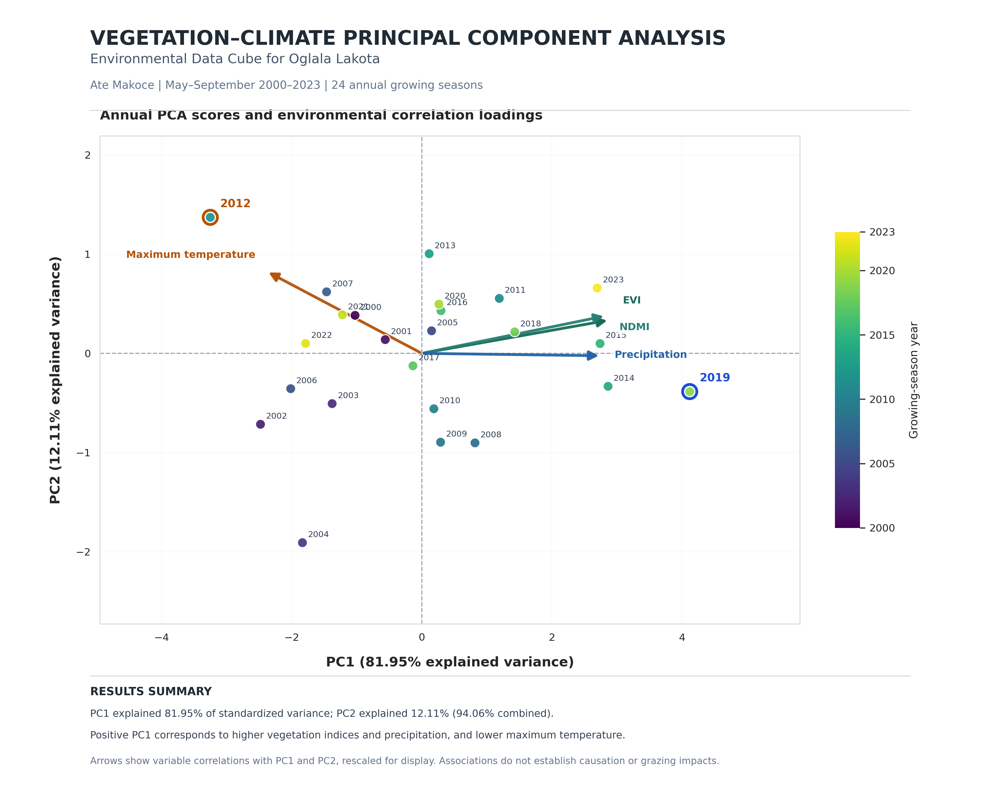


SA 19T — PCA BIPLOT COMPLETE
Annual observations: 24
Growing seasons: May–September 2000–2023

EXPLAINED VARIANCE


,Component,Explained_variance_percent,Cumulative_percent
0,PC1,81.948,81.948
1,PC2,12.112,94.060
2,PC3,5.436,99.496
3,PC4,0.504,100.000



CORRELATION LOADINGS


,PC1,PC2,PC3,PC4
EVI,0.960,0.241,-0.100,0.106
NDMI,0.942,0.272,-0.175,-0.094
Precipitation_mm,0.917,-0.017,0.399,-0.014
Mean_Tmax_C,-0.794,0.594,0.132,-0.000



SAVED FILES
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Figures/Ate_Makoce_PCA_Biplot_20261016_222257_919598.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Figures/Ate_Makoce_PCA_Biplot_20261016_222257_919598.pdf
Scores: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Figures/Ate_Makoce_PCA_Biplot_20261016_222257_919598_scores.csv
Loadings: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Figures/Ate_Makoce_PCA_Biplot_20261016_222257_919598_loadings.csv
Variance: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Figures/Ate_Makoce_PCA_Biplot_20261016_222257_919598_variance.csv
Annual input data: /Users/elishawakinya

In [48]:
# ======================================================================
# SA 19T — PUBLICATION-QUALITY PCA BIPLOT
# Environmental Data Cube for Oglala Lakota
# Ate Makoce | Agricultural Sustainability Assessment
#
# PCA biplot:
#   - PC1 versus PC2 annual scores
#   - Correlation loading arrows for environmental variables
#   - Chronological color gradient (2000–2023)
#   - Highlighted years: 2012 and 2019
#
# Data: May–September growing seasons, 2000–2023
# Saves: PNG (300 dpi), PDF, PCA scores/loadings/variance CSVs
#
# Does not overwrite or modify original research data or notebooks.
# ======================================================================

from pathlib import Path
from datetime import datetime
from IPython.display import display, Image as IPyImage

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import FancyArrowPatch
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ----------------------------------------------------------------------
# 1. PROJECT PATHS
# ----------------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

CACHE = PROJECT / "data" / "cache"

VEG_FILE = (
    CACHE
    / "dissertation_validation"
    / "sa15b14_ndmi_evi_2000_2023_v1"
    / "ndmi_evi_annual_2000_2023_v1.csv"
)

PR_FILE = CACHE / "gridmet_pr_oglala_lakota_2000_2023.csv"
TX_FILE = CACHE / "gridmet_tmmx_oglala_lakota_2000_2023.csv"

OUTPUT = (
    PROJECT
    / "results"
    / "Ate_Makoce_Dissertation_Figures"
)

for path in [VEG_FILE, PR_FILE, TX_FILE]:
    if not path.is_file():
        raise FileNotFoundError(
            f"Required source file not found:\n{path}"
        )

# ----------------------------------------------------------------------
# 2. RECONSTRUCT ANNUAL VEGETATION–CLIMATE DATA
# ----------------------------------------------------------------------

veg = pd.read_csv(VEG_FILE)

required = {"year", "mean_evi", "mean_ndmi"}

if not required.issubset(veg.columns):
    raise ValueError(
        f"Unexpected vegetation columns: {veg.columns.tolist()}"
    )

veg = veg.rename(columns={
    "year": "Year",
    "mean_evi": "EVI",
    "mean_ndmi": "NDMI"
})

veg = veg[["Year", "EVI", "NDMI"]].copy()

pr = pd.read_csv(PR_FILE, parse_dates=["date"])
tx = pd.read_csv(TX_FILE, parse_dates=["date"])

for df, col in [(pr, "pr"), (tx, "tmmx")]:

    if not {"date", col}.issubset(df.columns):
        raise ValueError(f"Missing date/{col} columns.")

    if df["date"].isna().any():
        raise ValueError(f"Invalid dates in {col}.")

    if df["date"].duplicated().any():
        raise ValueError(f"Duplicate dates in {col}.")

    df[col] = pd.to_numeric(df[col], errors="coerce")

    keep = (
        df["date"].dt.year.between(2000, 2023)
        & df["date"].dt.month.between(5, 9)
    )

    df.drop(df.index[~keep], inplace=True)

    counts = df.groupby(
        df["date"].dt.year
    )[col].count()

    if (
        len(counts) != 24
        or not counts.eq(153).all()
        or df[col].isna().any()
    ):
        raise ValueError(
            f"Incomplete growing-season observations: {col}"
        )

precip = (
    pr.groupby(pr["date"].dt.year)["pr"]
    .sum()
    .rename("Precipitation_mm")
)

temp = (
    tx.groupby(tx["date"].dt.year)["tmmx"]
    .mean()
    .sub(273.15)
    .rename("Mean_Tmax_C")
)

climate = pd.concat([precip, temp], axis=1)
climate.index.name = "Year"

data = (
    veg.merge(
        climate.reset_index(),
        on="Year",
        how="inner",
        validate="one_to_one"
    )
    .sort_values("Year")
    .reset_index(drop=True)
)

variables = [
    "EVI",
    "NDMI",
    "Precipitation_mm",
    "Mean_Tmax_C"
]

data["Year"] = pd.to_numeric(
    data["Year"], errors="raise"
).astype(int)

for col in variables:
    data[col] = pd.to_numeric(data[col], errors="raise")

if (
    len(data) != 24
    or data["Year"].tolist() != list(range(2000, 2024))
    or not np.isfinite(data[variables].to_numpy()).all()
    or (data[variables].std() == 0).any()
):
    raise ValueError(
        "Expected 24 complete annual observations from 2000–2023."
    )

# ----------------------------------------------------------------------
# 3. STANDARDIZE AND CALCULATE PCA
# ----------------------------------------------------------------------

X = data[variables].to_numpy(dtype=float)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=4)
scores = pca.fit_transform(X_scaled)

variance = pca.explained_variance_ratio_ * 100

# Correlation loadings: correlations between each original
# standardized variable and the component scores.
#
# sklearn explained_variance_ uses n-1 in the denominator;
# StandardScaler uses n. The following gives exact sample
# correlations for the PCA score vectors.

loadings = (
    pca.components_.T
    * np.sqrt(pca.explained_variance_)
    / np.std(X_scaled, axis=0, ddof=1)[:, None]
)

score_df = pd.DataFrame(
    scores,
    columns=["PC1", "PC2", "PC3", "PC4"]
)

score_df.insert(0, "Year", data["Year"].to_numpy())

loading_df = pd.DataFrame(
    loadings,
    index=variables,
    columns=["PC1", "PC2", "PC3", "PC4"]
)

variance_df = pd.DataFrame({
    "Component": ["PC1", "PC2", "PC3", "PC4"],
    "Explained_variance_percent": variance,
    "Cumulative_percent": np.cumsum(variance)
})

# Fix arbitrary PCA axis signs for consistent interpretation:
# PC1 should point toward greener/moister conditions.
if loading_df.loc["EVI", "PC1"] < 0:
    scores[:, 0] *= -1
    loadings[:, 0] *= -1

# PC2 should point toward higher maximum temperature.
if loadings[variables.index("Mean_Tmax_C"), 1] < 0:
    scores[:, 1] *= -1
    loadings[:, 1] *= -1

score_df[["PC1", "PC2", "PC3", "PC4"]] = scores
loading_df.loc[:, ["PC1", "PC2", "PC3", "PC4"]] = loadings

# ----------------------------------------------------------------------
# 4. PUBLICATION FIGURE SETTINGS
# ----------------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white"
})

fig = plt.figure(
    figsize=(12.5, 10),
    facecolor="white"
)

ax = fig.add_axes([0.10, 0.22, 0.70, 0.61])

fig.text(
    0.09, 0.963,
    "VEGETATION–CLIMATE PRINCIPAL COMPONENT ANALYSIS",
    fontsize=18,
    fontweight="bold",
    color="#202B35",
    va="top"
)

fig.text(
    0.09, 0.921,
    "Environmental Data Cube for Oglala Lakota",
    fontsize=12,
    color="#475569"
)

fig.text(
    0.09, 0.889,
    "Ate Makoce | May–September 2000–2023 | "
    "24 annual growing seasons",
    fontsize=10,
    color="#64748B"
)

fig.add_artist(
    plt.Line2D(
        [0.09, 0.91],
        [0.862, 0.862],
        transform=fig.transFigure,
        color="#D6DEE5",
        linewidth=1
    )
)

# ----------------------------------------------------------------------
# 5. ANNUAL PCA SCORES
# ----------------------------------------------------------------------

years = data["Year"].to_numpy()

cmap = plt.get_cmap("viridis")
norm = Normalize(vmin=2000, vmax=2023)

ax.scatter(
    scores[:, 0],
    scores[:, 1],
    c=years,
    cmap=cmap,
    norm=norm,
    s=78,
    alpha=0.93,
    edgecolor="white",
    linewidth=0.9,
    zorder=4
)

ax.axhline(0, color="#94A3B8", lw=1, ls="--", zorder=0)
ax.axvline(0, color="#94A3B8", lw=1, ls="--", zorder=0)

# Label all annual observations with modest offsets.
for i, year in enumerate(years):

    dx, dy = 5, 5

    if year in [2012, 2019]:
        continue

    ax.annotate(
        str(year),
        (scores[i, 0], scores[i, 1]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=7.5,
        color="#334155",
        zorder=5
    )

# Highlight the contrasting growing seasons.
for year, outline in [
    (2012, "#B45309"),
    (2019, "#1D4ED8")
]:

    idx = np.where(years == year)[0][0]

    ax.scatter(
        scores[idx, 0],
        scores[idx, 1],
        s=165,
        facecolors="none",
        edgecolors=outline,
        linewidths=2.5,
        zorder=6
    )

    ax.annotate(
        str(year),
        (scores[idx, 0], scores[idx, 1]),
        xytext=(9, 9),
        textcoords="offset points",
        fontsize=10,
        fontweight="bold",
        color=outline,
        zorder=7
    )

# ----------------------------------------------------------------------
# 6. PCA LOADING ARROWS
# ----------------------------------------------------------------------

# PCA scores and variable correlations are on different scales.
# Scale the correlation arrows into the score-coordinate space.
# Their directions and relative lengths are preserved.
#
# This is a correlation-loading overlay, not a common-unit
# scaling of scores and loadings.

score_x_extent = np.max(np.abs(scores[:, 0]))
score_y_extent = np.max(np.abs(scores[:, 1]))

arrow_scale_x = score_x_extent * 0.73
arrow_scale_y = score_y_extent * 0.73

arrow_colors = {
    "EVI": "#176B55",
    "NDMI": "#287F75",
    "Precipitation_mm": "#2563A6",
    "Mean_Tmax_C": "#B45309"
}

arrow_labels = {
    "EVI": "EVI",
    "NDMI": "NDMI",
    "Precipitation_mm": "Precipitation",
    "Mean_Tmax_C": "Maximum temperature"
}

# Use distinct label offsets so overlapping EVI/NDMI
# loadings remain readable.
label_offsets = {
    "EVI": (12, 15),
    "NDMI": (12, -13),
    "Precipitation_mm": (12, -2),
    "Mean_Tmax_C": (-10, 12)
}

for k, variable in enumerate(variables):

    x_end = loadings[k, 0] * arrow_scale_x
    y_end = loadings[k, 1] * arrow_scale_y

    color = arrow_colors[variable]

    arrow = FancyArrowPatch(
        (0, 0),
        (x_end, y_end),
        arrowstyle="-|>",
        mutation_scale=17,
        linewidth=2.5,
        color=color,
        alpha=0.95,
        zorder=3
    )

    ax.add_patch(arrow)

    dx, dy = label_offsets[variable]

    ax.annotate(
        arrow_labels[variable],
        (x_end, y_end),
        xytext=(dx, dy),
        textcoords="offset points",
        ha="left" if dx > 0 else "right",
        fontsize=9,
        fontweight="bold",
        color=color,
        bbox={
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.85,
            "pad": 1.5
        },
        zorder=8
    )

# ----------------------------------------------------------------------
# 7. AXES AND COLORBAR
# ----------------------------------------------------------------------

ax.set_xlabel(
    f"PC1 ({variance[0]:.2f}% explained variance)",
    fontsize=12,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    f"PC2 ({variance[1]:.2f}% explained variance)",
    fontsize=12,
    fontweight="bold",
    labelpad=12
)

ax.set_title(
    "Annual PCA scores and environmental correlation loadings",
    loc="left",
    fontsize=12,
    fontweight="bold",
    pad=15
)

ax.grid(alpha=0.14, linewidth=0.7)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_color("#D9E0E6")

# Ensure arrow labels and observations fit.
ax.margins(x=0.23, y=0.25)

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cax = fig.add_axes([0.835, 0.34, 0.025, 0.37])

cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("Growing-season year", fontsize=10, labelpad=12)
cbar.set_ticks([2000, 2005, 2010, 2015, 2020, 2023])
cbar.outline.set_visible(False)

# ----------------------------------------------------------------------
# 8. RESULTS INTERPRETATION
# ----------------------------------------------------------------------

fig.add_artist(
    plt.Line2D(
        [0.09, 0.91],
        [0.155, 0.155],
        transform=fig.transFigure,
        color="#D6DEE5",
        linewidth=1
    )
)

fig.text(
    0.09, 0.131,
    "RESULTS SUMMARY",
    fontsize=10,
    fontweight="bold",
    color="#202B35"
)

fig.text(
    0.09, 0.104,
    f"PC1 explained {variance[0]:.2f}% of standardized variance; "
    f"PC2 explained {variance[1]:.2f}% "
    f"({variance[:2].sum():.2f}% combined).",
    fontsize=9,
    color="#334155"
)

fig.text(
    0.09, 0.077,
    "Positive PC1 corresponds to higher vegetation indices and "
    "precipitation, and lower maximum temperature.",
    fontsize=9,
    color="#334155"
)

fig.text(
    0.09, 0.045,
    "Arrows show variable correlations with PC1 and PC2, "
    "rescaled for display. Associations do not establish "
    "causation or grazing impacts.",
    fontsize=8.5,
    color="#64748B"
)

# ----------------------------------------------------------------------
# 9. SAVE FIGURE AND STATISTICAL OUTPUTS
# ----------------------------------------------------------------------

OUTPUT.mkdir(parents=True, exist_ok=True)

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

stem = f"Ate_Makoce_PCA_Biplot_{stamp}"

png = OUTPUT / f"{stem}.png"
pdf = OUTPUT / f"{stem}.pdf"

scores_csv = OUTPUT / f"{stem}_scores.csv"
loadings_csv = OUTPUT / f"{stem}_loadings.csv"
variance_csv = OUTPUT / f"{stem}_variance.csv"
input_csv = OUTPUT / f"{stem}_annual_input_data.csv"

fig.savefig(png, dpi=300, facecolor="white")
fig.savefig(pdf, facecolor="white")

plt.close(fig)

score_df.to_csv(scores_csv, index=False)
loading_df.to_csv(loadings_csv)
variance_df.to_csv(variance_csv, index=False)
data.to_csv(input_csv, index=False)

# ----------------------------------------------------------------------
# 10. DISPLAY RESULTS
# ----------------------------------------------------------------------

display(IPyImage(filename=str(png), width=1250))

print("\n" + "=" * 75)
print("SA 19T — PCA BIPLOT COMPLETE")
print("=" * 75)

print(f"Annual observations: {len(data)}")
print("Growing seasons: May–September 2000–2023")

print("\nEXPLAINED VARIANCE")
display(variance_df.round(3))

print("\nCORRELATION LOADINGS")
display(loading_df.round(3))

print("\nSAVED FILES")
print("PNG:", png)
print("PDF:", pdf)
print("Scores:", scores_csv)
print("Loadings:", loadings_csv)
print("Variance:", variance_csv)
print("Annual input data:", input_csv)

print("\nOriginal research files and notebooks: UNCHANGED")
print("=" * 75)

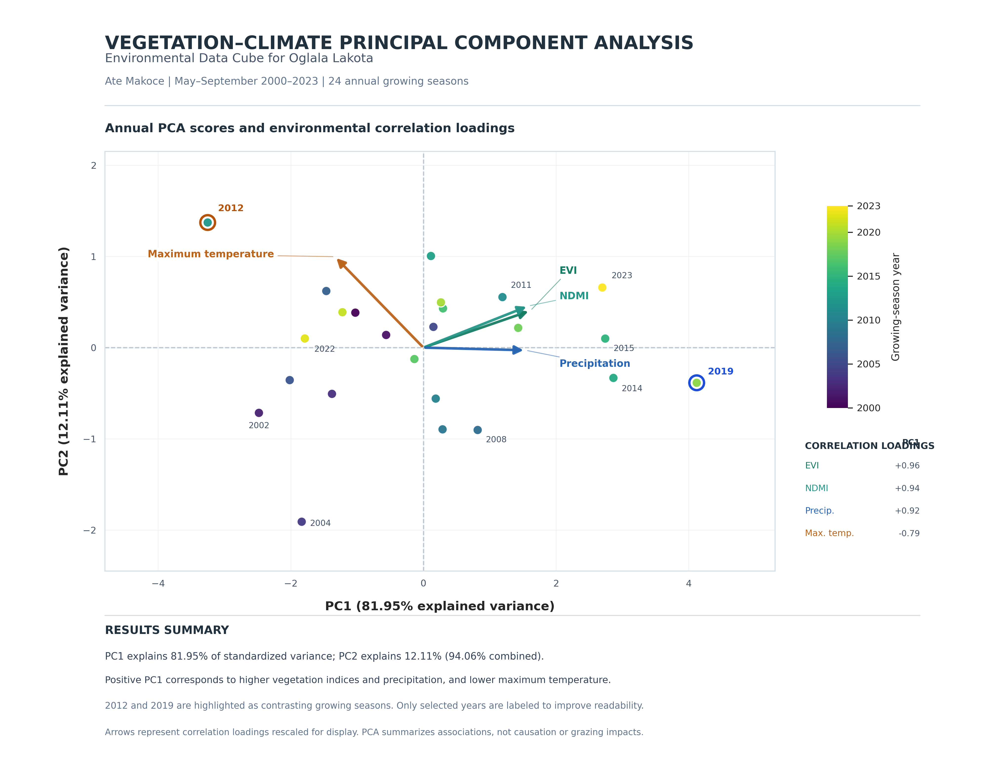


CLEANED PCA BIPLOT COMPLETE
PC1 explained variance: 81.95%
PC2 explained variance: 12.11%
Combined: 94.06%

SOURCE FILES
Scores: Ate_Makoce_PCA_Biplot_20261016_222257_919598_scores.csv
Loadings: Ate_Makoce_PCA_Biplot_20261016_222257_919598_loadings.csv
Variance: Ate_Makoce_PCA_Biplot_20261016_222257_919598_variance.csv

NEW FIGURES
PNG: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Figures/Ate_Makoce_PCA_Biplot_Cleaned_20261016_222420_567356.png
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Figures/Ate_Makoce_PCA_Biplot_Cleaned_20261016_222420_567356.pdf

Original PCA outputs and notebooks: UNCHANGED


In [49]:
# ======================================================================
# SA 19T.1 — CLEANED DISSERTATION PCA BIPLOT
# Environmental Data Cube for Oglala Lakota
# Ate Makoce | May–September 2000–2023
#
# Reads existing SA 19T PCA results.
# Does NOT rerun PCA or modify original files.
# Saves a new publication-quality PNG and vector PDF.
# ======================================================================

from pathlib import Path
from datetime import datetime
from IPython.display import display, Image as IPyImage

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D

# --------------------------------------------------------------
# 1. LOCATE SAVED PCA RESULTS
# --------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

OUTPUT = (
    PROJECT
    / "results"
    / "Ate_Makoce_Dissertation_Figures"
)

if not OUTPUT.is_dir():
    raise FileNotFoundError(
        f"Dissertation figure folder not found:\n{OUTPUT}"
    )

# Find the most recent COMPLETE original SA 19T PCA output set.
sets = []

for score_file in OUTPUT.glob(
    "Ate_Makoce_PCA_Biplot_*_scores.csv"
):
    stem = score_file.name.removesuffix("_scores.csv")

    loading_file = OUTPUT / f"{stem}_loadings.csv"
    variance_file = OUTPUT / f"{stem}_variance.csv"

    if loading_file.is_file() and variance_file.is_file():
        sets.append((
            score_file.stat().st_mtime,
            score_file,
            loading_file,
            variance_file
        ))

if not sets:
    raise FileNotFoundError(
        "No complete SA 19T PCA output set was found in:\n"
        f"{OUTPUT}\n\n"
        "Run the original successful SA 19T PCA biplot cell "
        "once to save its scores, loadings, and variance CSVs."
    )

_, score_file, loading_file, variance_file = max(
    sets, key=lambda item: item[0]
)

scores_df = pd.read_csv(score_file)
loadings_df = pd.read_csv(loading_file, index_col=0)
variance_df = pd.read_csv(variance_file)

variables = [
    "EVI",
    "NDMI",
    "Precipitation_mm",
    "Mean_Tmax_C"
]

required_scores = {"Year", "PC1", "PC2"}

if not required_scores.issubset(scores_df.columns):
    raise ValueError("PCA scores CSV is missing required columns.")

if not set(variables).issubset(loadings_df.index):
    raise ValueError("PCA loadings CSV is missing variables.")

if not {"PC1", "PC2"}.issubset(loadings_df.columns):
    raise ValueError("PCA loadings CSV is missing PC1/PC2.")

if not {
    "Component",
    "Explained_variance_percent"
}.issubset(variance_df.columns):
    raise ValueError("PCA variance CSV has unexpected columns.")

scores_df = scores_df.sort_values("Year").reset_index(drop=True)

years = scores_df["Year"].to_numpy(dtype=int)
scores = scores_df[["PC1", "PC2"]].to_numpy(dtype=float)

loadings = (
    loadings_df.loc[variables, ["PC1", "PC2"]]
    .to_numpy(dtype=float)
)

variance_lookup = variance_df.set_index("Component")[
    "Explained_variance_percent"
]

pc1_var = float(variance_lookup.loc["PC1"])
pc2_var = float(variance_lookup.loc["PC2"])

if (
    len(years) != 24
    or years.tolist() != list(range(2000, 2024))
    or not np.isfinite(scores).all()
    or not np.isfinite(loadings).all()
):
    raise ValueError(
        "PCA outputs do not contain the expected "
        "24 complete growing seasons."
    )

# --------------------------------------------------------------
# 2. DESIGN SETTINGS
# --------------------------------------------------------------

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.facecolor": "white"
})

NAVY = "#20303D"
MUTED = "#61748A"
GRID = "#E6EBF0"

arrow_colors = {
    "EVI": "#167D65",
    "NDMI": "#269688",
    "Precipitation_mm": "#2865B3",
    "Mean_Tmax_C": "#BB641B"
}

arrow_names = {
    "EVI": "EVI",
    "NDMI": "NDMI",
    "Precipitation_mm": "Precipitation",
    "Mean_Tmax_C": "Maximum temperature"
}

fig = plt.figure(
    figsize=(13.5, 10.5),
    facecolor="white"
)

# Main chart, with room for right-side interpretation.
ax = fig.add_axes([0.105, 0.265, 0.67, 0.54])

# --------------------------------------------------------------
# 3. HEADER
# --------------------------------------------------------------

fig.text(
    0.105, 0.955,
    "VEGETATION–CLIMATE PRINCIPAL COMPONENT ANALYSIS",
    fontsize=18,
    fontweight="bold",
    color=NAVY,
    va="top"
)

fig.text(
    0.105, 0.920,
    "Environmental Data Cube for Oglala Lakota",
    fontsize=12,
    color="#475569"
)

fig.text(
    0.105, 0.891,
    "Ate Makoce | May–September 2000–2023 | "
    "24 annual growing seasons",
    fontsize=10,
    color=MUTED
)

fig.add_artist(Line2D(
    [0.105, 0.92],
    [0.864, 0.864],
    transform=fig.transFigure,
    color="#D6DEE5",
    linewidth=1
))

fig.text(
    0.105, 0.830,
    "Annual PCA scores and environmental correlation loadings",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

# --------------------------------------------------------------
# 4. ANNUAL OBSERVATIONS
# --------------------------------------------------------------

cmap = plt.get_cmap("viridis")
norm = Normalize(vmin=2000, vmax=2023)

ax.scatter(
    scores[:, 0],
    scores[:, 1],
    c=years,
    cmap=cmap,
    norm=norm,
    s=82,
    edgecolors="white",
    linewidths=1.0,
    alpha=0.95,
    zorder=4
)

ax.axhline(
    0, color="#9AABBC", ls="--", lw=1.1, zorder=0
)

ax.axvline(
    0, color="#9AABBC", ls="--", lw=1.1, zorder=0
)

# Label a carefully chosen subset instead of all 24.
# Every observation remains visible.
label_years = [
    2002, 2004, 2008, 2011,
    2012, 2014, 2015, 2019,
    2022, 2023
]

label_offsets = {
    2002: (-10, -15),
    2004: (8, -4),
    2008: (8, -12),
    2011: (8, 9),
    2012: (10, 11),
    2014: (8, -13),
    2015: (8, -12),
    2019: (11, 8),
    2022: (9, -13),
    2023: (9, 9)
}

for year in label_years:

    idx = np.where(years == year)[0][0]
    dx, dy = label_offsets[year]

    highlight = year in (2012, 2019)

    ax.annotate(
        str(year),
        (scores[idx, 0], scores[idx, 1]),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=9 if highlight else 8,
        fontweight="bold" if highlight else "normal",
        color=(
            "#B45309" if year == 2012
            else "#1D4ED8" if year == 2019
            else "#405166"
        ),
        zorder=7
    )

# Highlight contrasting growing seasons.
for year, color in [
    (2012, "#B45309"),
    (2019, "#1D4ED8")
]:

    idx = np.where(years == year)[0][0]

    ax.scatter(
        scores[idx, 0],
        scores[idx, 1],
        s=205,
        facecolors="none",
        edgecolors=color,
        linewidths=2.3,
        zorder=6
    )

# --------------------------------------------------------------
# 5. LOADING ARROWS
# --------------------------------------------------------------

# Use a SINGLE scaling factor for both axes.
# This preserves the geometry of the loading vectors.
#
# PCA scores and correlation loadings have different scales.
# The arrows are rescaled for visual overlay.

score_extent_x = max(np.abs(scores[:, 0]))
score_extent_y = max(np.abs(scores[:, 1]))

arrow_scale = min(
    score_extent_x * 0.58,
    score_extent_y * 0.88
)

arrow_endpoints = {}

for k, variable in enumerate(variables):

    x_end = loadings[k, 0] * arrow_scale
    y_end = loadings[k, 1] * arrow_scale

    arrow_endpoints[variable] = (x_end, y_end)

    ax.add_patch(FancyArrowPatch(
        (0, 0),
        (x_end, y_end),
        arrowstyle="-|>",
        mutation_scale=17,
        linewidth=2.5,
        color=arrow_colors[variable],
        alpha=0.95,
        zorder=3
    ))

# --------------------------------------------------------------
# 6. CLEAN ARROW LABEL PLACEMENT
# --------------------------------------------------------------

# Instead of labeling directly at overlapping arrow tips,
# use separate label locations with light leader lines.

loading_label_positions = {
    "EVI": (2.05, 0.84),
    "NDMI": (2.05, 0.56),
    "Precipitation_mm": (2.05, -0.18),
    "Mean_Tmax_C": (-2.25, 1.02)
}

for variable in variables:

    endpoint = arrow_endpoints[variable]
    label_position = loading_label_positions[variable]

    ax.annotate(
        arrow_names[variable],
        xy=endpoint,
        xytext=label_position,
        textcoords="data",
        ha="left" if label_position[0] > 0 else "right",
        va="center",
        fontsize=9.5,
        fontweight="bold",
        color=arrow_colors[variable],
        arrowprops={
            "arrowstyle": "-",
            "color": arrow_colors[variable],
            "lw": 0.8,
            "alpha": 0.55
        },
        bbox={
            "boxstyle": "round,pad=0.18",
            "facecolor": "white",
            "edgecolor": "none",
            "alpha": 0.92
        },
        zorder=8
    )

# --------------------------------------------------------------
# 7. AXES
# --------------------------------------------------------------

ax.set_xlabel(
    f"PC1 ({pc1_var:.2f}% explained variance)",
    fontsize=12,
    fontweight="bold",
    labelpad=12
)

ax.set_ylabel(
    f"PC2 ({pc2_var:.2f}% explained variance)",
    fontsize=12,
    fontweight="bold",
    labelpad=12
)

ax.set_xlim(-4.8, 5.3)
ax.set_ylim(-2.45, 2.15)

ax.grid(
    color=GRID,
    linewidth=0.7,
    alpha=0.55
)

ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_color("#D6DEE5")

ax.tick_params(
    labelsize=9,
    colors="#475569"
)

# --------------------------------------------------------------
# 8. RIGHT-SIDE YEAR COLORBAR
# --------------------------------------------------------------

sm = ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])

cax = fig.add_axes([
    0.827, 0.475, 0.021, 0.26
])

cbar = fig.colorbar(sm, cax=cax)

cbar.set_label(
    "Growing-season year",
    fontsize=10,
    labelpad=10
)

cbar.set_ticks([
    2000, 2005, 2010, 2015, 2020, 2023
])

cbar.outline.set_visible(False)

# --------------------------------------------------------------
# 9. VARIABLE LOADING KEY
# --------------------------------------------------------------

fig.text(
    0.805, 0.422,
    "CORRELATION LOADINGS",
    fontsize=9,
    fontweight="bold",
    color=NAVY
)

loading_rows = [
    ("EVI", "EVI"),
    ("NDMI", "NDMI"),
    ("Precipitation_mm", "Precip."),
    ("Mean_Tmax_C", "Max. temp.")
]

for index, (variable, short_name) in enumerate(loading_rows):

    y = 0.397 - index * 0.029

    fig.text(
        0.805, y,
        short_name,
        fontsize=8.5,
        color=arrow_colors[variable]
    )

    fig.text(
        0.92, y,
        f"{loadings_df.loc[variable, 'PC1']:+.2f}",
        fontsize=8,
        ha="right",
        color="#475569"
    )

fig.text(
    0.92, 0.427,
    "PC1",
    fontsize=8,
    fontweight="bold",
    ha="right",
    color=NAVY
)

# --------------------------------------------------------------
# 10. RESULTS SUMMARY
# --------------------------------------------------------------

fig.add_artist(Line2D(
    [0.105, 0.92],
    [0.208, 0.208],
    transform=fig.transFigure,
    color="#D6DEE5",
    linewidth=1
))

fig.text(
    0.105, 0.184,
    "RESULTS SUMMARY",
    fontsize=11,
    fontweight="bold",
    color=NAVY
)

fig.text(
    0.105, 0.151,
    f"PC1 explains {pc1_var:.2f}% of standardized variance; "
    f"PC2 explains {pc2_var:.2f}% "
    f"({pc1_var + pc2_var:.2f}% combined).",
    fontsize=9.5,
    color="#334155"
)

fig.text(
    0.105, 0.121,
    "Positive PC1 corresponds to higher vegetation indices "
    "and precipitation, and lower maximum temperature.",
    fontsize=9.2,
    color="#334155"
)

fig.text(
    0.105, 0.088,
    "2012 and 2019 are highlighted as contrasting growing seasons. "
    "Only selected years are labeled to improve readability.",
    fontsize=8.8,
    color=MUTED
)

fig.text(
    0.105, 0.054,
    "Arrows represent correlation loadings rescaled for display. "
    "PCA summarizes associations, not causation or grazing impacts.",
    fontsize=8.5,
    color=MUTED
)

# --------------------------------------------------------------
# 11. SAVE NEW FILES
# --------------------------------------------------------------

stamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

stem = f"Ate_Makoce_PCA_Biplot_Cleaned_{stamp}"

png = OUTPUT / f"{stem}.png"
pdf = OUTPUT / f"{stem}.pdf"

fig.savefig(
    png,
    dpi=300,
    facecolor="white"
)

fig.savefig(
    pdf,
    facecolor="white"
)

plt.close(fig)

# --------------------------------------------------------------
# 12. DISPLAY
# --------------------------------------------------------------

display(
    IPyImage(
        filename=str(png),
        width=1350
    )
)

print("\n" + "=" * 75)
print("CLEANED PCA BIPLOT COMPLETE")
print("=" * 75)

print(f"PC1 explained variance: {pc1_var:.2f}%")
print(f"PC2 explained variance: {pc2_var:.2f}%")
print(f"Combined: {pc1_var + pc2_var:.2f}%")

print("\nSOURCE FILES")
print("Scores:", score_file.name)
print("Loadings:", loading_file.name)
print("Variance:", variance_file.name)

print("\nNEW FIGURES")
print("PNG:", png)
print("PDF:", pdf)

print("\nOriginal PCA outputs and notebooks: UNCHANGED")
print("=" * 75)

In [50]:
# ======================================================================
# SA 19V — RECOVER ATE MACOKE / ATE MAKOCE FILES
# Environmental Data Cube for Oglala Lakota
#
# Searches for both spellings and common variations.
# Copies files without renaming, moving, or deleting originals.
# Preserves relative folder paths.
# Generates recovery and figure-candidate inventories.
# Safe to rerun: identical copies are skipped.
# ======================================================================

from pathlib import Path
from datetime import datetime
from IPython.display import display
import pandas as pd
import hashlib
import shutil
import re

# --------------------------------------------------------------
# 1. PROJECT AND DESTINATION
# --------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

RESULTS = PROJECT / "results"

EXPORT = (
    RESULTS
    / "Ate_Makoce_Dissertation_Results_Export"
)

RECOVERY = EXPORT / "05_Recovered_Ate_Macoke_Files"

RECOVERY.mkdir(parents=True, exist_ok=True)

if not PROJECT.is_dir():
    raise FileNotFoundError(
        f"Project folder not found: {PROJECT}"
    )

# --------------------------------------------------------------
# 2. SEARCH SETTINGS
# --------------------------------------------------------------

# Matches:
# Ate_Macoke, Ate-Macoke, Ate Macoke
# Ate_Makoce, Ate-Makoce, Ate Makoce
# Case insensitive.
#
# Search filenames AND relative folder paths.

name_pattern = re.compile(
    r"ate[\s_-]*ma(?:koc|cok)e",
    flags=re.IGNORECASE
)

figure_extensions = {
    ".png", ".jpg", ".jpeg",
    ".pdf", ".svg", ".tif", ".tiff",
    ".webp"
}

# Exclude generated recovery/export folders to prevent
# repeatedly recovering copies of the same files.
excluded_roots = [
    EXPORT,
]

def is_excluded(path):
    return any(
        path.is_relative_to(root)
        for root in excluded_roots
    )

def file_hash(path):
    h = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            h.update(chunk)

    return h.hexdigest()

# --------------------------------------------------------------
# 3. FIND MATCHING FILES
# --------------------------------------------------------------

matches = []

for path in PROJECT.rglob("*"):

    if not path.is_file():
        continue

    if is_excluded(path):
        continue

    relative = path.relative_to(PROJECT)

    if name_pattern.search(str(relative)):
        matches.append(path)

matches = sorted(set(matches))

print("=" * 75)
print("ATE MACOKE / ATE MAKOCE FILE RECOVERY")
print("=" * 75)

print(f"\nMatching files found: {len(matches)}")

# --------------------------------------------------------------
# 4. COPY WITHOUT CHANGING ORIGINALS
# --------------------------------------------------------------

records = []
errors = []

for source in matches:

    relative = source.relative_to(PROJECT)

    target = RECOVERY / relative

    try:
        target.parent.mkdir(
            parents=True,
            exist_ok=True
        )

        source_digest = file_hash(source)

        if target.exists():

            if file_hash(target) == source_digest:
                status = "Already recovered"

            else:
                # Preserve an existing different file.
                target = target.with_name(
                    f"{target.stem}"
                    f"__{source_digest[:12]}"
                    f"{target.suffix}"
                )

                if target.exists():

                    if file_hash(target) == source_digest:
                        status = "Already recovered"
                    else:
                        raise RuntimeError(
                            f"Conflicting recovery file: {target}"
                        )

                else:
                    shutil.copy2(source, target)
                    status = "Recovered"

        else:
            shutil.copy2(source, target)
            status = "Recovered"

        records.append({
            "Original_Path": str(source),
            "Relative_Path": str(relative),
            "Recovered_Path": str(target),
            "Extension": source.suffix.lower(),
            "Size_MB": round(
                source.stat().st_size / 1024**2, 3
            ),
            "Is_Figure_Candidate": (
                source.suffix.lower()
                in figure_extensions
            ),
            "SHA256": source_digest,
            "Status": status
        })

    except Exception as exc:
        errors.append({
            "Original_Path": str(source),
            "Error": str(exc)
        })

# --------------------------------------------------------------
# 5. CREATE INVENTORIES
# --------------------------------------------------------------

inventory = pd.DataFrame(records)

figure_candidates = (
    inventory[
        inventory["Is_Figure_Candidate"]
    ].copy()
    if not inventory.empty
    else pd.DataFrame()
)

stamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S"
)

inventory_csv = (
    EXPORT
    / f"Ate_Macoke_Recovery_Inventory_{stamp}.csv"
)

figure_csv = (
    EXPORT
    / f"Ate_Macoke_Figure_Candidates_{stamp}.csv"
)

error_csv = (
    EXPORT
    / f"Ate_Macoke_Recovery_Errors_{stamp}.csv"
)

inventory.to_csv(
    inventory_csv,
    index=False
)

figure_candidates.to_csv(
    figure_csv,
    index=False
)

if errors:
    pd.DataFrame(errors).to_csv(
        error_csv,
        index=False
    )

# --------------------------------------------------------------
# 6. DISPLAY RESULTS
# --------------------------------------------------------------

recovered_count = (
    (inventory["Status"] == "Recovered").sum()
    if not inventory.empty else 0
)

figure_count = len(figure_candidates)

print("\nRECOVERY SUMMARY")
print("-" * 75)

print(f"Matching files: {len(matches)}")
print(f"New copies recovered: {recovered_count}")
print(f"Figure/map candidates: {figure_count}")
print(f"Errors: {len(errors)}")

print("\nRecovery folder:")
print(RECOVERY)

print("\nFull inventory:")
print(inventory_csv)

print("\nFigure candidate inventory:")
print(figure_csv)

if errors:
    print("\nErrors:")
    print(error_csv)

print("\nORIGINAL FILES: UNCHANGED")
print("=" * 75)

if not inventory.empty:

    display(
        inventory[
            [
                "Relative_Path",
                "Extension",
                "Is_Figure_Candidate",
                "Status"
            ]
        ].head(100)
    )

if not figure_candidates.empty:

    print("\nRECOVERED FIGURE AND MAP CANDIDATES")

    display(
        figure_candidates[
            [
                "Relative_Path",
                "Extension",
                "Status"
            ]
        ].head(100)
    )
    

ATE MACOKE / ATE MAKOCE FILE RECOVERY

Matching files found: 321

RECOVERY SUMMARY
---------------------------------------------------------------------------
Matching files: 321
New copies recovered: 321
Figure/map candidates: 282
Errors: 0

Recovery folder:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/05_Recovered_Ate_Macoke_Files

Full inventory:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/Ate_Macoke_Recovery_Inventory_20261016_222905.csv

Figure candidate inventory:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/Ate_Macoke_Figure_Candidates_20261016_222905.csv

ORIGINAL FILES: UNCHANGED


,Relative_Path,Extension,Is_Figure_Candidate,Status
0,Notebooks/11_dissertation_figures_stats_result...,.ipynb,False,Recovered
1,Notebooks/12_ate_macoke_satellite_ndvi_map.ipynb,.ipynb,False,Recovered
2,Notebooks/13_ate_makoce_data_cube_map_atlas.ipynb,.ipynb,False,Recovered
3,outputs/sa16_16_ate_makoce_final/v01/ate_makoc...,.json,False,Recovered
4,outputs/sa16_16_ate_makoce_final/v01/ate_makoc...,.csv,False,Recovered
...,...,...,...,...
95,results/Ate_Makoce_Dissertation_Figures/09_dis...,.png,True,Recovered
96,results/Ate_Makoce_Dissertation_Figures/09_dis...,.png,True,Recovered
97,results/Ate_Makoce_Dissertation_Figures/09_dis...,.png,True,Recovered
98,results/Ate_Makoce_Dissertation_Figures/09_dis...,.png,True,Recovered



RECOVERED FIGURE AND MAP CANDIDATES


,Relative_Path,Extension,Status
6,outputs/sa16_16_ate_makoce_final/v01/ate_makoc...,.pdf,Recovered
7,outputs/sa16_16_ate_makoce_final/v01/ate_makoc...,.png,Recovered
8,outputs/sa16_16_ate_makoce_final/v01/ate_makoc...,.tif,Recovered
9,results/Ate_Makoce_Correlation_Analysis/Ate_Ma...,.pdf,Recovered
10,results/Ate_Makoce_Correlation_Analysis/Ate_Ma...,.png,Recovered
...,...,...,...
116,results/Ate_Makoce_Dissertation_Figures/09_dis...,.png,Recovered
117,results/Ate_Makoce_Dissertation_Figures/09_dis...,.png,Recovered
118,results/Ate_Makoce_Dissertation_Figures/09_dis...,.png,Recovered
119,results/Ate_Makoce_Dissertation_Figures/09_dis...,.png,Recovered


In [51]:
# ======================================================================
# SA 19W — AUDIT RECOVERED ATE MACOKE FILES
# Environmental Data Cube for Oglala Lakota
#
# Identifies actual filename misspellings.
# Reviews recovered figures and maps.
# Read-only audit: does not change research files.
# ======================================================================

from pathlib import Path
from IPython.display import display
import pandas as pd
import re

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

EXPORT = (
    PROJECT
    / "results"
    / "Ate_Makoce_Dissertation_Results_Export"
)

inventories = sorted(
    EXPORT.glob("Ate_Macoke_Recovery_Inventory_*.csv"),
    key=lambda p: p.stat().st_mtime
)

if not inventories:
    raise FileNotFoundError(
        "Recovery inventory not found."
    )

inventory_file = inventories[-1]
df = pd.read_csv(inventory_file)

# Match the actual filename, not its parent directories.
misspelled_pattern = re.compile(
    r"ate[\s_-]*macoke",
    re.IGNORECASE
)

correct_pattern = re.compile(
    r"ate[\s_-]*makoce",
    re.IGNORECASE
)

df["Filename"] = df["Original_Path"].apply(
    lambda p: Path(p).name
)

df["Misspelled_Filename"] = df["Filename"].apply(
    lambda name: bool(misspelled_pattern.search(name))
)

df["Correctly_Spelled_Filename"] = df["Filename"].apply(
    lambda name: bool(correct_pattern.search(name))
)

df["Other_Filename"] = ~(
    df["Misspelled_Filename"]
    | df["Correctly_Spelled_Filename"]
)

misspelled = df[df["Misspelled_Filename"]].copy()

figures = df[
    df["Is_Figure_Candidate"].astype(str).str.lower() == "true"
].copy()

misspelled_figures = figures[
    figures["Misspelled_Filename"]
].copy()

# Save audit reports without changing recovered files.
audit_path = EXPORT / "Ate_Macoke_Filename_Audit.csv"
misspelled_path = EXPORT / "Ate_Macoke_Actual_Misspellings.csv"
figure_path = EXPORT / "Ate_Macoke_Misspelled_Figure_Candidates.csv"

df.to_csv(audit_path, index=False)
misspelled.to_csv(misspelled_path, index=False)
misspelled_figures.to_csv(figure_path, index=False)

print("=" * 70)
print("ATE MACOKE RECOVERY AUDIT")
print("=" * 70)

print(f"Total recovered records: {len(df)}")
print(f"Actually misspelled filenames: {len(misspelled)}")
print(
    "Correctly spelled filenames:",
    df["Correctly_Spelled_Filename"].sum()
)
print(
    "Other filenames:",
    df["Other_Filename"].sum()
)
print(f"All figure/map candidates: {len(figures)}")
print(
    "Misspelled figure/map candidates:",
    len(misspelled_figures)
)

print("\nACTUALLY MISSPELLED FILES")
display(
    misspelled[
        ["Filename", "Relative_Path", "Extension"]
    ].head(100)
)

print("\nMISSPELLED FIGURE AND MAP CANDIDATES")
display(
    misspelled_figures[
        ["Filename", "Relative_Path", "Extension"]
    ].head(100)
)

print("\nAUDIT REPORTS")
print(audit_path)
print(misspelled_path)
print(figure_path)

print("\nOriginal research files: UNCHANGED")
print("=" * 70)

ATE MACOKE RECOVERY AUDIT
Total recovered records: 321
Actually misspelled filenames: 160
Correctly spelled filenames: 70
Other filenames: 91
All figure/map candidates: 282
Misspelled figure/map candidates: 146

ACTUALLY MISSPELLED FILES


,Filename,Relative_Path,Extension
0,11_dissertation_figures_stats_results_gallery_...,Notebooks/11_dissertation_figures_stats_result...,.ipynb
1,12_ate_macoke_satellite_ndvi_map.ipynb,Notebooks/12_ate_macoke_satellite_ndvi_map.ipynb,.ipynb
146,SA20_satellite_maps__Ate_Macoke_Accurate_Satel...,results/Ate_Makoce_Dissertation_Figures/SA20_s...,.pdf
147,SA20_satellite_maps__Ate_Macoke_Accurate_Satel...,results/Ate_Makoce_Dissertation_Figures/SA20_s...,.png
148,SA20_satellite_maps__Ate_Macoke_Accurate_Satel...,results/Ate_Makoce_Dissertation_Figures/SA20_s...,.pdf
...,...,...,...
250,Ate_Macoke_Vegetation_Change_Persistence_2015_...,results/SA20_satellite_maps/Ate_Macoke_Change_...,.tif
251,Ate_Macoke_Vegetation_Change_Persistence_2015_...,results/SA20_satellite_maps/Ate_Macoke_Change_...,.tif
252,Ate_Macoke_Year_by_Year_Vegetation_Change_2015...,results/SA20_satellite_maps/Ate_Macoke_Change_...,.pdf
253,Ate_Macoke_Year_by_Year_Vegetation_Change_2015...,results/SA20_satellite_maps/Ate_Macoke_Change_...,.png



MISSPELLED FIGURE AND MAP CANDIDATES


,Filename,Relative_Path,Extension
146,SA20_satellite_maps__Ate_Macoke_Accurate_Satel...,results/Ate_Makoce_Dissertation_Figures/SA20_s...,.pdf
147,SA20_satellite_maps__Ate_Macoke_Accurate_Satel...,results/Ate_Makoce_Dissertation_Figures/SA20_s...,.png
148,SA20_satellite_maps__Ate_Macoke_Accurate_Satel...,results/Ate_Makoce_Dissertation_Figures/SA20_s...,.pdf
149,SA20_satellite_maps__Ate_Macoke_Accurate_Satel...,results/Ate_Makoce_Dissertation_Figures/SA20_s...,.png
150,SA20_satellite_maps__Ate_Macoke_Accurate_Satel...,results/Ate_Makoce_Dissertation_Figures/SA20_s...,.pdf
...,...,...,...
254,Ate_Macoke_Community_Map_20261016_205527_33760...,results/SA20_satellite_maps/Ate_Macoke_Communi...,.pdf
255,Ate_Macoke_Community_Map_20261016_205527_33760...,results/SA20_satellite_maps/Ate_Macoke_Communi...,.png
257,Ate_Macoke_Four_Panel_20261016_210103_365962.pdf,results/SA20_satellite_maps/Ate_Macoke_Communi...,.pdf
258,Ate_Macoke_Four_Panel_20261016_210103_365962.png,results/SA20_satellite_maps/Ate_Macoke_Communi...,.png



AUDIT REPORTS
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/Ate_Macoke_Filename_Audit.csv
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/Ate_Macoke_Actual_Misspellings.csv
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/Ate_Macoke_Misspelled_Figure_Candidates.csv

Original research files: UNCHANGED


SAFE SATELLITE MAP REVIEW

Map-related image candidates: 55
Original research files will not be changed.
Unique image files: 30
Identical duplicates skipped: 25

SATELLITE MAP CONTACT SHEETS COMPLETE

Unique map images: 30
Contact sheets created: 4
Identical duplicates skipped: 25
Preview errors: 0

Review folder:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/06_Map_Review_Contact_Sheets/Review_20261016_223222_288414

Inventory:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/06_Map_Review_Contact_Sheets/Review_20261016_223222_288414/Map_Review_Inventory.csv

Original notebooks, rasters and data cubes: UNCHANGED

DISPLAYING FIRST CONTACT SHEET


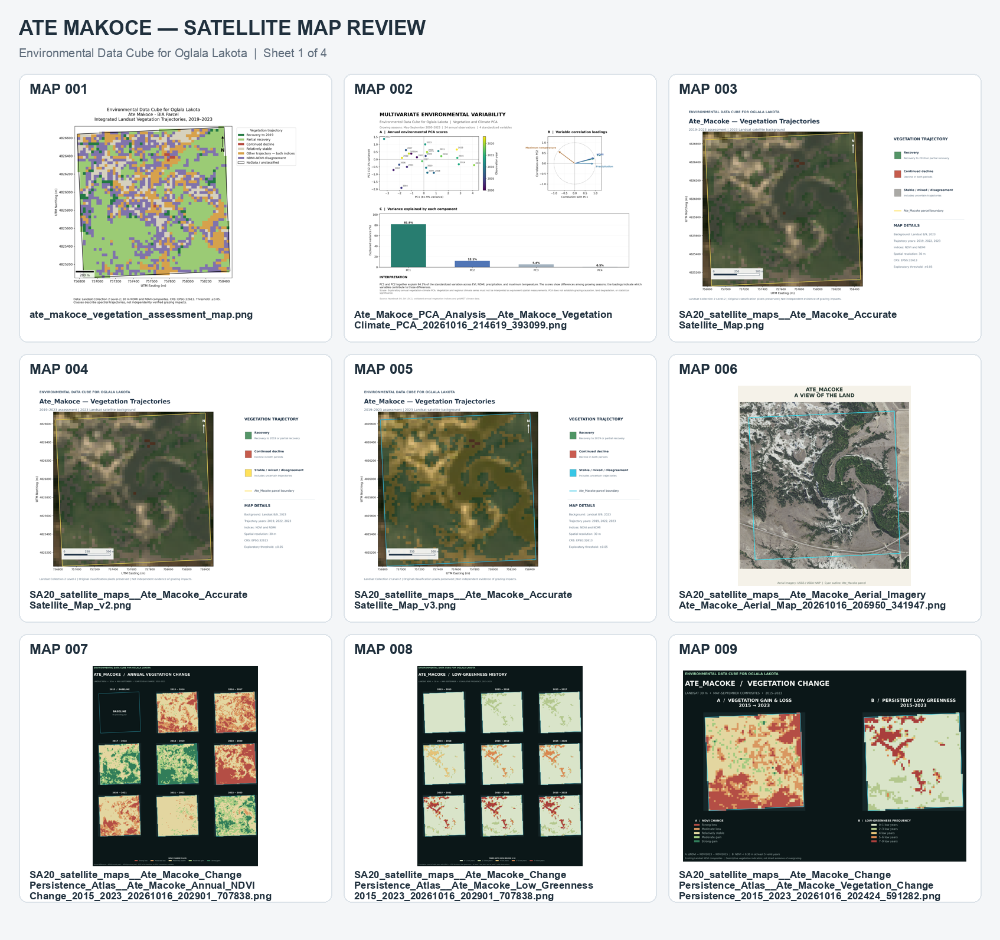

In [53]:
# ======================================================================
# SA 19X — SAFE SATELLITE MAP CONTACT SHEET
# Environmental Data Cube for Oglala Lakota
# Ate Makoce | Dissertation Figure Review
#
# PURPOSE:
#   Review recovered satellite maps and vegetation-change figures.
#
# SAFETY:
#   - READS source files only
#   - DOES NOT rename, move, or delete files
#   - DOES NOT modify notebooks or data cubes
#   - DOES NOT edit TIFF rasters or shapefiles
#   - DOES NOT overwrite existing output files
#   - DOES NOT execute other notebooks
#
# OUTPUT:
#   06_Map_Review_Contact_Sheets/
#       Contact_Sheet_01.png
#       Contact_Sheet_02.png
#       ...
#       Map_Review_Inventory.csv
#
# Uses Pillow, pandas and matplotlib.
# ======================================================================

from pathlib import Path
from datetime import datetime
from collections import defaultdict
from IPython.display import display, Image as IPyImage

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, ImageDraw, ImageFont

import hashlib
import io
import math
import re

# --------------------------------------------------------------
# 1. PROJECT PATHS
# --------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

EXPORT = (
    PROJECT
    / "results"
    / "Ate_Makoce_Dissertation_Results_Export"
)

RECOVERY = (
    EXPORT
    / "05_Recovered_Ate_Macoke_Files"
)

REVIEW_ROOT = (
    EXPORT
    / "06_Map_Review_Contact_Sheets"
)

if not PROJECT.is_dir():
    raise FileNotFoundError(
        f"Project not found:\n{PROJECT}"
    )

if not RECOVERY.is_dir():
    raise FileNotFoundError(
        f"Recovered files folder not found:\n{RECOVERY}"
    )

# A unique output folder avoids overwriting prior reviews.
timestamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

REVIEW = REVIEW_ROOT / f"Review_{timestamp}"

REVIEW.mkdir(
    parents=True,
    exist_ok=False
)

# --------------------------------------------------------------
# 2. IMAGE AND MAP SELECTION
# --------------------------------------------------------------

# Review rendered PNG/JPEG files.
# Original GeoTIFF data are deliberately excluded.
#
# PDFs are not converted here because corresponding PNG
# exports are often already available.

IMAGE_EXTENSIONS = {
    ".png", ".jpg", ".jpeg", ".webp"
}

# Map-related keywords.
MAP_KEYWORDS = [
    "map",
    "satellite",
    "spatial",
    "ndvi",
    "ndmi",
    "vegetation",
    "change",
    "persistence",
    "landsat",
    "community",
    "parcel",
    "trend",
    "four_panel",
    "four-panel",
    "atlas"
]

# Search the RECOVERY folder only.
# This avoids traversing the original project again.
candidates = []

for path in RECOVERY.rglob("*"):

    if not path.is_file():
        continue

    if path.suffix.lower() not in IMAGE_EXTENSIONS:
        continue

    filename = path.stem.lower()

    if any(
        keyword in filename
        for keyword in MAP_KEYWORDS
    ):
        candidates.append(path)

candidates = sorted(
    candidates,
    key=lambda p: str(p).lower()
)

print("=" * 75)
print("SAFE SATELLITE MAP REVIEW")
print("=" * 75)

print(f"\nMap-related image candidates: {len(candidates)}")
print("Original research files will not be changed.")

# --------------------------------------------------------------
# 3. REMOVE IDENTICAL IMAGE DUPLICATES
# --------------------------------------------------------------

def sha256_file(path):

    digest = hashlib.sha256()

    with path.open("rb") as stream:

        for chunk in iter(
            lambda: stream.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()

unique_images = []
seen_hashes = {}
duplicate_count = 0
read_errors = []

for path in candidates:

    try:

        digest = sha256_file(path)

        if digest in seen_hashes:
            duplicate_count += 1
            continue

        seen_hashes[digest] = path

        unique_images.append({
            "path": path,
            "sha256": digest
        })

    except Exception as exc:

        read_errors.append({
            "Path": str(path),
            "Error": str(exc)
        })

print(f"Unique image files: {len(unique_images)}")
print(f"Identical duplicates skipped: {duplicate_count}")

# --------------------------------------------------------------
# 4. THUMBNAIL DESIGN
# --------------------------------------------------------------

COLUMNS = 3
ROWS = 3

IMAGES_PER_SHEET = COLUMNS * ROWS

THUMB_WIDTH = 480
THUMB_HEIGHT = 340

CARD_WIDTH = 530
CARD_HEIGHT = 455

MARGIN = 32
GAP = 20
HEADER_HEIGHT = 125

SHEET_WIDTH = (
    MARGIN * 2
    + COLUMNS * CARD_WIDTH
    + (COLUMNS - 1) * GAP
)

SHEET_HEIGHT = (
    HEADER_HEIGHT
    + MARGIN
    + ROWS * CARD_HEIGHT
    + (ROWS - 1) * GAP
    + MARGIN
)

BACKGROUND = "#F4F6F8"
CARD_BACKGROUND = "#FFFFFF"
TEXT_COLOR = "#20303D"
MUTED_COLOR = "#5D6B7A"
BORDER_COLOR = "#DCE3E9"

def load_font(size, bold=False):

    paths = [
        "/System/Library/Fonts/Supplemental/Arial Bold.ttf"
        if bold else
        "/System/Library/Fonts/Supplemental/Arial.ttf",
        "/Library/Fonts/Arial.ttf",
        "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"
    ]

    for font_path in paths:

        try:
            return ImageFont.truetype(
                font_path,
                size=size
            )
        except (OSError, ValueError):
            pass

    return ImageFont.load_default()

FONT_TITLE = load_font(34, bold=True)
FONT_SUBTITLE = load_font(20)
FONT_NUMBER = load_font(24, bold=True)
FONT_FILENAME = load_font(17, bold=True)
FONT_PATH = load_font(15)

def wrap_text(text, max_chars=47):

    text = str(text)

    lines = []

    while len(text) > max_chars:

        cut = text.rfind("_", 0, max_chars)

        if cut < 12:
            cut = max_chars

        lines.append(text[:cut].rstrip("_"))

        text = text[cut:].lstrip("_")

    if text:
        lines.append(text)

    return lines[:3]

# --------------------------------------------------------------
# 5. BUILD CONTACT SHEETS
# --------------------------------------------------------------

inventory_records = []
sheet_paths = []

number_of_sheets = math.ceil(
    len(unique_images) / IMAGES_PER_SHEET
)

for sheet_index in range(number_of_sheets):

    sheet = Image.new(
        "RGB",
        (SHEET_WIDTH, SHEET_HEIGHT),
        BACKGROUND
    )

    draw = ImageDraw.Draw(sheet)

    draw.text(
        (MARGIN, 28),
        "ATE MAKOCE — SATELLITE MAP REVIEW",
        font=FONT_TITLE,
        fill=TEXT_COLOR
    )

    draw.text(
        (MARGIN, 78),
        (
            "Environmental Data Cube for Oglala Lakota"
            f"  |  Sheet {sheet_index + 1}"
            f" of {number_of_sheets}"
        ),
        font=FONT_SUBTITLE,
        fill=MUTED_COLOR
    )

    start = sheet_index * IMAGES_PER_SHEET

    end = min(
        start + IMAGES_PER_SHEET,
        len(unique_images)
    )

    batch = unique_images[start:end]

    for local_index, item in enumerate(batch):

        global_index = start + local_index + 1

        path = item["path"]

        row = local_index // COLUMNS
        col = local_index % COLUMNS

        x = MARGIN + col * (CARD_WIDTH + GAP)

        y = (
            HEADER_HEIGHT
            + row * (CARD_HEIGHT + GAP)
        )

        draw.rounded_rectangle(
            [
                x,
                y,
                x + CARD_WIDTH,
                y + CARD_HEIGHT
            ],
            radius=14,
            fill=CARD_BACKGROUND,
            outline=BORDER_COLOR,
            width=2
        )

        # Number for matching thumbnails to the CSV.
        draw.text(
            (x + 18, y + 12),
            f"MAP {global_index:03d}",
            font=FONT_NUMBER,
            fill=TEXT_COLOR
        )

        image_status = "OK"
        original_size = ""

        try:

            with Image.open(path) as source:

                original_size = (
                    f"{source.width} × {source.height}"
                )

                source.load()

                preview = ImageOps.contain(
                    source.convert("RGB"),
                    (THUMB_WIDTH, THUMB_HEIGHT)
                )

            image_x = (
                x
                + (CARD_WIDTH - preview.width) // 2
            )

            image_y = y + 54 + (
                THUMB_HEIGHT - preview.height
            ) // 2

            sheet.paste(
                preview,
                (image_x, image_y)
            )

        except Exception as exc:

            image_status = f"ERROR: {exc}"

            draw.text(
                (x + 22, y + 170),
                "Preview unavailable",
                font=FONT_SUBTITLE,
                fill="#B45309"
            )

            read_errors.append({
                "Path": str(path),
                "Error": str(exc)
            })

        filename_lines = wrap_text(
            path.name,
            max_chars=48
        )

        for line_number, line in enumerate(
            filename_lines
        ):

            draw.text(
                (
                    x + 18,
                    y + 398 + line_number * 18
                ),
                line,
                font=FONT_FILENAME,
                fill=TEXT_COLOR
            )

        inventory_records.append({
            "Map_ID": f"MAP_{global_index:03d}",
            "Sheet": sheet_index + 1,
            "Filename": path.name,
            "Recovered_Path": str(path),
            "Original_Project_Path": str(
                PROJECT
                / path.relative_to(RECOVERY)
            ),
            "Original_Image_Dimensions": original_size,
            "SHA256": item["sha256"],
            "Preview_Status": image_status,
            "Review_Decision": "",
            "Proposed_Dissertation_Figure": "",
            "Notes": ""
        })

    sheet_path = (
        REVIEW
        / f"Contact_Sheet_{sheet_index + 1:02d}.png"
    )

    sheet.save(
        sheet_path,
        format="PNG"
    )

    sheet_paths.append(sheet_path)

# --------------------------------------------------------------
# 6. SAVE REVIEW INVENTORY
# --------------------------------------------------------------

inventory_df = pd.DataFrame(
    inventory_records,
    columns=[
        "Map_ID",
        "Sheet",
        "Filename",
        "Recovered_Path",
        "Original_Project_Path",
        "Original_Image_Dimensions",
        "SHA256",
        "Preview_Status",
        "Review_Decision",
        "Proposed_Dissertation_Figure",
        "Notes"
    ]
)

inventory_path = (
    REVIEW
    / "Map_Review_Inventory.csv"
)

inventory_df.to_csv(
    inventory_path,
    index=False
)

if read_errors:

    pd.DataFrame(read_errors).to_csv(
        REVIEW / "Preview_Errors.csv",
        index=False
    )

# --------------------------------------------------------------
# 7. DISPLAY RESULTS
# --------------------------------------------------------------

print("\n" + "=" * 75)
print("SATELLITE MAP CONTACT SHEETS COMPLETE")
print("=" * 75)

print(f"\nUnique map images: {len(unique_images)}")
print(f"Contact sheets created: {len(sheet_paths)}")
print(f"Identical duplicates skipped: {duplicate_count}")
print(f"Preview errors: {len(read_errors)}")

print("\nReview folder:")
print(REVIEW)

print("\nInventory:")
print(inventory_path)

print("\nOriginal notebooks, rasters and data cubes: UNCHANGED")

if sheet_paths:

    print("\nDISPLAYING FIRST CONTACT SHEET")

    display(
        IPyImage(
            filename=str(sheet_paths[0]),
            width=1150
        )
    )

else:

    print(
        "\nNo matching PNG/JPEG map images were found."
    )

print("\n" + "=" * 75)


In [54]:

# ======================================================================
# SA 19AC — CURATED DISSERTATION METHODS FIGURE EXPORT
# Environmental Data Cube for Oglala Lakota
#
# READS: Existing Methods contact-sheet inventory and source PNG images
# WRITES: New copies inside 07_Methods_Figures_PNG only
#         New timestamped Methods inventory inside export folder
#
# SAFETY:
# - Does not open or modify the data cube
# - Does not execute or modify any notebooks
# - Does not modify source images
# - Does not overwrite existing exports
# - Verifies source image checksums when available
# ======================================================================

from pathlib import Path
from datetime import datetime
from collections import Counter
import pandas as pd
import hashlib
import shutil
import re

# ----------------------------------------------------------------------
# 1. PROJECT PATHS
# ----------------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

EXPORT_ROOT = (
    PROJECT
    / "results"
    / "Ate_Makoce_Dissertation_Results_Export"
)

REVIEW_ROOT = EXPORT_ROOT / "08_Methods_Validation_Review"
METHODS_ROOT = EXPORT_ROOT / "07_Methods_Figures_PNG"

FOLDERS = {
    "sampling": "01_Study_Area_and_Sampling",
    "acquisition": "02_Data_Acquisition",
    "qa": "03_Data_Quality_Assurance",
    "construction": "04_Data_Cube_Construction",
    "validation": "05_Validation_and_Reliability",
    "sensitivity": "06_Sensitivity_and_Uncertainty",
    "provenance": "07_Reproducibility_and_Provenance",
}

# ----------------------------------------------------------------------
# 2. CURATED METHODS FIGURE SELECTION
#
# Selected after reviewing all 12 contact sheets.
# Figure numbers are provisional and can be updated later.
#
# One unresolved QA choice is held for review.
# ----------------------------------------------------------------------

SELECTIONS = [
    ("M.1",  "METHOD_105", "Original 15 Point Sampling Lattice", "sampling"),
    ("M.2",  None, "MODIS Pixel Quality Screening", "qa"),
    ("M.3",  "METHOD_066", "MODIS Composite Availability and Coverage", "qa"),
    ("M.4",  "METHOD_041", "Landsat Candidate Scene Acquisition Dates", "acquisition"),
    ("M.5",  "METHOD_078", "Landsat Composite Observation Support", "acquisition"),
    ("M.6",  "METHOD_101", "Monthly Multivariable Environmental Indicators", "construction"),
    ("M.7",  "METHOD_093", "Historical and Spatial Grid NDVI Consistency", "validation"),
    ("M.8",  "METHOD_084", "Landsat Seasonal Window Consistency", "sensitivity"),
    ("M.9",  "METHOD_085", "Field Validation Candidate Stability", "sampling"),
    ("M.10", "METHOD_086", "Vegetation Decline Threshold Sensitivity", "sensitivity"),
    ("M.11", None, "Spatial Bootstrap Vegetation Change Uncertainty", "sensitivity"),
    ("M.12", "METHOD_050", "Vegetation Climate Model Cross Validation", "validation"),
]

# Set these only after confirming your preferred figure.
# Leave None to hold the figure for review.

MODIS_QA_CHOICE = None        # "METHOD_001", "METHOD_002", or "METHOD_003"
BOOTSTRAP_CHOICE = None       # "METHOD_074" or "METHOD_077"

CHOICES = {
    "M.2": MODIS_QA_CHOICE,
    "M.11": BOOTSTRAP_CHOICE,
}

ALLOWED_CHOICES = {
    "M.2": {"METHOD_001", "METHOD_002", "METHOD_003"},
    "M.11": {"METHOD_074", "METHOD_077"},
}

# ----------------------------------------------------------------------
# 3. LOCATE EXISTING METHODS CONTACT-SHEET INVENTORY
# ----------------------------------------------------------------------

inventories = sorted(
    REVIEW_ROOT.glob(
        "Contact_Sheets_*/Methods_Contact_Sheet_Inventory.csv"
    ),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not inventories:
    raise FileNotFoundError(
        "No Methods contact-sheet inventory found. "
        "Please confirm that SA 19AA completed successfully."
    )

inventory_path = inventories[0]
source_df = pd.read_csv(inventory_path, dtype=str).fillna("")
source_df.columns = [str(c).strip() for c in source_df.columns]

if "Methods_ID" not in source_df.columns:
    raise ValueError(
        "Inventory is missing Methods_ID. Available columns: "
        + ", ".join(source_df.columns)
    )

if source_df["Methods_ID"].duplicated().any():
    raise ValueError("Duplicate Methods_ID values found in inventory.")

lookup = source_df.set_index("Methods_ID")

# ----------------------------------------------------------------------
# 4. IDENTIFY SOURCE PATH AND CHECKSUM COLUMNS
# ----------------------------------------------------------------------

PATH_COLUMNS = [
    "Source_Path",
    "Original_Path",
    "Original_Project_Path",
    "Image_Path",
    "Full_Path",
    "Path",
    "Source_File",
]

HASH_COLUMNS = ["SHA256", "Source_SHA256", "File_SHA256"]

path_col = next(
    (c for c in PATH_COLUMNS if c in source_df.columns),
    None
)

hash_col = next(
    (c for c in HASH_COLUMNS if c in source_df.columns),
    None
)

if path_col is None:
    raise ValueError(
        "Could not identify the source-path column.\n"
        f"Available columns: {list(source_df.columns)}\n"
        "No files were copied."
    )

# ----------------------------------------------------------------------
# 5. SAFE HELPERS
# ----------------------------------------------------------------------

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def slug(text):
    return re.sub(
        r"[^A-Za-z0-9]+", "_", text
    ).strip("_")


def resolve_source(raw):
    raw = str(raw).strip()
    if not raw:
        raise ValueError("Empty source path")

    candidate = Path(raw).expanduser()

    if not candidate.is_absolute():
        candidate = PROJECT / candidate

    resolved = candidate.resolve(strict=True)

    # Prevent accidental reading from an unexpected location.
    if not resolved.is_relative_to(PROJECT.resolve()):
        raise ValueError(
            f"Source is outside the project: {resolved}"
        )

    if resolved.suffix.lower() != ".png":
        raise ValueError(
            f"Expected an original PNG image: {resolved}"
        )

    if not resolved.is_file():
        raise ValueError(f"Not a file: {resolved}")

    # Never treat a previously curated Methods export as a source.
    if resolved.is_relative_to(METHODS_ROOT.resolve()):
        raise ValueError(
            f"Source is already in Methods export: {resolved}"
        )

    return resolved


# ----------------------------------------------------------------------
# 6. VERIFY ALL CHOSEN SOURCES BEFORE WRITING
# ----------------------------------------------------------------------

plans = []
records = []

for number, method_id, title, category in SELECTIONS:

    if number in CHOICES:
        method_id = CHOICES[number]

        if (
            method_id is not None
            and method_id not in ALLOWED_CHOICES[number]
        ):
            raise ValueError(
                f"Invalid selection for {number}: {method_id}"
            )

    record = {
        "Figure": number,
        "Title": title,
        "Methods_ID": method_id or "",
        "Category": FOLDERS[category],
        "Status": "",
        "Original_Source_Path": "",
        "Original_SHA256": "",
        "Exported_Path": "",
        "Exported_SHA256": "",
        "Notes": "",
    }

    if method_id is None:
        record["Status"] = "AWAITING FIGURE SELECTION"
        record["Notes"] = (
            "Choose from: "
            + ", ".join(sorted(ALLOWED_CHOICES[number]))
        )
        records.append(record)
        continue

    if method_id not in lookup.index:
        record["Status"] = "SOURCE ID NOT FOUND"
        record["Notes"] = "Method ID absent from inventory"
        records.append(record)
        continue

    row = lookup.loc[method_id]

    try:
        source = resolve_source(row[path_col])
        actual_hash = sha256_file(source)

        expected_hash = (
            str(row[hash_col]).strip().lower()
            if hash_col is not None
            else ""
        )

        if expected_hash and expected_hash != actual_hash:
            raise ValueError(
                "SHA256 checksum mismatch with review inventory"
            )

        filename = (
            f"Figure_{number.replace('.', '_')}_"
            f"{slug(title)}.png"
        )

        destination = (
            METHODS_ROOT
            / FOLDERS[category]
            / filename
        )

        record["Original_Source_Path"] = str(source)
        record["Original_SHA256"] = actual_hash
        record["Exported_Path"] = str(destination)

        plans.append((source, destination, actual_hash, record))

    except Exception as exc:
        record["Status"] = "SOURCE VERIFICATION FAILED"
        record["Notes"] = str(exc)

    records.append(record)

# ----------------------------------------------------------------------
# 7. CREATE ORGANIZED METHODS FOLDERS
# ----------------------------------------------------------------------

METHODS_ROOT.mkdir(parents=True, exist_ok=True)

for folder_name in FOLDERS.values():
    (METHODS_ROOT / folder_name).mkdir(
        parents=True,
        exist_ok=True
    )

# ----------------------------------------------------------------------
# 8. COPY ONLY VERIFIED, APPROVED FIGURES
# ----------------------------------------------------------------------

for source, destination, source_hash, record in plans:

    if destination.exists():
        if not destination.is_file():
            record["Status"] = "DESTINATION CONFLICT"
            record["Notes"] = "Destination exists but is not a file"
            continue

        existing_hash = sha256_file(destination)

        if existing_hash == source_hash:
            record["Status"] = "ALREADY PRESENT"
            record["Exported_SHA256"] = existing_hash
        else:
            record["Status"] = "DESTINATION CONFLICT"
            record["Notes"] = (
                "Different file already exists. "
                "Nothing was overwritten."
            )

        continue

    try:
        # Exclusive creation prevents overwriting a file that
        # appears between the existence check and the copy.
        with source.open("rb") as src, destination.open("xb") as dst:
            shutil.copyfileobj(src, dst)

        copied_hash = sha256_file(destination)

        if copied_hash != source_hash:
            record["Status"] = "COPY VERIFICATION FAILED"
            record["Notes"] = (
                "Export checksum differs from source. "
                "Inspect this copy before using it."
            )
        else:
            record["Status"] = "NEW"
            record["Exported_SHA256"] = copied_hash

    except FileExistsError:
        record["Status"] = "DESTINATION CONFLICT"
        record["Notes"] = "File appeared during copying; not overwritten"

    except Exception as exc:
        record["Status"] = "COPY FAILED"
        record["Notes"] = str(exc)

# ----------------------------------------------------------------------
# 9. SAVE A NEW, TIMESTAMPED MASTER INVENTORY
# ----------------------------------------------------------------------

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

report = pd.DataFrame(records)

inventory_output = (
    EXPORT_ROOT
    / f"Dissertation_Methods_Curated_Inventory_{stamp}.csv"
)

# Exclusive creation: never overwrite an earlier inventory.
with inventory_output.open("x", encoding="utf-8", newline="") as handle:
    report.to_csv(handle, index=False)

# ----------------------------------------------------------------------
# 10. DISPLAY RESULTS
# ----------------------------------------------------------------------

print("=" * 76)
print("SA 19AC — CURATED DISSERTATION METHODS FIGURE EXPORT")
print("=" * 76)

print("\nSource inventory:")
print(inventory_path)

print("\nMethods export folder:")
print(METHODS_ROOT)

print("\nSTATUS SUMMARY")
for status, count in Counter(report["Status"]).items():
    print(f"  {status}: {count}")

print("\nCURATED METHODS FIGURE INVENTORY")

display(
    report[
        ["Figure", "Title", "Methods_ID", "Category", "Status"]
    ]
)

print("\nMaster inventory:")
print(inventory_output)

print("\nSAFETY CONFIRMATION")
print("- Data cube: NOT OPENED OR MODIFIED")
print("- Original notebooks: NOT EXECUTED OR MODIFIED")
print("- Original figures: NOT MODIFIED")
print("- Existing dissertation exports: NOT OVERWRITTEN")
print("- Methods export: NEW COPIES ONLY")



SA 19AC — CURATED DISSERTATION METHODS FIGURE EXPORT

Source inventory:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/08_Methods_Validation_Review/Contact_Sheets_20261016_224743_797396/Methods_Contact_Sheet_Inventory.csv

Methods export folder:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/07_Methods_Figures_PNG

STATUS SUMMARY
  NEW: 10
  AWAITING FIGURE SELECTION: 2

CURATED METHODS FIGURE INVENTORY


,Figure,Title,Methods_ID,Category,Status
0,M.1,Original 15 Point Sampling Lattice,METHOD_105,01_Study_Area_and_Sampling,NEW
1,M.2,MODIS Pixel Quality Screening,,03_Data_Quality_Assurance,AWAITING FIGURE SELECTION
2,M.3,MODIS Composite Availability and Coverage,METHOD_066,03_Data_Quality_Assurance,NEW
3,M.4,Landsat Candidate Scene Acquisition Dates,METHOD_041,02_Data_Acquisition,NEW
4,M.5,Landsat Composite Observation Support,METHOD_078,02_Data_Acquisition,NEW
5,M.6,Monthly Multivariable Environmental Indicators,METHOD_101,04_Data_Cube_Construction,NEW
6,M.7,Historical and Spatial Grid NDVI Consistency,METHOD_093,05_Validation_and_Reliability,NEW
7,M.8,Landsat Seasonal Window Consistency,METHOD_084,06_Sensitivity_and_Uncertainty,NEW
8,M.9,Field Validation Candidate Stability,METHOD_085,01_Study_Area_and_Sampling,NEW
9,M.10,Vegetation Decline Threshold Sensitivity,METHOD_086,06_Sensitivity_and_Uncertainty,NEW



Master inventory:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/Dissertation_Methods_Curated_Inventory_20261016_230548_011314.csv

SAFETY CONFIRMATION
- Data cube: NOT OPENED OR MODIFIED
- Original notebooks: NOT EXECUTED OR MODIFIED
- Original figures: NOT MODIFIED
- Existing dissertation exports: NOT OVERWRITTEN
- Methods export: NEW COPIES ONLY


In [55]:

# ======================================================================
# SA 19AG — ATE LAND ASSESSMENT PACKET: CURATED MAP EXPORT
# Environmental Data Cube for Oglala Lakota
#
# INPUT:
#   Existing SA 19AF contact-sheet inventory
#   Eight existing, checksum-verified source PNG images
#
# OUTPUT:
#   New packet directory containing eight full-resolution PNG copies
#   New master inventory with source and export SHA256 checksums
#
# SAFETY:
#   No data cube access
#   No notebook execution or modification
#   No original image modification
#   No overwriting of existing files
# ======================================================================

from pathlib import Path
from datetime import datetime
from IPython.display import display
import pandas as pd
import hashlib
import shutil
import re

# ----------------------------------------------------------------------
# 1. PROJECT PATHS
# ----------------------------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

EXPORT_ROOT = (
    PROJECT
    / "results"
    / "Ate_Makoce_Dissertation_Results_Export"
)

REVIEW_ROOT = (
    EXPORT_ROOT
    / "09_Discussion_Community_Maps"
)

PACKET_ROOT = (
    REVIEW_ROOT
    / "Ate_Land_Assessment_Packet"
)

# ----------------------------------------------------------------------
# 2. EIGHT CURATED MAPS
# ----------------------------------------------------------------------

SELECTIONS = [
    ("A.1", "ATE_MAP_005", "How Is My Land Doing"),
    ("A.2", "ATE_MAP_069", "A View of the Land"),
    ("A.3", "ATE_MAP_018", "Original 15 Point Sampling Lattice"),
    ("A.4", "ATE_MAP_016", "Vegetation Through Time"),
    ("A.5", "ATE_MAP_073", "Annual Vegetation Change"),
    ("A.6", "ATE_MAP_074", "Low Greenness History"),
    ("A.7", "ATE_MAP_075", "Vegetation Change and Persistence"),
    ("A.8", "ATE_MAP_011", "Vegetation Decline and Land Cover"),
]

# ----------------------------------------------------------------------
# 3. FIND EXISTING CONTACT-SHEET INVENTORY
# ----------------------------------------------------------------------

inventory_files = sorted(
    REVIEW_ROOT.glob(
        "Ate_Map_Contact_Sheets_*/"
        "Ate_Map_Contact_Sheet_Inventory.csv"
    ),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not inventory_files:
    raise FileNotFoundError(
        "SA 19AF contact-sheet inventory was not found."
    )

inventory_path = inventory_files[0]

df = pd.read_csv(
    inventory_path,
    dtype=str
).fillna("")

required = {
    "Review_ID",
    "Source_Path",
    "SHA256",
    "Verification",
    "Duplicate_Of",
}

missing = required - set(df.columns)

if missing:
    raise ValueError(
        f"Missing inventory columns: {missing}"
    )

if df["Review_ID"].duplicated().any():
    raise ValueError(
        "Duplicate Review_ID values in contact-sheet inventory."
    )

lookup = df.set_index("Review_ID")

# ----------------------------------------------------------------------
# 4. SAFETY HELPERS
# ----------------------------------------------------------------------

def sha256_file(path):
    digest = hashlib.sha256()

    with path.open("rb") as stream:
        for chunk in iter(
            lambda: stream.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


def slug(text):
    return re.sub(
        r"[^A-Za-z0-9]+",
        "_",
        text
    ).strip("_")


def verified_source(row):

    source = Path(row["Source_Path"]).expanduser()

    if not source.is_absolute():
        source = PROJECT / source

    source = source.resolve(strict=True)

    if not source.is_relative_to(
        PROJECT.resolve(strict=True)
    ):
        raise ValueError(
            "Source is outside the project."
        )

    if source.is_relative_to(
        EXPORT_ROOT.resolve()
    ):
        raise ValueError(
            "Source is inside the dissertation export area."
        )

    if not source.is_file():
        raise ValueError(
            "Source is not a file."
        )

    if source.suffix.lower() != ".png":
        raise ValueError(
            "Source must be a PNG image."
        )

    if row["Verification"] != "VERIFIED":
        raise ValueError(
            "Source did not pass SA 19AF verification."
        )

    if row["Duplicate_Of"].strip():
        raise ValueError(
            "Selected ID is a duplicate entry, not the "
            "unique reviewed source."
        )

    digest = sha256_file(source)

    if digest.lower() != row["SHA256"].strip().lower():
        raise ValueError(
            "SHA256 checksum mismatch."
        )

    return source, digest


# ----------------------------------------------------------------------
# 5. VERIFY ALL EIGHT BEFORE COPYING ANYTHING
# ----------------------------------------------------------------------

verified = []
errors = []

for figure, review_id, title in SELECTIONS:

    try:
        if review_id not in lookup.index:
            raise ValueError(
                f"{review_id} not found in inventory."
            )

        row = lookup.loc[review_id]
        source, digest = verified_source(row)

        verified.append({
            "Figure": figure,
            "Review_ID": review_id,
            "Title": title,
            "Source": source,
            "SHA256": digest,
        })

    except Exception as exc:
        errors.append({
            "Review_ID": review_id,
            "Error": str(exc),
        })

if errors:
    print("Source verification failed. No figures copied.")
    display(pd.DataFrame(errors))

    raise RuntimeError(
        "Resolve source verification errors before exporting."
    )

# ----------------------------------------------------------------------
# 6. CREATE A NEW, NON-OVERWRITING EXPORT RUN
# ----------------------------------------------------------------------

stamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

run_folder = (
    PACKET_ROOT
    / f"Curated_Maps_{stamp}"
)

run_folder.mkdir(
    parents=True,
    exist_ok=False
)

MAPS_FOLDER = run_folder / "01_Selected_Maps_PNG"

MAPS_FOLDER.mkdir(
    parents=False,
    exist_ok=False
)

# ----------------------------------------------------------------------
# 7. COPY AND VERIFY ALL EIGHT IMAGES
# ----------------------------------------------------------------------

records = []

for item in verified:

    filename = (
        f"Figure_{item['Figure'].replace('.', '_')}_"
        f"{slug(item['Title'])}.png"
    )

    destination = MAPS_FOLDER / filename

    record = {
        "Figure": item["Figure"],
        "Review_ID": item["Review_ID"],
        "Title": item["Title"],
        "Original_Path": str(item["Source"]),
        "Original_SHA256": item["SHA256"],
        "Export_Path": str(destination),
        "Export_SHA256": "",
        "Status": "",
        "Review_Notes": (
            "Interpretation and map metadata require "
            "final review before distribution."
        ),
    }

    try:
        # Exclusive file creation: never overwrite.
        with item["Source"].open("rb") as src:
            with destination.open("xb") as dst:
                shutil.copyfileobj(src, dst)

        copied_hash = sha256_file(destination)

        if copied_hash != item["SHA256"]:
            record["Status"] = "CHECKSUM MISMATCH"
        else:
            record["Status"] = "VERIFIED COPY"
            record["Export_SHA256"] = copied_hash

    except Exception as exc:
        record["Status"] = "COPY ERROR"
        record["Review_Notes"] = str(exc)

    records.append(record)

# ----------------------------------------------------------------------
# 8. CREATE PACKET MASTER INVENTORY
# ----------------------------------------------------------------------

report = pd.DataFrame(records)

inventory_output = (
    run_folder
    / "Ate_Land_Assessment_Packet_Master_Inventory.csv"
)

with inventory_output.open(
    "x",
    encoding="utf-8",
    newline=""
) as handle:
    report.to_csv(
        handle,
        index=False
    )

# ----------------------------------------------------------------------
# 9. DISPLAY SUMMARY
# ----------------------------------------------------------------------

print("=" * 76)
print("SA 19AG — ATE LAND ASSESSMENT PACKET MAP EXPORT")
print("=" * 76)

print("\nSource inventory:")
print(inventory_path)

print("\nPacket export folder:")
print(run_folder)

print("\nMAP EXPORT STATUS")

display(
    report[
        [
            "Figure",
            "Review_ID",
            "Title",
            "Status"
        ]
    ]
)

verified_count = (
    report["Status"] == "VERIFIED COPY"
).sum()

print(
    f"\nVerified map copies: {verified_count} "
    f"of {len(SELECTIONS)}"
)

print("\nMaster inventory:")
print(inventory_output)

print("\nSAFETY CONFIRMATION")
print("- Data cube: NOT OPENED OR MODIFIED")
print("- Original notebooks: NOT EXECUTED OR MODIFIED")
print("- Original maps: NOT MODIFIED")
print("- Existing exports: NOT OVERWRITTEN")
print("- New packet folder: CREATED")

if verified_count == len(SELECTIONS):
    print(
        "\nSUCCESS: All eight maps are ready "
        "for informational packet assembly."
    )
else:
    print(
        "\nATTENTION: Review any failed copies "
        "before assembling the packet."
    )


SA 19AG — ATE LAND ASSESSMENT PACKET MAP EXPORT

Source inventory:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Map_Contact_Sheets_20261016_231611_913761/Ate_Map_Contact_Sheet_Inventory.csv

Packet export folder:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Curated_Maps_20261016_232442_288275

MAP EXPORT STATUS


,Figure,Review_ID,Title,Status
0,A.1,ATE_MAP_005,How Is My Land Doing,VERIFIED COPY
1,A.2,ATE_MAP_069,A View of the Land,VERIFIED COPY
2,A.3,ATE_MAP_018,Original 15 Point Sampling Lattice,VERIFIED COPY
3,A.4,ATE_MAP_016,Vegetation Through Time,VERIFIED COPY
4,A.5,ATE_MAP_073,Annual Vegetation Change,VERIFIED COPY
5,A.6,ATE_MAP_074,Low Greenness History,VERIFIED COPY
6,A.7,ATE_MAP_075,Vegetation Change and Persistence,VERIFIED COPY
7,A.8,ATE_MAP_011,Vegetation Decline and Land Cover,VERIFIED COPY



Verified map copies: 8 of 8

Master inventory:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Curated_Maps_20261016_232442_288275/Ate_Land_Assessment_Packet_Master_Inventory.csv

SAFETY CONFIRMATION
- Data cube: NOT OPENED OR MODIFIED
- Original notebooks: NOT EXECUTED OR MODIFIED
- Original maps: NOT MODIFIED
- Existing exports: NOT OVERWRITTEN
- New packet folder: CREATED

SUCCESS: All eight maps are ready for informational packet assembly.


In [56]:

# ======================================================================
# SA 19AH — ATE MAP READABILITY AND PRESENTATION REVIEW
# Environmental Data Cube for Oglala Lakota
#
# READS: 8 verified exported PNG copies and SA 19AG inventory
# WRITES: New preview PNGs and readability CSV in a new folder
#
# No data cube access. No original-image modification.
# No overwriting of existing files.
# ======================================================================

from pathlib import Path
from datetime import datetime
from PIL import Image, ImageOps, ImageDraw, ImageFont
from IPython.display import display
import pandas as pd
import hashlib
import math

PROJECT = (
    Path.home() / "Documents" / "ElishaWakinyanZi-WORK"
    / "datacube_2026" / "ate_makoce_agcube"
)

PACKET_ROOT = (
    PROJECT / "results"
    / "Ate_Makoce_Dissertation_Results_Export"
    / "09_Discussion_Community_Maps"
    / "Ate_Land_Assessment_Packet"
)

# ------------------------------------------------------------
# 1. Find the latest completed curated-map export
# ------------------------------------------------------------

inventories = sorted(
    PACKET_ROOT.glob(
        "Curated_Maps_*/"
        "Ate_Land_Assessment_Packet_Master_Inventory.csv"
    ),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not inventories:
    raise FileNotFoundError(
        "SA 19AG master inventory was not found."
    )

inventory_path = inventories[0]
df = pd.read_csv(inventory_path, dtype=str).fillna("")

required = {
    "Figure", "Review_ID", "Title",
    "Export_Path", "Export_SHA256", "Status"
}

missing = required - set(df.columns)

if missing:
    raise ValueError(f"Missing inventory columns: {missing}")

if len(df) != 8 or df["Figure"].duplicated().any():
    raise ValueError(
        "Expected eight uniquely numbered packet figures."
    )

# ------------------------------------------------------------
# 2. Verify all copies before creating previews
# ------------------------------------------------------------

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(
            lambda: stream.read(1024 * 1024), b""
        ):
            digest.update(chunk)
    return digest.hexdigest()

verified = []

for _, row in df.iterrows():
    path = Path(row["Export_Path"]).expanduser().resolve(
        strict=True
    )

    if not path.is_relative_to(PACKET_ROOT.resolve()):
        raise ValueError(f"Unexpected source location: {path}")

    if path.suffix.lower() != ".png":
        raise ValueError(f"Expected PNG: {path}")

    if row["Status"] != "VERIFIED COPY":
        raise ValueError(
            f"Figure {row['Figure']} was not verified."
        )

    actual_hash = sha256_file(path)

    if actual_hash.lower() != row["Export_SHA256"].lower():
        raise ValueError(
            f"Checksum mismatch for {row['Figure']}"
        )

    verified.append((row, path))

# ------------------------------------------------------------
# 3. Create a new preview folder
# ------------------------------------------------------------

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

OUTPUT = (
    PACKET_ROOT
    / f"Readability_Review_{stamp}"
)

OUTPUT.mkdir(parents=True, exist_ok=False)

PAGES = OUTPUT / "01_Letter_Size_Previews"
PAGES.mkdir(exist_ok=False)

# 11 x 8.5 inches at 150 pixels per inch.
# These are layout previews, not final print masters.
PAGE_W = 1650
PAGE_H = 1275

BG = "#F5F1E8"
INK = "#243B32"
MUTED = "#5B7065"
GREEN = "#39845B"
WHITE = "#FFFFFF"

def load_font(size, bold=False):
    names = (
        ["DejaVuSans-Bold.ttf", "Arial Bold.ttf"]
        if bold else
        ["DejaVuSans.ttf", "Arial.ttf"]
    )
    for name in names:
        try:
            return ImageFont.truetype(name, size)
        except OSError:
            pass
    return ImageFont.load_default()

FONT_SMALL = load_font(19)
FONT_BODY = load_font(25)
FONT_TITLE = load_font(38, bold=True)
FONT_BRAND = load_font(20, bold=True)

# ------------------------------------------------------------
# 4. Create one readable page preview per map
# ------------------------------------------------------------

records = []
page_paths = []

for row, source in verified:

    figure = row["Figure"]
    title = row["Title"]

    with Image.open(source) as image:
        original = image.convert("RGB")
        source_w, source_h = original.size

    page = Image.new("RGB", (PAGE_W, PAGE_H), BG)
    draw = ImageDraw.Draw(page)

    draw.text(
        (85, 55),
        "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA",
        fill=GREEN,
        font=FONT_BRAND
    )

    draw.text(
        (85, 105),
        f"{figure}  |  {title}",
        fill=INK,
        font=FONT_TITLE
    )

    draw.text(
        (85, 165),
        "ATE MACOKE  /  COMMUNITY LAND ASSESSMENT",
        fill=MUTED,
        font=FONT_SMALL
    )

    # Leave room for an eventual plain-language explanation.
    box_left = 75
    box_top = 215
    box_right = PAGE_W - 75
    box_bottom = PAGE_H - 125

    box_w = box_right - box_left
    box_h = box_bottom - box_top

    draw.rounded_rectangle(
        [box_left, box_top, box_right, box_bottom],
        radius=18,
        fill=WHITE
    )

    # Contain rather than crop: all original map content remains.
    max_w = box_w - 30
    max_h = box_h - 30

    preview = ImageOps.contain(
        original,
        (max_w, max_h),
        method=Image.Resampling.LANCZOS
    )

    x = box_left + (box_w - preview.width) // 2
    y = box_top + (box_h - preview.height) // 2

    page.paste(preview, (x, y))

    scale = min(
        max_w / source_w,
        max_h / source_h
    )

    # Effective source pixels per inch at the preview's
    # intended 150 px/in page dimensions.
    effective_ppi = 150 / scale

    if effective_ppi < 120:
        resolution_flag = "LOW PRINT RESOLUTION"
    elif effective_ppi < 180:
        resolution_flag = "REVIEW PRINT RESOLUTION"
    else:
        resolution_flag = "SUFFICIENT SOURCE PIXELS"

    if source_h > source_w * 1.45:
        layout_flag = "TALL FIGURE: CONSIDER SPLITTING PANELS"
    elif source_w > source_h * 2.0:
        layout_flag = "WIDE FIGURE: CHECK SMALL LABELS"
    else:
        layout_flag = "CHECK LEGENDS AT PRINT SIZE"

    draw.text(
        (85, PAGE_H - 78),
        "Community review draft  |  Satellite indicators are not field verification",
        fill=MUTED,
        font=FONT_SMALL
    )

    output_path = (
        PAGES
        / f"Preview_{figure.replace('.', '_')}.png"
    )

    page.save(output_path, format="PNG")
    page_paths.append(output_path)

    records.append({
        "Figure": figure,
        "Review_ID": row["Review_ID"],
        "Title": title,
        "Original_Export": str(source),
        "Original_SHA256": row["Export_SHA256"],
        "Source_Width_Pixels": source_w,
        "Source_Height_Pixels": source_h,
        "Preview_Width_Pixels": preview.width,
        "Preview_Height_Pixels": preview.height,
        "Estimated_Effective_PPI": round(effective_ppi, 1),
        "Resolution_Flag": resolution_flag,
        "Layout_Flag": layout_flag,
        "Preview_Path": str(output_path),
        "Human_Legibility_Reviewed": "NO",
    })

# ------------------------------------------------------------
# 5. Create overview contact sheet
# ------------------------------------------------------------

THUMB_W = 660
THUMB_H = 510
COLUMNS = 2
ROWS = math.ceil(len(page_paths) / COLUMNS)
GAP = 20
MARGIN = 30

sheet_w = MARGIN * 2 + COLUMNS * THUMB_W + GAP
sheet_h = MARGIN * 2 + ROWS * THUMB_H + (ROWS - 1) * GAP

sheet = Image.new("RGB", (sheet_w, sheet_h), BG)

for index, path in enumerate(page_paths):
    with Image.open(path) as image:
        thumb = ImageOps.contain(
            image.convert("RGB"),
            (THUMB_W, THUMB_H),
            method=Image.Resampling.LANCZOS
        )

    col = index % COLUMNS
    row = index // COLUMNS

    x = MARGIN + col * (THUMB_W + GAP)
    y = MARGIN + row * (THUMB_H + GAP)

    sheet.paste(thumb, (x, y))

sheet_path = OUTPUT / "Ate_Readability_Overview.png"
sheet.save(sheet_path, format="PNG")

# ------------------------------------------------------------
# 6. Save readability inventory
# ------------------------------------------------------------

review_df = pd.DataFrame(records)

review_csv = OUTPUT / "Ate_Map_Readability_Review.csv"

with review_csv.open(
    "x", encoding="utf-8", newline=""
) as stream:
    review_df.to_csv(stream, index=False)

# ------------------------------------------------------------
# 7. Report
# ------------------------------------------------------------

print("=" * 74)
print("SA 19AH — ATE MAP READABILITY REVIEW")
print("=" * 74)

print("\nVerified original map copies:", len(verified))
print("Letter-size page previews:", len(page_paths))
print("Overview contact sheet:", sheet_path.name)

print("\nOutput folder:")
print(OUTPUT)

print("\nREADABILITY REVIEW")
display(
    review_df[
        [
            "Figure", "Title",
            "Estimated_Effective_PPI",
            "Resolution_Flag", "Layout_Flag"
        ]
    ]
)

print("\nReview inventory:")
print(review_csv)

print("\nOriginal figures, notebooks, and data cube were not modified.")


SA 19AH — ATE MAP READABILITY REVIEW

Verified original map copies: 8
Letter-size page previews: 8
Overview contact sheet: Ate_Readability_Overview.png

Output folder:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Readability_Review_20261016_232815_110576

READABILITY REVIEW


,Figure,Title,Estimated_Effective_PPI,Resolution_Flag,Layout_Flag
0,A.1,How Is My Land Doing,821.1,SUFFICIENT SOURCE PIXELS,CHECK LEGENDS AT PRINT SIZE
1,A.2,A View of the Land,548.1,SUFFICIENT SOURCE PIXELS,CHECK LEGENDS AT PRINT SIZE
2,A.3,Original 15 Point Sampling Lattice,482.2,SUFFICIENT SOURCE PIXELS,CHECK LEGENDS AT PRINT SIZE
3,A.4,Vegetation Through Time,864.9,SUFFICIENT SOURCE PIXELS,CHECK LEGENDS AT PRINT SIZE
4,A.5,Annual Vegetation Change,901.3,SUFFICIENT SOURCE PIXELS,CHECK LEGENDS AT PRINT SIZE
5,A.6,Low Greenness History,901.3,SUFFICIENT SOURCE PIXELS,CHECK LEGENDS AT PRINT SIZE
6,A.7,Vegetation Change and Persistence,482.5,SUFFICIENT SOURCE PIXELS,CHECK LEGENDS AT PRINT SIZE
7,A.8,Vegetation Decline and Land Cover,532.3,SUFFICIENT SOURCE PIXELS,CHECK LEGENDS AT PRINT SIZE



Review inventory:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Readability_Review_20261016_232815_110576/Ate_Map_Readability_Review.csv

Original figures, notebooks, and data cube were not modified.


In [60]:

# ======================================================================
# SA 19AI — ATE MACOKE COMMUNITY LAND ASSESSMENT MAPBOOK
#
# Creates two offline, printable, Adobe Acrobat-compatible PDFs:
#   1. 11 x 17 inch landscape
#   2. 8.5 x 11 inch landscape
#
# Uses ONLY eight checksum-verified SA 19AG PNG copies.
# No data cube, notebook, or original figure is modified.
# New timestamped output folder; no existing output overwritten.
#
# Required packages: pandas, pillow, reportlab
# ======================================================================

from pathlib import Path
from datetime import datetime
from PIL import Image
from reportlab.pdfgen import canvas
from reportlab.lib.utils import ImageReader
from reportlab.lib.colors import HexColor
from reportlab.pdfbase.pdfmetrics import stringWidth
import pandas as pd
import hashlib
import textwrap
import math

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

PACKET_ROOT = (
    PROJECT
    / "results"
    / "Ate_Makoce_Dissertation_Results_Export"
    / "09_Discussion_Community_Maps"
    / "Ate_Land_Assessment_Packet"
)

# ----------------------------------------------------------------------
# 1. Locate and verify the curated maps
# ----------------------------------------------------------------------

inventories = sorted(
    PACKET_ROOT.glob(
        "Curated_Maps_*/"
        "Ate_Land_Assessment_Packet_Master_Inventory.csv"
    ),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not inventories:
    raise FileNotFoundError("SA 19AG inventory not found.")

inventory_path = inventories[0]
df = pd.read_csv(inventory_path, dtype=str).fillna("")

expected_ids = [
    "ATE_MAP_005",
    "ATE_MAP_069",
    "ATE_MAP_018",
    "ATE_MAP_016",
    "ATE_MAP_073",
    "ATE_MAP_074",
    "ATE_MAP_075",
    "ATE_MAP_011",
]

required = {
    "Review_ID", "Export_Path",
    "Export_SHA256", "Status"
}

if not required.issubset(df.columns):
    raise ValueError("SA 19AG inventory columns are incomplete.")

if (
    len(df) != 8
    or df["Review_ID"].duplicated().any()
    or set(df["Review_ID"]) != set(expected_ids)
):
    raise ValueError("Expected exactly eight selected maps.")

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(
            lambda: stream.read(1024 * 1024), b""
        ):
            digest.update(chunk)
    return digest.hexdigest()

map_files = {}

for _, row in df.iterrows():
    path = Path(row["Export_Path"]).expanduser().resolve(
        strict=True
    )

    if not path.is_relative_to(PACKET_ROOT.resolve()):
        raise ValueError("Unexpected map source location.")

    if path.suffix.lower() != ".png":
        raise ValueError("Map source must be PNG.")

    if row["Status"] != "VERIFIED COPY":
        raise ValueError("Unverified map source detected.")

    if sha256_file(path) != row["Export_SHA256"].lower():
        raise ValueError(f"Checksum mismatch: {path.name}")

    with Image.open(path) as im:
        im.verify()

    map_files[row["Review_ID"]] = path

print("Verified all eight source maps.")

# ----------------------------------------------------------------------
# 2. Community-facing mapbook content
# ----------------------------------------------------------------------

MAP_PAGES = [
    {
        "id": "ATE_MAP_005",
        "title": "How Is My Land Doing?",
        "subtitle": "A first look at the assessment",
        "meaning": (
            "This overview brings together several ways of "
            "looking at the land. Each view tells part of the "
            "story, but no single map tells us everything."
        ),
        "question": (
            "Which places would you like to look at more closely?"
        ),
    },
    {
        "id": "ATE_MAP_069",
        "title": "A View of the Land",
        "subtitle": "Seeing the parcel from above",
        "meaning": (
            "An aerial view helps us recognize the shape of "
            "the land and features visible from above. "
            "The image may have been collected in a different "
            "year than the vegetation measurements."
        ),
        "question": (
            "What places or features do you recognize?"
        ),
    },
    {
        "id": "ATE_MAP_018",
        "title": "Where We Looked",
        "subtitle": "The original 15-point sampling lattice",
        "meaning": (
            "These sampling locations show where vegetation "
            "observations were organized for part of the "
            "analysis. They are measurement locations, not "
            "proof of conditions everywhere on the parcel."
        ),
        "question": (
            "Are there other places that should be examined?"
        ),
    },
    {
        "id": "ATE_MAP_016",
        "title": "Vegetation Through Time",
        "subtitle": "Looking across the assessment years",
        "meaning": (
            "Satellite vegetation measurements help us "
            "compare greenness over time. Seasonal weather, "
            "rainfall, grazing, and other factors can all "
            "affect these patterns."
        ),
        "question": (
            "Which years seem different from what you remember?"
        ),
    },
    {
        "id": "ATE_MAP_073",
        "title": "How Vegetation Changed",
        "subtitle": "Changes across the observation period",
        "meaning": (
            "Changes in vegetation greenness can help us "
            "identify patterns worth discussing. A decrease "
            "in greenness does not, by itself, establish "
            "overgrazing or land degradation."
        ),
        "question": (
            "Where do the changes match your experience?"
        ),
    },
    {
        "id": "ATE_MAP_074",
        "title": "Places With Lower Greenness",
        "subtitle": "Looking for recurring patterns",
        "meaning": (
            "This map highlights patterns of lower greenness "
            "across observations. These patterns may reflect "
            "several causes and need local knowledge or field "
            "observations to understand."
        ),
        "question": (
            "Are these places naturally different, or have "
            "you noticed changes there?"
        ),
    },
    {
        "id": "ATE_MAP_075",
        "title": "Change and Persistence",
        "subtitle": "Understanding different vegetation patterns",
        "meaning": (
            "Some places may change over time while others "
            "show more consistent patterns. Comparing these "
            "patterns can help guide conversations about "
            "land conditions."
        ),
        "question": (
            "Which areas would be useful to revisit together?"
        ),
    },
    {
        "id": "ATE_MAP_011",
        "title": "Where Should We Look Closer?",
        "subtitle": "Vegetation and land-cover observations",
        "meaning": (
            "This map helps identify candidate areas for "
            "closer attention. They are places to ask "
            "questions, not confirmed problem areas."
        ),
        "question": (
            "Where would you begin a visit to the land?"
        ),
    },
]

# ----------------------------------------------------------------------
# 3. Visual design
# ----------------------------------------------------------------------

CREAM = HexColor("#F7F3EA")
GREEN = HexColor("#29483A")
SAGE = HexColor("#54725D")
GOLD = HexColor("#A27A45")
INK = HexColor("#26362E")
MUTED = HexColor("#5B665F")
WHITE = HexColor("#FFFFFF")
RULE = HexColor("#D8D5C9")

def wrapped_lines(text, font, size, max_width):
    words = text.split()
    lines = []
    current = ""

    for word in words:
        candidate = (current + " " + word).strip()

        if (
            stringWidth(candidate, font, size)
            <= max_width
        ):
            current = candidate
        else:
            if current:
                lines.append(current)
            current = word

    if current:
        lines.append(current)

    return lines

def paragraph(
    pdf, text, x, y, width,
    font="Helvetica", size=11,
    leading=16, color=INK
):
    pdf.setFont(font, size)
    pdf.setFillColor(color)

    for line in wrapped_lines(
        text, font, size, width
    ):
        pdf.drawString(x, y, line)
        y -= leading

    return y

def page_base(pdf, width, height, page_number):
    pdf.setFillColor(CREAM)
    pdf.rect(0, 0, width, height, fill=1, stroke=0)

    pdf.setStrokeColor(RULE)
    pdf.line(40, 38, width - 40, 38)

    pdf.setFont("Helvetica", 8.5)
    pdf.setFillColor(MUTED)

    pdf.drawString(
        42, 24,
        "ATE MACOKE  |  COMMUNITY LAND ASSESSMENT"
    )
    pdf.drawRightString(
        width - 42, 24,
        str(page_number)
    )

def heading(pdf, text, x, y, size=23):
    pdf.setFillColor(GREEN)
    pdf.setFont("Helvetica-Bold", size)
    pdf.drawString(x, y, text)

def fit_image(pdf, path, x, y, w, h):
    with Image.open(path) as im:
        iw, ih = im.size

    factor = min(w / iw, h / ih)
    dw = iw * factor
    dh = ih * factor

    dx = x + (w - dw) / 2
    dy = y + (h - dh) / 2

    pdf.drawImage(
        ImageReader(str(path)),
        dx, dy,
        width=dw,
        height=dh,
        preserveAspectRatio=True,
        mask="auto"
    )

    return {
        "source_width": iw,
        "source_height": ih,
        "placed_width_inches": dw / 72,
        "placed_height_inches": dh / 72,
        "effective_ppi": round(iw / (dw / 72), 1),
    }

# ----------------------------------------------------------------------
# 4. Build PDF pages
# ----------------------------------------------------------------------

def create_mapbook(output_path, width, height):
    pdf = canvas.Canvas(
        str(output_path),
        pagesize=(width, height),
        pageCompression=1
    )

    pdf.setTitle(
        "Ate Macoke - Community Land Assessment Mapbook"
    )
    pdf.setAuthor(
        "Environmental Data Cube for Oglala Lakota"
    )
    pdf.setSubject(
        "Community review mapbook, 2015-2023"
    )

    large = width > 900
    margin = 48 if large else 36
    body_size = 12 if large else 10
    header_size = 27 if large else 20

    print_checks = []

    # COVER
    page_base(pdf, width, height, 1)

    pdf.setFillColor(GREEN)
    pdf.rect(
        0, height * 0.70,
        width, height * 0.30,
        fill=1, stroke=0
    )

    pdf.setFillColor(WHITE)
    pdf.setFont("Helvetica-Bold", 15 if large else 11)
    pdf.drawString(
        margin, height - 68,
        "ENVIRONMENTAL DATA CUBE FOR OGLALA LAKOTA"
    )

    pdf.setFont(
        "Helvetica-Bold", 44 if large else 29
    )
    pdf.drawString(
        margin, height - 132,
        "ATE MACOKE"
    )

    pdf.setFont(
        "Helvetica", 22 if large else 15
    )
    pdf.drawString(
        margin, height - 173,
        "Understanding Our Land"
    )

    pdf.setFillColor(INK)
    paragraph(
        pdf,
        "A Community Land Assessment Mapbook",
        margin, height * 0.61,
        width - 2 * margin,
        size=23 if large else 17,
        leading=29
    )

    paragraph(
        pdf,
        "Vegetation | Land Cover | Changes Through Time",
        margin, height * 0.53,
        width - 2 * margin,
        size=15 if large else 11
    )

    paragraph(
        pdf,
        "A printed resource for discussing satellite "
        "observations alongside knowledge of the land.",
        margin, height * 0.43,
        width * 0.70,
        size=body_size + 2,
        leading=body_size + 8
    )

    paragraph(
        pdf,
        "Community review draft | Assessment period: 2015-2023",
        margin, height * 0.20,
        width - 2 * margin,
        size=body_size,
        color=SAGE
    )

    pdf.showPage()

    # INTRODUCTION
    page_base(pdf, width, height, 2)

    heading(
        pdf, "Reading the Land Together",
        margin, height - 90,
        header_size
    )

    y = height - 140
    text_width = width * 0.76

    intro_paragraphs = [
        (
            "This mapbook brings together satellite maps "
            "and observations developed for the Ate Macoke "
            "land assessment. It is meant to be read, "
            "discussed, and questioned."
        ),
        (
            "The maps show different ways of observing "
            "vegetation and land cover. They can help us "
            "notice patterns across years and identify "
            "places that deserve a closer look."
        ),
        (
            "Satellite observations are only one source "
            "of information. Familiarity with the land, "
            "seasonal conditions, past land use, and "
            "observations made on the ground are essential "
            "to interpreting what these maps mean."
        ),
        (
            "Each map includes a short explanation and "
            "a question for discussion. You do not need "
            "internet access or mapping software to use "
            "this book."
        ),
    ]

    for p in intro_paragraphs:
        y = paragraph(
            pdf, p,
            margin, y, text_width,
            size=body_size + 1,
            leading=body_size + 9
        )
        y -= 24

    pdf.setFillColor(SAGE)
    pdf.setFont(
        "Helvetica-Bold",
        body_size + 2
    )
    pdf.drawString(
        margin, max(y - 12, 92),
        "What do you notice on the land?"
    )

    pdf.showPage()

    # EIGHT MAP PAGES
    for index, item in enumerate(MAP_PAGES, start=1):

        page_base(pdf, width, height, index + 2)

        pdf.setFont(
            "Helvetica-Bold",
            11 if large else 9
        )
        pdf.setFillColor(GOLD)
        pdf.drawString(
            margin, height - 55,
            f"MAP {index:02d}  |  {item['id']}"
        )

        heading(
            pdf,
            item["title"],
            margin,
            height - 91,
            header_size
        )

        pdf.setFillColor(MUTED)
        pdf.setFont(
            "Helvetica", 12 if large else 10
        )
        pdf.drawString(
            margin,
            height - 116,
            item["subtitle"]
        )

        # Explanation occupies the bottom band.
        # Map fills the available central page area.
        band_height = 145 if large else 130
        image_bottom = band_height + 30
        image_top = height - 143
        image_height = image_top - image_bottom

        pdf.setFillColor(WHITE)
        pdf.roundRect(
            margin,
            image_bottom,
            width - 2 * margin,
            image_height,
            12,
            fill=1,
            stroke=0
        )

        info = fit_image(
            pdf,
            map_files[item["id"]],
            margin + 10,
            image_bottom + 10,
            width - 2 * margin - 20,
            image_height - 20
        )

        info.update({
            "Map_ID": item["id"],
            "Title": item["title"],
            "PDF": output_path.name
        })

        print_checks.append(info)

        pdf.setFillColor(GREEN)
        pdf.setFont(
            "Helvetica-Bold",
            11 if large else 9.5
        )
        pdf.drawString(
            margin,
            band_height + 7,
            "WHAT THIS MAP SHOWS"
        )

        paragraph(
            pdf,
            item["meaning"],
            margin,
            band_height - 12,
            width - 2 * margin,
            size=body_size,
            leading=body_size + 5
        )

        pdf.setFillColor(SAGE)
        pdf.setFont(
            "Helvetica-Bold",
            10 if large else 9
        )
        pdf.drawString(
            margin,
            59,
            "FOR DISCUSSION: " + item["question"]
        )

        pdf.showPage()

    # INTERPRETATION PAGE
    page_base(pdf, width, height, 11)

    heading(
        pdf,
        "What These Maps Can Tell Us",
        margin,
        height - 90,
        header_size
    )

    y = height - 145

    paragraphs = [
        (
            "Vegetation greenness is a useful satellite "
            "indicator, but it is not a direct measurement "
            "of grazing pressure, soil health, or overall "
            "land condition."
        ),
        (
            "A place showing less greenness may have been "
            "affected by drought, seasonal differences, "
            "plant communities, land use, or other factors. "
            "Lower greenness alone does not confirm "
            "overgrazing or land degradation."
        ),
        (
            "Different maps may use imagery collected on "
            "different dates. Aerial photographs and "
            "vegetation measurements should not be assumed "
            "to represent the same day or year."
        ),
        (
            "Map boundaries, classification labels, "
            "measurement dates, and field conditions "
            "should be checked before making management "
            "decisions."
        ),
        (
            "These maps are a starting point for "
            "conversation and closer observation, "
            "not a final judgment about the land."
        ),
    ]

    for p in paragraphs:
        y = paragraph(
            pdf, p,
            margin, y,
            width * 0.82,
            size=body_size + 1,
            leading=body_size + 9
        )
        y -= 22

    pdf.showPage()

    # COMMUNITY OBSERVATIONS PAGE
    page_base(pdf, width, height, 12)

    heading(
        pdf,
        "Observations From the Land",
        margin,
        height - 90,
        header_size
    )

    paragraph(
        pdf,
        "Use this page to record places, seasons, "
        "changes, questions, or observations that "
        "help explain what the maps show.",
        margin, height - 130,
        width - 2 * margin,
        size=body_size + 1,
        leading=body_size + 8
    )

    prompts = [
        "Places I recognize:",
        "Changes I have noticed:",
        "Things the maps may not show:",
        "Places to visit or examine:",
    ]

    y = height - 205
    section_height = (height - 285) / len(prompts)

    for prompt in prompts:
        pdf.setFillColor(GREEN)
        pdf.setFont(
            "Helvetica-Bold",
            body_size
        )
        pdf.drawString(margin, y, prompt)

        pdf.setStrokeColor(RULE)

        for n in range(3):
            line_y = y - 26 - n * 25
            pdf.line(
                margin,
                line_y,
                width - margin,
                line_y
            )

        y -= section_height

    pdf.showPage()
    pdf.save()

    return print_checks

# ----------------------------------------------------------------------
# 5. Export both paper sizes
# ----------------------------------------------------------------------

stamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

OUTPUT = (
    PACKET_ROOT
    / f"Mapbook_Draft_{stamp}"
)

OUTPUT.mkdir(parents=True, exist_ok=False)

formats = {
    "11x17_Landscape": (17 * 72, 11 * 72),
    "Letter_Landscape": (11 * 72, 8.5 * 72),
}

all_checks = []

for label, (width, height) in formats.items():

    pdf_path = (
        OUTPUT
        / f"Ate_Macoke_Community_Mapbook_{label}.pdf"
    )

    checks = create_mapbook(
        pdf_path, width, height
    )

    all_checks.extend(checks)

    print(f"Created: {pdf_path.name}")

# ----------------------------------------------------------------------
# 6. Save print-quality inventory
# ----------------------------------------------------------------------

quality_df = pd.DataFrame(all_checks)

quality_csv = (
    OUTPUT
    / "Ate_Mapbook_Print_Quality_Inventory.csv"
)

quality_df.to_csv(
    quality_csv,
    index=False
)

print("\n" + "=" * 72)
print("SA 19AI — MAPBOOK DRAFT COMPLETE")
print("=" * 72)

print("\nOutput folder:")
print(OUTPUT)

print("\nPDF editions: 2")
print("Pages per edition: 12")
print("Maps per edition: 8")

print("\nEffective source resolution:")
display(
    quality_df[
        [
            "PDF",
            "Map_ID",
            "effective_ppi"
        ]
    ]
)

print("\nPrint-quality inventory:")
print(quality_csv)

print("\nAll original research files remain unchanged.")
print(
    "\nIMPORTANT: Review every PDF page in Adobe "
    "at actual print size before distribution."
)


Verified all eight source maps.
Created: Ate_Macoke_Community_Mapbook_11x17_Landscape.pdf
Created: Ate_Macoke_Community_Mapbook_Letter_Landscape.pdf

SA 19AI — MAPBOOK DRAFT COMPLETE

Output folder:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Mapbook_Draft_20261016_233506_115723

PDF editions: 2
Pages per edition: 12
Maps per edition: 8

Effective source resolution:


,PDF,Map_ID,effective_ppi
0,Ate_Macoke_Community_Mapbook_11x17_Landscape.pdf,ATE_MAP_005,785.7
1,Ate_Macoke_Community_Mapbook_11x17_Landscape.pdf,ATE_MAP_069,524.5
2,Ate_Macoke_Community_Mapbook_11x17_Landscape.pdf,ATE_MAP_018,386.0
3,Ate_Macoke_Community_Mapbook_11x17_Landscape.pdf,ATE_MAP_016,827.5
4,Ate_Macoke_Community_Mapbook_11x17_Landscape.pdf,ATE_MAP_073,862.4
5,Ate_Macoke_Community_Mapbook_11x17_Landscape.pdf,ATE_MAP_074,862.4
6,Ate_Macoke_Community_Mapbook_11x17_Landscape.pdf,ATE_MAP_075,461.7
7,Ate_Macoke_Community_Mapbook_11x17_Landscape.pdf,ATE_MAP_011,421.9
8,Ate_Macoke_Community_Mapbook_Letter_Landscape.pdf,ATE_MAP_005,1234.2
9,Ate_Macoke_Community_Mapbook_Letter_Landscape.pdf,ATE_MAP_069,823.9



Print-quality inventory:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Mapbook_Draft_20261016_233506_115723/Ate_Mapbook_Print_Quality_Inventory.csv

All original research files remain unchanged.

IMPORTANT: Review every PDF page in Adobe at actual print size before distribution.


In [58]:
%pip install reportlab

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 13.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [59]:
import reportlab
from reportlab.pdfgen import canvas

print("ReportLab installed successfully.")
print("Version:", reportlab.Version)

ReportLab installed successfully.
Version: 5.0.1


In [64]:

# ======================================================================
# SA 19AK — ATE MACOKE ADOBE-EDITABLE COMMUNITY MAPBOOK
# SAFE: READS VERIFIED PNG COPIES; WRITES NEW PDFs ONLY
# ======================================================================

from pathlib import Path
from datetime import datetime
import hashlib
import subprocess
import pandas as pd
from PIL import Image
from reportlab.pdfgen import canvas
from reportlab.lib.colors import HexColor
from reportlab.lib.utils import ImageReader
from reportlab.pdfbase.pdfmetrics import stringWidth

# If imports fail, run this in a SEPARATE notebook cell:
# %pip install reportlab pillow pandas

ROOT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
    / "results"
    / "Ate_Makoce_Dissertation_Results_Export"
    / "09_Discussion_Community_Maps"
    / "Ate_Land_Assessment_Packet"
)

# ------------------- COLOR PALETTE -------------------

C = {
    "red": HexColor("#C91E32"),
    "sky": HexColor("#1878B9"),
    "yellow": HexColor("#F4BF25"),
    "green": HexColor("#43846A"),
    "deepblue": HexColor("#203E73"),
    "orange": HexColor("#D97943"),
    "black": HexColor("#252525"),
    "white": HexColor("#FFFFFF"),
    "pale": HexColor("#FFF7E8"),
    "bluepale": HexColor("#F1F6FA"),
    "line": HexColor("#D5DEE7"),
}

MAPS = [
    (
        "ATE_MAP_005",
        "How Is My Land Doing?",
        "This overview brings together several views of the land. "
        "Each view helps us consider a different part of the assessment.",
        "Which places would you like to understand better?"
    ),
    (
        "ATE_MAP_069",
        "A View of the Land",
        "This aerial view helps us recognize the parcel, its boundary, "
        "and features of the surrounding landscape.",
        "What places or features do you recognize?"
    ),
    (
        "ATE_MAP_018",
        "Where We Looked",
        "These sampling locations show where vegetation observations "
        "were organized for the assessment.",
        "Are there other places that should be examined?"
    ),
    (
        "ATE_MAP_016",
        "Vegetation Through Time",
        "This map shows how vegetation greenness varied across the "
        "assessment years. Weather and seasonal growth can influence "
        "what the satellite observes.",
        "Which years stand out? Do they match what you remember?"
    ),
    (
        "ATE_MAP_073",
        "How Vegetation Changed",
        "Comparing vegetation observations over time helps us identify "
        "places where greenness may have increased or decreased.",
        "Do these patterns match changes you have seen?"
    ),
    (
        "ATE_MAP_074",
        "Places With Lower Greenness",
        "This map highlights recurring patterns of lower vegetation "
        "greenness. Lower greenness alone does not establish "
        "overgrazing or land degradation.",
        "What do you know about these places?"
    ),
    (
        "ATE_MAP_075",
        "Change and Persistence",
        "This map helps compare places where vegetation patterns "
        "changed with places showing more persistent conditions.",
        "Which areas would benefit from closer observation?"
    ),
    (
        "ATE_MAP_011",
        "Where Should We Look Closer?",
        "Vegetation and land-cover observations can help guide "
        "questions about the landscape, but field observations "
        "remain important.",
        "Where would you begin a visit to the land?"
    ),
]

# ------------------- VERIFY ORIGINAL COPIES -------------------

inventories = sorted(
    ROOT.glob(
        "Curated_Maps_*/"
        "Ate_Land_Assessment_Packet_Master_Inventory.csv"
    ),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not inventories:
    raise FileNotFoundError(
        "Verified map inventory not found. "
        "Please confirm SA 19AG was completed."
    )

df = pd.read_csv(inventories[0], dtype=str).fillna("")

required = {
    "Review_ID", "Export_Path", "Export_SHA256", "Status"
}

if not required.issubset(df.columns):
    raise ValueError(
        f"Inventory is missing: {required - set(df.columns)}"
    )

if len(df) != 8 or df["Review_ID"].duplicated().any():
    raise ValueError("Expected eight unique curated maps.")

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            h.update(chunk)
    return h.hexdigest()

sources = {}

for map_id, *_ in MAPS:
    rows = df[df["Review_ID"] == map_id]

    if len(rows) != 1:
        raise ValueError(f"Missing curated map: {map_id}")

    row = rows.iloc[0]
    path = Path(row["Export_Path"]).expanduser().resolve(
        strict=True
    )

    if not path.is_relative_to(ROOT.resolve()):
        raise ValueError(
            f"Unexpected source location: {path}"
        )

    if path.suffix.lower() != ".png":
        raise ValueError(f"Not a PNG: {path}")

    if row["Status"] != "VERIFIED COPY":
        raise ValueError(f"Not verified: {map_id}")

    if sha256(path).lower() != row["Export_SHA256"].lower():
        raise ValueError(f"Checksum mismatch: {map_id}")

    with Image.open(path) as im:
        im.verify()

    sources[map_id] = path

print("Verified all eight map copies.")

# ------------------- NEW OUTPUT FOLDER -------------------

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

OUT = ROOT / f"Adobe_Editable_Mapbook_{stamp}"
OUT.mkdir(parents=True, exist_ok=False)

# ------------------- PDF HELPERS -------------------

def wrap_text(text, font, size, width):
    lines = []
    current = ""

    for word in text.split():
        test = (current + " " + word).strip()

        if stringWidth(test, font, size) <= width:
            current = test
        else:
            if current:
                lines.append(current)
            current = word

    if current:
        lines.append(current)

    return lines

def draw_paragraph(
    pdf, text, x, y, width,
    size=11, leading=16,
    color=None
):
    pdf.setFont("Helvetica", size)
    pdf.setFillColor(color or C["black"])

    for line in wrap_text(
        text, "Helvetica", size, width
    ):
        pdf.drawString(x, y, line)
        y -= leading

    return y

def fit_image(pdf, path, x, y, w, h):
    # Entire original image remains visible.
    # It is placed as an independent PDF image object.
    with Image.open(path) as im:
        iw, ih = im.size

    scale = min(w / iw, h / ih)
    dw = iw * scale
    dh = ih * scale

    pdf.drawImage(
        ImageReader(str(path)),
        x + (w - dw) / 2,
        y + (h - dh) / 2,
        width=dw,
        height=dh,
        mask="auto"
    )

    effective_ppi = min(
        iw / (dw / 72),
        ih / (dh / 72)
    )

    return round(effective_ppi, 1)

def stripe(pdf, x, y, width, height=5):
    colors = [
        C["red"], C["sky"], C["yellow"],
        C["green"], C["orange"]
    ]

    segment = width / len(colors)

    for i, color in enumerate(colors):
        pdf.setFillColor(color)
        pdf.rect(
            x + i * segment, y,
            segment, height,
            fill=1, stroke=0
        )

def base_page(pdf, W, H, page_no):
    pdf.setFillColor(C["white"])
    pdf.rect(0, 0, W, H, fill=1, stroke=0)

    pdf.setFillColor(C["deepblue"])
    pdf.setFont("Helvetica-Bold", 8)

    pdf.drawString(
        40, H - 30,
        "ATE MACOKE  |  COMMUNITY LAND ASSESSMENT"
    )

    stripe(pdf, W - 148, H - 29, 105, 4)

    pdf.setStrokeColor(C["line"])
    pdf.line(40, 42, W - 40, 42)

    pdf.setFillColor(C["deepblue"])
    pdf.setFont("Helvetica", 8)
    pdf.drawString(
        40, 27,
        "OUR LAND  |  OUR KNOWLEDGE  |  OUR FUTURE"
    )
    pdf.drawRightString(
        W - 40, 27, str(page_no)
    )

def section_title(pdf, text, x, y, size):
    pdf.setFont("Helvetica-Bold", size)
    pdf.setFillColor(C["red"])
    pdf.drawString(x, y, text)

def explanation_block(
    pdf, x, y, width,
    explanation, question, compact=False
):
    label_size = 9 if compact else 10
    body_size = 9 if compact else 11
    leading = 12 if compact else 15

    pdf.setFillColor(C["green"])
    pdf.rect(x, y - 4, 4, 16, fill=1, stroke=0)

    pdf.setFillColor(C["deepblue"])
    pdf.setFont("Helvetica-Bold", label_size)
    pdf.drawString(x + 12, y, "READING THE MAP")

    y = draw_paragraph(
        pdf, explanation,
        x + 12, y - 19,
        width - 24,
        body_size, leading
    ) - 12

    question_lines = wrap_text(
        question, "Helvetica",
        body_size, width - 36
    )

    box_height = (
        31 + len(question_lines) * leading + 10
    )

    pdf.setFillColor(C["pale"])
    pdf.roundRect(
        x, y - box_height + 8,
        width, box_height,
        7, fill=1, stroke=0
    )

    pdf.setFillColor(C["orange"])
    pdf.setFont("Helvetica-Bold", label_size)
    pdf.drawString(
        x + 12, y - 11,
        "WHAT DO YOU NOTICE?"
    )

    draw_paragraph(
        pdf, question,
        x + 12, y - 28,
        width - 24,
        body_size, leading
    )

    return y - box_height

# ------------------- GENERATE PDF -------------------

def make_pdf(path, W, H):
    pdf = canvas.Canvas(
        str(path), pagesize=(W, H)
    )
    pdf.setTitle(
        "Ate Macoke — Community Land Assessment Mapbook"
    )
    pdf.setAuthor(
        "Environmental Data Cube for Oglala Lakota"
    )

    large = W > 900
    M = 48 if large else 39
    heading = 25 if large else 18
    body = 12 if large else 10

    quality = []

    # COVER
    base_page(pdf, W, H, 1)

    section_title(
        pdf, "ATE MACOKE",
        M, H - 91,
        39 if large else 28
    )

    pdf.setFillColor(C["deepblue"])
    pdf.setFont(
        "Helvetica-Bold",
        20 if large else 15
    )
    pdf.drawString(
        M, H - 121,
        "Understanding Our Land"
    )

    pdf.setFillColor(C["sky"])
    pdf.setFont("Helvetica", 11)
    pdf.drawString(
        M, H - 144,
        "Community Land Assessment Mapbook"
    )

    hero_y = 113
    hero_h = H - 285

    fit_image(
        pdf, sources["ATE_MAP_069"],
        M, hero_y,
        W - 2*M, hero_h
    )

    stripe(pdf, M, 96, W - 2*M, 6)

    pdf.setFillColor(C["deepblue"])
    pdf.setFont("Helvetica", 10)
    pdf.drawString(
        M, 76,
        "Environmental Data Cube for Oglala Lakota"
    )
    pdf.drawString(
        M, 61,
        "2015–2023  |  Community Review Draft"
    )

    pdf.showPage()

    # INTRODUCTION
    base_page(pdf, W, H, 2)
    section_title(
        pdf, "Reading the Land Together",
        M, H - 91, heading
    )

    intro = [
        "This mapbook brings together satellite observations "
        "developed for the Ate Macoke land assessment.",

        "The maps offer different views of vegetation, "
        "land cover, and changes through time. They are "
        "meant to support conversation and closer observation.",

        "Knowledge of the land is essential. Weather, "
        "seasonal conditions, plant communities, and land "
        "use can all affect what satellite images show.",

        "Each map includes an explanation and a question "
        "for discussion. The mapbook can be used without "
        "internet access."
    ]

    y = H - 144

    for paragraph in intro:
        y = draw_paragraph(
            pdf, paragraph,
            M, y, W - 2*M,
            body + 1, body + 9
        ) - 25

    pdf.showPage()

    # EIGHT MAP PAGES
    for i, (
        map_id, title, explanation, question
    ) in enumerate(MAPS, 1):

        base_page(pdf, W, H, i + 2)

        pdf.setFillColor(C["sky"])
        pdf.setFont("Helvetica-Bold", 9)
        pdf.drawString(
            M, H - 62,
            f"MAP {i:02d}"
        )

        section_title(
            pdf, title,
            M, H - 89, heading
        )

        # Reserve a generous area for explanations
        # and discussion prompts beneath the map.
        text_area = 180 if large else 165
        image_bottom = text_area + 36
        image_top = H - 110

        ppi = fit_image(
            pdf, sources[map_id],
            M, image_bottom,
            W - 2*M,
            image_top - image_bottom
        )

        explanation_block(
            pdf,
            M, text_area + 18,
            W - 2*M,
            explanation, question,
            compact=not large
        )

        quality.append({
            "Map_ID": map_id,
            "PDF": path.name,
            "Effective_PPI": ppi
        })

        pdf.showPage()

    # SCIENTIFIC CONTEXT
    base_page(pdf, W, H, 11)
    section_title(
        pdf, "Understanding the Results",
        M, H - 91, heading
    )

    notes = [
        "Vegetation greenness is an indicator observed "
        "by satellites. It does not directly measure "
        "soil health or grazing pressure.",

        "Lower greenness does not by itself establish "
        "overgrazing or land degradation.",

        "Aerial photographs and vegetation observations "
        "may have different collection dates.",

        "Field observations and knowledge of the land "
        "are needed to interpret the patterns.",

        "Confirm map details and sharing permissions "
        "before distributing this community review draft."
    ]

    y = H - 145

    for note in notes:
        y = draw_paragraph(
            pdf, note,
            M, y, W - 2*M,
            body + 1, body + 9
        ) - 26

    pdf.showPage()

    # COMMUNITY OBSERVATIONS
    base_page(pdf, W, H, 12)
    section_title(
        pdf, "Observations From the Land",
        M, H - 91, heading
    )

    labels = [
        ("Places I recognize", C["sky"]),
        ("Changes I have noticed", C["yellow"]),
        ("Questions about the maps", C["green"]),
        ("Places to visit together", C["red"])
    ]

    section_space = (H - 190) / 4
    y = H - 145

    for label, color in labels:
        pdf.setFillColor(color)
        pdf.rect(
            M, y - 3,
            5, 18,
            fill=1, stroke=0
        )

        pdf.setFillColor(C["deepblue"])
        pdf.setFont(
            "Helvetica-Bold",
            11 if large else 10
        )
        pdf.drawString(
            M + 15, y, label
        )

        for n in range(3):
            line_y = y - 28 - n * 22
            pdf.setStrokeColor(C["line"])
            pdf.line(
                M + 15, line_y,
                W - M, line_y
            )

        y -= section_space

    pdf.showPage()
    pdf.save()

    return quality

all_quality = []

for label, width, height in [
    ("11x17_Landscape", 17*72, 11*72),
    ("Letter_Landscape", 11*72, 8.5*72)
]:
    output_pdf = (
        OUT /
        f"Ate_Macoke_Adobe_Editable_{label}.pdf"
    )

    all_quality.extend(
        make_pdf(output_pdf, width, height)
    )

    print("Created:", output_pdf.name)

quality_path = OUT / "Print_Resolution_Review.csv"

pd.DataFrame(all_quality).to_csv(
    quality_path, index=False
)

print("\nSAVED TO:")
print(OUT)

print("\nPRINT RESOLUTION REVIEW:")
display(pd.DataFrame(all_quality))

print(
    "\nOriginal data, imagery, and "
    "earlier mapbooks were not modified."
)

subprocess.run(
    ["open", str(OUT)],
    check=True
)


Verified all eight map copies.
Created: Ate_Macoke_Adobe_Editable_11x17_Landscape.pdf
Created: Ate_Macoke_Adobe_Editable_Letter_Landscape.pdf

SAVED TO:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Adobe_Editable_Mapbook_20261017_000015_263239

PRINT RESOLUTION REVIEW:


,Map_ID,PDF,Effective_PPI
0,ATE_MAP_005,Ate_Macoke_Adobe_Editable_11x17_Landscape.pdf,765.4
1,ATE_MAP_069,Ate_Macoke_Adobe_Editable_11x17_Landscape.pdf,511.0
2,ATE_MAP_018,Ate_Macoke_Adobe_Editable_11x17_Landscape.pdf,376.1
3,ATE_MAP_016,Ate_Macoke_Adobe_Editable_11x17_Landscape.pdf,806.2
4,ATE_MAP_073,Ate_Macoke_Adobe_Editable_11x17_Landscape.pdf,840.2
5,ATE_MAP_074,Ate_Macoke_Adobe_Editable_11x17_Landscape.pdf,840.2
6,ATE_MAP_075,Ate_Macoke_Adobe_Editable_11x17_Landscape.pdf,449.8
7,ATE_MAP_011,Ate_Macoke_Adobe_Editable_11x17_Landscape.pdf,411.0
8,ATE_MAP_005,Ate_Macoke_Adobe_Editable_Letter_Landscape.pdf,1185.0
9,ATE_MAP_069,Ate_Macoke_Adobe_Editable_Letter_Landscape.pdf,791.0



Original data, imagery, and earlier mapbooks were not modified.


CompletedProcess(args=['open', '/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Adobe_Editable_Mapbook_20261017_000015_263239'], returncode=0)


Wakpamni Aerial
File: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/aerial image of wakpamni.png
Exists: True
Dimensions: (589, 328)


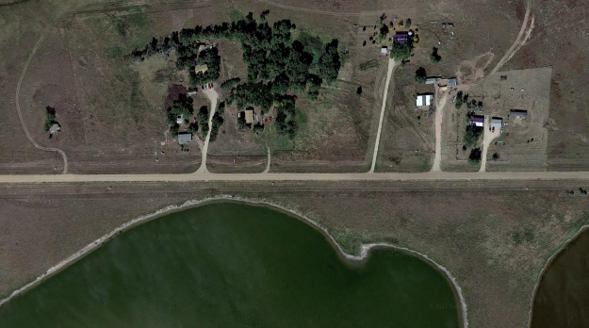


Art Alley
File: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/art alley.jpg
Exists: True
Dimensions: (1920, 837)


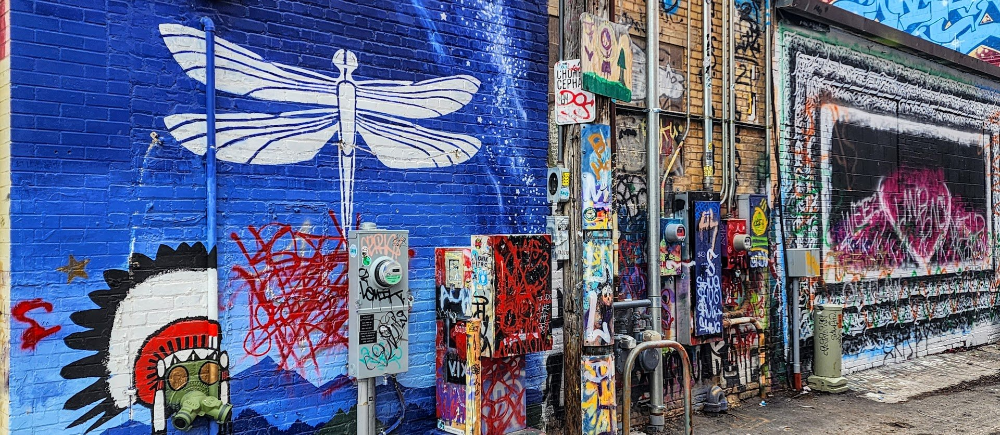

In [65]:

from pathlib import Path
from PIL import Image
from IPython.display import display

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

images = {
    "Wakpamni Aerial": PROJECT / "aerial image of wakpamni.png",
    "Art Alley": PROJECT / "art alley.jpg",
}

for label, path in images.items():
    print(f"\n{label}")
    print("File:", path)
    print("Exists:", path.is_file())

    if path.is_file():
        with Image.open(path) as im:
            print("Dimensions:", im.size)
            display(im.copy())


In [66]:
%pip install reportlab pillow pandas

Note: you may need to restart the kernel to use updated packages.


In [67]:

# ============================================================
# ATE MAKOCE — PRINTABLE SCIENTIFIC ATLAS
# 11 x 8.5 inch landscape | 26 individual book pages
# Mirrored binding margins | PDF with editable text objects
# Safe: reads source files, creates a NEW output folder
# ============================================================

from pathlib import Path
from datetime import datetime
from PIL import Image, ImageOps
from reportlab.pdfgen import canvas
from reportlab.lib.colors import HexColor
from reportlab.lib.utils import ImageReader
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont
import pandas as pd
import hashlib
import textwrap
import subprocess

ROOT = (
    Path.home() / "Documents" / "ElishaWakinyanZi-WORK"
    / "datacube_2026" / "ate_makoce_agcube"
)
PACKET = (
    ROOT / "results"
    / "Ate_Makoce_Dissertation_Results_Export"
    / "09_Discussion_Community_Maps"
    / "Ate_Land_Assessment_Packet"
)

WAKPAMNI = ROOT / "aerial image of wakpamni.png"
ART = ROOT / "art alley.jpg"

for p in [WAKPAMNI, ART]:
    if not p.is_file():
        raise FileNotFoundError(p)

# ---------- VERIFIED RESEARCH MAPS ----------

inventory_files = sorted(
    PACKET.glob(
        "Curated_Maps_*/"
        "Ate_Land_Assessment_Packet_Master_Inventory.csv"
    ),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not inventory_files:
    raise FileNotFoundError("Verified map inventory not found.")

df = pd.read_csv(inventory_files[0], dtype=str).fillna("")

def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

MAP_INFO = [
    (
        "ATE_MAP_005", "How Is My Land Doing?",
        "A combined view of several land observations. "
        "The different panels provide complementary evidence "
        "rather than a single measure of land condition.",
        "Which observations match what you have seen?"
    ),
    (
        "ATE_MAP_069", "A View of the Land",
        "Aerial imagery and parcel boundaries help place "
        "the research in its geographic setting.",
        "Which features and places do you recognize?"
    ),
    (
        "ATE_MAP_018", "The Sampling Lattice",
        "The sampling locations organize the observations "
        "used to examine vegetation across the study area.",
        "Where might additional observations be useful?"
    ),
    (
        "ATE_MAP_016", "Vegetation Through Time",
        "Vegetation greenness varies between years. "
        "Rainfall, temperature, seasonal timing, and "
        "land management may all contribute.",
        "Which years do you remember as unusually dry or wet?"
    ),
    (
        "ATE_MAP_073", "Annual Vegetation Change",
        "Comparisons across years help reveal patterns "
        "of increasing and decreasing vegetation greenness.",
        "Where do these changes agree with your experience?"
    ),
    (
        "ATE_MAP_074", "Low Greenness History",
        "Repeated lower greenness identifies areas for "
        "closer examination. It is not, by itself, "
        "evidence of overgrazing.",
        "What conditions might explain these areas?"
    ),
    (
        "ATE_MAP_075", "Change and Persistence",
        "Some vegetation patterns recur, while others "
        "change across the observation period.",
        "Which locations should be visited or discussed?"
    ),
    (
        "ATE_MAP_011", "Vegetation and Land Cover",
        "Vegetation and land-cover observations can "
        "help guide questions about the landscape.",
        "What additional local knowledge would help?"
    ),
]

map_paths = {}

for map_id, *_ in MAP_INFO:
    rows = df[df["Review_ID"] == map_id]
    if len(rows) != 1:
        raise ValueError(f"Expected one inventory row: {map_id}")

    row = rows.iloc[0]
    path = Path(row["Export_Path"]).expanduser().resolve(strict=True)

    if not path.is_relative_to(PACKET.resolve()):
        raise ValueError(f"Map outside curated packet: {path}")

    if row["Status"] != "VERIFIED COPY":
        raise ValueError(f"Map not verified: {map_id}")

    if sha256(path).lower() != row["Export_SHA256"].lower():
        raise ValueError(f"Checksum mismatch: {map_id}")

    with Image.open(path) as im:
        im.verify()

    map_paths[map_id] = path

# ---------- OUTPUT ----------

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUT = PACKET / f"Ate_Makoce_Print_Atlas_{stamp}"
OUT.mkdir(parents=True, exist_ok=False)

PDF = OUT / "Ate_Makoce_Scientific_Atlas_Print_11x8.5.pdf"

# ---------- TYPOGRAPHY ----------

# Use embedded serif fonts if present on the Mac.
font_candidates = [
    (
        "/System/Library/Fonts/Supplemental/Georgia.ttf",
        "/System/Library/Fonts/Supplemental/Georgia Bold.ttf"
    ),
    (
        "/Library/Fonts/Georgia.ttf",
        "/Library/Fonts/Georgia Bold.ttf"
    )
]

SERIF = "Times-Roman"
SERIF_BOLD = "Times-Bold"

for regular, bold in font_candidates:
    if Path(regular).is_file() and Path(bold).is_file():
        try:
            pdfmetrics.registerFont(TTFont("AtlasSerif", regular))
            pdfmetrics.registerFont(TTFont("AtlasSerifBold", bold))
            SERIF = "AtlasSerif"
            SERIF_BOLD = "AtlasSerifBold"
            break
        except Exception:
            pass

SANS = "Helvetica"
SANS_BOLD = "Helvetica-Bold"

NAVY = HexColor("#172D49")
RED = HexColor("#812B38")
INK = HexColor("#34383A")
GRAY = HexColor("#6E7478")
PAPER = HexColor("#F5F3EF")
WHITE = HexColor("#FFFFFF")
RULE = HexColor("#D1D0CA")

W, H = 792, 612  # 11 x 8.5 inches

c = canvas.Canvas(str(PDF), pagesize=(W, H))
c.setTitle("Ate Makoce: An Environmental Atlas")
c.setAuthor("Ate Makoce Community Land Assessment")

page_no = 0
print_quality = []

def start_page():
    global page_no
    page_no += 1
    c.setFillColor(PAPER)
    c.rect(0, 0, W, H, fill=1, stroke=0)

def finish_page():
    c.showPage()

def margins():
    # Even pages = left pages, gutter on right.
    # Odd pages = right pages, gutter on left.
    if page_no % 2 == 0:
        return 48, 70
    return 70, 48

def content_bounds():
    left, right = margins()
    return left, W - right, W - left - right

def draw_lines(text, x, y, max_width,
               font=SERIF, size=15, leading=23,
               color=INK):
    c.setFont(font, size)
    c.setFillColor(color)

    words = text.split()
    lines = []
    line = ""

    for word in words:
        candidate = (line + " " + word).strip()
        if pdfmetrics.stringWidth(
            candidate, font, size
        ) <= max_width:
            line = candidate
        else:
            if line:
                lines.append(line)
            line = word

    if line:
        lines.append(line)

    for item in lines:
        c.drawString(x, y, item)
        y -= leading

    return y

def rule(y, color=RULE):
    left, right, width = content_bounds()
    c.setStrokeColor(color)
    c.setLineWidth(0.8)
    c.line(left, y, left + width, y)

def heading(title, y=520, size=31, color=NAVY):
    left, right, width = content_bounds()
    return draw_lines(
        title, left, y, width,
        font=SERIF_BOLD, size=size,
        leading=size+8, color=color
    )

def image_fit(path, x, y, box_w, box_h):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im)
        iw, ih = im.size
        im = im.convert("RGB")

        scale = min(box_w / iw, box_h / ih)
        dw, dh = iw * scale, ih * scale
        px = x + (box_w - dw) / 2
        py = y + (box_h - dh) / 2

        c.drawImage(
            ImageReader(im),
            px, py,
            width=dw, height=dh
        )

    return round(iw / (dw / 72), 1)

def section_label(text, y):
    left, right, width = content_bounds()
    c.setFont(SANS_BOLD, 10)
    c.setFillColor(RED)
    c.drawString(left, y, text.upper())

def notes_lines(y, count=3):
    left, right, width = content_bounds()
    c.setStrokeColor(RULE)
    for i in range(count):
        yy = y - i*33
        if yy > 42:
            c.line(left, yy, left+width, yy)

# 1 — COVER
start_page()
image_fit(WAKPAMNI, 0, 0, W, H)

# Opaque editorial title panel for readability
c.setFillColor(PAPER)
c.rect(0, 0, W, 180, fill=1, stroke=0)

c.setFillColor(RED)
c.setFont(SANS_BOLD, 12)
c.drawString(54, 150, "ATE MAKOCE")

c.setFillColor(NAVY)
c.setFont(SERIF_BOLD, 31)
c.drawString(54, 106, "An Environmental Atlas")

c.setFillColor(INK)
c.setFont(SERIF, 16)
c.drawString(
    54, 72,
    "Land and Vegetation Change | 2015-2023"
)
c.setFont(SANS, 10)
c.drawString(54, 43, "Wakpamni | Pine Ridge Indian Reservation")
finish_page()

# 2 — TITLE PAGE
start_page()
section_label("Community Land Assessment", 520)
heading("Ate Makoce", 453, 46)

left, right, width = content_bounds()
draw_lines(
    "An Environmental Atlas of Land and Vegetation Change",
    left, 380, width-50,
    SERIF, 23, 31, NAVY
)

rule(310, RED)

draw_lines(
    "Prepared as a research and discussion resource "
    "for the Tribal landowner.",
    left, 270, width-70,
    SERIF, 17, 26
)

draw_lines(
    "Environmental Data Cube for Oglala Lakota",
    left, 105, width,
    SANS, 12, 17, GRAY
)
finish_page()

# 3 — INTRODUCTION
start_page()
section_label("Introduction", 545)
heading("Reading the Land", 495)

left, right, width = content_bounds()
y = 400

for paragraph in [
    "This atlas brings together satellite observations, "
    "maps, and photographs to examine patterns in "
    "vegetation and land cover.",

    "The maps are offered as a starting point for "
    "conversation, not as a replacement for knowledge "
    "held by people who know the land.",

    "A satellite can help us see patterns across years. "
    "Understanding why those patterns occur requires "
    "local experience, field observations, and care."
]:
    y = draw_lines(
        paragraph, left, y, width-30,
        SERIF, 17, 27
    ) - 30

finish_page()

# 4 — ART ALLEY PHOTOGRAPH
start_page()
section_label("Art and Place", 554)
heading("Art Alley", 518, 31)

left, right, width = content_bounds()
image_fit(ART, left, 105, width, 360)

draw_lines(
    "Photograph supplied for this atlas. "
    "Artwork, artist, and location credits require confirmation.",
    left, 78, width,
    SANS, 10, 15, GRAY
)
finish_page()

# 5 — DATA SOVEREIGNTY
start_page()
section_label("Research Ethics", 545)
heading("Our Land. Our Knowledge. Our Data.", 497, 29)

left, right, width = content_bounds()
y = 401

for paragraph in [
    "Tribal Data Sovereignty recognizes the right of "
    "Tribal Nations to govern data about their lands, "
    "communities, and resources.",

    "That includes decisions about how information "
    "is collected, interpreted, stored, shared, and used.",

    "Satellite imagery is one source of information. "
    "Landowner experience, community knowledge, "
    "and Tribal governance are essential to how "
    "research findings are understood and shared."
]:
    y = draw_lines(
        paragraph, left, y, width-30,
        SERIF, 16, 25
    ) - 24

finish_page()

# 6 — HOW TO READ THE ATLAS
start_page()
section_label("Guide to the Atlas", 545)
heading("What the Maps Can Tell Us", 497, 31)

left, right, width = content_bounds()
y = 405

for paragraph in [
    "These maps summarize observations of vegetation "
    "and land cover. Read each map alongside its "
    "original legend and classification.",

    "Greenness is not the same as grazing condition. "
    "Lower greenness may be influenced by drought, "
    "seasonality, soil conditions, or other factors.",

    "The facing pages offer interpretations and questions "
    "to discuss with the landowner. They are not "
    "definitive conclusions about land management."
]:
    y = draw_lines(
        paragraph, left, y, width-30,
        SERIF, 16, 25
    ) - 26

finish_page()

# 7 — ATLAS SECTION OPENING
start_page()
section_label("Part III", 520)
heading("The Research Atlas", 438, 43)

left, right, width = content_bounds()
rule(360, RED)

draw_lines(
    "Eight maps of land, vegetation, and change over time.",
    left, 322, width-30,
    SERIF, 20, 30, INK
)

draw_lines(
    "Each map is paired with an interpretation "
    "and a question for discussion.",
    left, 242, width-40,
    SERIF, 17, 27
)
finish_page()

# 8-23 — EIGHT FACING MAP / INTERPRETATION PAIRS
for i, (map_id, title, interpretation, question) in enumerate(
    MAP_INFO, start=1
):
    # LEFT PAGE: SCIENTIFIC MAP
    start_page()
    left, right, width = content_bounds()

    section_label(f"Plate {i:02d}", 557)
    heading(title, 524, 25)
    rule(478)

    ppi = image_fit(
        map_paths[map_id],
        left, 42, width, 418
    )

    print_quality.append({
        "Map": map_id,
        "Effective_PPI": ppi,
        "Source": str(map_paths[map_id]),
        "Review": (
            "Inspect at actual print size"
            if ppi < 200 else "Resolution generally suitable"
        )
    })
    finish_page()

    # RIGHT PAGE: INTERPRETATION
    start_page()
    left, right, width = content_bounds()

    section_label(f"Plate {i:02d} | Interpretation", 548)
    heading(title, 504, 29)
    rule(446, RED)

    c.setFont(SANS_BOLD, 11)
    c.setFillColor(NAVY)
    c.drawString(left, 404, "READING THE MAP")

    y = draw_lines(
        interpretation, left, 366, width-25,
        SERIF, 18, 28
    )

    c.setFont(SANS_BOLD, 11)
    c.setFillColor(RED)
    c.drawString(left, y-42, "FOR DISCUSSION")

    y = draw_lines(
        question, left, y-78, width-25,
        SERIF, 18, 28
    )

    c.setFont(SANS_BOLD, 10)
    c.setFillColor(NAVY)
    c.drawString(left, 166, "LANDOWNER OBSERVATIONS")
    notes_lines(133, 3)
    finish_page()

# 24 — RESEARCH CAUTIONS
start_page()
section_label("Interpretation", 545)
heading("What Remains to Be Learned", 497, 31)

left, right, width = content_bounds()
y = 401

for paragraph in [
    "Satellite observations can reveal patterns that "
    "may deserve closer examination.",

    "They cannot, by themselves, establish the cause "
    "of a change or determine whether grazing practices "
    "are sustainable.",

    "Field observations, weather records, and knowledge "
    "of land use are needed to interpret the maps.",

    "Decisions about further analysis and sharing "
    "should follow appropriate landowner and "
    "Tribal data-governance processes."
]:
    y = draw_lines(
        paragraph, left, y, width-25,
        SERIF, 16, 24
    ) - 19

finish_page()

# 25 — NOTES
start_page()
section_label("Field Notes", 545)
heading("Observations and Questions", 499, 31)

left, right, width = content_bounds()
draw_lines(
    "What should we look at together next?",
    left, 431, width-20,
    SERIF, 18, 26
)
notes_lines(368, 9)
finish_page()

# 26 — BACK COVER
start_page()
left, right, width = content_bounds()

rule(453, RED)
heading("Ate Makoce", 416, 37)

draw_lines(
    "An Environmental Atlas of Land and Vegetation Change",
    left, 346, width-35,
    SERIF, 19, 29, NAVY
)

draw_lines(
    "A resource for observation, discussion, "
    "and continued learning about the land.",
    left, 252, width-40,
    SERIF, 16, 25
)

draw_lines(
    "Environmental Data Cube for Oglala Lakota",
    left, 95, width,
    SANS, 11, 16, GRAY
)
finish_page()

c.save()

# ---------- PRINT QUALITY REPORT ----------

report = pd.DataFrame(print_quality)
report.to_csv(
    OUT / "Map_Print_Resolution_Review.csv",
    index=False
)

(OUT / "PRINTING_INSTRUCTIONS.txt").write_text(
    "ATE MAKOCE — PRINTING INSTRUCTIONS\n\n"
    "Page size: US Letter, landscape (11 x 8.5 inches)\n"
    "Pages: 26\n"
    "Print: Actual Size / 100%, not Fit to Page\n"
    "Duplex: Flip on SHORT edge for landscape pages\n"
    "Binding: Spiral, comb, binder, or Japanese stab binding\n"
    "Margins: Mirrored with extra space at the inner edge\n"
    "Paper: 28-32 lb matte text; heavier cardstock for covers\n"
    "Print a two-sided test sheet before printing the full book.\n"
    "The PDF is in reading order, NOT folded-signature order.\n"
    "For saddle stitching, booklet imposition and a page count "
    "divisible by four are required.\n"
    "Review original map titles, photo credits, resolution, "
    "and sharing permissions before distribution.\n",
    encoding="utf-8"
)

print(f"Created {page_no} printable pages")
print(f"PDF: {PDF}")
print(f"Output folder: {OUT}")
print("\nMap print-resolution review:")
display(report[["Map", "Effective_PPI", "Review"]])

subprocess.run(["open", str(PDF)], check=True)


Created 26 printable pages
PDF: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Ate_Makoce_Print_Atlas_20261017_003545_686373/Ate_Makoce_Scientific_Atlas_Print_11x8.5.pdf
Output folder: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Ate_Makoce_Print_Atlas_20261017_003545_686373

Map print-resolution review:


,Map,Effective_PPI,Review
0,ATE_MAP_005,853.3,Resolution generally suitable
1,ATE_MAP_069,569.6,Resolution generally suitable
2,ATE_MAP_018,504.9,Resolution generally suitable
3,ATE_MAP_016,898.8,Resolution generally suitable
4,ATE_MAP_073,936.7,Resolution generally suitable
5,ATE_MAP_074,936.7,Resolution generally suitable
6,ATE_MAP_075,501.4,Resolution generally suitable
7,ATE_MAP_011,557.3,Resolution generally suitable


CompletedProcess(args=['open', '/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Ate_Makoce_Print_Atlas_20261017_003545_686373/Ate_Makoce_Scientific_Atlas_Print_11x8.5.pdf'], returncode=0)

In [68]:

# ================================================================
# SA 19AN — ATE MAKOCE SCIENTIFIC ATLAS
#
# 26-page, 11 x 8.5 inch landscape research atlas
# White pages | Navy and oxblood editorial typography
# Full-page maps | Full-bleed photography
# Detailed interpretations | Landowner reflection space
# Japanese four-hole stab binding | Fixed left gutter
#
# READ-ONLY INPUTS:
#   - 8 checksum-verified curated PNG maps
#   - aerial image of wakpamni.png
#   - art alley.jpg
#
# OUTPUTS: NEW timestamped folder only.
# No original maps, photos, notebooks, or data are modified.
# ================================================================

from pathlib import Path
from datetime import datetime
import hashlib
import csv
import subprocess

import pandas as pd
from PIL import Image, ImageOps

from reportlab.pdfgen import canvas
from reportlab.lib.colors import HexColor
from reportlab.lib.utils import ImageReader
from reportlab.lib.styles import ParagraphStyle
from reportlab.platypus import Paragraph
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont

# ------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------

PROJECT = (
    Path.home()
    / "Documents"
    / "ElishaWakinyanZi-WORK"
    / "datacube_2026"
    / "ate_makoce_agcube"
)

PACKET = (
    PROJECT
    / "results"
    / "Ate_Makoce_Dissertation_Results_Export"
    / "09_Discussion_Community_Maps"
    / "Ate_Land_Assessment_Packet"
)

WAKPAMNI = PROJECT / "aerial image of wakpamni.png"
ART_ALLEY = PROJECT / "art alley.jpg"

for photo in (WAKPAMNI, ART_ALLEY):
    if not photo.is_file():
        raise FileNotFoundError(
            f"Required photograph not found:\n{photo}"
        )
    with Image.open(photo) as im:
        im.verify()

if not PACKET.is_dir():
    raise FileNotFoundError(
        f"Atlas packet folder not found:\n{PACKET}"
    )

# ------------------------------------------------
# 2. LOCATE AND VERIFY CURATED MAPS
# ------------------------------------------------

inventories = sorted(
    PACKET.glob(
        "Curated_Maps_*/"
        "Ate_Land_Assessment_Packet_Master_Inventory.csv"
    ),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not inventories:
    raise FileNotFoundError(
        "No curated map inventory was found."
    )

inventory_path = inventories[0]
inventory = pd.read_csv(
    inventory_path, dtype=str
).fillna("")

required_columns = {
    "Review_ID",
    "Export_Path",
    "Export_SHA256",
    "Status"
}

if not required_columns.issubset(inventory.columns):
    raise ValueError(
        "Curated inventory is missing required columns."
    )

def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(
            lambda: stream.read(1024 * 1024), b""
        ):
            digest.update(chunk)
    return digest.hexdigest()

# ------------------------------------------------
# 3. PLATE CONTENT
#
# Educational explanations are grounded in the
# known study design and remote-sensing methods.
#
# These are NOT claims that particular map locations
# have been confirmed as degraded or overgrazed.
# ------------------------------------------------

PLATES = [
    {
        "id": "ATE_MAP_005",
        "title": "How Is My Land Doing?",
        "measure": (
            "This overview presents several environmental "
            "observations together. Each panel represents "
            "a different view of the landscape. Read the "
            "individual panel titles, legends, and units "
            "before comparing them."
        ),
        "finding": (
            "The value of this overview is in comparing "
            "evidence. A place that stands out in one panel "
            "can be examined in the others to see whether "
            "the observations agree, differ, or describe "
            "different environmental processes."
        ),
        "meaning": (
            "No single satellite indicator can define the "
            "overall health of rangeland. Vegetation, soil, "
            "weather, and land-use history must be considered "
            "together. This overview helps organize those "
            "questions rather than produce one final rating."
        ),
        "question": (
            "Which observations agree with what you know "
            "about the land? Which deserve another look?"
        )
    },
    {
        "id": "ATE_MAP_069",
        "title": "A View of the Land",
        "measure": (
            "This plate places the study area in its "
            "geographic setting using imagery and a mapped "
            "boundary. The image shows visible surface "
            "features at the time it was collected."
        ),
        "finding": (
            "The mapped boundary helps locate the research "
            "area relative to its surroundings. Roads, "
            "drainages, vegetation patterns, and other "
            "visible features may help orient a reader, "
            "depending on the image resolution."
        ),
        "meaning": (
            "A parcel boundary is a geographic reference, "
            "not necessarily a feature visible on the "
            "ground. Imagery also cannot reveal every "
            "important land-use history, cultural "
            "relationship, or seasonal condition."
        ),
        "question": (
            "What features do you recognize? What important "
            "places or histories are missing from this view?"
        )
    },
    {
        "id": "ATE_MAP_018",
        "title": "The Sampling Lattice",
        "measure": (
            "The Wanzi study uses a lattice of 15 sampling "
            "points arranged across the parcel. These "
            "locations provide a consistent spatial "
            "framework for comparing vegetation observations."
        ),
        "finding": (
            "The point locations show where the analysis "
            "is organized. Repeated observations at these "
            "locations can help compare vegetation behavior "
            "through time without changing the sampling "
            "framework from year to year."
        ),
        "meaning": (
            "Fifteen points do not describe every square "
            "meter of the parcel. Conditions between points "
            "may differ because of soils, slope, moisture, "
            "vegetation communities, and land-use patterns. "
            "The lattice is a sampling strategy, not a "
            "complete field survey."
        ),
        "question": (
            "Are these points representative? Where would "
            "you add field observations, and why?"
        )
    },
    {
        "id": "ATE_MAP_016",
        "title": "Vegetation Through Time",
        "measure": (
            "The vegetation atlas compares observations "
            "across the 2015–2023 study period. NDVI, the "
            "Normalized Difference Vegetation Index, uses "
            "red and near-infrared reflected light to "
            "describe vegetation greenness."
        ),
        "finding": (
            "Comparing annual maps helps reveal how the "
            "spatial pattern of greenness varies between "
            "years. Areas that appear greener in one year "
            "may appear less green in another. The legend "
            "and image dates determine the precise "
            "interpretation of those differences."
        ),
        "meaning": (
            "Greenness responds to precipitation, "
            "temperature, plant growth, and observation "
            "timing. Lower NDVI during a dry period does "
            "not automatically indicate harmful grazing. "
            "NDVI also does not directly measure plant "
            "species, forage quality, or soil health."
        ),
        "question": (
            "Which years were especially wet or dry? "
            "Do the vegetation patterns reflect your "
            "memories of those seasons?"
        )
    },
    {
        "id": "ATE_MAP_073",
        "title": "Annual Vegetation Change",
        "measure": (
            "Vegetation change analysis compares NDVI "
            "measurements across different time periods. "
            "Depending on the map calculation, differences "
            "may represent an increase, decrease, or "
            "relatively small change in greenness."
        ),
        "finding": (
            "The mapped change categories help locate "
            "places where satellite-measured vegetation "
            "greenness differs between observations. "
            "The direction and size of each change must "
            "be read from this plate's actual legend "
            "and comparison dates."
        ),
        "meaning": (
            "A negative change is not necessarily permanent "
            "vegetation loss. Weather, seasonal timing, "
            "plant phenology, and land use can influence "
            "NDVI. A meaningful interpretation asks whether "
            "a change persists and what independent "
            "observations can explain it."
        ),
        "question": (
            "Where have you noticed vegetation changing? "
            "Were those changes temporary or long-lasting?"
        )
    },
    {
        "id": "ATE_MAP_074",
        "title": "Low Greenness History",
        "measure": (
            "This analysis examines the history of "
            "relatively low vegetation greenness. "
            "The mapped categories should be interpreted "
            "using the thresholds and frequency definitions "
            "in the original figure."
        ),
        "finding": (
            "The map is intended to distinguish places "
            "where low-greenness observations recur from "
            "places where they occur less frequently. "
            "Recurring patterns can help identify locations "
            "for closer investigation."
        ),
        "meaning": (
            "Low greenness may be associated with dry "
            "conditions, exposed soil, naturally sparse "
            "plant cover, different vegetation communities, "
            "or land use. It is not a direct measure of "
            "grazing intensity or proof of degradation."
        ),
        "question": (
            "Are these places naturally sparse or dry? "
            "Have you observed changes in plant cover, "
            "soil exposure, or water availability?"
        )
    },
    {
        "id": "ATE_MAP_075",
        "title": "Change and Persistence",
        "measure": (
            "This plate considers how vegetation patterns "
            "change or recur through time. Persistence "
            "refers to a pattern appearing repeatedly "
            "within the mapped observations."
        ),
        "finding": (
            "Comparing persistent and changing patterns "
            "helps organize questions about where "
            "vegetation behaves consistently and where "
            "conditions may be more variable."
        ),
        "meaning": (
            "Repeated NDVI values do not necessarily mean "
            "that plant species, forage condition, or soil "
            "properties remained unchanged. Persistence "
            "in a satellite index is not identical to "
            "ecological stability or resilience."
        ),
        "question": (
            "Which areas recover after dry years? "
            "Where have you seen changes that a satellite "
            "might not detect?"
        )
    },
    {
        "id": "ATE_MAP_011",
        "title": "Vegetation and Land Cover",
        "measure": (
            "This plate brings together vegetation-change "
            "information and land-cover observations. "
            "Land cover describes mapped surface categories; "
            "NDVI describes vegetation greenness."
        ),
        "finding": (
            "Examining these measurements together can "
            "help identify where vegetation-change "
            "patterns occur in different landscape "
            "settings. Interpretation depends on the "
            "map's classes, dates, and classification "
            "accuracy."
        ),
        "meaning": (
            "Land-cover classifications contain uncertainty, "
            "and vegetation decline alone cannot establish "
            "its cause. Field observations and land-use "
            "history are needed before drawing conclusions "
            "about grazing impacts or land degradation."
        ),
        "question": (
            "What do you know about the soils, vegetation, "
            "water, and land-use history of these locations?"
        )
    }
]

map_paths = {}

for plate in PLATES:
    map_id = plate["id"]
    matches = inventory[
        inventory["Review_ID"] == map_id
    ]

    if len(matches) != 1:
        raise ValueError(
            f"Expected exactly one map for {map_id}"
        )

    row = matches.iloc[0]

    if row["Status"] != "VERIFIED COPY":
        raise ValueError(
            f"Map is not a verified copy: {map_id}"
        )

    path = (
        Path(row["Export_Path"])
        .expanduser()
        .resolve(strict=True)
    )

    if not path.is_relative_to(PACKET.resolve()):
        raise ValueError(
            f"Unexpected map location: {path}"
        )

    if path.suffix.lower() != ".png":
        raise ValueError(
            f"Expected a PNG for {map_id}"
        )

    if sha256(path).lower() != (
        row["Export_SHA256"].lower()
    ):
        raise ValueError(
            f"Checksum mismatch: {map_id}"
        )

    with Image.open(path) as im:
        im.verify()

    map_paths[map_id] = path

# ------------------------------------------------
# 4. CREATE A NEW OUTPUT FOLDER
# ------------------------------------------------

stamp = datetime.now().strftime(
    "%Y%m%d_%H%M%S_%f"
)

OUT = PACKET / (
    f"Ate_Makoce_Scientific_Atlas_{stamp}"
)

OUT.mkdir(parents=True, exist_ok=False)

ATLAS_PDF = (
    OUT / "Ate_Makoce_Scientific_Atlas_Print.pdf"
)

BINDING_PDF = (
    OUT / "Japanese_Stab_Binding_Hole_Guide.pdf"
)

REPORT_CSV = (
    OUT / "Atlas_Map_Print_Resolution.csv"
)

NOTES_TXT = (
    OUT / "Printing_and_Review_Notes.txt"
)

# ------------------------------------------------
# 5. PAGE DESIGN
# ------------------------------------------------

W = 11 * 72
H = 8.5 * 72

NAVY = HexColor("#172D49")
OXBLOOD = HexColor("#812B38")
CHARCOAL = HexColor("#34383A")
GRAY = HexColor("#73777A")
LIGHT_RULE = HexColor("#D6D8D9")
WHITE = HexColor("#FFFFFF")

# Fixed LEFT gutter on every page for stab binding.
# 1.35 inches allows for stitching and opening.
GUTTER = 98
OUTER = 25
TOP = 28
BOTTOM = 24

CONTENT_X = GUTTER
CONTENT_W = W - GUTTER - OUTER

# ------------------------------------------------
# 6. FONTS
# ------------------------------------------------

SERIF = "Times-Roman"
SERIF_BOLD = "Times-Bold"

font_pairs = [
    (
        "/System/Library/Fonts/Supplemental/Georgia.ttf",
        "/System/Library/Fonts/Supplemental/Georgia Bold.ttf"
    ),
    (
        "/Library/Fonts/Georgia.ttf",
        "/Library/Fonts/Georgia Bold.ttf"
    )
]

for regular, bold in font_pairs:
    if (
        Path(regular).is_file()
        and Path(bold).is_file()
    ):
        try:
            pdfmetrics.registerFont(
                TTFont("AteGeorgia", regular)
            )
            pdfmetrics.registerFont(
                TTFont("AteGeorgiaBold", bold)
            )
            SERIF = "AteGeorgia"
            SERIF_BOLD = "AteGeorgiaBold"
            break
        except Exception:
            continue

SANS = "Helvetica"
SANS_BOLD = "Helvetica-Bold"

# ------------------------------------------------
# 7. PDF HELPERS
# ------------------------------------------------

c = canvas.Canvas(
    str(ATLAS_PDF),
    pagesize=(W, H),
    pageCompression=1
)

c.setTitle(
    "Ate Makoce: An Environmental Atlas "
    "of Land and Vegetation Change"
)

page_count = 0
print_quality = []

def new_page():
    global page_count
    page_count += 1
    # White PDF background: no ink-filled rectangle.

def end_page():
    c.showPage()

def text_line(
    value, x, y,
    size=12, color=CHARCOAL,
    font=SERIF
):
    c.setFont(font, size)
    c.setFillColor(color)
    c.drawString(x, y, value)

def paragraph(
    value, x, top, width,
    size=12.2, leading=17.2,
    color=CHARCOAL,
    font=None
):
    font = font or SERIF

    style = ParagraphStyle(
        "atlas_body",
        fontName=font,
        fontSize=size,
        leading=leading,
        textColor=color,
        spaceAfter=0,
        allowWidows=0,
        allowOrphans=0
    )

    obj = Paragraph(value, style)
    _, height = obj.wrap(width, H)
    obj.drawOn(c, x, top - height)

    return top - height

def horizontal_rule(y, color=LIGHT_RULE):
    c.setStrokeColor(color)
    c.setLineWidth(0.75)
    c.line(
        CONTENT_X, y,
        CONTENT_X + CONTENT_W, y
    )

def chapter_label(value, y=H-43):
    text_line(
        value.upper(),
        CONTENT_X, y,
        10, OXBLOOD, SANS_BOLD
    )

def page_heading(value, top=H-80, size=29):
    return paragraph(
        value,
        CONTENT_X, top,
        CONTENT_W,
        size=size,
        leading=size+5,
        color=NAVY,
        font=SERIF_BOLD
    )

def draw_image_contain(
    path, x, y, box_w, box_h
):
    """Show the COMPLETE image without cropping."""
    with Image.open(path) as source:
        im = ImageOps.exif_transpose(
            source
        ).convert("RGB")

        iw, ih = im.size

        scale = min(
            box_w / iw,
            box_h / ih
        )

        dw = iw * scale
        dh = ih * scale

        px = x + (box_w-dw)/2
        py = y + (box_h-dh)/2

        c.drawImage(
            ImageReader(im),
            px, py,
            width=dw,
            height=dh
        )

        effective_ppi = iw / (dw / 72)

    return round(effective_ppi, 1)

def draw_image_cover(path):
    """Full-page photograph, cropped only at outer edges."""
    with Image.open(path) as source:
        im = ImageOps.exif_transpose(
            source
        ).convert("RGB")

        iw, ih = im.size

        scale = max(
            W / iw,
            H / ih
        )

        dw = iw * scale
        dh = ih * scale

        x = (W-dw)/2
        y = (H-dh)/2

        c.saveState()
        clip = c.beginPath()
        clip.rect(0, 0, W, H)
        c.clipPath(
            clip, stroke=0, fill=0
        )

        c.drawImage(
            ImageReader(im),
            x, y,
            width=dw,
            height=dh
        )

        c.restoreState()

def notes_lines(y, count=5, spacing=29):
    c.setStrokeColor(LIGHT_RULE)
    c.setLineWidth(0.7)

    for i in range(count):
        yy = y - i*spacing

        if yy >= BOTTOM + 5:
            c.line(
                CONTENT_X, yy,
                CONTENT_X+CONTENT_W, yy
            )

def simple_page(
    label, title, paragraphs,
    size=15, leading=23
):
    new_page()
    chapter_label(label)

    y = page_heading(
        title, top=H-85, size=31
    ) - 30

    for item in paragraphs:
        y = paragraph(
            item,
            CONTENT_X, y,
            CONTENT_W-15,
            size=size,
            leading=leading
        ) - 22

    if y < 38:
        raise ValueError(
            f"Text overflow on page: {title}"
        )

    end_page()

# ------------------------------------------------
# 8. COVER — WAKPAMNI AERIAL
# ------------------------------------------------

new_page()

draw_image_cover(WAKPAMNI)

# A restrained white title band, not a beige panel.
# Keep the actual photograph prominent.
c.setFillColor(WHITE)
c.rect(
    0, 0,
    W, 145,
    stroke=0,
    fill=1
)

text_line(
    "ATE MAKOCE",
    45, 119,
    13, OXBLOOD, SANS_BOLD
)

text_line(
    "An Environmental Atlas",
    45, 76,
    31, NAVY, SERIF_BOLD
)

text_line(
    "Land and Vegetation Change | 2015-2023",
    45, 44,
    15, CHARCOAL, SERIF
)

end_page()

# ------------------------------------------------
# 9. TITLE PAGE
# ------------------------------------------------

simple_page(
    "Community Land Assessment",
    "Ate Makoce",
    [
        "An Environmental Atlas of Land and "
        "Vegetation Change.",

        "Wakpamni | Pine Ridge Indian Reservation "
        "| 2015–2023.",

        "Prepared as a research and discussion "
        "resource for the Tribal landowner.",

        "Environmental Data Cube for Oglala Lakota."
    ],
    size=19,
    leading=29
)

# ------------------------------------------------
# 10. INTRODUCTION
# ------------------------------------------------

simple_page(
    "Part I | The Land",
    "Reading the Land Together",
    [
        "This atlas brings together satellite observations, "
        "environmental measurements, and maps to examine "
        "patterns of vegetation and land cover.",

        "The maps offer one way of seeing the land across "
        "space and time. They do not replace the experience "
        "of people who know the land through seasons, "
        "weather, work, and everyday observation.",

        "The purpose of this book is to share what the "
        "research can tell us, explain its limitations, "
        "and create space for the landowner's questions "
        "and knowledge."
    ],
    size=16,
    leading=25
)

# ------------------------------------------------
# 11. ART ALLEY — FULL-PAGE PHOTO
# ------------------------------------------------

new_page()
draw_image_cover(ART_ALLEY)
end_page()

# ------------------------------------------------
# 12. TRIBAL DATA SOVEREIGNTY
# ------------------------------------------------

simple_page(
    "Part II | Research and Responsibility",
    "Our Land. Our Knowledge. Our Data.",
    [
        "Tribal Data Sovereignty recognizes the right "
        "of Tribal Nations to govern information about "
        "their lands, communities, and resources.",

        "This includes decisions about how information "
        "is collected, interpreted, stored, shared, "
        "and used.",

        "Satellite observations are only one source "
        "of knowledge. Community experience, relationships "
        "with the land, and Tribal governance are essential "
        "to understanding and responsibly sharing research.",

        "This atlas is intended for landowner review and "
        "conversation. Broader distribution of parcel-level "
        "information should follow appropriate permissions "
        "and Tribal data-governance processes."
    ],
    size=14.7,
    leading=22
)

# ------------------------------------------------
# 13. GUIDE TO THE MAPS
# ------------------------------------------------

simple_page(
    "A Guide to the Research",
    "How to Read These Maps",
    [
        "Each plate shows a research figure at the largest "
        "size possible without cropping its legend or labels. "
        "The following page explains what was measured, "
        "what the analysis helps reveal, and how to interpret "
        "the evidence.",

        "NDVI, or the Normalized Difference Vegetation Index, "
        "describes vegetation greenness using reflected red "
        "and near-infrared light. It is useful for comparing "
        "vegetation patterns but is not a direct measurement "
        "of grazing intensity or soil health.",

        "Climate, seasonality, vegetation type, and image "
        "dates all influence interpretation. Differences "
        "in greenness do not, by themselves, establish "
        "overgrazing or land degradation.",

        "The landowner's observations are part of the "
        "interpretive process, not simply an addition "
        "after the research is finished."
    ],
    size=14.4,
    leading=21
)

# ------------------------------------------------
# 14. ATLAS SECTION OPENER
# ------------------------------------------------

simple_page(
    "Part III | The Research Atlas",
    "Eight Views of the Land",
    [
        "The following plates examine geographic context, "
        "sampling locations, vegetation greenness, "
        "change through time, and land-cover patterns.",

        "Each scientific map occupies its own page. "
        "Its facing page provides an educational "
        "interpretation and space for landowner observations.",

        "Read the map legends carefully. The explanatory "
        "text describes what the analysis can support "
        "without assigning causes that have not been "
        "independently verified."
    ],
    size=17,
    leading=26
)

# ------------------------------------------------
# 15. EIGHT FULL-PAGE MAPS + INTERPRETATION PAGES
#
# Pages 8-23:
# Even page = full-page map (left in book)
# Odd page  = facing interpretation (right)
# ------------------------------------------------

for index, plate in enumerate(PLATES, start=1):

    # --------------------------------------------
    # MAP PAGE — NO TITLE OR CAPTION OVER THE MAP
    # --------------------------------------------

    new_page()

    map_path = map_paths[plate["id"]]

    ppi = draw_image_contain(
        map_path,
        x=GUTTER,
        y=12,
        box_w=W-GUTTER-12,
        box_h=H-24
    )

    print_quality.append({
        "Plate": index,
        "Map_ID": plate["id"],
        "Effective_PPI": ppi,
        "Resolution_Review": (
            "Check carefully at print size"
            if ppi < 200
            else "Generally suitable; inspect labels"
        ),
        "Original_Map": str(map_path)
    })

    end_page()

    # --------------------------------------------
    # FACING PAGE — SCIENTIFIC INTERPRETATION
    # --------------------------------------------

    new_page()

    chapter_label(
        f"Plate {index:02d} | Scientific Interpretation"
    )

    y = page_heading(
        plate["title"],
        top=H-73,
        size=27
    ) - 12

    horizontal_rule(y, OXBLOOD)
    y -= 24

    sections = [
        (
            "WHAT ARE WE MEASURING?",
            plate["measure"]
        ),
        (
            "WHAT DOES THE ANALYSIS REVEAL?",
            plate["finding"]
        ),
        (
            "WHY DOES IT MATTER?",
            plate["meaning"]
        ),
        (
            "A QUESTION FOR THE LANDOWNER",
            plate["question"]
        )
    ]

    for section_title, body in sections:
        text_line(
            section_title,
            CONTENT_X, y,
            9.5,
            OXBLOOD if "QUESTION" in section_title else NAVY,
            SANS_BOLD
        )

        y -= 9

        y = paragraph(
            body,
            CONTENT_X,
            y,
            CONTENT_W-8,
            size=11.4,
            leading=15.4
        ) - 17

    # Observation area dynamically uses remaining space.
    # Keep enough for at least three ruled lines.
    observation_title_y = y - 2

    if observation_title_y < 112:
        raise ValueError(
            "Interpretation page too crowded: "
            f"{plate['id']}. "
            "Reduce body font slightly or use "
            "a separate observations page."
        )

    text_line(
        "LANDOWNER OBSERVATIONS",
        CONTENT_X,
        observation_title_y,
        9.5,
        NAVY,
        SANS_BOLD
    )

    available_height = observation_title_y - 34 - BOTTOM
    line_count = max(
        3,
        min(6, int(available_height // 24))
    )

    notes_lines(
        observation_title_y-28,
        count=line_count,
        spacing=24
    )

    end_page()

# ------------------------------------------------
# 16. RESEARCH LIMITATIONS
# ------------------------------------------------

simple_page(
    "Part IV | Interpretation",
    "What Satellites Cannot See",
    [
        "Satellites help reveal patterns in vegetation "
        "greenness, but they cannot directly determine "
        "plant species, forage quality, grazing history, "
        "or the full condition of the soil.",

        "A vegetation index may decrease during drought "
        "even when land management has not changed. "
        "Likewise, similar NDVI values across years "
        "do not guarantee that ecological conditions "
        "have remained the same.",

        "Understanding the causes of change requires "
        "field observations, weather records, vegetation "
        "information, and knowledge of land-use history.",

        "The maps are evidence for asking better questions, "
        "not a final judgment about the land."
    ],
    size=14.7,
    leading=22
)

# ------------------------------------------------
# 17. FULL NOTES PAGE
# ------------------------------------------------

new_page()

chapter_label(
    "Field Notes | Landowner Observations"
)

y = page_heading(
    "Observations and Questions",
    top=H-85,
    size=31
) - 24

y = paragraph(
    "What have you noticed about this land? "
    "What should we examine together next?",
    CONTENT_X,
    y,
    CONTENT_W,
    size=16,
    leading=23
) - 30

notes_lines(
    y,
    count=12,
    spacing=29
)

end_page()

# ------------------------------------------------
# 18. BACK COVER
# ------------------------------------------------

new_page()

horizontal_rule(H-120, OXBLOOD)

page_heading(
    "Ate Makoce",
    top=H-160,
    size=40
)

paragraph(
    "An Environmental Atlas of Land "
    "and Vegetation Change",
    CONTENT_X,
    H-245,
    CONTENT_W,
    size=20,
    leading=29,
    color=NAVY
)

paragraph(
    "A research resource for observation, "
    "discussion, and continued learning "
    "about the land.",
    CONTENT_X,
    H-360,
    CONTENT_W-35,
    size=16,
    leading=24
)

text_line(
    "Environmental Data Cube for Oglala Lakota",
    CONTENT_X,
    75,
    11,
    GRAY,
    SANS
)

end_page()

c.save()

assert page_count == 26, (
    f"Expected 26 pages; created {page_count}"
)

# ------------------------------------------------
# 19. FOUR-HOLE JAPANESE STAB-BINDING GUIDE
#
# A separate 11 x 8.5 inch template.
# Print at ACTUAL SIZE.
# Use the guide to mark holes in the covers/pages.
# Do not add holes to the atlas PDF itself.
# ------------------------------------------------

guide = canvas.Canvas(
    str(BINDING_PDF),
    pagesize=(W, H)
)

guide.setTitle(
    "Ate Makoce — Japanese Stab Binding Hole Guide"
)

# Hole center 0.55 inch from left edge.
HOLE_X = 0.55 * 72

# Four evenly spaced holes, inset 0.85 inch
# from the top and bottom edges.
HOLE_INSET = 0.85 * 72

hole_ys = [
    HOLE_INSET + i * (
        (H - 2*HOLE_INSET) / 3
    )
    for i in range(4)
]

guide.setStrokeColor(NAVY)
guide.setLineWidth(0.9)

for yy in hole_ys:
    guide.circle(
        HOLE_X, yy,
        3.5,
        stroke=1,
        fill=0
    )

guide.setStrokeColor(OXBLOOD)
guide.setDash(3, 3)
guide.line(
    GUTTER, 0,
    GUTTER, H
)
guide.setDash()

guide.setFillColor(NAVY)
guide.setFont("Helvetica-Bold", 18)
guide.drawString(
    125, H-85,
    "ATE MAKOCE — BINDING GUIDE"
)

guide.setFont("Helvetica", 12)

guide.drawString(
    125, H-120,
    "11 x 8.5 inches | Landscape | Four-hole stab binding"
)

guide.drawString(
    125, H-155,
    "Hole centers: 0.55 inch from the left edge"
)

guide.drawString(
    125, H-185,
    "First and last holes: 0.85 inch from page ends"
)

guide.drawString(
    125, H-215,
    "Dashed line: 1.36-inch content-safe boundary"
)

guide.drawString(
    125, H-270,
    "Print at 100% / Actual Size. Do not scale."
)

guide.drawString(
    125, H-300,
    "Use as a marking guide; verify on scrap paper first."
)

guide.drawString(
    125, H-330,
    "Punch small stacks, then align all pages before sewing."
)

guide.showPage()
guide.save()

# ------------------------------------------------
# 20. RESOLUTION REPORT AND PRINTING NOTES
# ------------------------------------------------

quality_df = pd.DataFrame(print_quality)
quality_df.to_csv(
    REPORT_CSV,
    index=False
)

print_notes = """
ATE MAKOCE — SCIENTIFIC ATLAS
PRINTING AND REVIEW NOTES

FORMAT
- 26 individual pages
- US Letter landscape: 11 x 8.5 inches
- PDF pages are in reading order
- Not arranged for folded signatures

PRINTING
- Print at Actual Size / 100%
- For double-sided landscape printing:
  select Flip on Short Edge
- Test pages 8 and 9 before printing the full atlas
- White pages minimize background ink consumption
- Consider 28–32 lb matte interior paper
- Consider 80–100 lb cover cardstock
- Print photos at high quality if possible

JAPANESE STAB BINDING
- Bind along the LEFT edge of every page
- A fixed 1.36-inch content-safe area is reserved
- Four-hole guide is provided as a separate PDF
- Punch a test stack before punching the entire atlas
- Stab binding will not open completely flat
- Waxed linen thread is recommended
- This is a loose-sheet binding, not saddle stitching

FULL-PAGE IMAGES
- Scientific maps are scaled to fit the largest
  binding-safe rectangle WITHOUT CROPPING
- The entire original PNG and legend are retained
- Photographs fill the page and may be cropped
  at their outer edges
- True edge-to-edge photos require borderless
  printing or oversized sheets and trimming

IMPORTANT REVIEW ITEMS
- Some original map PNGs may contain the
  incorrect embedded spelling 'Ate Macoke'.
  The code does not alter source map imagery.
- Confirm map legends, dates, classifications,
  and observed patterns before distribution.
- The educational interpretation text is
  provisional until compared to actual map content.
- Confirm the Art Alley artwork credit,
  location, and reproduction permission.
- Confirm any additional photographic credits.
- Review parcel-level data sharing with the
  landowner and applicable Tribal governance.
- Inspect every map at physical print size,
  especially multipanel figures and legends.

SOURCE SAFETY
- Original maps and photographs are read only
- No original data cube or notebook is changed
- All outputs are in a new timestamped folder
"""

NOTES_TXT.write_text(
    print_notes.strip() + "\n",
    encoding="utf-8"
)

# ------------------------------------------------
# 21. RESULTS
# ------------------------------------------------

print("=" * 62)
print("ATE MAKOCE SCIENTIFIC ATLAS CREATED")
print("=" * 62)
print(f"\nPages: {page_count}")
print(f"\nAtlas PDF:\n{ATLAS_PDF}")
print(f"\nBinding guide:\n{BINDING_PDF}")
print(f"\nPrint review:\n{REPORT_CSV}")
print(f"\nInstructions:\n{NOTES_TXT}")

print("\nMap resolution review:")
display(
    quality_df[
        ["Plate", "Map_ID",
         "Effective_PPI", "Resolution_Review"]
    ]
)

print(
    "\nOriginal research files were not modified."
)
print(
    "Review all pages and embedded map-title spelling "
    "before sharing."
)

subprocess.run(
    ["open", str(OUT)],
    check=True
)


ATE MAKOCE SCIENTIFIC ATLAS CREATED

Pages: 26

Atlas PDF:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Ate_Makoce_Scientific_Atlas_20261017_004536_658650/Ate_Makoce_Scientific_Atlas_Print.pdf

Binding guide:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Ate_Makoce_Scientific_Atlas_20261017_004536_658650/Japanese_Stab_Binding_Hole_Guide.pdf

Print review:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Ate_Makoce_Scientific_Atlas_20261017_004536_658650/Atlas_Map_Print_Resolution.csv

Instructions:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacub

,Plate,Map_ID,Effective_PPI,Resolution_Review
0,1,ATE_MAP_005,606.6,Generally suitable; inspect labels
1,2,ATE_MAP_069,404.9,Generally suitable; inspect labels
2,3,ATE_MAP_018,498.9,Generally suitable; inspect labels
3,4,ATE_MAP_016,638.9,Generally suitable; inspect labels
4,5,ATE_MAP_073,665.9,Generally suitable; inspect labels
5,6,ATE_MAP_074,665.9,Generally suitable; inspect labels
6,7,ATE_MAP_075,455.9,Generally suitable; inspect labels
7,8,ATE_MAP_011,550.8,Generally suitable; inspect labels



Original research files were not modified.
Review all pages and embedded map-title spelling before sharing.


CompletedProcess(args=['open', '/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Ate_Makoce_Scientific_Atlas_20261017_004536_658650'], returncode=0)

In [69]:

from pathlib import Path
from datetime import datetime
import hashlib
import subprocess
import html

import pandas as pd
from PIL import Image, ImageOps
from IPython.display import display

from reportlab.pdfgen import canvas
from reportlab.lib.colors import HexColor
from reportlab.lib.utils import ImageReader
from reportlab.lib.styles import ParagraphStyle
from reportlab.platypus import Paragraph
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont

# ORIGINAL PROJECT LOCATIONS
PROJECT = (
    Path.home() / "Documents" / "ElishaWakinyanZi-WORK"
    / "datacube_2026" / "ate_makoce_agcube"
)

PACKET = (
    PROJECT / "results"
    / "Ate_Makoce_Dissertation_Results_Export"
    / "09_Discussion_Community_Maps"
    / "Ate_Land_Assessment_Packet"
)

WAKPAMNI = PROJECT / "aerial image of wakpamni.png"
ART_ALLEY = PROJECT / "art alley.jpg"

for path in (WAKPAMNI, ART_ALLEY):
    if not path.is_file():
        raise FileNotFoundError(f"Missing photograph: {path}")
    with Image.open(path) as im:
        im.verify()

if not PACKET.is_dir():
    raise FileNotFoundError(f"Missing packet folder: {PACKET}")

inventories = sorted(
    PACKET.glob(
        "Curated_Maps_*/Ate_Land_Assessment_Packet_Master_Inventory.csv"
    ),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not inventories:
    raise FileNotFoundError("Curated map inventory not found.")

inventory_path = inventories[0]
inventory = pd.read_csv(inventory_path, dtype=str).fillna("")

required = {"Review_ID", "Export_Path", "Export_SHA256", "Status"}
if not required.issubset(inventory.columns):
    raise ValueError("Missing required map inventory columns.")

def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

MAP_IDS = [
    "ATE_MAP_005",
    "ATE_MAP_069",
    "ATE_MAP_018",
    "ATE_MAP_016",
    "ATE_MAP_073",
    "ATE_MAP_074",
    "ATE_MAP_075",
    "ATE_MAP_011",
]

map_paths = {}

for map_id in MAP_IDS:
    matches = inventory[inventory["Review_ID"] == map_id]

    if len(matches) != 1:
        raise ValueError(f"Expected exactly one inventory row: {map_id}")

    row = matches.iloc[0]

    if row["Status"].strip() != "VERIFIED COPY":
        raise ValueError(f"Map not verified: {map_id}")

    raw_path = Path(row["Export_Path"]).expanduser()
    path = raw_path if raw_path.is_absolute() else inventory_path.parent / raw_path
    path = path.resolve(strict=True)

    if not path.is_relative_to(PACKET.resolve()):
        raise ValueError(f"Map outside packet: {map_id}")

    if path.suffix.lower() != ".png":
        raise ValueError(f"Map is not PNG: {map_id}")

    if sha256(path).lower() != row["Export_SHA256"].strip().lower():
        raise ValueError(f"Checksum mismatch: {map_id}")

    with Image.open(path) as im:
        im.verify()

    map_paths[map_id] = path

# PRINT DESIGN
W, H = 11 * 72, 8.5 * 72
GUTTER = 98
OUTER = 25
BOTTOM = 24
CONTENT_X = GUTTER
CONTENT_W = W - GUTTER - OUTER

NAVY = HexColor("#172D49")
OXBLOOD = HexColor("#812B38")
CHARCOAL = HexColor("#34383A")
GRAY = HexColor("#73777A")
LIGHT_RULE = HexColor("#D6D8D9")
WHITE = HexColor("#FFFFFF")

# FONT SELECTION
SERIF = "Times-Roman"
SERIF_BOLD = "Times-Bold"
SANS = "Helvetica"
SANS_BOLD = "Helvetica-Bold"

font_pairs = [
    (
        "/System/Library/Fonts/Supplemental/Georgia.ttf",
        "/System/Library/Fonts/Supplemental/Georgia Bold.ttf"
    ),
    (
        "/Library/Fonts/Georgia.ttf",
        "/Library/Fonts/Georgia Bold.ttf"
    )
]

for regular, bold in font_pairs:
    if Path(regular).is_file() and Path(bold).is_file():
        try:
            pdfmetrics.registerFont(TTFont("AteGeorgia", regular))
            pdfmetrics.registerFont(TTFont("AteGeorgiaBold", bold))
            SERIF = "AteGeorgia"
            SERIF_BOLD = "AteGeorgiaBold"
            break
        except Exception:
            continue

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUT = PACKET / f"Ate_Makoce_Scientific_Atlas_{stamp}"
OUT.mkdir(parents=True, exist_ok=False)

ATLAS_PDF = OUT / "Ate_Makoce_Scientific_Atlas_Print.pdf"
BINDING_PDF = OUT / "Japanese_Stab_Binding_Hole_Guide.pdf"
REPORT_CSV = OUT / "Atlas_Map_Print_Resolution.csv"
NOTES_TXT = OUT / "Printing_and_Review_Notes.txt"

print("All eight maps verified.")
print("Inventory:", inventory_path)
print("Output folder:", OUT)


All eight maps verified.
Inventory: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Curated_Maps_20261016_232442_288275/Ate_Land_Assessment_Packet_Master_Inventory.csv
Output folder: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Ate_Makoce_Scientific_Atlas_20261017_010014_173152


In [70]:

from pathlib import Path
from datetime import datetime
import hashlib
import subprocess
import html

import pandas as pd
from PIL import Image, ImageOps
from IPython.display import display

from reportlab.pdfgen import canvas
from reportlab.lib.colors import HexColor
from reportlab.lib.utils import ImageReader
from reportlab.lib.styles import ParagraphStyle
from reportlab.platypus import Paragraph
from reportlab.pdfbase import pdfmetrics
from reportlab.pdfbase.ttfonts import TTFont

# ORIGINAL PROJECT LOCATIONS
PROJECT = (
    Path.home() / "Documents" / "ElishaWakinyanZi-WORK"
    / "datacube_2026" / "ate_makoce_agcube"
)

PACKET = (
    PROJECT / "results"
    / "Ate_Makoce_Dissertation_Results_Export"
    / "09_Discussion_Community_Maps"
    / "Ate_Land_Assessment_Packet"
)

WAKPAMNI = PROJECT / "aerial image of wakpamni.png"
ART_ALLEY = PROJECT / "art alley.jpg"

for path in (WAKPAMNI, ART_ALLEY):
    if not path.is_file():
        raise FileNotFoundError(f"Missing photograph: {path}")
    with Image.open(path) as im:
        im.verify()

if not PACKET.is_dir():
    raise FileNotFoundError(f"Missing packet folder: {PACKET}")

inventories = sorted(
    PACKET.glob(
        "Curated_Maps_*/Ate_Land_Assessment_Packet_Master_Inventory.csv"
    ),
    key=lambda p: p.stat().st_mtime,
    reverse=True
)

if not inventories:
    raise FileNotFoundError("Curated map inventory not found.")

inventory_path = inventories[0]
inventory = pd.read_csv(inventory_path, dtype=str).fillna("")

required = {"Review_ID", "Export_Path", "Export_SHA256", "Status"}
if not required.issubset(inventory.columns):
    raise ValueError("Missing required map inventory columns.")

def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

MAP_IDS = [
    "ATE_MAP_005",
    "ATE_MAP_069",
    "ATE_MAP_018",
    "ATE_MAP_016",
    "ATE_MAP_073",
    "ATE_MAP_074",
    "ATE_MAP_075",
    "ATE_MAP_011",
]

map_paths = {}

for map_id in MAP_IDS:
    matches = inventory[inventory["Review_ID"] == map_id]

    if len(matches) != 1:
        raise ValueError(f"Expected exactly one inventory row: {map_id}")

    row = matches.iloc[0]

    if row["Status"].strip() != "VERIFIED COPY":
        raise ValueError(f"Map not verified: {map_id}")

    raw_path = Path(row["Export_Path"]).expanduser()
    path = raw_path if raw_path.is_absolute() else inventory_path.parent / raw_path
    path = path.resolve(strict=True)

    if not path.is_relative_to(PACKET.resolve()):
        raise ValueError(f"Map outside packet: {map_id}")

    if path.suffix.lower() != ".png":
        raise ValueError(f"Map is not PNG: {map_id}")

    if sha256(path).lower() != row["Export_SHA256"].strip().lower():
        raise ValueError(f"Checksum mismatch: {map_id}")

    with Image.open(path) as im:
        im.verify()

    map_paths[map_id] = path

# PRINT DESIGN
W, H = 11 * 72, 8.5 * 72
GUTTER = 98
OUTER = 25
BOTTOM = 24
CONTENT_X = GUTTER
CONTENT_W = W - GUTTER - OUTER

NAVY = HexColor("#172D49")
OXBLOOD = HexColor("#812B38")
CHARCOAL = HexColor("#34383A")
GRAY = HexColor("#73777A")
LIGHT_RULE = HexColor("#D6D8D9")
WHITE = HexColor("#FFFFFF")

# FONT SELECTION
SERIF = "Times-Roman"
SERIF_BOLD = "Times-Bold"
SANS = "Helvetica"
SANS_BOLD = "Helvetica-Bold"

font_pairs = [
    (
        "/System/Library/Fonts/Supplemental/Georgia.ttf",
        "/System/Library/Fonts/Supplemental/Georgia Bold.ttf"
    ),
    (
        "/Library/Fonts/Georgia.ttf",
        "/Library/Fonts/Georgia Bold.ttf"
    )
]

for regular, bold in font_pairs:
    if Path(regular).is_file() and Path(bold).is_file():
        try:
            pdfmetrics.registerFont(TTFont("AteGeorgia", regular))
            pdfmetrics.registerFont(TTFont("AteGeorgiaBold", bold))
            SERIF = "AteGeorgia"
            SERIF_BOLD = "AteGeorgiaBold"
            break
        except Exception:
            continue

stamp = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUT = PACKET / f"Ate_Makoce_Scientific_Atlas_{stamp}"
OUT.mkdir(parents=True, exist_ok=False)

ATLAS_PDF = OUT / "Ate_Makoce_Scientific_Atlas_Print.pdf"
BINDING_PDF = OUT / "Japanese_Stab_Binding_Hole_Guide.pdf"
REPORT_CSV = OUT / "Atlas_Map_Print_Resolution.csv"
NOTES_TXT = OUT / "Printing_and_Review_Notes.txt"

print("All eight maps verified.")
print("Inventory:", inventory_path)
print("Output folder:", OUT)


All eight maps verified.
Inventory: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Curated_Maps_20261016_232442_288275/Ate_Land_Assessment_Packet_Master_Inventory.csv
Output folder: /Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Ate_Makoce_Scientific_Atlas_20261017_010031_309174


In [71]:

PLATES = [
    {
        "id": "ATE_MAP_005",
        "title": "How Is My Land Doing?",
        "measure": (
            "This overview brings together different observations of "
            "the land. Vegetation greenness, moisture-related indices, "
            "and mapped changes provide different kinds of evidence."
        ),
        "finding": (
            "The parcel assessment found a widespread reduction in "
            "vegetation greenness between 2019 and 2022, followed by "
            "an increase in 2023. Moisture-related measurements "
            "showed a similar pattern."
        ),
        "meaning": (
            "These results show that vegetation conditions changed "
            "substantially during the assessment period. They do not "
            "tell us by themselves whether drought, grazing, soils, "
            "or several influences together caused those changes. "
            "This overview helps connect the different findings."
        ),
        "question": (
            "Do these results reflect what you observed on the land "
            "during those years?"
        )
    },
    {
        "id": "ATE_MAP_069",
        "title": "A View of the Land",
        "measure": (
            "This map places the assessed parcel within its "
            "surrounding landscape. Aerial imagery helps us recognize "
            "the land's geographic setting and visible surface features."
        ),
        "finding": (
            "The parcel boundary identifies where the research "
            "measurements were made. The surrounding landscape provides "
            "context, but observations outside the parcel should not "
            "be treated as measurements of the parcel itself."
        ),
        "meaning": (
            "The location of the land matters. Differences in slope, "
            "drainage, soils, and vegetation can affect plant growth. "
            "Understanding those differences helps us interpret "
            "why some locations may respond differently to weather."
        ),
        "question": (
            "Which features do you recognize? Are there important "
            "places or land histories that the imagery cannot show?"
        )
    },
    {
        "id": "ATE_MAP_018",
        "title": "The Sampling Lattice",
        "measure": (
            "I organized part of the vegetation research using "
            "15 sampling points arranged in a lattice across the "
            "Wanzi study parcel. The same locations can be compared "
            "through time."
        ),
        "finding": (
            "The sampling locations provide a consistent way to "
            "examine vegetation observations. They complement the "
            "parcel-wide pixel analysis but are not the same as "
            "the 2,878 pixels used in that assessment."
        ),
        "meaning": (
            "Consistent sampling helps reveal differences through "
            "time. However, fifteen locations cannot capture every "
            "variation in soils, grasses, drainage, or land use. "
            "Field knowledge can help identify important gaps."
        ),
        "question": (
            "Where would you add a field observation, and what "
            "would you want to measure there?"
        )
    },
    {
        "id": "ATE_MAP_016",
        "title": "Vegetation Through Time",
        "measure": (
            "The environmental data cube organizes vegetation "
            "observations across the 2015-2023 study period. "
            "NDVI measures vegetation greenness using the way "
            "plants reflect red and near-infrared light."
        ),
        "finding": (
            "The parcel assessment found average NDVI values of "
            "0.579 in 2019, 0.411 in 2022, and 0.463 in 2023. "
            "These values describe a decline followed by a "
            "partial rebound in measured greenness."
        ),
        "meaning": (
            "Vegetation naturally changes with rainfall, temperature, "
            "plant growth, and seasonal timing. Looking across years "
            "helps distinguish a single unusual observation from "
            "a broader pattern. The full sequence should be "
            "examined before assigning a cause."
        ),
        "question": (
            "Which years do you remember as especially dry or "
            "productive? Do those memories match the maps?"
        )
    },
    {
        "id": "ATE_MAP_073",
        "title": "Annual Vegetation Change",
        "measure": (
            "Vegetation change means differences in plant greenness "
            "and growth across the landscape over time. I measured "
            "these differences using NDVI. Grasslands naturally "
            "change from season to season and year to year because "
            "of rainfall, drought, temperature, soils, and grazing."
        ),
        "finding": (
            "Between 2019 and 2022, 98.3% of the analyzed parcel "
            "pixels showed lower NDVI. Between 2022 and 2023, "
            "88.0% showed increasing NDVI. However, 95.4% still "
            "had lower NDVI in 2023 than in 2019. The evidence "
            "therefore shows a widespread decline followed by "
            "a partial rebound."
        ),
        "meaning": (
            "Vegetation matters because grasses and other plants "
            "provide forage, protect soil from erosion, and support "
            "the functioning of grassland ecosystems. A decline in "
            "greenness may indicate reduced growth or environmental "
            "stress, but it does not automatically prove vegetation "
            "loss, overgrazing, or land degradation. Understanding "
            "whether greenness returns after a decline helps identify "
            "changes that deserve closer examination."
        ),
        "question": (
            "Did you notice changes in grass growth, forage "
            "availability, or exposed soil during these years? "
            "Which places recovered more quickly?"
        )
    },
    {
        "id": "ATE_MAP_074",
        "title": "Low Greenness History",
        "measure": (
            "This map examines where relatively low vegetation "
            "greenness was recorded repeatedly. The map's legend "
            "defines the categories and frequency thresholds."
        ),
        "finding": (
            "The parcel-wide assessment found that 98.3% of "
            "analyzed pixels had lower NDVI in 2022 than in 2019. "
            "This is evidence of widespread change between those "
            "two years, but it does not establish which places "
            "experienced recurring low greenness throughout "
            "the entire study period."
        ),
        "meaning": (
            "Repeated low greenness may point toward areas worth "
            "visiting. Some places are naturally drier or have "
            "sparser vegetation because of soils, slopes, or "
            "plant communities. Low NDVI alone cannot establish "
            "grazing pressure or ecological damage."
        ),
        "question": (
            "Are any of these places naturally sparse or dry? "
            "Have you seen changes in soil exposure or plant cover?"
        )
    },
    {
        "id": "ATE_MAP_075",
        "title": "Change and Persistence",
        "measure": (
            "This map examines whether vegetation patterns change "
            "or recur across observations. Persistence means a "
            "satellite-measured pattern appears repeatedly; it "
            "does not necessarily mean the ecosystem is unchanged."
        ),
        "finding": (
            "The parcel assessment found that 88.0% of pixels "
            "increased in NDVI from 2022 to 2023, but 95.4% "
            "remained below their 2019 values. Among pixels "
            "meeting the study's minimum NDVI-decline threshold, "
            "91.6% showed some rebound in 2023."
        ),
        "meaning": (
            "A rebound is not the same as a return to an earlier "
            "condition. Among the pixels meeting that decline "
            "threshold, approximately 0.3% returned fully to "
            "their 2019 NDVI values by 2023. This measures "
            "recovery in an index, not complete ecological recovery."
        ),
        "question": (
            "Which areas tend to green up again after dry periods? "
            "Which seem slower to respond?"
        )
    },
    {
        "id": "ATE_MAP_011",
        "title": "Vegetation and Land Cover",
        "measure": (
            "Land cover describes mapped surface categories such "
            "as grassland, shrubland, and sparse vegetation. "
            "NDVI describes vegetation greenness. These are "
            "related measurements, but they are not identical."
        ),
        "finding": (
            "The vegetation assessment identified changes in "
            "greenness across the parcel. This land-cover map "
            "provides additional landscape context for examining "
            "where those changes occur. Specific land-cover "
            "changes require checking the map classes and "
            "their classification accuracy."
        ),
        "meaning": (
            "Different vegetation communities respond differently "
            "to moisture, weather, and land use. Combining land-cover "
            "information with NDVI can help guide field visits, "
            "but it does not independently establish the cause "
            "of a vegetation change."
        ),
        "question": (
            "Do these mapped land-cover categories match the "
            "plants and conditions you know on the ground?"
        )
    }
]

assert [p["id"] for p in PLATES] == MAP_IDS
print("Eight interpretation plates prepared.")


Eight interpretation plates prepared.


In [72]:

# CREATE PDF
c = canvas.Canvas(
    str(ATLAS_PDF),
    pagesize=(W, H),
    pageCompression=1
)
c.setTitle(
    "Ate Makoce: An Environmental Atlas of Land and Vegetation Change"
)

page_count = 0
print_quality = []

def new_page():
    global page_count
    page_count += 1

def end_page():
    c.showPage()

def text_line(value, x, y, size=12, color=CHARCOAL, font=None):
    c.setFont(font or SERIF, size)
    c.setFillColor(color)
    c.drawString(x, y, str(value))

def paragraph(
    value, x, top, width,
    size=12, leading=17,
    color=CHARCOAL, font=None
):
    style = ParagraphStyle(
        "atlas_paragraph",
        fontName=font or SERIF,
        fontSize=size,
        leading=leading,
        textColor=color,
        splitLongWords=0,
    )
    obj = Paragraph(html.escape(str(value)), style)
    _, height = obj.wrap(width, H)
    obj.drawOn(c, x, top - height)
    return top - height

def horizontal_rule(y, color=LIGHT_RULE):
    c.setStrokeColor(color)
    c.setLineWidth(0.75)
    c.line(CONTENT_X, y, CONTENT_X + CONTENT_W, y)

def chapter_label(value):
    text_line(
        value.upper(), CONTENT_X, H - 43,
        9.5, OXBLOOD, SANS_BOLD
    )

def page_heading(value, top=H-83, size=29):
    return paragraph(
        value, CONTENT_X, top, CONTENT_W,
        size=size, leading=size+5,
        color=NAVY, font=SERIF_BOLD
    )

def draw_image_contain(path, x, y, box_w, box_h):
    # Fit the entire original map without cropping.
    with Image.open(path) as source:
        im = ImageOps.exif_transpose(source).convert("RGB")
        iw, ih = im.size
        scale = min(box_w / iw, box_h / ih)
        dw, dh = iw * scale, ih * scale
        px = x + (box_w - dw) / 2
        py = y + (box_h - dh) / 2

        c.drawImage(
            ImageReader(im), px, py,
            width=dw, height=dh
        )
        return round(iw / (dw / 72), 1)

def draw_image_cover(path):
    # Full-bleed photo; cropping only at outer edges.
    with Image.open(path) as source:
        im = ImageOps.exif_transpose(source).convert("RGB")
        iw, ih = im.size
        scale = max(W / iw, H / ih)
        dw, dh = iw * scale, ih * scale

        c.saveState()
        clip = c.beginPath()
        clip.rect(0, 0, W, H)
        c.clipPath(clip, stroke=0, fill=0)
        c.drawImage(
            ImageReader(im),
            (W-dw)/2, (H-dh)/2,
            width=dw, height=dh
        )
        c.restoreState()

def notes_lines(y, count=5, spacing=24):
    c.setStrokeColor(LIGHT_RULE)
    c.setLineWidth(0.7)
    for i in range(count):
        yy = y - i * spacing
        if yy >= BOTTOM + 5:
            c.line(
                CONTENT_X, yy,
                CONTENT_X + CONTENT_W, yy
            )

def simple_page(label, title, paragraphs, size=14.5, leading=21):
    new_page()
    chapter_label(label)
    y = page_heading(title) - 25

    for item in paragraphs:
        y = paragraph(
            item, CONTENT_X, y, CONTENT_W - 12,
            size=size, leading=leading
        ) - 17

    if y < 35:
        raise ValueError(f"Page text overflow: {title}")

    end_page()

def interpretation_page(index, plate):
    new_page()
    chapter_label(f"Plate {index:02d} | Assessment Findings")

    y = page_heading(
        plate["title"], top=H-74, size=27
    ) - 10

    horizontal_rule(y, OXBLOOD)
    y -= 23

    sections = [
        ("WHAT IS BEING MEASURED?", plate["measure"]),
        ("WHAT I FOUND", plate["finding"]),
        ("WHAT THIS MEANS FOR YOUR LAND", plate["meaning"]),
        ("A QUESTION FOR THE LANDOWNER", plate["question"])
    ]

    # Automatically fit the explanation without dropping text.
    fitted = False

    for body_size in (11.5, 11, 10.5, 10, 9.5):
        body_leading = body_size + 3.1
        cursor = y

        for heading, body in sections:
            cursor -= 11
            style = ParagraphStyle(
                "measure",
                fontName=SERIF,
                fontSize=body_size,
                leading=body_leading
            )
            obj = Paragraph(html.escape(body), style)
            _, height = obj.wrap(CONTENT_W - 8, H)
            cursor -= height + 14

        if cursor >= 99:
            fitted = True
            break

    if not fitted:
        raise ValueError(
            f"Interpretation too long for plate {plate['id']}"
        )

    for heading, body in sections:
        text_line(
            heading, CONTENT_X, y,
            9.3,
            OXBLOOD if "QUESTION" in heading else NAVY,
            SANS_BOLD
        )
        y -= 11
        y = paragraph(
            body, CONTENT_X, y, CONTENT_W - 8,
            size=body_size, leading=body_leading
        ) - 14

    y -= 3
    text_line(
        "LANDOWNER OBSERVATIONS",
        CONTENT_X, y, 9.3, NAVY, SANS_BOLD
    )

    notes_lines(y - 22, count=5, spacing=21)
    end_page()

print("PDF design functions ready.")


PDF design functions ready.


In [78]:

# PAGE 1 — WAKPAMNI COVER
new_page()
draw_image_cover(WAKPAMNI)

c.setFillColor(WHITE)
c.rect(0, 0, W, 145, stroke=0, fill=1)

text_line(
    "ATE MAKOCE", 45, 119,
    13, OXBLOOD, SANS_BOLD
)
text_line(
    "An Environmental Atlas", 45, 76,
    31, NAVY, SERIF_BOLD
)
text_line(
    "Land and Vegetation Change | 2015-2023",
    45, 44, 15, CHARCOAL
)
end_page()

# PAGE 2 — TITLE
simple_page(
    "Community Land Assessment",
    "Ate Makoce",
    [
        "An Environmental Atlas of Land and Vegetation Change.",
        "Wakpamni | Pine Ridge Indian Reservation | 2015-2023.",
        "Prepared as a research and discussion resource for the Tribal landowner.",
        "Environmental Data Cube for Oglala Lakota."
    ],
    size=18, leading=27
)

# PAGE 3 — INTRODUCTION
simple_page(
    "Part I | The Land",
    "Reading the Land Together",
    [
        "I put this atlas together to share what I have "
        "been learning about our land through my research. "
        "Using satellite images and environmental information, "
        "I have been looking at how the grasses and other "
        "vegetation have changed over the years. These maps "
        "help us see patterns across the land that might "
        "not always be easy to recognize from the ground.",

        "I wanted to take what I have been learning "
        "through this research and bring it back to "
        "our community in a way that is useful and "
        "easy to understand. My hope is that these "
        "maps can help us talk about what has been "
        "happening on the land, what changes we are "
        "seeing, and what those changes might mean "
        "for the future.",

        "Growing up here, I learned that understanding "
        "the land comes from spending time with it, "
        "paying attention to the seasons, and listening "
        "to those who have cared for it over the years. "
        "Satellite images give us another way to look "
        "at the land, but they cannot replace the "
        "knowledge that our people carry through "
        "their own experiences and observations.",

        "As you look through this atlas, I invite "
        "you to think about what you have seen and "
        "experienced on the land. The maps show "
        "what I found through the research, but "
        "your knowledge can help us understand "
        "the bigger picture. I hope this work "
        "can be a starting point for conversations "
        "about the changes taking place and how "
        "we continue caring for our land."
    ],
)

# PAGE 4 — ART ALLEY PHOTOGRAPH
new_page()
draw_image_cover(ART_ALLEY)
end_page()

# PAGE 5 — TRIBAL DATA SOVEREIGNTY
simple_page(
    "Part II | Research and Responsibility",
    "Our Land. Our Knowledge. Our Data.",
    [
        "Tribal Data Sovereignty recognizes the authority of Tribal Nations to govern information about their lands, resources, communities, and cultural relationships.",
        "This includes decisions about how information is collected, interpreted, stored, shared, and used.",
        "The maps in this atlas provide scientific observations, but they do not replace the knowledge of the people who know the land.",
        "This book is intended for landowner review. Sharing parcel-specific information more broadly should follow appropriate permissions and Tribal data-governance processes."
    ]
)

# PAGE 6 — HOW THE DATA CUBE WAS BUILT
simple_page(
    "Part III | Research Methods",
   "How I Studied Changes on the Land",
    [
        "I wanted to find a way to look back over the years "
        "and better understand how the land has been changing. "
        "To do this, I built something called the Environmental "
        "Data Cube for Oglala Lakota. It brings together "
        "information from satellite images and environmental "
        "measurements so I can look at the same land across "
        "different years and see what has changed.",

        "I started by mapping the boundaries of the parcel "
        "I was studying. This was important because I wanted "
        "to make sure the information I collected was about "
        "this particular piece of land, rather than mixing "
        "it with measurements from the surrounding area. "
        "From there, I began gathering satellite observations "
        "that could help me understand how the vegetation "
        "was doing over time.",

        "One of the things I looked at was how green the "
        "vegetation appeared in the satellite images. "
        "Scientists call this NDVI. I also looked at "
        "another measurement called NDMI, which helps "
        "us understand moisture-related conditions in "
        "the vegetation. By comparing these measurements "
        "from different years, I could begin to see "
        "when the land was greener, when it was less "
        "green, and where those changes were happening.",

        "The larger research project looks at vegetation "
        "observations from 2015 through 2023. I also "
        "worked with rainfall and temperature information "
        "to help understand the environmental conditions "
        "during those years. For the closer assessment "
        "shared in this book, I focused on comparing "
        "vegetation measurements from 2019, 2022, and 2023.",

        "I used computer programs to organize all this "
        "information, make the comparisons, and create "
        "the maps you will see in this book. My goal "
        "was not to decide whether the land was good "
        "or bad. I wanted to better understand the "
        "changes taking place and share what I found "
        "in a way that we can look at together. "
        "The maps are one part of that understanding, "
        "and the knowledge of those who know this land "
        "is another important part."
    ],
    size=12.8, leading=18.2
)

# PAGE 7 — ACTUAL ASSESSMENT RESULTS
simple_page(
    "Part IV | What I Found",
    "What the Land Assessment Revealed",
    [
        "I wanted to understand how the vegetation on this land "
        "has changed over the years. Using satellite images, "
        "I looked at how green the land was and how its "
        "moisture-related conditions changed between 2019, "
        "2022, and 2023. I examined 2,878 small areas within "
        "the parcel so I could see whether these changes "
        "were happening across the land.",

        "WHAT I NOTICED: The land was much greener in 2019 "
        "than it was in 2022. Nearly all of the areas I "
        "examined - about 98% - showed a decrease in "
        "vegetation greenness. This tells us that the "
        "change was widespread, rather than something "
        "happening in just one part of the parcel.",

        "THE LAND STARTED GREENING UP AGAIN: When I looked "
        "at 2023, I could see vegetation greenness increasing "
        "again across much of the land. About 88% of the "
        "areas showed improvement compared with 2022. "
        "But even with that increase, most areas were "
        "still not as green as they had been in 2019.",

        "WHAT ABOUT MOISTURE? I also looked at a satellite "
        "measurement that responds to moisture in vegetation. "
        "It showed a similar pattern: lower measurements "
        "in 2022 and higher measurements in 2023. "
        "This gives us another way to understand how "
        "the vegetation was changing, although it does "
        "not directly measure rainfall or soil moisture.",

        "WHY THIS MATTERS: We know how important the grasses "
        "and other plants are to the land, the animals, "
        "and the people who depend on it. These findings "
        "show that the vegetation went through a period "
        "of reduced greenness and then began to rebound. "
        "The satellite images cannot tell us exactly why. "
        "That is where your knowledge of the land matters. "
        "What you remember about the rainfall, the grass, "
        "and how the land was used during those years "
        "can help us understand what these changes mean."
    ],
    size=12.5, leading=17.8
)

# PAGE 8 — GUIDE
simple_page(
    "A Guide to the Research",
    "Looking at the Land Together",
    [
        "I put these maps together so we can look at how "
        "the land has changed over time. Each map shows "
        "something different about the land, and I gave "
        "each one its own page so you can see the details "
        "without losing any of the information.",

        "After each map, I explain what I was looking for, "
        "what I found, and why it might matter for the land. "
        "I also left room for your thoughts and observations, "
        "because there are things you know about this land "
        "that a satellite cannot tell us.",

        "Some of these maps show how green the vegetation "
        "was during different years. I used a measurement "
        "called NDVI to help understand those changes. "
        "Other maps use NDMI, which helps us look at "
        "moisture-related conditions in the vegetation. "
        "These measurements give us useful information, "
        "but they cannot tell us everything about the "
        "grass, the soil, or how the land has been used.",

        "As we look through the maps, it helps to pay "
        "attention to the years and the colors. Each "
        "map has a guide that explains what the colors "
        "represent. Some maps show conditions during "
        "a particular year, while others compare how "
        "the land changed between years.",

        "My hope is that these maps can help us have "
        "a conversation about what has been happening "
        "on the land. The satellite images show us "
        "patterns over time, but your memories of the "
        "seasons, the grasses, the rainfall, and the "
        "changes you have witnessed are just as important "
        "to understanding the bigger picture."
    ],
    size=14,
    leading=20
)

# PAGE 9 — ATLAS OPENER
simple_page(
    "Part V | The Research Atlas",
    "Eight Views of the Land",
    [
        
        "I put these eight maps together to share what "
        "I have learned about how our land has changed. "
        "Each map shows something different, from where "
        "the land is located to how the grasses and "
        "other vegetation have changed over time.",

        "Some maps show changes in vegetation greenness, "
        "while others show patterns across the land. "
        "I included an explanation with each map to "
        "share what I found and why it matters.",

        "My research looks at the years 2015 through "
        "2023, with a closer look at changes in 2019, "
        "2022, and 2023. Each map helps tell a different "
        "part of that story.",

        "As you look through these maps, I hope you "
        "will think about what you have seen on the "
        "land over the years. Your knowledge of the "
        "grasses, the seasons, and the changes you "
        "have witnessed can help us better understand "
        "what the research is showing."
    
    ],
    size=14.5, leading=21
)

print("Opening pages completed:", page_count)


Opening pages completed: 46


In [79]:

# PAGES 10-25 — EIGHT MAPS + EIGHT INTERPRETATIONS

assert page_count == 9, (
    "The opening section should contain exactly 9 pages."
)

for index, plate in enumerate(PLATES, start=1):

    # FULL-PAGE MAP
    new_page()

    map_path = map_paths[plate["id"]]

    ppi = draw_image_contain(
        map_path,
        x=GUTTER,
        y=12,
        box_w=W-GUTTER-12,
        box_h=H-24
    )

    print_quality.append({
        "Plate": index,
        "Map_ID": plate["id"],
        "Map_Title": plate["title"],
        "Effective_PPI": ppi,
        "Resolution_Review": (
            "Inspect carefully at print size"
            if ppi < 200
            else "Inspect legends and labels"
        ),
        "Original_Map": str(map_path)
    })

    end_page()

    # FACING PAGE WITH ACTUAL FINDINGS
    interpretation_page(index, plate)

    print(
        f"Plate {index:02d}: {plate['title']} "
        f"| map effective resolution: {ppi} PPI"
    )

assert page_count == 25, (
    f"Expected 25 pages after research plates; got {page_count}"
)

print("\nAll eight full-page maps and interpretation pages added.")


AssertionError: The opening section should contain exactly 9 pages.

In [81]:

print("Current page count:", page_count)


Current page count: 46


In [80]:

print("Current page count:", page_count)


Current page count: 46


In [ ]:

# PAGE 26 — RESEARCH LIMITATIONS
simple_page(
    "Part VI | Interpretation",
    "What Satellites Cannot See",
    [
        "These satellite images have helped me look at "
        "how the land has changed over the years. "
        "They show us where the vegetation was greener, "
        "where it was less green, and how moisture-related "
        "conditions changed. But there are many things "
        "about the land that a satellite cannot see. "
        "It cannot tell us exactly which grasses are "
        "growing, how good the forage is for livestock, "
        "or everything happening beneath the soil.",

        "When the maps show that the land was less green "
        "during a particular year, that does not always "
        "mean something is wrong. We know that grasslands "
        "change with the seasons. Some years bring good "
        "rainfall and strong grass growth, while other "
        "years are dry and the vegetation struggles. "
        "The time of year when an image was taken can "
        "also make a difference in what we see.",

        "In this research, I found that much of the "
        "land showed lower vegetation greenness between "
        "2019 and 2022. By 2023, the vegetation was "
        "starting to green up again, although most "
        "areas had not returned to their 2019 levels. "
        "These findings help us understand what changed, "
        "but the satellite images alone cannot tell "
        "us exactly why those changes happened.",

        "I also worked with rainfall and temperature "
        "information to better understand the conditions "
        "surrounding these changes. Before using that "
        "information to explain what happened on this "
        "particular parcel, I still need to confirm "
        "that the climate measurements accurately "
        "represent the area being studied.",

        "That is why I believe it is important to look "
        "at these findings together. The maps show us "
        "patterns that might be difficult to notice "
        "from the ground, but your knowledge of the "
        "seasons, the grasses, the weather, and how "
        "this land has been cared for helps give those "
        "patterns meaning. By bringing those different "
        "ways of knowing together, we can develop a "
        "better understanding of the changes taking "
        "place on the land."
    ],
    size=13.2, leading=19
)

# PAGE 27 — LANDOWNER NOTES
new_page()
chapter_label("Field Notes | Landowner Observations")

y = page_heading(
    "Observations and Questions",
    top=H-85, size=31
) - 24

y = paragraph(
    "What have you noticed about this land? "
    "What should we examine together next?",
    CONTENT_X, y, CONTENT_W,
    size=16, leading=23
) - 30

notes_lines(y, count=12, spacing=29)
end_page()

# PAGE 28 — BACK COVER
new_page()

horizontal_rule(H-120, OXBLOOD)

page_heading(
    "Ate Makoce",
    top=H-160,
    size=40
)

paragraph(
    "An Environmental Atlas of Land and Vegetation Change",
    CONTENT_X, H-245, CONTENT_W,
    size=20, leading=29, color=NAVY
)

paragraph(
    "A research resource for observation, discussion, "
    "and continued learning about the land.",
    CONTENT_X, H-360, CONTENT_W-35,
    size=16, leading=24
)

text_line(
    "Environmental Data Cube for Oglala Lakota",
    CONTENT_X, 75, 11, GRAY, SANS
)

end_page()
c.save()

assert page_count == 28, (
    f"Expected 28 pages, created {page_count}"
)

# --------------------------------------------
# JAPANESE FOUR-HOLE STAB-BINDING GUIDE
# --------------------------------------------

guide = canvas.Canvas(
    str(BINDING_PDF),
    pagesize=(W, H)
)

guide.setTitle(
    "Ate Makoce - Japanese Stab Binding Hole Guide"
)

HOLE_X = 0.55 * 72
HOLE_INSET = 0.85 * 72

hole_ys = [
    HOLE_INSET + i * ((H - 2*HOLE_INSET) / 3)
    for i in range(4)
]

guide.setStrokeColor(NAVY)
guide.setLineWidth(0.9)

for yy in hole_ys:
    guide.circle(
        HOLE_X, yy, 3.5,
        stroke=1, fill=0
    )

guide.setStrokeColor(OXBLOOD)
guide.setDash(3, 3)
guide.line(GUTTER, 0, GUTTER, H)
guide.setDash()

guide.setFillColor(NAVY)
guide.setFont("Helvetica-Bold", 18)
guide.drawString(
    125, H-85,
    "ATE MAKOCE - BINDING GUIDE"
)

guide.setFont("Helvetica", 12)

guide.drawString(
    125, H-120,
    "11 x 8.5 inches | Landscape | Four-hole stab binding"
)
guide.drawString(
    125, H-155,
    "Hole centers: 0.55 inch from the left edge"
)
guide.drawString(
    125, H-185,
    "First and last holes: 0.85 inch from page ends"
)
guide.drawString(
    125, H-215,
    "Dashed line: 1.36-inch content-safe boundary"
)
guide.drawString(
    125, H-270,
    "Print at Actual Size / 100%. Do not scale."
)
guide.drawString(
    125, H-300,
    "Use this as a marking guide; test on scrap paper first."
)
guide.drawString(
    125, H-330,
    "Punch small stacks, align pages, then sew."
)

guide.showPage()
guide.save()

# --------------------------------------------
# RESOLUTION REPORT
# --------------------------------------------

quality_df = pd.DataFrame(print_quality)
quality_df.to_csv(REPORT_CSV, index=False)

# --------------------------------------------
# PRINTING INSTRUCTIONS
# --------------------------------------------

print_notes = """
ATE MAKOCE - SCIENTIFIC ATLAS
PRINTING AND BINDING NOTES

FORMAT
- 28 pages
- US Letter landscape, 11 x 8.5 inches
- Eight full-page maps
- Eight facing interpretation pages
- Two added research pages
- White backgrounds, navy and oxblood typography

PRINTING
- Print at Actual Size / 100%
- Do not use Fit to Page
- For double-sided landscape printing, test the
  printer's flip-edge setting before the full run
- Verify pages 10 and 11 form the intended spread
- Keep pages in reading order
- Consider 28-32 lb matte interior paper
- Consider 80-100 lb cover cardstock

JAPANESE STAB BINDING
- Traditional four-hole binding
- Left-edge binding
- 1.36-inch protected content area
- Hole centers 0.55 inch from the left edge
- First and last holes 0.85 inch from page ends
- Print the separate hole guide at Actual Size
- Test hole positions on scrap paper
- Use waxed linen thread
- A stab-bound book will not open fully flat

IMAGES
- All scientific maps are included without cropping
- Original legends and labels are preserved
- Photos are full-page and may be cropped at edges
- True full bleed requires borderless printing
  or oversized sheets with trimming

RESEARCH REVIEW
- The parcel assessment uses 2,878 valid pixels
- NDVI and NDMI findings refer to 2019, 2022, 2023
- The broader data cube work covers 2015-2023
- Do not interpret NDVI as proof of overgrazing
- Climate provenance requires final verification
- Inspect every map legend and date before sharing
- Some original PNGs may contain 'Ate Macoke';
  the code does not change text embedded in maps
- Confirm photograph and artwork permissions
- Review parcel-level data sharing permissions
  with the landowner and Tribal governance

SOURCE SAFETY
- Original maps and photos were not modified
- Original data cube was not modified
- All outputs are saved to a new folder
"""

NOTES_TXT.write_text(
    print_notes.strip() + "\n",
    encoding="utf-8"
)

# --------------------------------------------
# RESULTS
# --------------------------------------------

print("=" * 65)
print("ATE MAKOCE SCIENTIFIC ATLAS CREATED")
print("=" * 65)

print(f"\nTotal pages: {page_count}")
print(f"\nAtlas PDF:\n{ATLAS_PDF}")
print(f"\nJapanese binding guide:\n{BINDING_PDF}")
print(f"\nResolution report:\n{REPORT_CSV}")
print(f"\nPrinting notes:\n{NOTES_TXT}")

print("\nMap resolution review:")
display(
    quality_df[
        ["Plate", "Map_ID", "Effective_PPI", "Resolution_Review"]
    ]
)

print("\nOriginal research files were not modified.")

# OPEN OUTPUT FOLDER ON MAC
subprocess.run(["open", str(OUT)], check=True)


ATE MAKOCE SCIENTIFIC ATLAS CREATED

Total pages: 28

Atlas PDF:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Ate_Makoce_Scientific_Atlas_20261017_010031_309174/Ate_Makoce_Scientific_Atlas_Print.pdf

Japanese binding guide:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Ate_Makoce_Scientific_Atlas_20261017_010031_309174/Japanese_Stab_Binding_Hole_Guide.pdf

Resolution report:
/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Ate_Makoce_Scientific_Atlas_20261017_010031_309174/Atlas_Map_Print_Resolution.csv

Printing notes:
/Users/elishawakinyanzi/Documents/ElishaW

,Plate,Map_ID,Effective_PPI,Resolution_Review
0,1,ATE_MAP_005,606.6,Inspect legends and labels
1,2,ATE_MAP_069,404.9,Inspect legends and labels
2,3,ATE_MAP_018,498.9,Inspect legends and labels
3,4,ATE_MAP_016,638.9,Inspect legends and labels
4,5,ATE_MAP_073,665.9,Inspect legends and labels
5,6,ATE_MAP_074,665.9,Inspect legends and labels
6,7,ATE_MAP_075,455.9,Inspect legends and labels
7,8,ATE_MAP_011,550.8,Inspect legends and labels



Original research files were not modified.


CompletedProcess(args=['open', '/Users/elishawakinyanzi/Documents/ElishaWakinyanZi-WORK/datacube_2026/ate_makoce_agcube/results/Ate_Makoce_Dissertation_Results_Export/09_Discussion_Community_Maps/Ate_Land_Assessment_Packet/Ate_Makoce_Scientific_Atlas_20261017_010031_309174'], returncode=0)

In [1]:

from pathlib import Path

dissertation = Path(
    "/Users/elishawakinyanzi/Documents/"
    "ElishaWakinyanZi-WORK/datacube_2026/"
    "ate_makoce_agcube/"
    "Oglala_Lakota_Dissertation_Research"
)

for folder_name in ["07_Dissertation_Figures", "Publication_Figures"]:
    folder = dissertation / folder_name

    print(f"\n{'=' * 60}")
    print(folder_name)
    print("=" * 60)

    if not folder.exists():
        print("Folder does not exist.")
        continue

    files = sorted(p for p in folder.rglob("*") if p.is_file())
    print(f"Total files: {len(files)}")

    for file in files:
        print(file.relative_to(folder))



07_Dissertation_Figures
Total files: 8
Figure_4.1_Ate_Makoce_Study_Area_and_Parcel_Boundary.png
Figure_4.3_Spatial_and_Temporal_NDVI_Trend_Analysis_2015-2023.png
Figure_4.4_Vegetation_Change_and_Persistence_2015-2023.png
Figure_4.5_Vegetation_Change_and_Land_Cover_Relationships.png
Figure_4.6_Agricultural_Sustainability_Assessment_Boxplots.png
Figure_4.7_Principal_Component_Analysis_Vegetation_and_Climate.png
Figure_4.9_Vegetation_Climate_Regression_Matrix.png
Figure_M.1_Original_15_Point_Sampling_Lattice.png

Publication_Figures
Total files: 8
Figure_4.1_Ate_Makoce_Study_Area_and_Parcel_Boundary.png
Figure_4.3_Spatial_and_Temporal_NDVI_Trend_Analysis_2015-2023.png
Figure_4.4_Vegetation_Change_and_Persistence_2015-2023.png
Figure_4.5_Vegetation_Change_and_Land_Cover_Relationships.png
Figure_4.6_Agricultural_Sustainability_Assessment_Boxplots.png
Figure_4.7_Principal_Component_Analysis_Vegetation_and_Climate.png
Figure_4.9_Vegetation_Climate_Regression_Matrix.png
Figure_M.1_Original_15

In [2]:

from pathlib import Path
import pandas as pd

figures_root = dissertation / "07_Dissertation_Figures"

categories = [
    "01_Study_Area_and_Methods",
    "02_Vegetation_and_NDVI",
    "03_Land_Cover_and_Degradation",
    "04_Climate_and_Statistics",
    "05_Supplementary_Figures"
]

records = []

for category in categories:
    folder = figures_root / category

    if not folder.exists():
        print("NOT YET CREATED:", category)
        continue

    for file in sorted(folder.iterdir()):
        if file.is_file():
            records.append({
                "Category": category,
                "Filename": file.name,
                "Size_MB": round(file.stat().st_size / (1024**2), 2),
                "Exists": file.is_file()
            })

files_report = pd.DataFrame(records)

if files_report.empty:
    print("No organized files found yet.")
else:
    display(files_report)
    print("\nActual organized files:", len(files_report))
    print("Total size (MB):", round(files_report["Size_MB"].sum(), 2))



NOT YET CREATED: 01_Study_Area_and_Methods
NOT YET CREATED: 02_Vegetation_and_NDVI
NOT YET CREATED: 03_Land_Cover_and_Degradation
NOT YET CREATED: 04_Climate_and_Statistics
NOT YET CREATED: 05_Supplementary_Figures
No organized files found yet.


In [3]:

from pathlib import Path
import shutil
import hashlib
import pandas as pd

dissertation = Path(
    "/Users/elishawakinyanzi/Documents/"
    "ElishaWakinyanZi-WORK/datacube_2026/"
    "ate_makoce_agcube/"
    "Oglala_Lakota_Dissertation_Research"
)

figures_root = dissertation / "07_Dissertation_Figures"

organization = {
    "Figure_4.1_Ate_Makoce_Study_Area_and_Parcel_Boundary.png":
        ("01_Study_Area_and_Methods",
         "Ate_Makoce_Study_Area_Parcel_Boundary.png"),

    "Figure_M.1_Original_15_Point_Sampling_Lattice.png":
        ("01_Study_Area_and_Methods",
         "Wanzi_15_Point_Sampling_Lattice.png"),

    "Figure_4.3_Spatial_and_Temporal_NDVI_Trend_Analysis_2015-2023.png":
        ("02_Vegetation_and_NDVI",
         "NDVI_Spatial_Temporal_Trends_2015_2023.png"),

    "Figure_4.4_Vegetation_Change_and_Persistence_2015-2023.png":
        ("02_Vegetation_and_NDVI",
         "Vegetation_Change_Persistence_2015_2023.png"),

    "Figure_4.5_Vegetation_Change_and_Land_Cover_Relationships.png":
        ("03_Land_Cover_and_Degradation",
         "Vegetation_Change_Land_Cover_Relationships.png"),

    "Figure_4.6_Agricultural_Sustainability_Assessment_Boxplots.png":
        ("04_Climate_and_Statistics",
         "Agricultural_Sustainability_Boxplots.png"),

    "Figure_4.7_Principal_Component_Analysis_Vegetation_and_Climate.png":
        ("04_Climate_and_Statistics",
         "Vegetation_Climate_Principal_Component_Analysis.png"),

    "Figure_4.9_Vegetation_Climate_Regression_Matrix.png":
        ("04_Climate_and_Statistics",
         "Vegetation_Climate_Regression_Matrix.png"),
}

categories = [
    "01_Study_Area_and_Methods",
    "02_Vegetation_and_NDVI",
    "03_Land_Cover_and_Degradation",
    "04_Climate_and_Statistics",
    "05_Supplementary_Figures"
]

if not figures_root.is_dir():
    raise FileNotFoundError(figures_root)

for category in categories:
    (figures_root / category).mkdir(exist_ok=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

results = []

for old_name, (category, new_name) in organization.items():
    source = figures_root / old_name
    destination = figures_root / category / new_name

    if not source.is_file():
        status = "SOURCE MISSING"
    elif destination.exists():
        status = (
            "VERIFIED - ALREADY EXISTS"
            if destination.is_file()
            and sha256(source) == sha256(destination)
            else "CONFLICT - NOT OVERWRITTEN"
        )
    else:
        shutil.copy2(source, destination)
        status = (
            "COPIED AND VERIFIED"
            if sha256(source) == sha256(destination)
            else "VERIFICATION FAILED"
        )

    results.append({
        "Category": category,
        "Filename": new_name,
        "Status": status
    })

report = pd.DataFrame(results)
display(report)

verified = report["Status"].isin([
    "COPIED AND VERIFIED",
    "VERIFIED - ALREADY EXISTS"
]).sum()

print(f"\nVerified organized images: {verified} / 8")
print("Original images preserved.")
print("No files deleted or overwritten.")


,Category,Filename,Status
0,01_Study_Area_and_Methods,Ate_Makoce_Study_Area_Parcel_Boundary.png,COPIED AND VERIFIED
1,01_Study_Area_and_Methods,Wanzi_15_Point_Sampling_Lattice.png,COPIED AND VERIFIED
2,02_Vegetation_and_NDVI,NDVI_Spatial_Temporal_Trends_2015_2023.png,COPIED AND VERIFIED
3,02_Vegetation_and_NDVI,Vegetation_Change_Persistence_2015_2023.png,COPIED AND VERIFIED
4,03_Land_Cover_and_Degradation,Vegetation_Change_Land_Cover_Relationships.png,COPIED AND VERIFIED
5,04_Climate_and_Statistics,Agricultural_Sustainability_Boxplots.png,COPIED AND VERIFIED
6,04_Climate_and_Statistics,Vegetation_Climate_Principal_Component_Analysi...,COPIED AND VERIFIED
7,04_Climate_and_Statistics,Vegetation_Climate_Regression_Matrix.png,COPIED AND VERIFIED



Verified organized images: 8 / 8
Original images preserved.
No files deleted or overwritten.


In [4]:

from pathlib import Path
import hashlib

figures_root = dissertation / "07_Dissertation_Figures"

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Validate all eight copies BEFORE removing any files
pairs = []

for old_name, (category, new_name) in organization.items():
    redundant = figures_root / old_name
    organized = figures_root / category / new_name

    if not redundant.is_file() or not organized.is_file():
        raise FileNotFoundError(
            f"Missing source or organized copy: {old_name}"
        )

    if sha256_file(redundant) != sha256_file(organized):
        raise ValueError(
            f"Checksum mismatch: {old_name}. Nothing removed."
        )

    pairs.append((redundant, organized))

print("All 8 pairs verified. Removing redundant top-level copies.")

for redundant, organized in pairs:
    redundant.unlink()
    print("Removed duplicate:", redundant.name)

# Remove supplementary folder only if completely empty
supplementary = figures_root / "05_Supplementary_Figures"

if supplementary.is_dir() and not any(supplementary.iterdir()):
    supplementary.rmdir()
    print("Removed empty supplementary folder.")

print("\nTop-level contents:")
for item in sorted(figures_root.iterdir()):
    print("📁" if item.is_dir() else "📄", item.name)


All 8 pairs verified. Removing redundant top-level copies.
Removed duplicate: Figure_4.1_Ate_Makoce_Study_Area_and_Parcel_Boundary.png
Removed duplicate: Figure_M.1_Original_15_Point_Sampling_Lattice.png
Removed duplicate: Figure_4.3_Spatial_and_Temporal_NDVI_Trend_Analysis_2015-2023.png
Removed duplicate: Figure_4.4_Vegetation_Change_and_Persistence_2015-2023.png
Removed duplicate: Figure_4.5_Vegetation_Change_and_Land_Cover_Relationships.png
Removed duplicate: Figure_4.6_Agricultural_Sustainability_Assessment_Boxplots.png
Removed duplicate: Figure_4.7_Principal_Component_Analysis_Vegetation_and_Climate.png
Removed duplicate: Figure_4.9_Vegetation_Climate_Regression_Matrix.png
Removed empty supplementary folder.

Top-level contents:
📁 01_Study_Area_and_Methods
📁 02_Vegetation_and_NDVI
📁 03_Land_Cover_and_Degradation
📁 04_Climate_and_Statistics


In [5]:

from pathlib import Path
import hashlib

extra = dissertation / "Publication_Figures"
organized_root = dissertation / "07_Dissertation_Figures"

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

organized_hashes = {
    sha256_file(p)
    for p in organized_root.rglob("*")
    if p.is_file()
}

if not extra.is_dir():
    print("No extra Publication_Figures folder.")
else:
    files = sorted(p for p in extra.rglob("*") if p.is_file())
    duplicates = 0
    unique = 0

    for p in files:
        matched = sha256_file(p) in organized_hashes

        if matched:
            duplicates += 1
        else:
            unique += 1

        print(
            "DUPLICATE" if matched else "UNIQUE - KEEP",
            p.relative_to(extra)
        )

    print("\nDuplicates:", duplicates)
    print("Unique files:", unique)


DUPLICATE Figure_4.1_Ate_Makoce_Study_Area_and_Parcel_Boundary.png
DUPLICATE Figure_4.3_Spatial_and_Temporal_NDVI_Trend_Analysis_2015-2023.png
DUPLICATE Figure_4.4_Vegetation_Change_and_Persistence_2015-2023.png
DUPLICATE Figure_4.5_Vegetation_Change_and_Land_Cover_Relationships.png
DUPLICATE Figure_4.6_Agricultural_Sustainability_Assessment_Boxplots.png
DUPLICATE Figure_4.7_Principal_Component_Analysis_Vegetation_and_Climate.png
DUPLICATE Figure_4.9_Vegetation_Climate_Regression_Matrix.png
DUPLICATE Figure_M.1_Original_15_Point_Sampling_Lattice.png

Duplicates: 8
Unique files: 0


In [6]:

from pathlib import Path
import hashlib

extra = dissertation / "Publication_Figures"
organized_root = dissertation / "07_Dissertation_Figures"

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

if not extra.is_dir():
    print("Publication_Figures already absent.")
else:
    organized_hashes = {
        sha256_file(p)
        for p in organized_root.rglob("*")
        if p.is_file()
    }

    extra_files = sorted(
        p for p in extra.rglob("*") if p.is_file()
    )

    # Verify every file before removing anything
    unmatched = [
        p for p in extra_files
        if sha256_file(p) not in organized_hashes
    ]

    if unmatched:
        print("STOP: Unique files found. Nothing deleted.")
        for p in unmatched:
            print(p)
    else:
        # Remove only verified duplicate files
        for p in extra_files:
            p.unlink()

        # Remove now-empty directories, deepest first
        directories = sorted(
            (p for p in extra.rglob("*") if p.is_dir()),
            key=lambda p: len(p.parts),
            reverse=True
        )

        for folder in directories:
            folder.rmdir()

        extra.rmdir()

        print("Redundant Publication_Figures folder removed.")
        print(f"Verified duplicate files removed: {len(extra_files)}")
        print("Organized dissertation figures preserved.")


Redundant Publication_Figures folder removed.
Verified duplicate files removed: 8
Organized dissertation figures preserved.


In [7]:

from pathlib import Path
import pandas as pd

project = Path(
    "/Users/elishawakinyanzi/Documents/"
    "ElishaWakinyanZi-WORK/datacube_2026/"
    "ate_makoce_agcube"
)

dissertation = project / "Oglala_Lakota_Dissertation_Research"

cache = project / "data" / "cache"
destination = dissertation / "04_Environmental_Data_Cube"

names = [
    "environmental_data_cube_oglala_lakota_monthly_2015_2023.nc",
    "environmental_data_cube_oglala_lakota_monthly_2015_2023_interpolated.nc"
]

records = []

for name in names:
    source = cache / name

    records.append({
        "Filename": name,
        "Source_Exists": source.is_file(),
        "Size_MB": (
            round(source.stat().st_size / 1024**2, 3)
            if source.is_file() else None
        ),
        "Already_In_Deliverable": (destination / name).is_file()
    })

display(pd.DataFrame(records))


,Filename,Source_Exists,Size_MB,Already_In_Deliverable
0,environmental_data_cube_oglala_lakota_monthly_...,True,0.013,False
1,environmental_data_cube_oglala_lakota_monthly_...,True,0.016,False


In [8]:

from pathlib import Path
import shutil
import hashlib
import pandas as pd

source_folder = project / "data" / "cache"
destination = dissertation / "04_Environmental_Data_Cube"

if not destination.is_dir():
    raise FileNotFoundError(destination)

cube_files = [
    "environmental_data_cube_oglala_lakota_monthly_2015_2023.nc",
    "environmental_data_cube_oglala_lakota_monthly_2015_2023_interpolated.nc"
]

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

results = []

for filename in cube_files:
    source = source_folder / filename
    target = destination / filename

    if not source.is_file():
        status = "SOURCE MISSING"
    elif target.exists():
        status = (
            "ALREADY VERIFIED"
            if target.is_file()
            and sha256_file(source) == sha256_file(target)
            else "CONFLICT - NOT OVERWRITTEN"
        )
    else:
        shutil.copy2(source, target)
        status = (
            "COPIED AND VERIFIED"
            if sha256_file(source) == sha256_file(target)
            else "VERIFICATION FAILED"
        )

    results.append({
        "Filename": filename,
        "Status": status,
        "Size_KB": (
            round(target.stat().st_size / 1024, 2)
            if target.is_file() else None
        )
    })

report = pd.DataFrame(results)
display(report)

verified = report["Status"].isin([
    "COPIED AND VERIFIED",
    "ALREADY VERIFIED"
]).sum()

print(f"\nVerified NetCDF datasets: {verified} / 2")
print("Original data files preserved.")
print("No existing files overwritten.")


,Filename,Status,Size_KB
0,environmental_data_cube_oglala_lakota_monthly_...,COPIED AND VERIFIED,12.9
1,environmental_data_cube_oglala_lakota_monthly_...,COPIED AND VERIFIED,15.9



Verified NetCDF datasets: 2 / 2
Original data files preserved.
No existing files overwritten.


In [9]:

import xarray as xr

cube_folder = dissertation / "04_Environmental_Data_Cube"

for filename in cube_files:
    path = cube_folder / filename

    print("\n" + "=" * 65)
    print(filename)
    print("=" * 65)

    with xr.open_dataset(path) as ds:
        print("Dimensions:", dict(ds.sizes))
        print("Variables:", list(ds.data_vars))
        print("Coordinates:", list(ds.coords))
        print("Missing values:")
        for name in ds.data_vars:
            print(f"  {name}: {int(ds[name].isnull().sum())}")

        print("Dataset attributes:", dict(ds.attrs))



environmental_data_cube_oglala_lakota_monthly_2015_2023.nc
Dimensions: {'time': 108}
Variables: ['ndvi', 'evi', 'tmax_k', 'precip_mm']
Coordinates: ['time']
Missing values:
  ndvi: 0
  evi: 1
  tmax_k: 0
  precip_mm: 0
Dataset attributes: {'title': 'Environmental Data Cube for Oglala Lakota', 'temporal_coverage': '2015-2023', 'temporal_resolution': 'monthly', 'description': 'Monthly environmental time series for 2015-2023. EVI uses the verified Pine Ridge Reservation boundary.'}

environmental_data_cube_oglala_lakota_monthly_2015_2023_interpolated.nc
Dimensions: {'time': 108}
Variables: ['ndvi', 'evi', 'tmax_k', 'precip_mm', 'evi_interpolated']
Coordinates: ['time']
Missing values:
  ndvi: 0
  evi: 0
  tmax_k: 0
  precip_mm: 0
  evi_interpolated: 0
Dataset attributes: {'title': 'Environmental Data Cube for Oglala Lakota', 'temporal_coverage': '2015-2023', 'temporal_resolution': 'monthly', 'description': 'Monthly environmental time series for 2015-2023. Missing EVI values were linearly

In [10]:

from pathlib import Path
import xarray as xr
import pandas as pd

project = Path(
    "/Users/elishawakinyanzi/Documents/"
    "ElishaWakinyanZi-WORK/datacube_2026/"
    "ate_makoce_agcube"
)

records = []

for path in sorted(project.rglob("*.nc")):
    if "Oglala_Lakota_Dissertation_Research" in path.parts:
        continue

    try:
        with xr.open_dataset(path) as ds:
            dims = dict(ds.sizes)
            coords = list(ds.coords)

            spatial_grid = (
                any(k in dims for k in ["x", "longitude", "lon"])
                and any(k in dims for k in ["y", "latitude", "lat"])
            )

            point_based = (
                "point" in dims
                and any(k in coords for k in ["lat", "latitude"])
                and any(k in coords for k in ["lon", "longitude"])
            )

            classification = (
                "SPATIAL RASTER CUBE" if spatial_grid
                else "SPATIAL POINT CUBE" if point_based
                else "NON-SPATIAL / INSPECT"
            )

            records.append({
                "Filename": path.name,
                "Location": str(path.relative_to(project)),
                "Dimensions": str(dims),
                "Variables": ", ".join(ds.data_vars),
                "Classification": classification
            })

    except Exception as e:
        records.append({
            "Filename": path.name,
            "Location": str(path.relative_to(project)),
            "Dimensions": "",
            "Variables": "",
            "Classification": f"ERROR: {e}"
        })

cube_inventory = pd.DataFrame(records)

if cube_inventory.empty:
    print("No NetCDF files found.")
else:
    display(cube_inventory)
    print("\nTotal NetCDF files:", len(cube_inventory))
    print(
        "\nSpatial raster candidates:",
        (cube_inventory["Classification"] == "SPATIAL RASTER CUBE").sum()
    )


,Filename,Location,Dimensions,Variables,Classification
0,environmental_data_cube_oglala_lakota_2000_202...,Notebooks/environmental_data_cube_oglala_lakot...,{'year': 24},"ndvi, tmax_k, precip_mm, evi, evi_previous, ev...",NON-SPATIAL / INSPECT
1,environmental_data_cube_oglala_lakota_disserta...,Notebooks/environmental_data_cube_oglala_lakot...,{'year': 3},"landsat_parcel_ndvi, landsat_parcel_ndmi, rese...",NON-SPATIAL / INSPECT
2,environmental_data_cube_oglala_lakota_2000_202...,data/cache/environmental_data_cube_oglala_lako...,{'year': 24},"ndvi, tmax_k, precip_mm, evi, evi_previous, ev...",NON-SPATIAL / INSPECT
3,environmental_data_cube_oglala_lakota_2000_202...,data/cache/environmental_data_cube_oglala_lako...,{'year': 24},"ndvi, tmax_k, precip_mm, evi",NON-SPATIAL / INSPECT
4,environmental_data_cube_oglala_lakota_2015_202...,data/cache/environmental_data_cube_oglala_lako...,{'year': 9},"ndvi, tmax_k, precip_mm, evi",NON-SPATIAL / INSPECT
5,environmental_data_cube_oglala_lakota_2015_202...,data/cache/environmental_data_cube_oglala_lako...,{'year': 9},"ndvi, tmax_k, precip_mm, evi",NON-SPATIAL / INSPECT
6,environmental_data_cube_oglala_lakota_monthly_...,data/cache/environmental_data_cube_oglala_lako...,{'time': 108},"ndvi, evi, tmax_k, precip_mm",NON-SPATIAL / INSPECT
7,environmental_data_cube_oglala_lakota_monthly_...,data/cache/environmental_data_cube_oglala_lako...,{'time': 108},"ndvi, evi, tmax_k, precip_mm, evi_interpolated",NON-SPATIAL / INSPECT
8,environmental_data_cube_oglala_lakota_monthly_...,data/cache/environmental_data_cube_oglala_lako...,{'time': 108},"ndvi, evi, tmax_k, precip_mm, evi_interpolated...",NON-SPATIAL / INSPECT
9,pine_ridge_multi_variable_cube.nc,data/cache/pine_ridge_multi_variable_cube.nc,{'time': 287},"ndvi, tmax_f, precip_mm",NON-SPATIAL / INSPECT



Total NetCDF files: 14

Spatial raster candidates: 2


In [11]:

from pathlib import Path
import pandas as pd
import nbformat

project = Path(
    "/Users/elishawakinyanzi/Documents/"
    "ElishaWakinyanZi-WORK/datacube_2026/"
    "ate_makoce_agcube"
)

terms = [
    "spatial_grid_0.5deg_2000_2023",
    "pine_ridge_example_cube",
    "ndvi_lattice_Wanzi",
    "ate_makoce_agcube.nc"
]

matches = []

for notebook in project.rglob("*.ipynb"):
    if "Oglala_Lakota_Dissertation_Research" in notebook.parts:
        continue

    try:
        nb = nbformat.read(notebook, as_version=4)

        for i, cell in enumerate(nb.cells):
            if cell.cell_type != "code":
                continue

            for term in terms:
                if term.lower() in cell.source.lower():
                    matches.append({
                        "Notebook": str(notebook.relative_to(project)),
                        "Cell": i + 1,
                        "Dataset_Reference": term
                    })
    except Exception as e:
        print("Could not inspect:", notebook.name, e)

if matches:
    display(pd.DataFrame(matches).drop_duplicates())
else:
    print("No direct references found.")


/opt/anaconda3/lib/python3.12/site-packages/nbformat/validator.py:434: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


,Notebook,Cell,Dataset_Reference
0,Notebooks/01_arrays_and_dimensions.ipynb,15,pine_ridge_example_cube
1,Notebooks/09_dissertation_data_cube_validation...,11,spatial_grid_0.5deg_2000_2023
2,Notebooks/09_dissertation_data_cube_validation...,11,pine_ridge_example_cube
3,Notebooks/09_dissertation_data_cube_validation...,12,spatial_grid_0.5deg_2000_2023
4,Notebooks/09_dissertation_data_cube_validation...,16,spatial_grid_0.5deg_2000_2023
...,...,...,...
71,results/Ate_Makoce_Dissertation_Results_Export...,4,ndvi_lattice_Wanzi
72,results/Ate_Makoce_Dissertation_Results_Export...,5,ndvi_lattice_Wanzi
73,results/Ate_Makoce_Dissertation_Results_Export...,7,ndvi_lattice_Wanzi
74,results/Ate_Makoce_Dissertation_Results_Export...,16,ndvi_lattice_Wanzi
